# Formula 1 Podium Prediction — Milestone 1

**Part 1: raw audit | Part 2: cleaning and modeling cohort | Part 3: data-engineering questions | Part 4: features, preprocessing and models**

This notebook inventories and audits all 14 raw tables, cleans typed copies, fixes the grain to one row per driver per race, answers the three data-engineering questions, engineers leakage-safe pre-race features, and trains and evaluates the models.

**Execution status:** Run All in Kaggle with the 14 original CSVs attached, then Save Version. Last full Run All on the real dataset: 18 October 2026 (snapshot `b04d1c0b…`): 0 audit blockers, all key checks passed, 9/9 documented-start tests passed, all leakage tests passed.

**Duplicate policy (car-based rule):** in each repeated `(raceId, driverId)` group, keep the entry whose car has only this driver recorded, because every car starts the race with one driver. If that does not single out exactly one entry, keep the lowest numeric `resultId`. Nine documented historical cases are run as tests the rule must pass; they never choose a row themselves.

Part 1 is audit-only: its verdict describes the raw inputs. Part 2 produces a separate cleaning verdict, and the modeling sections start only after it.

### Prediction contract
| Item | Contract |
|---|---|
| Unit | One driver entering one main race: `(raceId, driverId)` |
| Target | `podium = positionOrder <= 3` of the **selected entry** (team decision, Section 11) |
| Cutoff | After qualifying, before the main race starts |
| Forbidden current-race features | Finishing results, points, status, laps, fastest-lap information, pit stops and post-race standings |
| Split | Train 2003–2019 (model table; full history used for descriptive questions and form look-back); validation 2020–2021; test 2022–2024 |
| Metrics | ROC-AUC, PR-AUC, F1, precision, recall (F1/precision/recall at a threshold chosen on validation); PR-AUC primary, ROC-AUC secondary |
| Models later | Logistic-regression baseline, a different statistical model family, and a shallow NN on the same rows/features |
| Raw-data policy | Never overwrite CSVs or mutate loaded raw frames; all analysis uses derived objects |

### Sources and scope
- **B:** *Milestone 1: Formula 1 Podium Prediction Companion*, 8 pages. B p.2 requires before/after EDA, sentinel/semantic handling, key checks and a unique modeling grain. B pp.3–8 cover the later modeling/deliverables.
- **C:** *Formula 1 for Newcomers*, 7 pages. C pp.4–7 explain chronology, coverage, status, shared drives and historical caveats.
- The brief's metric table names ROC-AUC, PR-AUC and F1 but its deliverables ask for “all five metrics”; we report those three plus precision and recall so both readings are covered.
- `grid == 0` is investigated, **not automatically classified as a pit-lane start**.
- Repeated driver–race pairs are candidates for historical investigation, **not automatically verified shared drives**.
- Full-era descriptive checks are required for audit. They must not be used to tune features, thresholds or hyperparameters against held-out test outcomes.

**Scope of this notebook:** the full milestone: raw audit, cleaning, the three data-engineering answers, feature selection and engineering, preprocessing (including the preprocessing-order experiments), dataset split, models, ablation, XAI and the inference function.

### Navigation
**Part 1: raw audit**
1. Configuration and reproducibility
2. Inventory, provenance and immutable snapshot
3. Schema contract and primary keys
4. Foreign keys and relationship readiness
5. Sentinels and semantic validity
6. Calendar versus usable-result coverage and chronology
7. Historical grain and duplicate evidence
8. Raw EDA: qualifying coverage, grid, class balance and status
9. Final evidence register, readiness and integrity verification

**Part 2: cleaning**
10. Typed copies of all 14 tables (sentinels, semantic typing)
11. One row per driver per race (car-based rule, documented-start tests, target)
12. Validated joins and participation flags
   - 12b. Modeling cohort
   - 12c. Status-to-cause mapping (Question 3)
   - 12d. Nationality-to-country mapping (Question 2)
   - 12e. Final cleaning checks and shared-car flag
13. Before/after EDA
14. Final integrity, exports and cleaning summary

**Part 3: data-engineering questions**
- Q1. Front-row conversion by circuit, before and after 2014
- Q2. Home-race podium association, controlled for grid position
- Q3. Mechanical-retirement rate by constructor, 2014–2021 vs 2022–2024

**Part 4: features, models, experiments, XAI**
- FE1–FE5. Feature engineering (grid/qualifying, form, standings, feature lock, sprint check); selected features and cutoff validity
- Dataset split; P1 preprocessing; P2 baseline and order experiments A, B; P3 class imbalance; E1 form window; E2 order experiment C
- M1 logistic regression (baseline), M2 gradient boosting, M3 shallow neural network, M4 thresholds and model selection
- T. Final evaluation on the unseen test set (2022–2024)
- A. Feature-group ablation
- X. Explainability: permutation importance, SHAP (global and local), LIME
- I. Inference function
- Conclusions and known limitations


## 1. Configuration and reproducibility
Attach the dataset in Kaggle and use **Run All**. If multiple complete copies exist, explicitly set `F1_DATA_DIR` to the intended folder using the environment or the configuration below. Automatic selection never silently chooses among multiple complete copies.

All output goes to a new run directory. Previous experiment logs and audit outputs are preserved. This audit records environment versions; it does not upgrade packages. The only install is in Section X: `shap` and `lime` are pip-installed there if, and only if, they are missing. The current Kaggle image already includes both, so the notebook runs with Internet OFF; if an image update ever removes them, switch Internet ON before Run All.

In [1]:
import os, sys, re, json, hashlib, platform, uuid, random, importlib.metadata
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
try:
    from IPython.display import display, Markdown
except ImportError:
    display = print
    Markdown = str

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
SCOPE_START, SCOPE_END = 1950, 2024
SPLITS = {'train': (1950, 2019), 'validation': (2020, 2021), 'test': (2022, 2024)}
DATA_DIR_OVERRIDE = os.environ.get('F1_DATA_DIR', '').strip()
OUTPUT_ROOT = Path(os.environ.get('F1_OUT_DIR', '/kaggle/working/f1_audit' if Path('/kaggle/working').exists() else './f1_audit_outputs')).resolve()
DATASET_SOURCE = 'https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020'
SNAPSHOT_DESCRIPTION = os.environ.get('F1_SNAPSHOT_DESCRIPTION', 'Dataset version/date not supplied; content hashes identify this snapshot.')
TABLES = ['circuits','constructors','constructor_results','constructor_standings','drivers',
          'driver_standings','races','results','qualifying','lap_times','pit_stops',
          'sprint_results','seasons','status']
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ') + '_' + uuid.uuid4().hex[:6]
RUN_DIR = OUTPUT_ROOT / 'runs' / RUN_ID
TABLE_DIR, FIG_DIR, EVIDENCE_DIR = [RUN_DIR / x for x in ('tables','figures','evidence')]
for d in (TABLE_DIR, FIG_DIR, EVIDENCE_DIR): d.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_rows', 40)

FINDINGS, CHECKS, FIGURES = [], [], []
def save_table(df, name):
    path = TABLE_DIR / (name + '.csv')
    df.to_csv(path, index=False)
    return str(path.relative_to(RUN_DIR))
def record(check_id, table, severity, count, unit, detail, handling, evidence=None):
    evidence_path = ''
    if evidence is not None:
        path = EVIDENCE_DIR / f'{len(FINDINGS)+1:04d}_{check_id}_{table}.csv'
        evidence.to_csv(path, index=False)
        evidence_path = str(path.relative_to(RUN_DIR))
    item = dict(check_id=check_id, table=table, severity=severity, n_affected=int(count),
                count_unit=unit, detail=detail, proposed_handling=handling, evidence=evidence_path)
    FINDINGS.append(item)
    return item

def check(check_id, table, status, detail):
    CHECKS.append(dict(check_id=check_id, table=table, status=status, detail=detail))

def evidence_rows(df, mask):
    part = df.loc[mask].copy()
    part.insert(0, '_source_record', np.flatnonzero(np.asarray(mask))+1)
    return part

def note(s): display(Markdown(s))
def figure(name):
    plt.tight_layout()
    path = FIG_DIR / (name + '.png')
    plt.savefig(path, dpi=150, bbox_inches='tight')
    FIGURES.append(str(path.relative_to(RUN_DIR)))
    plt.show()
    plt.close()

def file_hash(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024), b''): h.update(chunk)
    return h.hexdigest()
def frame_hash(df):
    h = hashlib.sha256()
    h.update(json.dumps(list(df.columns)).encode())
    h.update(pd.util.hash_pandas_object(df, index=True).to_numpy().tobytes())
    return h.hexdigest()

env = {'python':sys.version, 'platform':platform.platform(), 'seed':SEED, 'run_id':RUN_ID}
for package in ['numpy','pandas','matplotlib','nbformat','scikit-learn']:
    try: env[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError: env[package] = 'not installed (not required for raw audit)'
(RUN_DIR/'environment.json').write_text(json.dumps(env,indent=2))
print('Output:', RUN_DIR)
display(pd.DataFrame(env.items(),columns=['item','value']))

Output: /kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42


,item,value
0,python,"3.13.15 (main, Aug 6 2026, 11:06:22) [GCC 13...."
1,platform,Linux-6.18.48+-x86_64-with-glibc2.39
2,seed,42
3,run_id,20261018T184719_144775Z_825f42
4,numpy,2.1.3
5,pandas,2.3.3
6,matplotlib,3.10.0
7,nbformat,5.11.1
8,scikit-learn,1.6.1


**What this establishes:** Repeatable configuration and isolated outputs. Recording a seed does not prove reproducibility by itself; the environment, selected input hashes, saved evidence and successful rerun are also needed. `_source_record` denotes the parsed data-record number, not necessarily a physical CSV line when quoted multiline fields occur.

## 2. Inventory, provenance and immutable snapshot
Discovery searches for `races.csv`, verifies all expected table filenames and reports ambiguity. Missing files and CSV read failures are registered; independent checks continue wherever possible so a damaged input still produces a useful audit report.

All columns are loaded as strings using `keep_default_na=False` and `na_filter=False`. This preserves literal tokens such as `\N`, empty fields and `NA` for investigation. `\N` is not assumed to be a default pandas missing token. Blank CSV records are preserved for validation rather than silently skipped.

In [2]:
def discover():
    if DATA_DIR_OVERRIDE:
        p = Path(DATA_DIR_OVERRIDE).expanduser().resolve()
        if not p.is_dir():
            record('data_directory','dataset','BLOCKER',1,'paths',f'Explicit directory does not exist: {p}','Correct F1_DATA_DIR.')
            return None
        return p
    roots = [Path('/kaggle/input')] if Path('/kaggle/input').exists() else [Path.cwd()]
    candidates = set()
    for root in roots:
        for p in root.rglob('races.csv'):
            if OUTPUT_ROOT == p.parent or OUTPUT_ROOT in p.parents: continue
            candidates.add(p.parent.resolve())
    complete = sorted(p for p in candidates if all((p/f'{t}.csv').is_file() for t in TABLES))
    listing = pd.DataFrame([{'path':str(p),'expected_files':sum((p/f'{t}.csv').is_file() for t in TABLES)}
                            for p in sorted(candidates)],columns=['path','expected_files'])
    save_table(listing,'dataset_candidates')
    if len(complete)==1: return complete[0]
    if len(complete)>1:
        record('ambiguous_dataset','dataset','BLOCKER',len(complete),'directories',
               'Multiple complete datasets found. None selected.','Set F1_DATA_DIR explicitly.',listing)
        return None
    if len(candidates)==1:
        return next(iter(candidates))  # missing files are explicitly reported below
    record('dataset_not_resolved','dataset','BLOCKER',len(candidates),'candidate_directories',
           'No uniquely selectable dataset found.','Attach the dataset or set F1_DATA_DIR.',listing)
    return None

DATA_DIR = discover()
raw, INITIAL_FILE_HASHES, INITIAL_FRAME_HASHES = {}, {}, {}
manifest_rows=[]
for t in TABLES:
    path = DATA_DIR/f'{t}.csv' if DATA_DIR is not None else None
    if path is None or not path.is_file():
        record('missing_table',t,'BLOCKER',1,'files','Expected CSV unavailable.','Supply the missing table.')
        check('load',t,'NOT_RUN','File unavailable.')
        manifest_rows.append(dict(table=t,status='MISSING',rows=None,columns=None,bytes=None,sha256=''))
        continue
    try:
        before = file_hash(path)
        df = pd.read_csv(path,dtype=str,keep_default_na=False,na_filter=False,skip_blank_lines=False)
        after = file_hash(path)
        if before!=after:
            record('changed_during_load',t,'BLOCKER',1,'files','File changed while being loaded.','Use a stable snapshot and rerun.')
        raw[t]=df
        INITIAL_FILE_HASHES[t]=before
        INITIAL_FRAME_HASHES[t]=frame_hash(df)
        manifest_rows.append(dict(table=t,status='LOADED',rows=len(df),columns=len(df.columns),bytes=path.stat().st_size,sha256=before))
        check('load',t,'PASS',f'{len(df):,} rows loaded.')
        if df.empty:
            record('empty_table',t,'BLOCKER',1,'tables','Header-only/empty table.','Verify snapshot completeness; document any justified exception.')
    except Exception as exc:
        record('read_failure',t,'BLOCKER',1,'files',f'{type(exc).__name__}: {exc}','Fix the source/export or reader configuration without overwriting raw data.')
        check('load',t,'FAIL','CSV read failed.')
        manifest_rows.append(dict(table=t,status='READ_FAILED',rows=None,columns=None,bytes=path.stat().st_size,sha256=''))
manifest=pd.DataFrame(manifest_rows)
save_table(manifest,'raw_manifest')
snapshot_id=hashlib.sha256(json.dumps(INITIAL_FILE_HASHES,sort_keys=True).encode()).hexdigest()
provenance={'source':DATASET_SOURCE,'description':SNAPSHOT_DESCRIPTION,'selected_directory':str(DATA_DIR),
            'observed_at_utc':datetime.now(timezone.utc).isoformat(),'snapshot_sha256':snapshot_id,
            'note':'Observation time is not the dataset publication date.'}
(RUN_DIR/'provenance.json').write_text(json.dumps(provenance,indent=2))
baseline_dir=OUTPUT_ROOT/'snapshot_manifests';baseline_dir.mkdir(exist_ok=True)
baseline_path=baseline_dir/f'{snapshot_id}.json'
if not baseline_path.exists():
    baseline_path.write_text(json.dumps({'snapshot':provenance,'files':INITIAL_FILE_HASHES},indent=2))
display(manifest.drop(columns='sha256'))
note(f'**Observed:** {len(raw)}/14 tables loaded. Snapshot identifier: `{snapshot_id[:16]}`. '
     'Missing/failed tables are blockers; the final verdict will not hide them.')

,table,status,rows,columns,bytes
0,circuits,LOADED,77,9,10104
1,constructors,LOADED,212,5,17478
2,constructor_results,LOADED,12625,5,219365
3,constructor_standings,LOADED,13391,7,317206
4,drivers,LOADED,861,9,94367
5,driver_standings,LOADED,34863,7,883771
6,races,LOADED,1125,18,164344
7,results,LOADED,26759,18,1721961
8,qualifying,LOADED,10494,9,465231
9,lap_times,LOADED,589081,6,17622395


**Observed:** 14/14 tables loaded. Snapshot identifier: `b04d1c0bdded62cd`. Missing/failed tables are blockers; the final verdict will not hide them.

**Interpretation:** Counts and hashes identify the exact supplied snapshot. The initial hash is only a baseline; Section 9 re-hashes both files and in-memory frames and compares them. A different dataset version intentionally receives a different snapshot manifest. This audit never claims a dataset publication date from its filesystem timestamps.

## 3. Explicit schema contract and primary keys
The contract distinguishes required key/analysis fields from optional version-dependent fields. Expected types are checked on derived Series later; the raw frames remain strings. Extra columns are retained and flagged for review, never silently discarded.

Nullability here is a documented audit policy. Missing descriptive or session fields may be legitimate; missing identifiers, race dates/years and target ranks require resolution. Candidate key checks and natural-grain checks are separate.

In [3]:
PK_MAP={'circuits':['circuitId'],'constructors':['constructorId'],'constructor_results':['constructorResultsId'],
'constructor_standings':['constructorStandingsId'],'drivers':['driverId'],'driver_standings':['driverStandingsId'],
'races':['raceId'],'results':['resultId'],'qualifying':['qualifyId'],'lap_times':['raceId','driverId','lap'],
'pit_stops':['raceId','driverId','stop'],'sprint_results':['resultId'],'seasons':['year'],'status':['statusId']}
GRAINS={'circuits':'one circuit','constructors':'one constructor identity','drivers':'one driver identity',
'races':'one main-race event','results':'one recorded result entry (may repeat driver/race)',
'qualifying':'one qualifying entry','lap_times':'one driver lap in a race','pit_stops':'one numbered driver pit stop in a race',
'sprint_results':'one sprint result entry','driver_standings':'one driver standing after a race',
'constructor_standings':'one constructor standing after a race','constructor_results':'one constructor result in a race',
'seasons':'one season','status':'one status code'}
# Compact full expected-column contract: types are expanded into a per-column dictionary below.
SPEC={
'circuits':{'circuitId':'id','circuitRef':'text','name':'text','location':'text','country':'text','lat':'latitude','lng':'longitude','alt':'integer','url':'text'},
'constructors':{'constructorId':'id','constructorRef':'text','name':'text','nationality':'text','url':'text'},
'constructor_results':{'constructorResultsId':'id','raceId':'id','constructorId':'id','points':'nonnegative','status':'text'},
'constructor_standings':{'constructorStandingsId':'id','raceId':'id','constructorId':'id','points':'nonnegative','position':'positive_integer','positionText':'text','wins':'count'},
'drivers':{'driverId':'id','driverRef':'text','number':'count','code':'text','forename':'text','surname':'text','dob':'date','nationality':'text','url':'text'},
'driver_standings':{'driverStandingsId':'id','raceId':'id','driverId':'id','points':'nonnegative','position':'positive_integer','positionText':'text','wins':'count'},
'races':{'raceId':'id','year':'year','round':'positive_integer','circuitId':'id','name':'text','date':'date','time':'clock','url':'text',
         **{f'{session}_{part}':('date' if part=='date' else 'clock') for session in ['fp1','fp2','fp3','quali','sprint'] for part in ['date','time']}},
'results':{'resultId':'id','raceId':'id','driverId':'id','constructorId':'id','number':'count','grid':'count','position':'positive_integer','positionText':'text','positionOrder':'positive_integer','points':'nonnegative','laps':'count','time':'result_time','milliseconds':'nonnegative','fastestLap':'positive_integer','rank':'count','fastestLapTime':'duration','fastestLapSpeed':'nonnegative','statusId':'id'},
'qualifying':{'qualifyId':'id','raceId':'id','driverId':'id','constructorId':'id','number':'count','position':'positive_integer','q1':'duration','q2':'duration','q3':'duration'},
'lap_times':{'raceId':'id','driverId':'id','lap':'positive_integer','position':'positive_integer','time':'duration','milliseconds':'nonnegative'},
'pit_stops':{'raceId':'id','driverId':'id','stop':'positive_integer','lap':'count','time':'clock','duration':'duration','milliseconds':'nonnegative'},
'sprint_results':{'resultId':'id','raceId':'id','driverId':'id','constructorId':'id','number':'count','grid':'count','position':'positive_integer','positionText':'text','positionOrder':'positive_integer','points':'nonnegative','laps':'count','time':'result_time','milliseconds':'nonnegative','fastestLap':'positive_integer','fastestLapTime':'duration','statusId':'id'},
'seasons':{'year':'year','url':'text'},'status':{'statusId':'id','status':'text'}}
REQUIRED={
'circuits':{'circuitId','country','name'},'constructors':{'constructorId','name'},
'drivers':{'driverId','nationality','dob','forename','surname'},'races':{'raceId','year','round','circuitId','name','date'},
'results':{'resultId','raceId','driverId','constructorId','grid','positionOrder','positionText','laps','statusId'},
'qualifying':{'qualifyId','raceId','driverId','constructorId','position','q1','q2','q3'},
'constructor_results':{'constructorResultsId','raceId','constructorId','points'},
'constructor_standings':{'constructorStandingsId','raceId','constructorId','points','position'},
'driver_standings':{'driverStandingsId','raceId','driverId','points','position'},
'lap_times':{'raceId','driverId','lap','time','milliseconds'},
'pit_stops':{'raceId','driverId','stop','duration','milliseconds'},
'sprint_results':{'resultId','raceId','driverId','constructorId','positionOrder','statusId'},
'seasons':{'year'},'status':{'statusId','status'}}
FK_LIST=[('races','circuitId','circuits','circuitId'),('races','year','seasons','year')]
for t in ['results','qualifying','driver_standings','constructor_standings','constructor_results','lap_times','pit_stops','sprint_results']:
    FK_LIST.append((t,'raceId','races','raceId'))
for t in ['results','qualifying','driver_standings','lap_times','pit_stops','sprint_results']:
    FK_LIST.append((t,'driverId','drivers','driverId'))
for t in ['results','qualifying','constructor_standings','constructor_results','sprint_results']:
    FK_LIST.append((t,'constructorId','constructors','constructorId'))
for t in ['results','sprint_results']: FK_LIST.append((t,'statusId','status','statusId'))
NONNULL={t:set(pk) for t,pk in PK_MAP.items()}
for child,col,_,_ in FK_LIST: NONNULL[child].add(col)
NONNULL['races'].update(['date','round']);NONNULL['results'].add('positionOrder');NONNULL['sprint_results'].add('positionOrder')
MEANINGS={'raceId':'Main-race event identifier','driverId':'Driver identity identifier','constructorId':'Constructor identity identifier',
'circuitId':'Circuit identifier','statusId':'Race-ending status reference','positionOrder':'Complete classified ordering used to construct the target',
'position':'Position/rank in this table context; distinct from results.positionOrder','grid':'Recorded starting-grid position; zero needs investigation',
'q1':'Q1 recorded lap duration','q2':'Q2 recorded lap duration; missing may mean no participation','q3':'Q3 recorded lap duration; missing may mean no participation',
'points':'Points in this table context','milliseconds':'Recorded elapsed duration in milliseconds','year':'Championship season year',
'date':'Main-race date','dob':'Driver birth date','nationality':'Nationality label, not directly a circuit-country code','country':'Circuit country label',
'lap':'Lap index','stop':'Numbered pit stop','status':'Status text/code; semantics depend on table'}
def availability(t,col):
    if col in PK_MAP[t] or col.endswith('Id'):return 'identity/join field; not automatically a predictor'
    if t in ['results','sprint_results']:
        if col=='grid':return 'pre-start grid; verify main/sprint context'
        return 'post-session outcome; main-race current outcomes prohibited; sprint cutoff decision required'
    if t in ['driver_standings','constructor_standings','constructor_results']:return 'post-race; must use strictly earlier race history'
    if t in ['lap_times','pit_stops','status']:return 'outcome/session detail; no current main-race predictor use'
    if t=='qualifying':return 'after qualifying; verify session chronology'
    return 'metadata; assess field availability before feature use'

def missing_mask(s):
    return s.isna() | s.fillna('').astype(str).str.strip().isin(['','\\N'])
def invalid_key_mask(s,kind='id'):
    text=s.fillna('').astype(str)
    numeric=pd.to_numeric(text,errors='coerce')
    lower=1950 if kind=='year' else 1
    return (~missing_mask(s)) & (~text.str.fullmatch(r'\d+') | ~np.isfinite(numeric) | (numeric<lower))
def available(t,cols,check_id):
    if t not in raw or not set(cols).issubset(raw[t].columns):
        check(check_id,t,'NOT_RUN',f'Requires table and columns: {list(cols)}')
        return False
    return True

schema_rows=[]
for t in TABLES:
    for col,typ in SPEC[t].items():
        schema_rows.append(dict(table=t,grain=GRAINS[t],column=col,meaning=MEANINGS.get(col,f'{t}.{col}: '+typ+' field'),
             semantic_type=typ,required_column=col in REQUIRED[t],nullable=col not in NONNULL[t],
             actual_present=t in raw and col in raw[t],availability=availability(t,col)))
    if t not in raw:continue
    absent=REQUIRED[t]-set(raw[t].columns)
    if absent:record('required_columns',t,'BLOCKER',len(absent),'columns',f'Missing required columns: {sorted(absent)}','Use a compatible snapshot or explicitly adapt the schema.',pd.DataFrame({'column':sorted(absent)}))
    extra=set(raw[t].columns)-set(SPEC[t])
    if extra:record('extra_columns',t,'WARNING',len(extra),'columns',f'Unmodeled schema fields: {sorted(extra)}','Review and add semantic definitions; raw fields are retained.',pd.DataFrame({'column':sorted(extra)}))
schema_dictionary=pd.DataFrame(schema_rows)
save_table(schema_dictionary,'schema_dictionary')

pk_rows=[]
for t,keys in PK_MAP.items():
    if not available(t,keys,'primary_key'):continue
    df=raw[t]
    null=df[keys].apply(missing_mask).any(axis=1)
    invalid=pd.concat([invalid_key_mask(df[k],'year' if k=='year' else 'id') for k in keys],axis=1).any(axis=1)
    dup=df.duplicated(keys,keep=False)
    exact=df.duplicated(keep='first')
    status='FAIL' if null.any() or invalid.any() or dup.any() or df.empty else 'PASS'
    pk_rows.append(dict(table=t,primary_key='+'.join(keys),rows=len(df),null_rows=int(null.sum()),invalid_rows=int(invalid.sum()),
                        duplicate_rows=int(dup.sum()),duplicate_groups=int(df.loc[dup].groupby(keys,dropna=False).ngroups),exact_redundant_rows=int(exact.sum()),status=status))
    for kind,mask in [('pk_missing',null),('pk_invalid',invalid),('pk_duplicate',dup),('exact_duplicate',exact)]:
        if mask.any():record(kind,t,'BLOCKER',mask.sum(),'rows',f'{kind} on {keys}; counts may overlap other checks.',
            'Inspect affected records and document correction/selection on copies.',evidence_rows(df,mask))
    check('primary_key',t,status,'Empty, missing, malformed and repeated keys all affect readiness.')
pk_report=pd.DataFrame(pk_rows,columns=['table','primary_key','rows','null_rows','invalid_rows','duplicate_rows','duplicate_groups','exact_redundant_rows','status'])
save_table(pk_report,'primary_key_audit')
display(pk_report)
note(f'**Observed:** {int(pk_report.status.eq("PASS").sum())} tables passed the implemented primary-key checks; '
     f'{int(pk_report.status.eq("FAIL").sum())} failed. Missing tables/columns are separately recorded, not counted as passing.')

,table,primary_key,rows,null_rows,invalid_rows,duplicate_rows,duplicate_groups,exact_redundant_rows,status
0,circuits,circuitId,77,0,0,0,0,0,PASS
1,constructors,constructorId,212,0,0,0,0,0,PASS
2,constructor_results,constructorResultsId,12625,0,0,0,0,0,PASS
3,constructor_standings,constructorStandingsId,13391,0,0,0,0,0,PASS
4,drivers,driverId,861,0,0,0,0,0,PASS
5,driver_standings,driverStandingsId,34863,0,0,0,0,0,PASS
6,races,raceId,1125,0,0,0,0,0,PASS
7,results,resultId,26759,0,0,0,0,0,PASS
8,qualifying,qualifyId,10494,0,0,0,0,0,PASS
9,lap_times,raceId+driverId+lap,589081,0,0,0,0,0,PASS


**Observed:** 14 tables passed the implemented primary-key checks; 0 failed. Missing tables/columns are separately recorded, not counted as passing.

**Interpretation:** A unique `resultId` does not imply a unique `(raceId, driverId)` pair. Likewise, an empty table does not earn a clean bill of health merely because it has no duplicates. Duplicate-row and duplicate-key counts overlap and must not be added as unique affected records. The full schema dictionary is exported even when only its key summary is displayed.

## 4. Foreign keys and relationship readiness
All 23 declared relationships require non-missing references under this audit contract. Missing values, malformed keys and unmatched values are distinct findings. Parent-key uniqueness is checked as well: membership alone cannot guarantee a safe many-to-one join.

In [4]:
fk_rows=[]
for child,col,parent,pcol in FK_LIST:
    relation=f'{child}.{col} -> {parent}.{pcol}'
    if not (available(child,[col],'foreign_key') and available(parent,[pcol],'foreign_key')):
        record('fk_uncheckable',child,'BLOCKER',1,'relationships',relation+' cannot be checked.','Supply missing schema/table before joining.')
        fk_rows.append(dict(relationship=relation,child_rows=None,missing_required=None,invalid_values=None,orphan_rows=None,orphan_ids=None,parent_key_valid=False,status='NOT_RUN'))
        continue
    vals=raw[child][col];parent_vals=raw[parent][pcol]
    missing=missing_mask(vals)
    invalid=invalid_key_mask(vals,'year' if col=='year' else 'id')
    parent_bad=missing_mask(parent_vals)|invalid_key_mask(parent_vals,'year' if pcol=='year' else 'id')
    parent_ok=len(parent_vals)>0 and not parent_bad.any() and not parent_vals.duplicated().any()
    orphan=(~missing)&(~invalid)&(~vals.isin(set(parent_vals[~parent_bad])))
    status='PASS' if not (missing.any() or invalid.any() or orphan.any()) and parent_ok else 'FAIL'
    for label,mask in [('fk_missing',missing),('fk_invalid',invalid),('fk_orphan',orphan)]:
        if mask.any():record(label,child,'BLOCKER',mask.sum(),'rows',relation,
             'Resolve on a working copy; never silently drop rows in an inner join.',evidence_rows(raw[child],mask))
    if not parent_ok:
        record('fk_parent_not_unique_valid',child,'BLOCKER',1,'relationships',relation+' has an invalid/empty/nonunique parent key.',
               'Resolve parent key audit before claiming many-to-one merge safety.')
    fk_rows.append(dict(relationship=relation,child_rows=len(vals),missing_required=int(missing.sum()),invalid_values=int(invalid.sum()),
          orphan_rows=int(orphan.sum()),orphan_ids=int(vals[orphan].nunique()),parent_key_valid=bool(parent_ok),status=status))
    check('foreign_key',child,status,relation)
fk_report=pd.DataFrame(fk_rows)
save_table(fk_report,'foreign_key_audit');display(fk_report)

# Natural keys required for unambiguous later joins; no automatic deduplication.
NATURAL_KEYS={'qualifying':['raceId','driverId'],'driver_standings':['raceId','driverId'],
'constructor_standings':['raceId','constructorId'],'constructor_results':['raceId','constructorId'],
'sprint_results':['raceId','driverId']}
natural_rows=[]
for t,keys in NATURAL_KEYS.items():
    if not available(t,keys,'natural_grain'):continue
    mask=raw[t].duplicated(keys,keep=False)
    natural_rows.append(dict(table=t,grain='+'.join(keys),repeated_rows=int(mask.sum())))
    if mask.any():record('natural_grain_repeated',t,'WARNING',mask.sum(),'rows',f'Repeated natural key {keys}; cause unverified.',
        'Investigate history/source and define aggregation or selection before joining.',evidence_rows(raw[t],mask))
    check('natural_grain',t,'WARNING' if mask.any() else 'PASS',str(keys))
save_table(pd.DataFrame(natural_rows,columns=['table','grain','repeated_rows']),'natural_grain_audit')
note(f'**Observed:** {int(fk_report.status.eq("PASS").sum())}/{len(FK_LIST)} relationships passed. '
     'A missing required reference or invalid parent now prevents a PASS verdict.')

,relationship,child_rows,missing_required,invalid_values,orphan_rows,orphan_ids,parent_key_valid,status
0,races.circuitId -> circuits.circuitId,1125,0,0,0,0,True,PASS
1,races.year -> seasons.year,1125,0,0,0,0,True,PASS
2,results.raceId -> races.raceId,26759,0,0,0,0,True,PASS
3,qualifying.raceId -> races.raceId,10494,0,0,0,0,True,PASS
4,driver_standings.raceId -> races.raceId,34863,0,0,0,0,True,PASS
5,constructor_standings.raceId -> races.raceId,13391,0,0,0,0,True,PASS
6,constructor_results.raceId -> races.raceId,12625,0,0,0,0,True,PASS
7,lap_times.raceId -> races.raceId,589081,0,0,0,0,True,PASS
8,pit_stops.raceId -> races.raceId,11371,0,0,0,0,True,PASS
9,sprint_results.raceId -> races.raceId,360,0,0,0,0,True,PASS


**Observed:** 23/23 relationships passed. A missing required reference or invalid parent now prevents a PASS verdict.

**Interpretation:** Resolve structural violations before trusting joined summaries. A repeated natural grain may reflect domain history; it is a finding to investigate rather than permission to keep the first row. Derived analyses below validate merge cardinality and skip unsafe joins while retaining the evidence needed to fix them.

## 5. Sentinel, missingness and semantic-value audit
Confirmed missing representations for this audit are blank/whitespace and literal `\N`. Other common tokens are **candidates**, not automatically missing. Zero remains a value. Conversions below are temporary diagnostic Series, not cleaned replacement columns.

,table,column,rows,confirmed_missing,missing_pct,candidate_cells
18,constructor_results,status,12625,12608,99.865347,0
59,races,sprint_time,1125,1110,98.666667,0
58,races,sprint_date,1125,1107,98.400000,0
55,races,fp3_time,1125,1072,95.288889,0
51,races,fp1_time,1125,1057,93.955556,0
57,races,quali_time,1125,1057,93.955556,0
53,races,fp2_time,1125,1057,93.955556,0
54,races,fp3_date,1125,1053,93.600000,0
28,drivers,number,861,802,93.147503,0
56,races,quali_date,1125,1035,92.000000,0


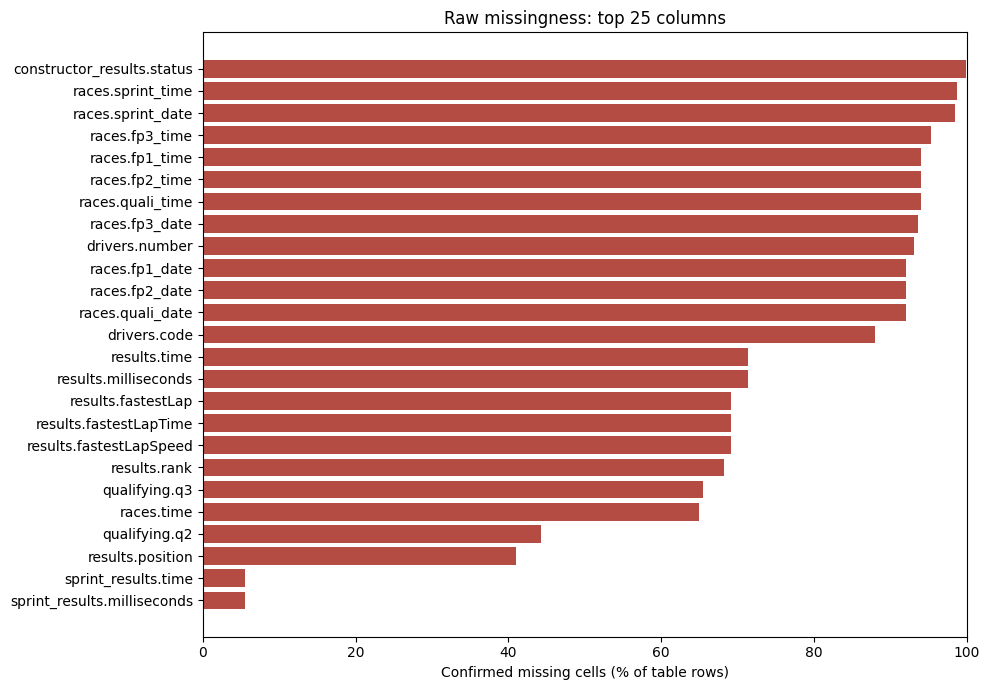

**Observed:** 32 table/column/token combinations found. Full per-column counts are exported, including zero-missing columns. Nullable absence is informational; unresolved candidate tokens require semantic review.

In [5]:
CANDIDATES={'NA','N/A','n/a','NaN','nan','null','NULL','None','none','-','--','?'}
missing_rows=[];token_rows=[]
for t,df in raw.items():
    for col in df:
        s=df[col];text=s.fillna('').astype(str);stripped=text.str.strip()
        missing=missing_mask(s)
        candidates=stripped.isin(CANDIDATES)
        whitespace=(text!=stripped)&(~missing)
        missing_rows.append(dict(table=t,column=col,rows=len(df),confirmed_missing=int(missing.sum()),
             missing_pct=100*missing.mean() if len(df) else np.nan,candidate_cells=int(candidates.sum())))
        for token,count in text[missing|candidates].value_counts(dropna=False).items():
            token_rows.append(dict(table=t,column=col,token_repr=repr(token),count=int(count),
                                  classification='confirmed_missing' if str(token).strip() in {'','\\N'} else 'candidate_review'))
        if missing.any():
            severity='BLOCKER' if col in NONNULL[t] else 'INFO'
            record('missing_value',t,severity,missing.sum(),'cells',f'{col}: confirmed missing values.',
                   'Resolve required keys/labels; for nullable fields preserve absence until a justified downstream policy.',
                   evidence_rows(df[[col]],missing) if severity=='BLOCKER' else None)
        if candidates.any():record('candidate_sentinel',t,'WARNING',candidates.sum(),'cells',f'{col}: possible placeholders, not automatically missing.',
                    'Inspect semantic context before replacement.',evidence_rows(df[[col]],candidates))
        if whitespace.any():record('surrounding_whitespace',t,'WARNING',whitespace.sum(),'cells',f'{col}: leading/trailing whitespace.',
                    'Document normalization on a copy; raw exact matching intentionally preserved.',evidence_rows(df[[col]],whitespace))
missingness=pd.DataFrame(missing_rows,columns=['table','column','rows','confirmed_missing','missing_pct','candidate_cells'])
tokens=pd.DataFrame(token_rows,columns=['table','column','token_repr','count','classification'])
save_table(missingness,'missingness_all_columns');save_table(tokens,'sentinel_tokens')
display(missingness.sort_values('missing_pct',ascending=False).head(30))
if len(missingness):
    top=missingness[missingness.confirmed_missing>0].nlargest(25,'missing_pct').iloc[::-1]
    if len(top):
        plt.figure(figsize=(10,max(4,len(top)*.28)))
        plt.barh(top.table+'.'+top.column,top.missing_pct,color='#b44c43');plt.xlim(0,100)
        plt.xlabel('Confirmed missing cells (% of table rows)');plt.title('Raw missingness: top 25 columns')
        figure('02_raw_missingness')
note(f'**Observed:** {len(tokens)} table/column/token combinations found. Full per-column counts are exported, including zero-missing columns. '
     'Nullable absence is informational; unresolved candidate tokens require semantic review.')

**Interpretation:** High Q2/Q3 missingness can be structural non-participation, not corruption. Entire-table missingness hides historical coverage changes, so Section 8 also measures qualifying row availability by season. A missing-value count is not a recommendation to impute.

In [6]:
def duration_seconds(s):
    """Parse seconds, M:SS[.fff], H:MM:SS[.fff]; constrain subordinate clock parts."""
    text=s.fillna('').astype(str)
    out=pd.Series(np.nan,index=s.index,dtype=float)
    plain=text.str.fullmatch(r'\d+(?:\.\d+)?')
    out.loc[plain]=pd.to_numeric(text[plain],errors='coerce')
    two=text.str.extract(r'^(\d+):([0-5]\d(?:\.\d+)?)$')
    ok=two[0].notna()
    out.loc[ok]=pd.to_numeric(two.loc[ok,0])*60+pd.to_numeric(two.loc[ok,1])
    three=text.str.extract(r'^(\d+):([0-5]\d):([0-5]\d(?:\.\d+)?)$')
    ok=three[0].notna()
    out.loc[ok]=pd.to_numeric(three.loc[ok,0])*3600+pd.to_numeric(three.loc[ok,1])*60+pd.to_numeric(three.loc[ok,2])
    return out

def semantic_invalid(s,typ):
    nonmissing=~missing_mask(s)
    if typ=='text': return pd.Series(False,index=s.index)
    if typ=='date':
        return nonmissing & (~s.str.fullmatch(r'\d{4}-\d{2}-\d{2}') | pd.to_datetime(s,format='%Y-%m-%d',errors='coerce').isna())
    if typ=='clock':return nonmissing & ~s.str.fullmatch(r'(?:[01]\d|2[0-3]):[0-5]\d:[0-5]\d(?:\.\d+)?(?:Z)?')
    if typ=='duration':return nonmissing & duration_seconds(s).isna()
    if typ=='result_time':
        # Recognize full elapsed durations, plus-time gaps, and lap gaps; do not equate them.
        parsed=duration_seconds(s).notna() | duration_seconds(s.str.replace(r'^\+','',regex=True)).notna() | s.str.fullmatch(r'\+?\d+ Laps?',case=False)
        return nonmissing & ~parsed
    num=pd.to_numeric(s,errors='coerce')
    bad=num.isna() | ~np.isfinite(num)
    if typ in ['id','integer','count','positive_integer','year']:bad |= num.mod(1).ne(0)
    if typ in ['id','positive_integer']:bad |= num.le(0)
    if typ in ['count','nonnegative']:bad |= num.lt(0)
    if typ=='year':bad |= num.lt(1950)|num.gt(2100)
    if typ=='latitude':bad |= num.lt(-90)|num.gt(90)
    if typ=='longitude':bad |= num.lt(-180)|num.gt(180)
    return nonmissing & bad

semantic_rows=[]
for t,df in raw.items():
    for col,typ in SPEC[t].items():
        if col not in df:continue
        bad=semantic_invalid(df[col],typ)
        semantic_rows.append(dict(table=t,column=col,expected_type=typ,nonmissing=int((~missing_mask(df[col])).sum()),invalid=int(bad.sum())))
        if bad.any():record('semantic_invalid',t,'BLOCKER' if col in NONNULL[t] else 'WARNING',bad.sum(),'cells',
            f'{col}: invalid {typ} representation/range under declared contract.',
            'Review source value; convert or resolve on a copy with documented semantics.',evidence_rows(df[[col]],bad))
        check('semantic_type',t,'FAIL' if bad.any() else 'PASS',f'{col}: {typ}')
semantic_report=pd.DataFrame(semantic_rows,columns=['table','column','expected_type','nonmissing','invalid'])
save_table(semantic_report,'semantic_audit')
display(semantic_report[semantic_report.invalid>0])

# Agreement of independently stored durations; milliseconds allow rounding tolerance.
for t,textcol in [('lap_times','time'),('pit_stops','duration')]:
    if not available(t,[textcol,'milliseconds'],'duration_consistency'):continue
    seconds=duration_seconds(raw[t][textcol]);ms=pd.to_numeric(raw[t].milliseconds,errors='coerce')
    valid=seconds.notna()&ms.notna()
    diff=(seconds*1000-ms).abs();bad=valid & diff.gt(1.01)
    if bad.any():
        ev=evidence_rows(raw[t],bad);ev['absolute_difference_ms']=diff[bad].to_numpy()
        record('duration_disagreement',t,'WARNING',bad.sum(),'rows','Text duration and milliseconds disagree by more than 1.01 ms.',
               'Check rounding/source discrepancy before selecting the canonical duration.',ev)
    check('duration_consistency',t,'WARNING' if bad.any() else 'PASS',f'{int(valid.sum())} comparable records.')
note(f'**Observed:** {int(semantic_report.invalid.sum())} invalid field values across {int(semantic_report.invalid.gt(0).sum())} fields. '
     'These are field-level counts, not distinct faulty-row counts. Parsing failure is separated from expected missingness.')

,table,column,expected_type,nonmissing,invalid


**Observed:** 0 invalid field values across 0 fields. These are field-level counts, not distinct faulty-row counts. Parsing failure is separated from expected missingness.

**Interpretation:** Numeric parseability alone is insufficient: IDs need positive integer semantics, grid/laps may be zero, and coordinates can be negative within geographic limits. The broad year bound is a validation convention, not a claim about which seasons this snapshot contains. `results.time` may represent total duration or a gap; recognized forms are audited without mixing those meanings. A recognized time string is not proof that its value is historically accurate.

## 6. Calendar coverage versus usable results and chronological ordering
A race listed in `races.csv` does not prove that result records exist. “Usable target” below means valid race/driver identifiers, a valid race-year link and a positive integer `positionOrder`; it is **not** a fully cleaned modeling row. Shared-drive duplicates and other structural issues remain visible.

,split,start,end,calendar_seasons,usable_result_seasons,raw_usable_rows,unique_pairs,positive_rows,negative_rows,provisional_positive_pct,missing_result_years
0,train,1950,2019,70,70,24620,24529,3076,21544,12.493907,[]
1,validation,2020,2021,2,2,780,780,117,663,15.000000,[]
2,test,2022,2024,3,3,1359,1359,204,1155,15.011038,[]


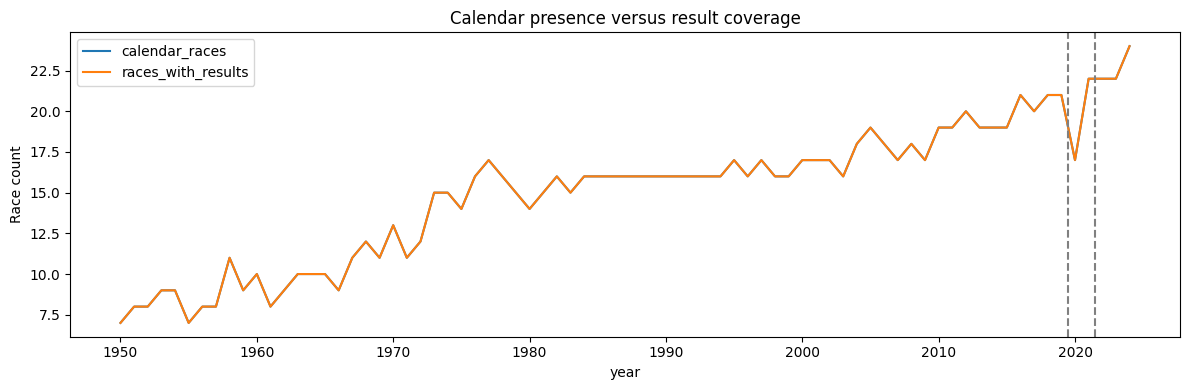

**Observed:** train: 24,620 target-usable raw rows across 70 seasons; validation: 780 target-usable raw rows across 2 seasons; test: 1,359 target-usable raw rows across 3 seasons. These are feasibility diagnostics, not finalized splits.

In [7]:
def safe_join(left,parent,on,cols,context):
    if not available(parent,[on]+cols,context):return None
    right=raw[parent][[on]+cols]
    if right[on].duplicated().any() or missing_mask(right[on]).any() or invalid_key_mask(right[on],'year' if on=='year' else 'id').any():
        record('unsafe_join',parent,'BLOCKER',1,'joins',context+': invalid/nonunique parent key.',
               'Resolve parent integrity; this analysis was skipped instead of multiplying rows.')
        check(context,parent,'NOT_RUN','Unsafe parent key.')
        return None
    merged=left.merge(right,on=on,how='left',validate='many_to_one',indicator='_join_state')
    unmatched=merged['_join_state'].eq('left_only')
    if unmatched.any():record('analysis_unmatched',parent,'BLOCKER',unmatched.sum(),'rows',context+': unmatched source rows.',
                             'Resolve references; unmatched rows remain visible.',merged.loc[unmatched].copy())
    return merged.drop(columns='_join_state')

base=None;coverage=pd.DataFrame();split_report=pd.DataFrame()
if available('results',['raceId','driverId','positionOrder'],'result_coverage'):
    base=safe_join(raw['results'].copy(),'races','raceId',['year','date','round'],'result_race_join')
if available('races',['raceId','year','date','round'],'calendar_coverage'):
    r=raw['races'];years=pd.to_numeric(r.year,errors='coerce')
    valid_year=~missing_mask(r.year)&~semantic_invalid(r.year,'year')
    present=set(years[valid_year].astype(int))
    expected=set(range(SCOPE_START,SCOPE_END+1))
    absent=sorted(expected-present);outside=sorted(present-expected)
    if absent:record('missing_scope_seasons','races','BLOCKER',len(absent),'seasons',f'Expected calendar seasons absent: {absent}',
                     'Verify snapshot completeness; document any approved scope restriction.',pd.DataFrame({'year':absent}))
    if outside:record('outside_scope','races','INFO',len(outside),'seasons',f'Outside declared scope: {outside}',
                      'Keep raw records but exclude out-of-scope seasons from milestone modeling.',pd.DataFrame({'year':outside}))
    if not present:record('no_valid_calendar_years','races','BLOCKER',len(r),'rows','No valid season years found.','Resolve year data before chronology.')
    dates=pd.to_datetime(r.date,format='%Y-%m-%d',errors='coerce')
    mismatch=valid_year & dates.notna() & dates.dt.year.ne(years)
    if mismatch.any():record('race_year_date_mismatch','races','WARNING',mismatch.sum(),'rows','Calendar date year differs from season year.',
                             'Check scheduling/history; do not silently reorder.',evidence_rows(r,mismatch))
    chrono=r.assign(_year=years,_date=dates,_round=pd.to_numeric(r['round'],errors='coerce'))
    good=valid_year&dates.notna()&~semantic_invalid(r['round'],'positive_integer')&~missing_mask(r['round'])
    sorted_r=chrono.loc[good].sort_values(['_year','_round','raceId']).copy()
    backwards=sorted_r.groupby('_year')['_date'].diff().dt.total_seconds().lt(0)
    if backwards.any():record('round_date_order','races','WARNING',backwards.sum(),'rows','Race dates decrease when ordered by season/round.',
                             'Resolve chronological ordering before rolling histories.',sorted_r.loc[backwards])
    same_round=r.duplicated(['year','round'],keep=False)
    if same_round.any():record('duplicate_season_round','races','WARNING',same_round.sum(),'rows','Repeated season/round; inspect before ordering.',
                              'Document a valid deterministic event order.',evidence_rows(r,same_round))
    date_ties=r.duplicated(['date'],keep=False)&dates.notna()
    if date_ties.any():record('same_date_events','races','WARNING',date_ties.sum(),'rows','Multiple events share a date; dates alone cannot prove ordering.',
                             'Use verified event chronology; avoid same-day future information.',evidence_rows(r,date_ties))
    save_table(sorted_r,'chronological_race_inventory')
    calendar=years[valid_year].astype(int).value_counts().rename('calendar_races')
    if base is not None:
        by=pd.to_numeric(base.year,errors='coerce')
        bvalid=by.notna()&by.mod(1).eq(0)&by.between(1950,2100)
        rank=pd.to_numeric(base.positionOrder,errors='coerce')
        usable=bvalid&~missing_mask(base.driverId)&~invalid_key_mask(base.driverId)&~missing_mask(base.raceId)&~invalid_key_mask(base.raceId)&rank.notna()&np.isfinite(rank)&rank.gt(0)&rank.mod(1).eq(0)
        base=base.assign(_year=by,_target_valid=usable,_podium=rank.le(3).where(usable),_date=pd.to_datetime(base.date,format='%Y-%m-%d',errors='coerce'))
        counts=base.loc[bvalid].groupby('_year').agg(result_rows=('raceId','size'),races_with_results=('raceId','nunique'))
        u=base.loc[usable].groupby('_year').agg(target_usable_rows=('raceId','size'),usable_driver_race_pairs=('driverId',lambda s:0))
        pair=base.loc[usable].drop_duplicates(['raceId','driverId']).groupby('_year').size()
        u['usable_driver_race_pairs']=pair
        coverage=pd.concat([calendar,counts,u],axis=1).fillna(0).astype(int).rename_axis('year').reset_index()
        coverage['calendar_races_without_results']=coverage.calendar_races-coverage.races_with_results
        no_results=~r.raceId.isin(raw['results'].raceId)
        inscope=years.between(SCOPE_START,SCOPE_END)&valid_year
        if (no_results&inscope).any():record('calendar_without_results','races','BLOCKER',(no_results&inscope).sum(),'races',
                     'In-scope calendar events lack result records.','Check incomplete/scheduled/cancelled events and document eligibility.',evidence_rows(r,no_results&inscope))
        split_rows=[]
        for split,(lo,hi) in SPLITS.items():
            m=usable&by.between(lo,hi);p=base.loc[m]
            available_years=set(p._year.astype(int));required_years=set(range(lo,hi+1))
            missing_years=sorted(required_years-available_years)
            positive=int(p._podium.sum());negative=len(p)-positive
            if not len(p):record('empty_partition',split,'BLOCKER',1,'partitions','No target-usable result rows.','Repair dataset coverage before splitting.')
            if missing_years:record('partition_missing_result_years',split,'BLOCKER',len(missing_years),'seasons',f'No usable results in {missing_years}',
                        'Verify coverage or explicitly revise the approved training scope.',pd.DataFrame({'year':missing_years}))
            if len(p) and (positive==0 or negative==0):record('partition_single_class',split,'BLOCKER',1,'partitions','Only one target class represented.','AUC cannot be evaluated meaningfully; inspect target/coverage.')
            split_rows.append(dict(split=split,start=lo,end=hi,calendar_seasons=len(present&required_years),usable_result_seasons=len(available_years),
                raw_usable_rows=len(p),unique_pairs=len(p.drop_duplicates(['raceId','driverId'])),positive_rows=positive,negative_rows=negative,
                provisional_positive_pct=100*positive/len(p) if len(p) else np.nan,missing_result_years=str(missing_years)))
        split_report=pd.DataFrame(split_rows);display(split_report)
    else:coverage=calendar.rename_axis('year').reset_index()
    if len(coverage):
        coverage=coverage.sort_values('year').reset_index(drop=True)
        ax=coverage.set_index('year')[['calendar_races']+(['races_with_results'] if 'races_with_results' in coverage else [])].plot(figsize=(12,4))
        ax.set_ylabel('Race count');ax.set_title('Calendar presence versus result coverage')
        for lo in [2020,2022]:ax.axvline(lo-.5,color='gray',ls='--')
        figure('03_calendar_result_coverage')
save_table(coverage,'season_coverage');save_table(split_report,'provisional_split_feasibility')
if len(split_report):note('**Observed:** '+ '; '.join(f"{x.split}: {x.raw_usable_rows:,} target-usable raw rows across {x.usable_result_seasons} seasons" for x in split_report.itertuples())+'. These are feasibility diagnostics, not finalized splits.')
else:note('**Not established:** usable-result coverage could not be computed. Consult blocking findings.')

**Interpretation:** The declared full-history audit expects 1950–2024. A missing historical season is a coverage finding under that contract; a later justified training-window restriction can change the modeling contract, but must not disguise an incomplete input snapshot. The named split is only a plan here. A positive-class rate based on raw records may change after shared-drive and participation decisions.

## 7. Historical duplicate evidence and unresolved grain
This section exports every competing record for repeated driver–race pairs. It reports both rows involved and excess rows above one per pair. It does not invent a historically correct retained row.

,_decade,rows_in_repeated_pairs,repeated_pairs
0,1950,164,79
1,1960,10,5
2,1970,2,1


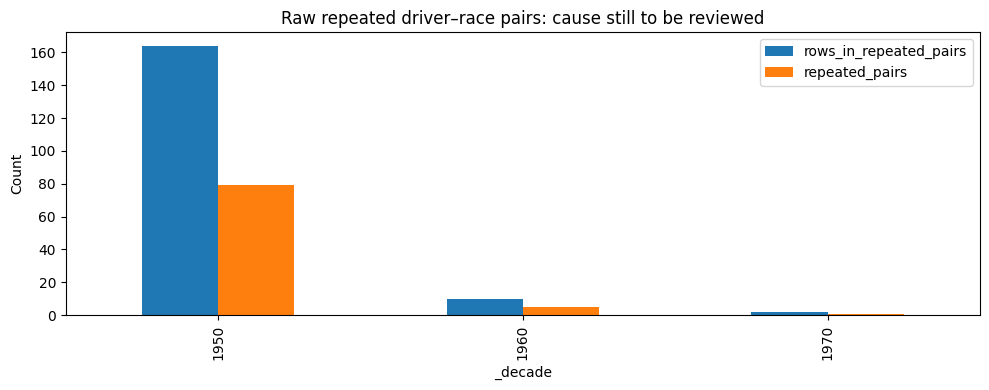

**Observed:** 85 repeated pairs contain 176 rows, with 91 rows above a one-row-per-pair representation. No rows were removed.

**Identity context:** 312 driver-season groups have more than one recorded constructor. This does not prove a rename or an error.

In [8]:
grain_unique=False
if available('results',['raceId','driverId'],'driver_race_grain'):
    df=raw['results'];mask=df.duplicated(['raceId','driverId'],keep=False)
    groups=df.loc[mask].groupby(['raceId','driverId'],dropna=False).size().rename('group_size').reset_index()
    n_groups=len(groups);involved=int(mask.sum());excess=int((groups.group_size-1).sum())
    keybad=missing_mask(df.raceId)|missing_mask(df.driverId)|invalid_key_mask(df.raceId)|invalid_key_mask(df.driverId)
    grain_unique=not mask.any() and not keybad.any() and len(df)>0
    evidence=evidence_rows(df,mask)
    save_table(groups,'repeated_driver_race_groups');save_table(evidence,'repeated_driver_race_records')
    if involved:record('driver_race_repeated','results','WARNING',involved,'rows',
        f'{n_groups} repeated pairs; {excess} excess rows. Shared drives are a possible cause, not verified for each case.',
        'Review all competing rows, choose a deterministic justified rule, preserve a resolution ledger and quantify target/constructor effects.',evidence)
    check('driver_race_grain','results','PASS' if grain_unique else 'UNRESOLVED','Unique valid pair required before modeling.')
    if base is not None and involved:
        repeated=base.loc[mask].copy()
        repeated['_decade']=(repeated._year//10*10).astype('Int64')
        rows_dec=repeated.groupby('_decade').size().rename('rows_in_repeated_pairs')
        pairs_dec=repeated.drop_duplicates(['raceId','driverId']).groupby('_decade').size().rename('repeated_pairs')
        summary=pd.concat([rows_dec,pairs_dec],axis=1).reset_index()
        save_table(summary,'duplicate_pairs_by_decade');display(summary)
        summary.set_index('_decade')[['rows_in_repeated_pairs','repeated_pairs']].plot.bar(figsize=(10,4))
        plt.ylabel('Count');plt.title('Raw repeated driver–race pairs: cause still to be reviewed');figure('04_duplicate_grain')
    note(f'**Observed:** {n_groups:,} repeated pairs contain {involved:,} rows, with {excess:,} rows above a one-row-per-pair representation. No rows were removed.')

# Indianapolis identification is transparent and reviewable, not an automatic exclusion.
if available('races',['raceId','name','year'],'indianapolis_candidates'):
    r=raw['races'];m=r.name.str.contains('Indianapolis',case=False,na=False)
    save_table(evidence_rows(r,m),'indianapolis_candidate_events')
    if m.any():record('indianapolis_policy','races','WARNING',m.sum(),'races','Name-matched Indianapolis candidates require a documented scope decision.',
                     'Confirm event identity and assess inclusion for home-country/grid analysis; do not silently exclude.',evidence_rows(r,m))
# Multiple constructors for a driver within a season are a descriptive pattern, not a defect.
if base is not None and 'constructorId' in base:
    switches=base.groupby(['_year','driverId']).constructorId.nunique().rename('constructor_count').reset_index()
    save_table(switches[switches.constructor_count>1],'driver_seasons_multiple_constructors')
    note(f'**Identity context:** {int(switches.constructor_count.gt(1).sum())} driver-season groups have more than one recorded constructor. This does not prove a rename or an error.')

**Interpretation:** Resolve participation and shared-entry rules before asserting a unique modeling table. A nonzero grid may support a starting-entry hypothesis but is not sufficient proof in every historical group. Selecting the best final rank is outcome-dependent; if used as a fallback later, disclose its effect and limitations. Follow constructor identity explicitly; do not infer lineage from similar names.

## 8. Raw EDA: qualifying availability, grid, labels and status
These are descriptive diagnostics before cleaning. Every denominator is labeled. The three graded analytical questions (circuit conversion, grid-adjusted home association and mechanical-retirement rates) come later and are not replaced by these plots.

,_year,entries,qualifying_rows,q1_valid,q2_valid,q3_valid,qualifying_rows_pct,q1_valid_pct,q2_valid_pct,q3_valid_pct
45,1995,418,418,394,0,0,100.000000,94.258373,0.000000,0.000000
46,1996,340,148,145,0,0,43.529412,42.647059,0.000000,0.000000
47,1997,376,220,219,0,0,58.510638,58.244681,0.000000,0.000000
48,1998,349,153,151,0,0,43.839542,43.266476,0.000000,0.000000
49,1999,352,65,64,0,0,18.465909,18.181818,0.000000,0.000000
50,2000,373,88,88,0,0,23.592493,23.592493,0.000000,0.000000
51,2001,374,22,22,0,0,5.882353,5.882353,0.000000,0.000000
52,2002,362,42,42,0,0,11.602210,11.602210,0.000000,0.000000
53,2003,320,320,309,0,0,100.000000,96.562500,0.000000,0.000000
54,2004,360,360,339,0,0,100.000000,94.166667,0.000000,0.000000


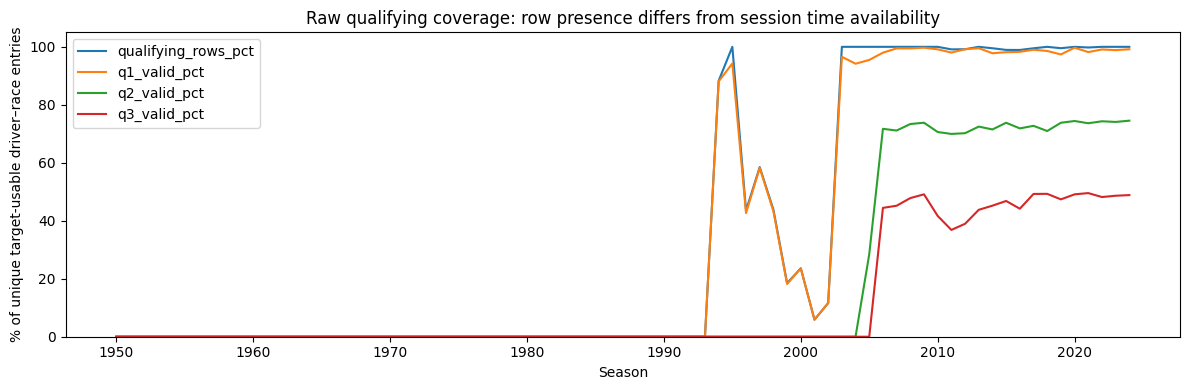

**Observed:** earliest linked qualifying season is 1994. This is measured from this snapshot, not assumed from the companion. Repeated qualifying records were reduced to presence flags only for this coverage diagnostic.

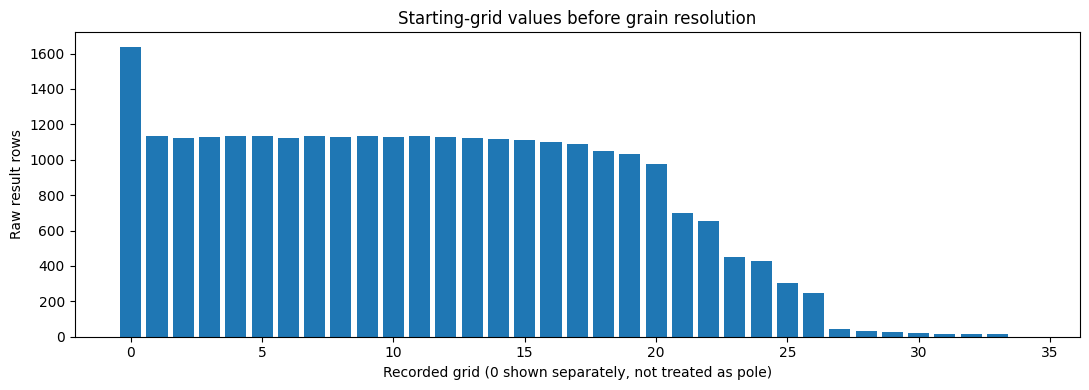

,status,raw_rows
9,Did not qualify,1013
8,Did not prequalify,331
27,Withdrew,164
0,+1 Lap,27
14,Finished,22
3,Accident,20
19,Injury,8
1,+2 Laps,7
12,Excluded,6
11,Engine,6


**Observed:** 1,638 raw results have grid zero. No pit-lane or race-start label has been assigned from that number alone.

,result_rows_excluded_repeated_pair,qualifying_rows_excluded_repeated_pair,unique_result_pairs,comparable_positive_grid_and_position,different_positions
0,176,0,26583,10407,2422


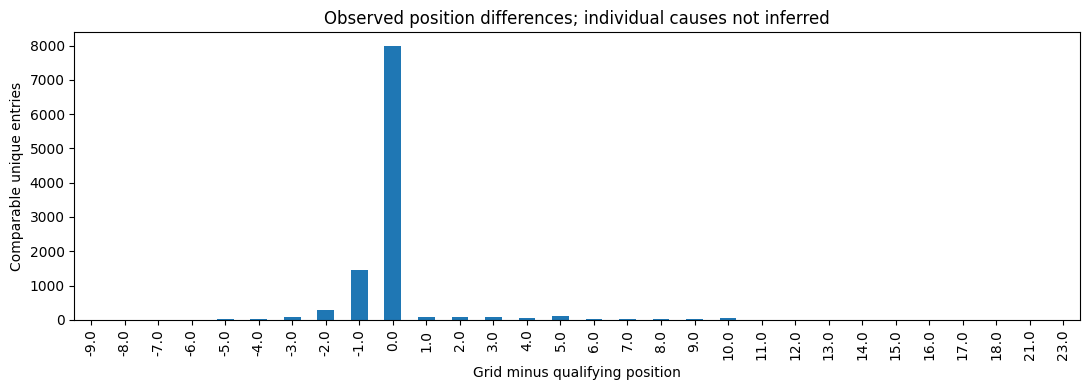

In [9]:
qual_coverage=pd.DataFrame()
if base is not None and available('qualifying',['raceId','driverId','q1','q2','q3'],'qualifying_coverage'):
    # Unique presence map avoids allowing repeated qualifying rows to multiply denominators.
    q=raw['qualifying'];working=q[['raceId','driverId']].copy()
    working['_has_q_row']=True
    for col in ['q1','q2','q3']:
        working[f'_valid_{col}']=duration_seconds(q[col]).notna() & ~missing_mask(q[col])
    agg=working.groupby(['raceId','driverId'],as_index=False).agg({'_has_q_row':'any',**{f'_valid_{x}':'any' for x in ['q1','q2','q3']}})
    entries=base.loc[base._target_valid,['raceId','driverId','_year']].drop_duplicates(['raceId','driverId'])
    linked=entries.merge(agg,on=['raceId','driverId'],how='left',validate='one_to_one')
    flags=['_has_q_row','_valid_q1','_valid_q2','_valid_q3']
    linked[flags]=linked[flags].astype("boolean").fillna(False).astype(bool)
    qual_coverage=linked.groupby('_year').agg(entries=('driverId','size'),qualifying_rows=('_has_q_row','sum'),q1_valid=('_valid_q1','sum'),q2_valid=('_valid_q2','sum'),q3_valid=('_valid_q3','sum')).reset_index()
    for field in ['qualifying_rows','q1_valid','q2_valid','q3_valid']:qual_coverage[field+'_pct']=100*qual_coverage[field]/qual_coverage.entries
    save_table(qual_coverage,'qualifying_coverage_per_season');display(qual_coverage.tail(30))
    if len(qual_coverage):
        qual_coverage.set_index('_year')[[f'{x}_pct' for x in ['qualifying_rows','q1_valid','q2_valid','q3_valid']]].plot(figsize=(12,4))
        plt.ylim(0,105);plt.ylabel('% of unique target-usable driver–race entries');plt.xlabel('Season')
        plt.title('Raw qualifying coverage: row presence differs from session time availability');figure('05_qualifying_coverage')
        nonzero=qual_coverage.loc[qual_coverage.qualifying_rows>0,'_year']
        note('**Observed:** earliest linked qualifying season is '+(str(int(nonzero.min())) if len(nonzero) else 'not available')+
             '. This is measured from this snapshot, not assumed from the companion. Repeated qualifying records were reduced to presence flags only for this coverage diagnostic.')

if base is not None and 'grid' in base:
    grid=pd.to_numeric(base.grid,errors='coerce')
    good=base._target_valid&grid.notna()&np.isfinite(grid)&grid.ge(0)&grid.mod(1).eq(0)
    distribution=base.loc[good,['_year','raceId','driverId']].assign(grid=grid[good])
    grid_counts=distribution.groupby('grid').size().rename('raw_result_rows').reset_index()
    save_table(grid_counts,'raw_grid_distribution')
    if len(grid_counts):
        plt.figure(figsize=(11,4));plt.bar(grid_counts.grid,grid_counts.raw_result_rows)
        plt.xlabel('Recorded grid (0 shown separately, not treated as pole)');plt.ylabel('Raw result rows');plt.title('Starting-grid values before grain resolution');figure('06_grid_distribution')
    zero=base.loc[grid.eq(0)].copy()
    save_table(zero,'grid_zero_records')
    if len(zero):
        record('grid_zero_semantics','results','WARNING',len(zero),'rows','Grid zero semantics unresolved; possible pit-lane/non-start/historical cases.',
               'Inspect status and entry evidence; define a rule on a copy before grid features or start denominators.')
        if 'statusId' in zero:
            tagged=safe_join(zero,'status','statusId',['status'],'zero_grid_status_join')
            if tagged is not None:
                summary=tagged.groupby('status',dropna=False).size().rename('raw_rows').reset_index().sort_values('raw_rows',ascending=False)
                save_table(summary,'grid_zero_by_status');display(summary.head(25))
    note(f'**Observed:** {len(zero):,} raw results have grid zero. No pit-lane or race-start label has been assigned from that number alone.')

# Grid vs qualifying: compare only unambiguous pairs; save excluded counts explicitly.
if base is not None and 'grid' in base and available('qualifying',['raceId','driverId','position'],'grid_qualifying_comparison'):
    unique_results=~base.duplicated(['raceId','driverId'],keep=False)
    q=raw['qualifying'];unique_q=~q.duplicated(['raceId','driverId'],keep=False)
    gq=base.loc[unique_results,['raceId','driverId','grid']].merge(q.loc[unique_q,['raceId','driverId','position']],on=['raceId','driverId'],how='left',validate='one_to_one')
    g=pd.to_numeric(gq.grid,errors='coerce');qp=pd.to_numeric(gq.position,errors='coerce')
    comparable=g.gt(0)&g.mod(1).eq(0)&qp.gt(0)&qp.mod(1).eq(0)&np.isfinite(g)&np.isfinite(qp)
    compared=gq.loc[comparable].copy();compared['grid_minus_qualifying']=(g-qp)[comparable]
    save_table(compared,'grid_vs_qualifying_comparable_records')
    comparison_counts=pd.DataFrame([{'result_rows_excluded_repeated_pair':int((~unique_results).sum()),'qualifying_rows_excluded_repeated_pair':int((~unique_q).sum()),
          'unique_result_pairs':len(gq),'comparable_positive_grid_and_position':int(comparable.sum()),'different_positions':int((g[comparable]!=qp[comparable]).sum())}])
    save_table(comparison_counts,'grid_qualifying_denominators');display(comparison_counts)
    if len(compared):
        compared.grid_minus_qualifying.value_counts().sort_index().plot.bar(figsize=(11,4))
        plt.xlabel('Grid minus qualifying position');plt.ylabel('Comparable unique entries');plt.title('Observed position differences; individual causes not inferred');figure('07_grid_qualifying_difference')

**Interpretation:** Qualifying row presence, recorded session times and actual starting grid answer different questions. Later-session missingness may reflect elimination or an older format. A grid/qualifying discrepancy can arise for several reasons; this plot does not establish an individual penalty. The comparison excludes ambiguous pairs explicitly rather than selecting arbitrary records.

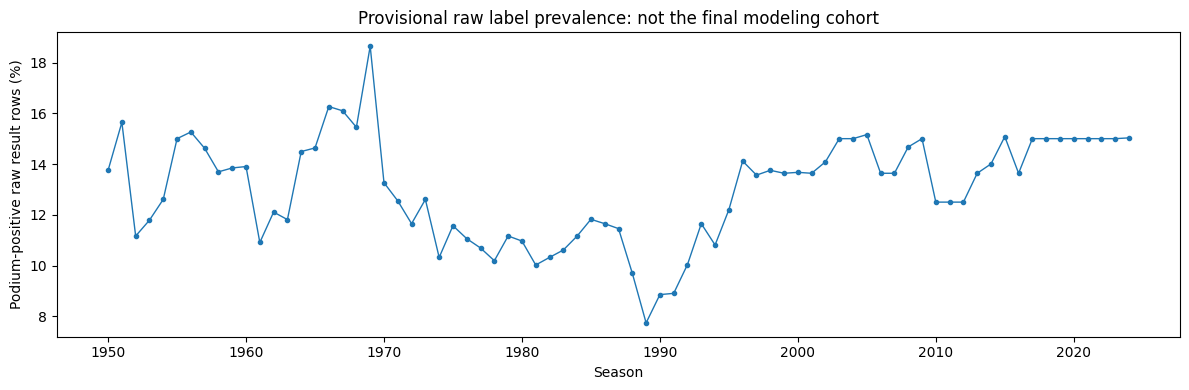

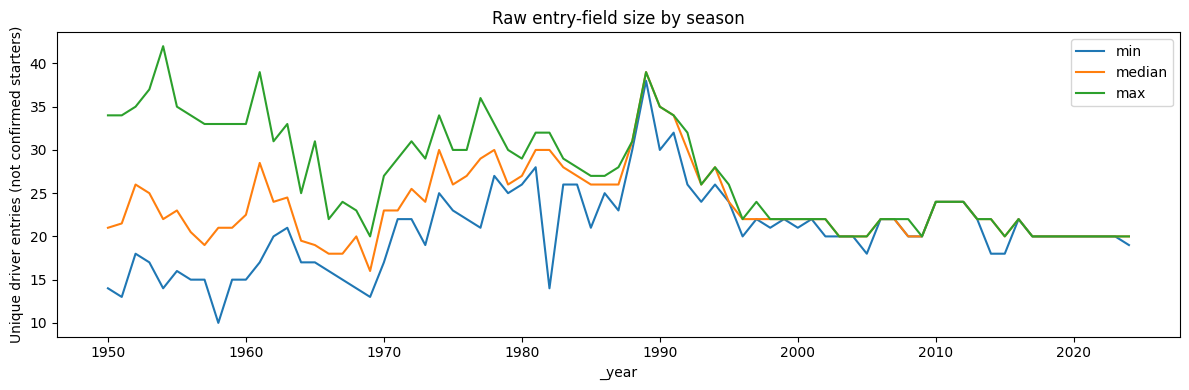

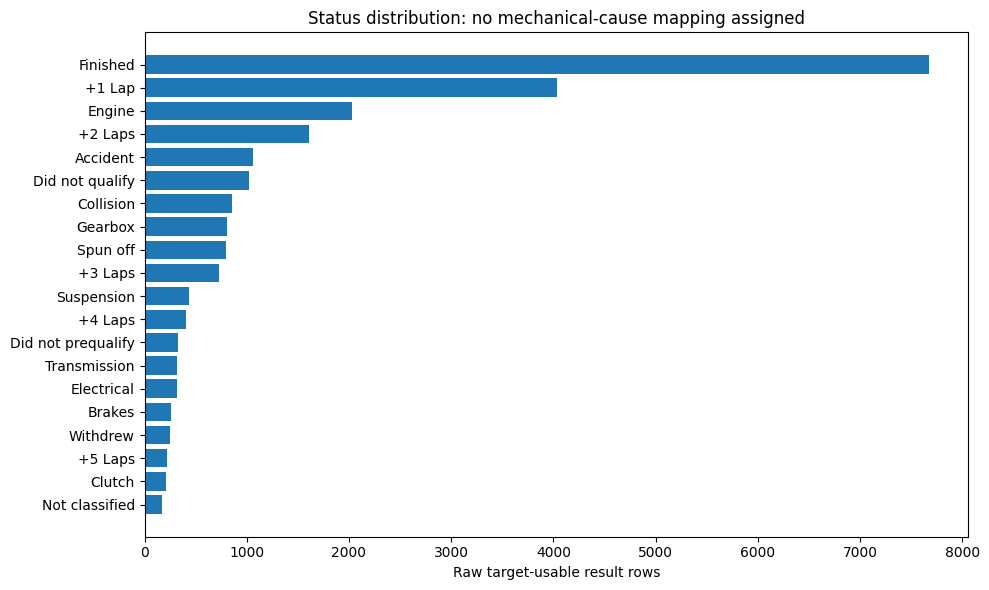

,category,rows
0,Finished or lapped-finish text,15161
1,Other status (not automatically mechanical),11598


**Observed:** 26,759 target-usable raw rows; 18 races require review of positive-row counts. These outcomes are descriptive audit evidence, not feature-selection or test-tuning evidence.

In [10]:
if base is not None:
    v=base.loc[base._target_valid].copy()
    yearly=v.groupby('_year').agg(raw_rows=('raceId','size'),positive_rows=('_podium','sum'),races=('raceId','nunique')).reset_index()
    yearly['raw_podium_pct']=100*yearly.positive_rows/yearly.raw_rows
    save_table(yearly,'raw_class_balance_per_season')
    if len(yearly):
        plt.figure(figsize=(12,4));plt.plot(yearly._year,yearly.raw_podium_pct,marker='.',lw=1)
        plt.ylabel('Podium-positive raw result rows (%)');plt.xlabel('Season');plt.title('Provisional raw label prevalence: not the final modeling cohort');figure('08_raw_podium_prevalence')
    field=v.drop_duplicates(['raceId','driverId']).groupby(['_year','raceId']).size().rename('unique_driver_entries').reset_index()
    field_year=field.groupby('_year').unique_driver_entries.agg(['min','median','max']).reset_index()
    save_table(field_year,'field_size_per_season')
    if len(field_year):
        ax=field_year.set_index('_year')[['min','median','max']].plot(figsize=(12,4));ax.set_ylabel('Unique driver entries (not confirmed starters)');ax.set_title('Raw entry-field size by season');figure('09_field_size')
    podium_counts=v.groupby(['_year','raceId'])._podium.sum().rename('positive_result_rows').reset_index()
    unusual=podium_counts[podium_counts.positive_result_rows!=3]
    save_table(unusual,'races_not_three_positive_raw_rows')
    if len(unusual):record('raw_podium_count_review','results','WARNING',len(unusual),'races',
        'Raw race-level positive counts differ from three; historical shared results and coverage require review.',
        'Investigate; do not force exactly three positive driver rows.',unusual)
    if 'statusId' in v:
        tagged=safe_join(v,'status','statusId',['status'],'status_eda_join')
        if tagged is not None:
            counts=tagged.groupby('status',dropna=False).size().rename('raw_rows').reset_index().sort_values('raw_rows',ascending=False)
            counts['fraction_of_joined_rows']=counts.raw_rows/len(tagged) if len(tagged) else np.nan
            save_table(counts,'status_inventory')
            if len(counts):
                top=counts.head(20).iloc[::-1];plt.figure(figsize=(10,6));plt.barh(top.status.fillna('<unmatched>'),top.raw_rows)
                plt.xlabel('Raw target-usable result rows');plt.title('Status distribution: no mechanical-cause mapping assigned');figure('10_status_inventory')
            # Narrow text classification only. Lapped finishes must not become retirements.
            st=tagged.status.fillna('')
            ended=st.eq('Finished')|st.str.fullmatch(r'\+\d+ Laps?')
            summary=pd.DataFrame({'category':['Finished or lapped-finish text','Other status (not automatically mechanical)'],
                                  'rows':[int(ended.sum()),int((~ended).sum())]})
            save_table(summary,'finish_text_vs_other_status');display(summary)
    note(f'**Observed:** {len(v):,} target-usable raw rows; {len(unusual):,} races require review of positive-row counts. '
         'These outcomes are descriptive audit evidence, not feature-selection or test-tuning evidence.')

**Interpretation:** Entry counts differ from actual starts. Statuses other than “Finished” and “+N Lap(s)” include several causes and participation states; they must not all be called mechanical retirements. The later mechanical-retirement question needs an explicit mapping and actual-start denominator. Historical podium counts are investigated, not forcibly normalized.

## 9. Final evidence register, immutable-data verification and handoff
This final section compares raw files and raw frames with their initial hashes, writes complete reports even when findings exist, and separates **audit execution** from **data readiness**. A blocker means the data must be resolved before it is trusted for downstream joins/modeling, not that the audit should suppress its evidence.

In [11]:
integrity_rows=[]
for t in raw:
    try:
        current=file_hash(DATA_DIR/f'{t}.csv')
        frame_current=frame_hash(raw[t])
        file_ok=current==INITIAL_FILE_HASHES[t];frame_ok=frame_current==INITIAL_FRAME_HASHES[t]
        integrity_rows.append(dict(table=t,file_unchanged=file_ok,raw_frame_unchanged=frame_ok,initial_sha256=INITIAL_FILE_HASHES[t],final_sha256=current))
        if not file_ok or not frame_ok:record('raw_changed',t,'BLOCKER',1,'tables','Raw file or raw frame changed during this run.',
                       'Restore raw snapshot and investigate mutating code before proceeding.')
        check('immutability',t,'PASS' if file_ok and frame_ok else 'FAIL','Compared start/end file and frame hashes.')
    except Exception as exc:
        record('immutability_unverified',t,'BLOCKER',1,'tables',str(exc),'Restore file accessibility and rerun.')
        check('immutability',t,'FAIL','Comparison could not complete.')
save_table(pd.DataFrame(integrity_rows),'immutability_check')
columns=['check_id','table','severity','n_affected','count_unit','detail','proposed_handling','evidence']
issues=pd.DataFrame(FINDINGS,columns=columns)
checks=pd.DataFrame(CHECKS,columns=['check_id','table','status','detail'])
save_table(issues,'issue_register');save_table(checks,'check_execution_register')
if len(issues):
    severity_counts=issues.groupby('severity').size().rename('finding_count').reset_index()
    # Intentionally do not sum overlapping row/cell counts into a fictitious affected-row total.
    summary=issues.groupby(['table','severity','check_id','count_unit']).size().rename('finding_entries').reset_index()
else:
    severity_counts=pd.DataFrame(columns=['severity','finding_count']);summary=pd.DataFrame(columns=['table','severity','check_id','count_unit','finding_entries'])
save_table(summary,'issue_summary');display(severity_counts)
blockers=issues[issues.severity.eq('BLOCKER')];warnings=issues[issues.severity.eq('WARNING')]
verdict='BLOCKED' if len(blockers) else ('PASSED WITH DOCUMENTED WARNINGS' if len(warnings) else 'PASSED')
coverage_ok=base is not None and len(split_report)>0 and not issues.check_id.isin(['empty_partition','partition_missing_result_years','partition_single_class']).any()
status={
 'audit_execution':'Completed available checks; inspect NOT_RUN entries for skipped dependencies.',
 'raw_data_readiness':verdict,'blocker_findings':len(blockers),'warning_findings':len(warnings),
 'loaded_tables':len(raw),'driver_race_grain_unique':bool(grain_unique),'provisional_split_feasible':bool(coverage_ok),
 'model_ready':False,'model_ready_reason':'Cleaning, representative-row/participation policy, post-cleaning validation and leakage-safe features are not implemented in Part 1.',
 'snapshot_id':snapshot_id,'run_id':RUN_ID,
 'counts_note':'Finding counts are not distinct affected-row counts; evidence can overlap.'}
(RUN_DIR/'audit_status.json').write_text(json.dumps(status,indent=2))
# Every run has its own template: rerunning cannot erase an existing experiment history.
experiment_columns=['attempt_id','hypothesis','change','fixed_conditions','evidence','validation_result','decision']
save_table(pd.DataFrame(columns=experiment_columns),'experiment_log_template')
figure_manifest=pd.DataFrame({'figure':FIGURES});save_table(figure_manifest,'figure_manifest')

lines=['# Generated audit conclusion',f'Run: {RUN_ID}',f'Snapshot: {snapshot_id}',
 f'Raw-data readiness: **{verdict}**',f'Loaded tables: {len(raw)}/14',
 f'Blocker findings: {len(blockers)}; warning findings: {len(warnings)}.',
 'Model ready: **No — this is Part 1 only.**',
 '## Findings that require action']
for row in issues[issues.severity.isin(['BLOCKER','WARNING'])].itertuples():
    lines.append(f'- [{row.severity}] {row.table} / {row.check_id}: {row.detail} Handling: {row.proposed_handling} Evidence: {row.evidence or "see summary tables"}')
if not len(blockers) and not len(warnings):lines.append('- No blockers or warnings under the implemented audit contract. This is not proof of historical correctness.')
lines += ['## Next stage','Resolve blockers on copies; preserve decisions and evidence. Then implement historical grain/participation policies and repeat EDA after cleaning.',
          'Do not treat a raw audit PASS as approval for model fitting.']
(RUN_DIR/'audit_conclusion.md').write_text('\n\n'.join(lines))
note(f'### Audit verdict: **{verdict}**\n\n'
     f'{len(raw)}/14 tables loaded; **{len(blockers)} blocker findings**, **{len(warnings)} warning findings**. '
     f'Unique valid driver–race grain: **{grain_unique}**.\n\n'
     '**Model ready: No.** Part 1 does not perform cleaning or feature engineering.\n\n'
     f'All reports and affected-record evidence are in `{RUN_DIR}`.')
if len(blockers):display(blockers[['table','check_id','n_affected','count_unit','detail','evidence']])
if len(warnings):display(warnings[['table','check_id','n_affected','count_unit','detail']].head(40))
print('Files generated:',len(list(RUN_DIR.rglob('*.*'))))

,severity,finding_count
0,INFO,30
1,WARNING,5


### Audit verdict: **PASSED WITH DOCUMENTED WARNINGS**

14/14 tables loaded; **0 blocker findings**, **5 warning findings**. Unique valid driver–race grain: **False**.

**Model ready: No.** Part 1 does not perform cleaning or feature engineering.

All reports and affected-record evidence are in `/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42`.

,table,check_id,n_affected,count_unit,detail
3,drivers,surrounding_whitespace,1,cells,nationality: leading/trailing whitespace.
31,results,driver_race_repeated,176,rows,85 repeated pairs; 91 excess rows. Shared driv...
32,races,indianapolis_policy,11,races,Name-matched Indianapolis candidates require a...
33,results,grid_zero_semantics,1638,rows,Grid zero semantics unresolved; possible pit-l...
34,results,raw_podium_count_review,18,races,Raw race-level positive counts differ from thr...


Files generated: 51


**How to use the verdict:**
- **BLOCKED:** Address structural, coverage, required-key/label or integrity failures before trusting downstream results. Read the exported affected records; do not merely silence assertions.
- **PASSED WITH DOCUMENTED WARNINGS:** The implemented blocking checks passed, but historical/semantic findings need explicit policies. Warnings do not automatically authorize dropping rows.
- **PASSED:** No blocker/warning was found by the implemented checks. This does not establish that every historical field is correct or that the modeling table is ready.

### Handoff to Part 2
Every finding above is resolved, or deliberately kept with a documented policy, in Part 2: typed copies (Section 10), duplicate grain (11), participation, Indianapolis and grid-zero policies (12, 12b), key and cardinality revalidation (11, 12), before/after EDA (13), and a finding-by-finding resolution register (14).

### Evaluation notes
Explain why an FK can have no orphans but still fail because it is missing; why calendar coverage differs from usable-result coverage; why unique result IDs do not ensure driver–race grain; why Q3 missingness is not automatically bad data; and why status/grid alone cannot prove a start or mechanical retirement.


# Part 2 — Cleaning on copies, with a complete decision trail

This section implements cleaning across the full supplied history, without choosing a training-era restriction. Source **B** is the eight-page milestone brief; source **C** is the seven-page F1 introduction. The requirements below come from those two documents; the measured counts come from the Part 1 audit above.

| Issue | PDF guidance | Implemented decision |
|---|---|---|
| Immutable raw data | B p.2 | Clean deep copies; recheck file and frame hashes. |
| `\N`, blank fields, dates and durations | B p.2 | Normalize confirmed missing values; strip surrounding whitespace; validate before conversion; use nullable numeric types, dates and explicit seconds fields. No blind coercion of invalid values. |
| Repeated driver–race entries | B p.2; C p.7 | **Car-based rule:** keep the entry whose car has only this driver recorded; otherwise the lowest numeric `resultId`. Nine documented cases are tests, not overrides. Alternatives stay in the ledger. |
| `grid == 0` | C p.3 says pit-lane start **“verify in EDA”** | Preserve zero; flag it for review. Do not turn it into pole, a numbered grid position, or a verified pit-lane indicator. |
| DNQ / DNPQ, withdrawals, non-starters | C pp.2,4,7 | Kept in the master tables; excluded from the **modeling cohort** (Section 12b) by documented rules. Lap-1 retirements of drivers with a grid slot stay in. |
| Missing official position | C p.4 | Preserve legitimate unclassified `position`; construct target from valid `positionOrder` only. |
| `Finished` / `+N Lap(s)` and retirement causes | C pp.3–5 | Lapped finishes count as finishes. Every 2014+ status is mapped to one cause (Section 12c); ambiguous causes are kept separate. |
| Q2/Q3 missingness and coverage drift | C p.5 | Retain missing sessions; measure coverage by year. No zero fill, mean fill, or automatic row deletion. |
| Indianapolis 1950–1960 | C p.7 | Kept in the master data; excluded from the modeling cohort (381 rows). |
| Driver nationality vs circuit country | B p.3; C p.3 | Explicit mapping (Section 12d); home decided by circuit country; unmapped values stop the notebook. |
| Constructor identity changes | C pp.2,7 | Preserve constructorId; do not merge teams by name or car number. |
| Post-cleaning checks and visual EDA | B p.2 | Revalidate all PKs/FKs, merge cardinalities, missingness, row counts, target rates and qualifying coverage. |
| Prediction cutoff | B p.1 | Joined descriptive data contains outcomes and is **not** a feature matrix. No current-race status, laps, points, ranks or diagnostic flags may be passed to models. |

### Representative-row policy: car-based rule
**Idea.** Each car starts the race with exactly one driver. A car is identified within a race by `(raceId, constructorId, number)`. If one of a driver's cars has only him recorded, nobody else could have started it, so it must be the car he started in. The other car has two or more drivers, so somebody took it over.

**Rule, in order:**
1. **Sole-driver car.** If exactly one of the driver's entries is in a car with only him recorded, keep it.
2. **Otherwise keep the lowest numeric `resultId`.** This covers groups where every car is shared (two drivers swapped cars), entries with a missing car number, and the rare inconsistent group where *several* cars have only him recorded (for example da Silva Ramos, 1956). A driver cannot start two cars, so that last case is a data inconsistency; it is labelled separately and disclosed.

**What the rule uses.** Only car numbers, constructors and which drivers are recorded in each car. It never reads `positionOrder`, points, laps or status. Who else drove a car is a retrospective record, so this is not "pre-race data": it is a post-race record used to reconstruct a pre-race fact (which car he started in), the same way race reports are. It does not select rows by outcome.

**Evidence.**
- Step 2 is the team's original hypothesis (the lowest ID is the original entry). In the 70 groups whose IDs are more than 100 apart, the lower-ID row finished worse in 60, which fits "the original car retired".
- The car-based rule was written from the structure of a race, without thresholds or hand-picked rows. It passes all nine documented cases below, including the three where the lowest ID alone is wrong.

| Case | Kept entry (verified start) | How the rule decides |
|---|---|---|
| Fangio, Argentine GP 1956 | 18895 (#30) | sole-driver car |
| Fangio, Monaco GP 1956 | 18899 (#20) | both cars shared → lowest ID |
| Collins, British GP 1956 | 18998 (#2) | sole-driver car |
| Moss, Belgian GP 1956 | 18957 (#30) | sole-driver car |
| Castellotti, Monaco GP 1956 | 18906 (#22) | sole-driver car |
| Fagioli, French GP 1951 | 19918 (#8) | both cars shared → lowest ID |
| Ascari, French GP 1951 | 19935 (#12) | sole-driver car (lowest ID would keep #14, wrong) |
| González, Belgian GP 1954 | 19276 (#6) | sole-driver car (lowest ID would be wrong) |
| Moss, British GP 1961 | 17964 (#28) | sole-driver car (lowest ID would be wrong) |

These are **tests**: the notebook stops if the rule keeps a different row, or if the row's car number or grid no longer matches. Sources are listed in `VERIFIED_STARTS` in Section 11; open each link before submission.

**Limits.** This identifies the starting car only as well as the dataset records every driver of every car. Groups decided by step 2 are not independently verified. Three Indianapolis 1954 drivers (Davies, Scott, Fonder) were relief drivers only, with no personal start in any of their rows; their presumed starting fields stay empty. Every repeated group keeps the `feature_attribution_unverified` flag.

**Target policy (team decision): `TARGET_POLICY = 'selected_entry'`.** `podium` is taken from the kept entry, so each row's grid, constructor and label describe the same car. This changes the label in 17 repeated groups compared with crediting a podium from any of the driver's entries; all 17 are before 1980 and none is in the validation or test seasons. The official shared-podium credit is kept in `podium_any_entry`, and `selected_entry_podium` is the label used.

**Real-run counts:** 85 repeated driver-race groups (176 records, 91 excess). Section 11 reduces 26,759 result rows to 26,668 driver-race rows.

Contradictory non-qualification status with positive laps now also suppresses presumed starting fields and is exported for review. No raw field is overwritten and no automatic participation-based deletion occurs.

**Observed grid-zero evidence:** 1,638 raw records. After Section 12b, 72 `grid = 0` rows remain in the cohort, all from 2010 onward: probable pit-lane starts, 71 with a qualifying record. Positive laps support participation but do not prove a pit-lane start. DNQ/DNPQ records in this set invalidate an unconditional `grid == 0 → pit lane` mapping.

## 10. Typed copies of all 14 tables
Replaces the `\N` sentinel and blank fields with proper missing values, strips whitespace, and converts dates, clock times and durations (lap and Q1–Q3 times to seconds) on copies. Raw frames are never changed.

In [12]:
# 10. Establish a separate cleaning gate and export location.
CLEAN_DIR = RUN_DIR / 'cleaning'
CLEAN_DIR.mkdir(exist_ok=True)
def clean_export(df, name):
    path = CLEAN_DIR / (name + '.csv')
    df.to_csv(path, index=False)
    return path

if len(raw) != len(TABLES) or len(blockers):
    raise ValueError('Cleaning stopped: resolve Part 1 blockers and supply all 14 raw tables. See issue_register.csv.')

INTEGER_TYPES = {'id','integer','count','positive_integer','year'}
REAL_TYPES = {'nonnegative','latitude','longitude'}
conversion_rows, clean_dictionary = [], []

def normalize_table(df, table):
    """Keep every source row; reject invalid nonmissing values rather than erase them."""
    out = pd.DataFrame(index=df.index)
    for col in df.columns:
        original = df[col].astype('string')
        text = original.str.strip()
        confirmed_missing = text.isna() | text.isin(['', r'\N'])
        text = text.mask(confirmed_missing, pd.NA)
        typ = SPEC[table].get(col, 'text')
        # Revalidate normalized representations before nullable conversion.
        bad = semantic_invalid(text.fillna(''), typ).fillna(False)
        if bad.any():
            clean_export(pd.DataFrame({'source_record':np.flatnonzero(bad)+1,
                                        'column':col,'raw_value':original.loc[bad].to_numpy()}),
                         f'BLOCKED_{table}_{col}')
            raise ValueError(f'{table}.{col}: {int(bad.sum())} invalid nonmissing values; see cleaning/BLOCKED file.')
        if typ in INTEGER_TYPES:
            out[col] = pd.to_numeric(text, errors='raise').astype('Int64')
        elif typ in REAL_TYPES:
            out[col] = pd.to_numeric(text, errors='raise').astype('Float64')
        elif typ == 'date':
            out[col] = pd.to_datetime(text, format='%Y-%m-%d', errors='raise')
        else:
            out[col] = text
        # Retain readable duration/clock tokens, with explicit numeric derived units.
        if typ == 'duration':
            out[col+'_seconds'] = duration_seconds(text).astype('Float64')
        elif typ == 'clock':
            out[col+'_seconds_since_midnight'] = duration_seconds(text.str.replace(r'Z$','',regex=True)).astype('Float64')
        elif typ == 'result_time':
            kind = pd.Series('elapsed',index=df.index,dtype='string').mask(text.isna())
            lap_gap = text.str.fullmatch(r'\+?\d+ Laps?',case=False).fillna(False)
            time_gap = text.str.startswith('+').fillna(False) & ~lap_gap
            kind.loc[lap_gap] = 'lap_gap'; kind.loc[time_gap] = 'time_gap'
            parsed = duration_seconds(text.str.replace(r'^\+','',regex=True)).astype('Float64')
            out[col+'_kind'] = kind
            out[col+'_elapsed_seconds'] = parsed.where(kind.eq('elapsed'))
            out[col+'_gap_seconds'] = parsed.where(kind.eq('time_gap'))
            out[col+'_gap_laps'] = pd.to_numeric(text.str.extract(r'^\+?(\d+) Laps?$',flags=re.I)[0],errors='raise').astype('Int64')
        if col == 'milliseconds':
            out['elapsed_seconds_from_milliseconds'] = out[col] / 1000.0
        conversion_rows.append({'table':table,'column':col,'semantic_type':typ,
             'rows_before':len(df),'rows_after':len(out),
             'whitespace_changed':int((original.ne(original.str.strip())).fillna(False).sum()),
             'semantic_missing_before':int(missing_mask(df[col]).sum()),
             'missing_after':int(out[col].isna().sum())})
    for col in out:
        clean_dictionary.append({'table':table,'column':col,'dtype':str(out[col].dtype),
             'source_column':col in df.columns,
             'unit':('seconds since midnight; source timezone unchanged' if col.endswith('_seconds_since_midnight')
                     else 'seconds' if 'seconds' in col else 'laps' if col.endswith('_gap_laps')
                     else 'milliseconds' if col=='milliseconds' else ''),
             'usage':'cleaned source/diagnostic; not a feature allowlist'})
    assert len(out) == len(df)
    return out

clean = {t:normalize_table(df,t) for t,df in raw.items()}
conversion_report = pd.DataFrame(conversion_rows)
assert conversion_report.semantic_missing_before.eq(conversion_report.missing_after).all()
clean_export(conversion_report,'conversion_report')
clean_export(pd.DataFrame(clean_dictionary),'cleaned_schema_and_units')
display(conversion_report.loc[conversion_report.whitespace_changed.gt(0) |
                              conversion_report.semantic_missing_before.gt(0)])
print('All source rows retained in clean. Missing representations normalized; no imputation applied.')

,table,column,semantic_type,rows_before,rows_after,whitespace_changed,semantic_missing_before,missing_after
18,constructor_results,status,text,12625,12625,0,12608,12608
28,drivers,number,count,861,861,0,802,802
29,drivers,code,text,861,861,0,757,757
33,drivers,nationality,text,861,861,1,0,0
48,races,time,clock,1125,1125,0,731,731
50,races,fp1_date,date,1125,1125,0,1035,1035
51,races,fp1_time,clock,1125,1125,0,1057,1057
52,races,fp2_date,date,1125,1125,0,1035,1035
53,races,fp2_time,clock,1125,1125,0,1057,1057
54,races,fp3_date,date,1125,1125,0,1053,1053


All source rows retained in clean. Missing representations normalized; no imputation applied.


**Interpretation:** Cleaning changes representation, not the meaning of absence. Dates become datetimes; lap durations gain numeric seconds columns; clock times gain seconds-since-midnight without inventing a timezone. Result elapsed times and gaps occupy different columns. Raw values remain recoverable from immutable `raw`. CSV exports do not preserve pandas dtypes; the exported schema records how to reload them. The in-memory `clean` dictionary is the authoritative typed object for subsequent cells.

## 11. One row per driver per race
Revalidates keys after normalization, applies the car-based duplicate rule, runs the nine documented-start tests and builds the target.

In [13]:
# 11. Revalidate normalized keys, including collisions introduced by normalization.
validation_rows = []
for t, keys in PK_MAP.items():
    df = clean[t]
    bad = df[keys].isna().any(axis=1) | df.duplicated(keys,keep=False)
    validation_rows.append({'check':'primary_key','table':t,'violations':int(bad.sum())})
for child, col, parent, pcol in FK_LIST:
    bad = clean[child][col].isna() | ~clean[child][col].isin(clean[parent][pcol])
    validation_rows.append({'check':f'FK {col} -> {parent}.{pcol}','table':child,'violations':int(bad.sum())})
clean_validation = pd.DataFrame(validation_rows)
clean_export(clean_validation,'key_validation')
display(clean_validation)
if clean_validation.violations.sum():
    raise ValueError('Normalized PK/FK check failed. Resolve evidence before representative-row selection.')

PAIR = ['raceId','driverId']
CAR = ['raceId','constructorId','number']   # one physical car within one race

# Team decision: 'any_entry' = podium if ANY of the driver's entries finished top 3;
#                'selected_entry' = podium from the kept entry only (features and label describe the same car).
TARGET_POLICY = 'selected_entry'
assert TARGET_POLICY in ('any_entry','selected_entry')

# Documented starting entries. These are TESTS: the rule must keep exactly these rows. They never choose a row.
VERIFIED_STARTS = pd.DataFrame([
    (18895, 30, 1, 'Fangio, Argentine GP 1956', 'own #30 failed; took over Musso #34',
     'https://www.grandprix.com/gpe/rr049.html'),
    (18899, 20, 1, 'Fangio, Monaco GP 1956', 'own #20 (later driven by Castellotti); took over Collins #26',
     'https://f1.fandom.com/wiki/1956_Monaco_Grand_Prix'),
    (18998,  2, 4, 'Collins, British GP 1956', 'own #2; later finished in de Portago #4',
     'https://www.formula1.com/en/results/1956/races/147/great-britain/starting-grid'),
    (18957, 30, 2, 'Moss, Belgian GP 1956', 'own #30; took over Perdisa #34',
     'https://www.formula1.com/en/results/1956/races/145/belgium/starting-grid'),
    (18906, 22, 3, 'Castellotti, Monaco GP 1956', 'own #22; took over Fangio #20',
     'https://f1.fandom.com/wiki/1956_Monaco_Grand_Prix'),
    (19918,  8, 7, 'Fagioli, French GP 1951', 'own #8 handed to Fangio; then drove Fangio car',
     'https://grandprix.com/gpe/rr011.html'),
    (19935, 12, 3, 'Ascari, French GP 1951', 'own #12 gearbox failure; took over González #14',
     'https://www.grandprix.com/gpe/rr011.html'),
    (19276,  6, 2, 'González, Belgian GP 1954', 'own #6; lowest resultId is the car taken over',
     'https://www.formula1.com/en/results/1954/races/128/belgium/starting-grid'),
    (17964, 28, 5, 'Moss, British GP 1961', 'own #28; lowest resultId is the car taken over',
     'https://www.formula1.com/en/results/1961/races/192/great-britain/starting-grid'),
], columns=['expected_resultId','expected_number','expected_grid','case','note','evidence_url'])

def select_driver_race_rows(results):
    """One source entry per (raceId, driverId).
    Step 1: if exactly one of the driver's entries is in a car with only him recorded, keep it (that car cannot have been
            started by anyone else).
    Step 2: otherwise keep the lowest numeric resultId (all cars shared, missing car number, or an inconsistent group).
    Never reads positionOrder, points, laps or status to choose a row."""
    required = ['resultId','raceId','driverId','positionOrder','grid','constructorId']
    if results[required].isna().any().any():
        raise ValueError('Selection requires valid nonmissing IDs, ranks, grids and constructor IDs.')
    work = results.copy(deep=True)
    for col in required:
        v = pd.to_numeric(work[col],errors='raise')
        if (v.mod(1).ne(0) | ~np.isfinite(v) | v.lt(0 if col=='grid' else 1)).any():
            raise ValueError(f'Invalid selection field: {col}')
        work[col] = v.astype('Int64')
    if work.resultId.duplicated().any():
        raise ValueError('resultId must be unique after numeric normalization.')
    work['number'] = pd.to_numeric(work['number'],errors='raise').astype('Int64')

    # Drivers recorded in each car. A missing car number means the car cannot be identified (never "sole").
    known = work.number.notna()
    car_drivers = work[known].groupby(CAR).driverId.nunique().rename('car_driver_count').reset_index()
    work = work.merge(car_drivers,on=CAR,how='left',validate='many_to_one')
    work['sole_driver_car'] = work.car_driver_count.eq(1).fillna(False).astype(bool)

    groups = work.groupby(PAIR,dropna=False).agg(
        source_entry_count=('resultId','size'),
        positive_grid_records=('grid',lambda s:int(s.gt(0).sum())),
        sole_driver_entries=('sole_driver_car','sum'),
        missing_car_number=('number',lambda s:int(s.isna().sum())),
        min_resultId=('resultId','min'), max_resultId=('resultId','max'))
    groups['resultId_span'] = groups.max_resultId-groups.min_resultId
    groups['selection_basis'] = np.select(
        [groups.source_entry_count.eq(1),
         groups.sole_driver_entries.eq(1),
         groups.sole_driver_entries.gt(1),
         groups.missing_car_number.gt(0)],
        ['single recorded entry',
         'step 1: only car with this driver alone',
         'step 2: lowest resultId (several cars list only him: data inconsistency)',
         'step 2: lowest resultId (car number missing)'],
        default='step 2: lowest resultId (all his cars shared)')

    w = work.merge(groups[['sole_driver_entries']].reset_index(),on=PAIR,validate='many_to_one')
    use_step1 = w.sole_driver_entries.eq(1)
    w['_rank'] = np.where(use_step1 & w.sole_driver_car, 0, 1)   # step 1 row first; otherwise all tie on rank
    selected = (w.sort_values(PAIR+['_rank','resultId'],kind='mergesort').drop_duplicates(PAIR)
                 .drop(columns=['_rank','sole_driver_entries']))

    outcomes = work.sort_values(PAIR+['positionOrder','resultId'],kind='mergesort').drop_duplicates(PAIR)
    outcomes = outcomes[PAIR+['resultId','positionOrder']].rename(
        columns={'resultId':'outcome_resultId','positionOrder':'outcome_positionOrder'})
    selected = selected.merge(groups,on=PAIR,validate='one_to_one').merge(outcomes,on=PAIR,validate='one_to_one')
    selected['selected_entry_podium'] = selected.positionOrder.le(3).astype('Int64')
    selected['podium_any_entry'] = selected.outcome_positionOrder.le(3).astype('Int64')
    selected['podium'] = selected['podium_any_entry' if TARGET_POLICY=='any_entry' else 'selected_entry_podium']
    selected['feature_attribution_unverified'] = selected.source_entry_count.gt(1)

    chosen = selected[PAIR+['resultId','outcome_resultId','outcome_positionOrder','podium','selection_basis']].rename(columns={'resultId':'selected_resultId'})
    ledger = work.merge(chosen,on=PAIR,how='left',validate='many_to_one').merge(
        groups.drop(columns='selection_basis'),on=PAIR,validate='many_to_one')
    ledger['selected'] = ledger.resultId.eq(ledger.selected_resultId)
    ledger['outcome_source'] = ledger.resultId.eq(ledger.outcome_resultId)
    ledger['decision_reason'] = np.where(ledger.source_entry_count.eq(1),'single recorded entry',
        np.where(ledger.selected,ledger.selection_basis,'alternative preserved in typed master'))

    # Implementation checks (they prove the rule is applied as written, not historical truth).
    assert len(ledger)==len(results)
    assert not selected.duplicated(PAIR).any()
    assert len(selected)==work.groupby(PAIR).ngroups          # every group, repeated or not, gets exactly one row
    s1 = selected.selection_basis.eq('step 1: only car with this driver alone')
    assert selected.loc[s1,'sole_driver_car'].all()
    assert selected.loc[~s1,'resultId'].eq(selected.loc[~s1,'min_resultId']).all()
    assert ledger.groupby(PAIR).selected.sum().eq(1).all()
    any_podium = work.assign(p=work.positionOrder.le(3)).groupby(PAIR).p.max().sort_index()
    assert selected.set_index(PAIR).podium_any_entry.astype(bool).sort_index().equals(any_podium.astype(bool))
    return selected.reset_index(drop=True), ledger

def verify_documented_starts(selected, results, cases=VERIFIED_STARTS):
    """Stop if the rule disagrees with any documented starting entry, or if a test row no longer matches its evidence."""
    rows = []
    for c in cases.itertuples():
        src = results[results.resultId.eq(c.expected_resultId)]
        if len(src) != 1:
            raise ValueError(f'Test case {c.case}: resultId {c.expected_resultId} not found; recheck the dataset version.')
        r = src.iloc[0]
        if pd.to_numeric(r.number) != c.expected_number or int(r.grid) != c.expected_grid:
            raise ValueError(f'Test case {c.case}: car number or grid differs from the evidence; recheck before proceeding.')
        kept = int(selected.loc[selected.raceId.eq(r.raceId) & selected.driverId.eq(r.driverId),'resultId'].iloc[0])
        lowest = int(results.loc[results.raceId.eq(r.raceId) & results.driverId.eq(r.driverId),'resultId'].min())
        basis = selected.loc[selected.resultId.eq(kept),'selection_basis'].iloc[0]
        rows.append({'case':c.case,'expected_resultId':c.expected_resultId,'kept_resultId':kept,
                     'lowest_resultId':lowest,'rule_step':basis,'passed':kept==c.expected_resultId,
                     'note':c.note,'evidence_url':c.evidence_url})
    report = pd.DataFrame(rows)
    if not report.passed.all():
        display(report[~report.passed])
        raise ValueError('The duplicate rule disagrees with a documented starting entry; see the table above.')
    return report

driver_race, selection_ledger = select_driver_race_rows(clean['results'])
start_tests = verify_documented_starts(driver_race, clean['results'])
clean_export(selection_ledger,'all_results_selection_ledger')
clean_export(selection_ledger[selection_ledger.source_entry_count.gt(1)],'repeated_entries_selection_ledger')
clean_export(start_tests,'documented_start_tests')
duplicate_groups = driver_race.loc[driver_race.source_entry_count.gt(1)]
display(duplicate_groups.selection_basis.value_counts().rename('repeated groups').to_frame())
display(start_tests[['case','expected_resultId','kept_resultId','lowest_resultId','rule_step','passed']])
print(f'Raw/typed results: {len(clean["results"]):,}; one-row projection: {len(driver_race):,}; '
      f'alternative rows retained in master: {len(clean["results"])-len(driver_race):,}. '
      f'Documented-start tests passed: {int(start_tests.passed.sum())}/{len(start_tests)}.')

# Sensitivity: what the plain lowest-resultId rule and the rejected best-finish rule would keep. Descriptive only.
lowest = clean['results'].sort_values(PAIR+['resultId']).drop_duplicates(PAIR)
best = clean['results'].sort_values(PAIR+['positionOrder','resultId']).drop_duplicates(PAIR)
comparison = (duplicate_groups[PAIR+['resultId','number','constructorId','grid','selection_basis','podium_any_entry','selected_entry_podium']]
    .merge(lowest[PAIR+['resultId','number','grid']].rename(columns={'resultId':'resultId_lowest_id','number':'number_lowest_id','grid':'grid_lowest_id'}),
           on=PAIR,validate='one_to_one')
    .merge(best[PAIR+['resultId']].rename(columns={'resultId':'resultId_best_finish'}),on=PAIR,validate='one_to_one'))
comparison['differs_from_lowest_id'] = comparison.resultId.ne(comparison.resultId_lowest_id)
comparison['differs_from_best_finish'] = comparison.resultId.ne(comparison.resultId_best_finish)
comparison['any_entry_vs_selected_entry_label_differs'] = comparison.podium_any_entry.ne(comparison.selected_entry_podium)
clean_export(comparison,'duplicate_policy_sensitivity')
display(comparison[['differs_from_lowest_id','differs_from_best_finish','any_entry_vs_selected_entry_label_differs']].sum().to_frame('repeated groups'))
display(comparison.loc[comparison.differs_from_lowest_id,
    PAIR+['resultId','number','grid','resultId_lowest_id','number_lowest_id','grid_lowest_id','selection_basis']])
print(f'TARGET_POLICY = {TARGET_POLICY!r}')


,check,table,violations
0,primary_key,circuits,0
1,primary_key,constructors,0
2,primary_key,constructor_results,0
3,primary_key,constructor_standings,0
4,primary_key,drivers,0
5,primary_key,driver_standings,0
6,primary_key,races,0
7,primary_key,results,0
8,primary_key,qualifying,0
9,primary_key,lap_times,0


,repeated groups
selection_basis,
step 1: only car with this driver alone,56
step 2: lowest resultId (all his cars shared),26
step 2: lowest resultId (several cars list only him: data inconsistency),3


,case,expected_resultId,kept_resultId,lowest_resultId,rule_step,passed
0,"Fangio, Argentine GP 1956",18895,18895,18895,step 1: only car with this driver alone,True
1,"Fangio, Monaco GP 1956",18899,18899,18899,step 2: lowest resultId (all his cars shared),True
2,"Collins, British GP 1956",18998,18998,18998,step 1: only car with this driver alone,True
3,"Moss, Belgian GP 1956",18957,18957,18957,step 1: only car with this driver alone,True
4,"Castellotti, Monaco GP 1956",18906,18906,18906,step 1: only car with this driver alone,True
5,"Fagioli, French GP 1951",19918,19918,19918,step 2: lowest resultId (all his cars shared),True
6,"Ascari, French GP 1951",19935,19935,19919,step 1: only car with this driver alone,True
7,"González, Belgian GP 1954",19276,19276,19268,step 1: only car with this driver alone,True
8,"Moss, British GP 1961",17964,17964,17962,step 1: only car with this driver alone,True


Raw/typed results: 26,759; one-row projection: 26,668; alternative rows retained in master: 91. Documented-start tests passed: 9/9.


,repeated groups
differs_from_lowest_id,4
differs_from_best_finish,68
any_entry_vs_selected_entry_label_differs,17


,raceId,driverId,resultId,number,grid,resultId_lowest_id,number_lowest_id,grid_lowest_id,selection_basis
2,733,465,17744,50,0,17741,48,0,step 1: only car with this driver alone
3,742,475,17964,28,5,17962,26,20,step 1: only car with this driver alone
56,801,498,19276,6,2,19268,10,5,step 1: only car with this driver alone
78,828,647,19935,12,3,19919,14,6,step 1: only car with this driver alone


TARGET_POLICY = 'selected_entry'


**Interpretation:** `clean['results']` holds every original result entry. `driver_race` holds one intact entry per driver per race, chosen by the car-based rule (`selection_basis` says which step). `positionOrder`, points, laps, status and constructor still belong to that entry. `podium` follows `TARGET_POLICY`; both label versions are kept. The documented-start table must show every case passed. The sensitivity table lists every group where the rule keeps a different row than plain lowest `resultId`: inspect each one. No training features have been approved here.

**Real-run result (snapshot `b04d1c0b…`).** Of the 85 repeated groups, 56 were decided by step 1 (sole-driver car), 26 by step 2 because all the driver's cars were shared, and 3 by step 2 because several cars list only him (data inconsistency). All 9 documented starts passed. The rule differs from plain lowest `resultId` in 4 groups: Ascari 1951, González 1954, Moss 1961 (all documented) and Greene 1962 (race 733), whose two entries are both withdrawals with no laps, so he is excluded from the modeling cohort in Section 12b and the choice has no effect.

## 12. Validated joins and participation flags
Joins races, drivers, constructors, circuits and status onto the one-row-per-driver table with many-to-one checks, and adds participation diagnostics (grid zero, non-qualification, relief-only entries).

In [14]:
# 12. Cardinality-checked joins for descriptive review, not a model feature table.
def dimension_join(left, table, key, rename):
    right = clean[table][[key]+list(rename)].rename(columns=rename)
    if set(rename.values()) & set(left.columns):
        raise ValueError('Join would overwrite descriptive columns.')
    merged = left.merge(right,on=key,how='left',validate='many_to_one',indicator=True)
    assert len(merged)==len(left) and merged._merge.eq('both').all()
    return merged.drop(columns='_merge')

analysis_base = dimension_join(driver_race,'races','raceId',
    {'year':'year','date':'race_date','round':'race_round','name':'race_name','circuitId':'circuitId'})
analysis_base = dimension_join(analysis_base,'drivers','driverId',
    {'forename':'driver_forename','surname':'driver_surname','nationality':'driver_nationality'})
analysis_base = dimension_join(analysis_base,'constructors','constructorId',{'name':'constructor_name'})
analysis_base = dimension_join(analysis_base,'circuits','circuitId',{'name':'circuit_name','country':'circuit_country'})
analysis_base = dimension_join(analysis_base,'status','statusId',{'status':'result_status'})

def participation_diagnostics(df):
    out = df.copy()
    s = out.result_status.str.strip().str.casefold()
    out['grid_zero'] = out.grid.eq(0)
    out['numbered_grid_position'] = out.grid.where(out.grid.gt(0))
    out['positive_laps_recorded'] = out.laps.gt(0)
    out['finish_status'] = s.eq('finished') | s.str.fullmatch(r'\+\d+ laps?').fillna(False)
    nonqual = s.isin(['did not qualify','did not prequalify','did not pre-qualify'])
    out['participation_evidence'] = 'unresolved from supplied fields'
    out.loc[out.positive_laps_recorded | out.finish_status,'participation_evidence'] = 'recorded participation; exact start circumstances unverified'
    out.loc[nonqual,'participation_evidence'] = 'status indicates non-qualification'
    out.loc[nonqual & out.positive_laps_recorded,'participation_evidence'] = 'conflicting non-qualification status and positive laps'
    out['pit_lane_start_verified'] = pd.Series(pd.NA,index=out.index,dtype='boolean')
    return out

# Relief-only drivers: race records show none of their entries was a personal start. They are matched by
# driver and race only, so this annotation works whichever of their entries the rule keeps.
KNOWN_ENTRY_CASES = pd.DataFrame([
    (800,653,'relief_only','Davies, Indianapolis 500 1954',
     'https://www.formula1.com/en/results/1954/races/127/indianapolis/starting-grid'),
    (800,702,'relief_only','Scott, Indianapolis 500 1954',
     'https://www.formula1.com/en/results/1954/races/127/indianapolis/starting-grid'),
    (800,730,'relief_only','Fonder, Indianapolis 500 1954',
     'https://www.formula1.com/en/results/1954/races/127/indianapolis/starting-grid')
],columns=PAIR+['review_finding','case','evidence_url'])
clean_export(KNOWN_ENTRY_CASES,'documented_historical_cases')

def annotate_known_cases(df):
    out=df.merge(KNOWN_ENTRY_CASES,on=PAIR,how='left',validate='one_to_one')
    if out.review_finding.notna().sum() != len(KNOWN_ENTRY_CASES):
        raise ValueError('A relief-only annotation does not match any driver-race in the input; recheck its evidence.')
    verified = start_tests.loc[start_tests.passed,'expected_resultId']
    out['review_finding']=out.review_finding.fillna('not independently checked in this register')
    out['verified_start_entry']=out.resultId.isin(verified)
    out['verified_relief_only']=out.review_finding.eq('relief_only')
    out['presumed_start_grid']=out.grid.where(out.grid.gt(0)).astype('Int64')
    out['presumed_start_constructorId']=out.constructorId.astype('Int64')
    unsafe=out.verified_relief_only | out.participation_evidence.isin(['status indicates non-qualification', 'conflicting non-qualification status and positive laps'])
    out.loc[unsafe,['presumed_start_grid','presumed_start_constructorId']]=pd.NA
    out['starting_attribution_basis']=np.where(unsafe,'not assigned: no personal start or non-qualification evidence',
        np.where(out.verified_start_entry,
                 'documented starting entry (test passed)',
                 'unverified representative: ' + out.selection_basis.astype(str)))
    assert out.loc[unsafe, ['presumed_start_grid','presumed_start_constructorId']].isna().all().all()
    out.loc[out.verified_relief_only,'participation_evidence']='verified relief-only participation; no personal start'
    return out

analysis_base = annotate_known_cases(participation_diagnostics(analysis_base))
analysis_base['indianapolis_500_1950_1960'] = (
    analysis_base.race_name.str.fullmatch('Indianapolis 500',case=False).fillna(False) &
    analysis_base.year.between(1950,1960))
clean_export(analysis_base,'driver_race_descriptive_base')
clean_export(analysis_base.loc[analysis_base.participation_evidence.eq('conflicting non-qualification status and positive laps')], 'participation_conflicts')
clean_export(analysis_base.loc[analysis_base.participation_evidence.eq('unresolved from supplied fields')], 'participation_unresolved')
clean_export(analysis_base.loc[analysis_base.grid_zero],'grid_zero_review_after_selection')
clean_export(analysis_base.loc[analysis_base.feature_attribution_unverified],'historical_feature_attribution_review')

# Optional historical sensitivity view only; the master and default cohort are unchanged.
non_indy_view = analysis_base.loc[~analysis_base.indianapolis_500_1950_1960].copy()
indy_exclusions = analysis_base.loc[analysis_base.indianapolis_500_1950_1960,
    PAIR+['resultId','race_name','year']].assign(reason='Optional exclusion: C p.7; different event context')
clean_export(non_indy_view,'optional_non_indianapolis_descriptive_view')
clean_export(indy_exclusions,'optional_indianapolis_exclusion_ledger')
assert len(non_indy_view)+len(indy_exclusions)==len(analysis_base)
display(analysis_base.groupby(['grid_zero','participation_evidence'],dropna=False).size().rename('driver_race_pairs').reset_index())

,grid_zero,participation_evidence,driver_race_pairs
0,False,conflicting non-qualification status and posit...,1
1,False,recorded participation; exact start circumstan...,24063
2,False,status indicates non-qualification,11
3,False,unresolved from supplied fields,955
4,False,verified relief-only participation; no persona...,3
5,True,recorded participation; exact start circumstan...,72
6,True,status indicates non-qualification,1342
7,True,unresolved from supplied fields,221


**Interpretation:** Missing joined dimension rows or a many-to-many merge stop execution. No qualifying join is allowed to multiply results. Indianapolis exclusion is available as an explicit sensitivity view, not silently imposed on the project. Non-qualification and participation flags use race-result evidence and are retrospective diagnostics; they are not approved predictor columns or a finalized prediction-time eligibility rule. Withdrawn, excluded and zero-lap records need context before deciding start denominators. The next analytical stage must document mechanical-status mapping and actual-start denominators for Question 3.

The original selected `grid` and `constructorId` stay intact for traceability. Separate **presumed** starting fields are filled from the kept entry, and left empty for the three relief-only Indianapolis 1954 drivers and for every row whose status indicates non-qualification (including the conflicting rows with positive laps, exported to `participation_conflicts.csv`). The nine documented starts are marked `verified_start_entry`. Every other repeated-entry attribution remains an assumption. Annotations are administrative columns, never predictors. A final modeling cohort is intentionally not created yet.

## 12b. Modeling cohort: which entries the model predicts for

The prediction unit is a driver **who takes the start** of a main race. This section decides, for every row of `analysis_base`, whether it belongs to that cohort. Nothing is deleted: excluded rows keep a reason and stay in `analysis_base` for the three analytical questions.

**Rules, applied in this order (the first match gives the reason):**
1. **Indianapolis 500, 1950–1960.** A different event with its own entry system (C p.7). This also removes the three relief-only drivers of 1954.
2. **Did not start, by status:** Did not qualify, Did not prequalify, 107% Rule, Withdrew, Did not start. Includes Heyer 1977 (failed to qualify, joined the race anyway) and Greene 1962 (both entries withdrawn).
3. **No grid slot and no laps:** `grid = 0` and 0 laps, whatever the status.
4. **Stood down before the start:** 0 laps and status Injury, Injured, Physical, Safety, Safety concerns, Disqualified or Excluded.

**Kept on purpose:**
- Drivers with a grid slot who retired on lap 1 (0 laps with Collision, Accident, Engine…). They started, so they are real "no podium" entries; dropping them would remove failures and inflate the podium rate.
- Drivers with `grid = 0` who completed laps: probable pit-lane starts, flagged `pit_lane_start_candidate`, with a check for a qualifying record.

**Leakage note.** Rules 2–4 read status and laps, which are recorded after the race. They define *which entries are predicted* (the scope), never a feature or the label. Limitation: at real prediction time a qualified driver can still withdraw before the start; such entries are excluded here.


,rows,podium_rows
cohort_exclusion_reason,,
Indianapolis 500 (1950-1960),381,35
did not start: status,1610,0
did not start: no grid slot and no laps,56,0
did not start: stood down (0 laps),18,0
total excluded,2065,35
in modeling cohort,24603,3343


Podium rows excluded outside Indianapolis: 0 (expected 0; inspect any that appear).


,year,race_name,driver_surname,grid,laps,result_status,positionOrder,cohort_exclusion_reason


,"kept rows with 0 laps (started, retired on lap 1)"
result_status,
Collision,353
Accident,224
Engine,47
Spun off,38
Gearbox,34
Transmission,24
Electrical,24
Clutch,24
Suspension,13


,rows,with_qualifying_record
decade,,
2010,19,18
2020,53,53


,rows,races,podium_rows,first_year,last_year,podium_pct
split,,,,,,
train,22473,1007,3022,1950,2019,13.45
validation,778,39,117,2020,2021,15.04
test,1352,68,204,2022,2024,15.09


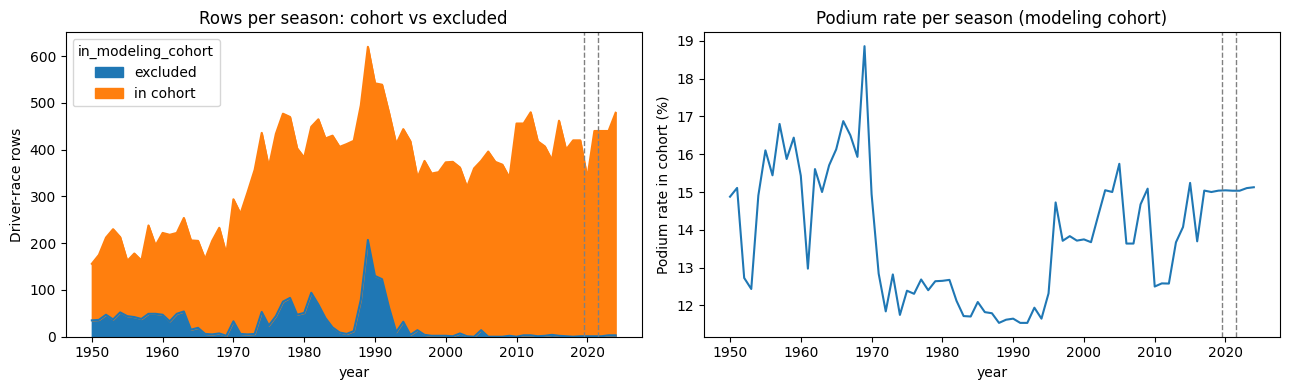

PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/cohort_split_summary.csv')

In [15]:
# 12b. Modeling cohort flag. Defines scope only: no features, no labels, no deletions.
NON_START_STATUS = {'did not qualify','did not prequalify','did not pre-qualify','107% rule','withdrew','did not start'}
STOOD_DOWN_AT_ZERO_LAPS = {'injury','injured','physical','safety','safety concerns','disqualified','excluded'}

def assign_cohort(df):
    out = df.copy()
    status = out.result_status.fillna('').str.strip().str.casefold()
    zero_laps = out.laps.fillna(0).eq(0)
    rules = [
        ('Indianapolis 500 (1950-1960)',              out.indianapolis_500_1950_1960.astype(bool)),
        ('did not start: status',                    status.isin(NON_START_STATUS)),
        ('did not start: no grid slot and no laps',  out.grid.eq(0) & zero_laps),
        ('did not start: stood down (0 laps)',       zero_laps & status.isin(STOOD_DOWN_AT_ZERO_LAPS)),
    ]
    reason = pd.Series(pd.NA, index=out.index, dtype='string')
    for name, mask in rules:
        reason = reason.mask(reason.isna() & mask.fillna(False), name)
    out['cohort_exclusion_reason'] = reason
    out['in_modeling_cohort'] = reason.isna()
    out['pit_lane_start_candidate'] = out.in_modeling_cohort & out.grid.eq(0) & out.laps.gt(0)
    split = pd.Series('outside splits', index=out.index, dtype='string')
    for name, (lo, hi) in SPLITS.items():
        split = split.mask(out.year.between(lo, hi), name)
    out['split'] = split
    return out

analysis_base = assign_cohort(analysis_base)
cohort = analysis_base[analysis_base.in_modeling_cohort]

# Checks
assert analysis_base.loc[analysis_base.verified_relief_only, 'in_modeling_cohort'].eq(False).all(), 'relief-only drivers must be excluded'
assert analysis_base.loc[analysis_base.participation_evidence.str.startswith('conflicting'), 'in_modeling_cohort'].eq(False).all()
assert not cohort.duplicated(PAIR).any()
assert cohort.split.ne('outside splits').all(), 'every cohort row must belong to train, validation or test'

# What was excluded and why (podium rows excluded should be Indianapolis only)
excl = (analysis_base[~analysis_base.in_modeling_cohort]
        .groupby('cohort_exclusion_reason').agg(rows=('podium','size'), podium_rows=('podium','sum'))
        .reindex(['Indianapolis 500 (1950-1960)','did not start: status','did not start: no grid slot and no laps',
                  'did not start: stood down (0 laps)']).fillna(0).astype(int))
excl.loc['total excluded'] = excl.sum()
excl.loc['in modeling cohort'] = [len(cohort), int(cohort.podium.sum())]
display(excl)
non_indy_podium_excluded = int(analysis_base.loc[~analysis_base.in_modeling_cohort &
    analysis_base.cohort_exclusion_reason.ne('Indianapolis 500 (1950-1960)'), 'podium'].sum())
print(f'Podium rows excluded outside Indianapolis: {non_indy_podium_excluded} (expected 0; inspect any that appear).')
display(analysis_base.loc[~analysis_base.in_modeling_cohort &
    analysis_base.cohort_exclusion_reason.ne('Indianapolis 500 (1950-1960)') & analysis_base.podium.eq(1),
    ['year','race_name','driver_surname','grid','laps','result_status','positionOrder','cohort_exclusion_reason']])

# Kept zero-lap starters: show they are real retirements, not hidden non-starters
kept_zero = cohort[cohort.laps.eq(0)]
display(kept_zero.result_status.value_counts().head(15).rename('kept rows with 0 laps (started, retired on lap 1)').to_frame())

# Pit-lane start candidates: do they have a qualifying record?
qrow = clean['qualifying'][PAIR].drop_duplicates().assign(has_qualifying_record=True)
analysis_base = analysis_base.merge(qrow, on=PAIR, how='left', validate='one_to_one')
analysis_base['has_qualifying_record'] = analysis_base.has_qualifying_record.astype('boolean').fillna(False)
cohort = analysis_base[analysis_base.in_modeling_cohort]
pit = cohort[cohort.pit_lane_start_candidate]
display(pit.groupby((pit.year//10*10).rename('decade')).agg(rows=('raceId','size'),
        with_qualifying_record=('has_qualifying_record','sum')))

# Cohort per split
split_table = (cohort.groupby('split').agg(rows=('podium','size'), races=('raceId','nunique'),
               podium_rows=('podium','sum'), first_year=('year','min'), last_year=('year','max'))
               .reindex(list(SPLITS)))
split_table['podium_pct'] = (100*split_table.podium_rows/split_table.rows).round(2)
display(split_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
per_year = analysis_base.groupby(['year','in_modeling_cohort']).size().unstack(fill_value=0)
per_year.rename(columns={True:'in cohort', False:'excluded'}).plot.area(ax=axes[0], stacked=True)
axes[0].set_ylabel('Driver-race rows'); axes[0].set_title('Rows per season: cohort vs excluded')
(cohort.groupby('year').podium.mean()*100).plot(ax=axes[1])
axes[1].set_ylabel('Podium rate in cohort (%)'); axes[1].set_title('Podium rate per season (modeling cohort)')
for ax in axes:
    for x in (SPLITS['validation'][0], SPLITS['test'][0]):
        ax.axvline(x-0.5, color='gray', ls='--', lw=1)
figure('15_modeling_cohort')

clean_export(analysis_base, 'driver_race_descriptive_base')          # refresh with cohort columns
clean_export(analysis_base.loc[analysis_base.in_modeling_cohort,
             PAIR+['resultId','year','split','podium','pit_lane_start_candidate','has_qualifying_record',
                   'feature_attribution_unverified']], 'modeling_cohort_keys')
clean_export(analysis_base.loc[~analysis_base.in_modeling_cohort,
             PAIR+['resultId','year','race_name','driver_surname','grid','laps','result_status','cohort_exclusion_reason']],
             'cohort_exclusions')
clean_export(excl.reset_index(), 'cohort_exclusion_summary')
clean_export(split_table.reset_index(), 'cohort_split_summary')


**Interpretation:** `analysis_base` now carries `in_modeling_cohort`, `cohort_exclusion_reason` and `split` for every driver-race. The exclusion table shows how many rows each rule removed; podium rows should only be excluded with the Indianapolis 500, and the notebook prints any exception. Kept zero-lap rows are lap-1 retirements of drivers who held a grid slot. `modeling_cohort_keys.csv` lists the rows the model will predict for; features are built on these keys later, using pre-race information only. Status and laps define scope here and must never be passed to a model.

## 12c. Status-to-cause mapping for Question 3
Question 3 compares mechanical retirement rates per constructor in 2014–2021 and 2022–2024. The brief defines a mechanical retirement as an actual start that ended because a car component failed, and excludes crash-, driver- and regulation-caused endings (B p.3). The status table is text, so every status from 2014 onward is assigned one cause: finished, mechanical, accident/damage, driver/rules or ambiguous. Lapped finishes (`+1 Lap`…) are finishes, not retirements (C pp.3–5). Statuses whose cause cannot be told from the text (Retired, Puncture, Tyre, Wheel, wings, Undertray, Wheel nut, Vibrations, Out of fuel) are kept separate and tested as a sensitivity. The denominator is actual starts: the modeling cohort from Section 12b.

In [16]:
# 12c. Status-to-cause mapping for Question 3 (mechanical retirements). Analysis only, never a model input.
STATUS_CAUSE = {
    # mechanical: the car failed
    **{s: 'mechanical' for s in [
        'Engine','Power Unit','Gearbox','Brakes','Suspension','Hydraulics','Electrical','Power loss','Oil leak',
        'Overheating','Water pressure','Mechanical','Turbo','ERS','Fuel pressure','Exhaust','Electronics','Water leak',
        'Battery','Radiator','Transmission','Steering','Oil pressure','Technical','Clutch','Throttle','Driveshaft',
        'Fuel leak','Drivetrain','Brake duct','Seat','Spark plugs','Water pump','Cooling system','Fuel pump','Differential']},
    # accident or contact damage
    **{s: 'accident/damage' for s in ['Collision','Accident','Collision damage','Spun off','Damage','Debris']},
    # driver or regulations
    **{s: 'driver/rules' for s in ['Disqualified','Excluded','Illness']},
    # cause cannot be told from the status text
    **{s: 'ambiguous' for s in ['Retired','Wheel','Puncture','Tyre','Undertray','Front wing','Rear wing','Wheel nut',
                                 'Vibrations','Out of fuel']},
    # did not start (already outside the cohort; listed so every status has a category)
    **{s: 'did not start' for s in ['Did not qualify','Did not prequalify','107% Rule','Withdrew','Did not start']},
}
FINISH_PATTERN = r'(?:Finished|\+\d+ Laps?)'

def status_cause(status):
    s = status.fillna('').str.strip()
    out = s.map(STATUS_CAUSE).astype('string')
    out = out.mask(s.str.fullmatch(FINISH_PATTERN), 'finished')
    return out.fillna('unmapped')

analysis_base['status_cause'] = status_cause(analysis_base.result_status)

# Q3 scope: actual starts (modeling cohort) from 2014 onward. Every status there must be mapped.
q3_rows = analysis_base[analysis_base.in_modeling_cohort & analysis_base.year.ge(2014)]
unmapped = q3_rows.loc[q3_rows.status_cause.eq('unmapped'), 'result_status'].value_counts()
if len(unmapped):
    display(unmapped.rename('unmapped rows').to_frame())
    raise ValueError('Statuses in the Q3 scope are not mapped; add them to STATUS_CAUSE.')

display(q3_rows.groupby('status_cause').agg(rows=('raceId','size'), statuses=('result_status','nunique'))
        .sort_values('rows', ascending=False))
print('Ambiguous statuses (2014+):')
display(q3_rows.loc[q3_rows.status_cause.eq('ambiguous'),'result_status'].value_counts().to_frame('rows'))

# Sensitivity: mechanical totals with ambiguous counted as non-mechanical (main) vs mechanical (upper bound)
era = np.where(q3_rows.year.le(2021), '2014-2021', '2022-2024')
sens = (q3_rows.assign(era=era)
        .groupby('era').agg(starts=('raceId','size'),
                            mechanical=('status_cause', lambda s: int(s.eq('mechanical').sum())),
                            mechanical_incl_ambiguous=('status_cause', lambda s: int(s.isin(['mechanical','ambiguous']).sum()))))
sens['rate_pct'] = (100*sens.mechanical/sens.starts).round(2)
sens['rate_incl_ambiguous_pct'] = (100*sens.mechanical_incl_ambiguous/sens.starts).round(2)
display(sens)

# Statuses outside the Q3 scope that are still unmapped (older eras): informational only
older = analysis_base.loc[analysis_base.status_cause.eq('unmapped'),'result_status'].value_counts()
print(f'{len(older)} older-era statuses are unmapped ({int(older.sum())} rows); they are outside the Q3 window.')

clean_export(pd.DataFrame(sorted(STATUS_CAUSE.items()), columns=['status','cause']), 'q3_status_cause_mapping')
clean_export(q3_rows[PAIR+['year','constructorId','constructor_name','result_status','status_cause']], 'q3_starts_with_cause')

,rows,statuses
status_cause,,
finished,3825,9
mechanical,372,36
accident/damage,308,6
ambiguous,88,10
driver/rules,14,3


Ambiguous statuses (2014+):


,rows
result_status,
Retired,50
Wheel,11
Puncture,7
Tyre,4
Undertray,4
Rear wing,3
Front wing,3
Wheel nut,3
Vibrations,2


,starts,mechanical,mechanical_incl_ambiguous,rate_pct,rate_incl_ambiguous_pct
era,,,,,
2014-2021,3255,297,366,9.12,11.24
2022-2024,1352,75,94,5.55,6.95


46 older-era statuses are unmapped (968 rows); they are outside the Q3 window.


PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/q3_starts_with_cause.csv')

**Interpretation:** all 4,607 starts from 2014 onward are mapped (3,255 in 2014–2021, 1,352 in 2022–2024). The overall mechanical retirement rate fell from **9.1% to 5.6%**; counting the 88 ambiguous retirements as mechanical gives 11.2% and 7.0%, so the drop does not depend on that choice. The per-constructor comparison is computed in the Question 3 section from `q3_starts_with_cause.csv`. `status_cause` is an analysis column only: race-ending status is a post-race outcome and is never a model input.

## 12d. Nationality-to-country mapping for Question 2
Question 2 asks whether drivers reach the podium more often at home, controlling for starting position (B p.3). Driver nationalities (`British`) and circuit countries (`UK`) use different words, so an explicit mapping is needed. **Home is decided by circuit country, not race name**: a race named after another country but held in Italy is a home race for Italian drivers. Decisions: `Argentine`/`Argentinian` are the same; dual nationalities (`American-Italian`, `Argentine-Italian`) count as home in either country; `USA`/`United States` are the same circuit country; nationalities whose country never hosted a race (Finnish, Irish, East German, Rhodesian…) are always away. A nationality missing from the mapping stops the notebook, so nothing silently becomes "away".

In [17]:
# 12d. Nationality-to-country mapping for Question 2 (home-race association). Analysis only, never a model input.
NATIONALITY_TO_COUNTRIES = {
    'American':{'USA'}, 'American-Italian':{'USA','Italy'}, 'Argentine':{'Argentina'}, 'Argentinian':{'Argentina'},
    'Argentine-Italian':{'Argentina','Italy'}, 'Australian':{'Australia'}, 'Austrian':{'Austria'}, 'Belgian':{'Belgium'},
    'Brazilian':{'Brazil'}, 'British':{'UK'}, 'Canadian':{'Canada'}, 'Chilean':{'Chile'}, 'Chinese':{'China'},
    'Colombian':{'Colombia'}, 'Czech':{'Czech Republic'}, 'Danish':{'Denmark'}, 'Dutch':{'Netherlands'},
    'East German':{'East Germany'}, 'Finnish':{'Finland'}, 'French':{'France'}, 'German':{'Germany'},
    'Hungarian':{'Hungary'}, 'Indian':{'India'}, 'Indonesian':{'Indonesia'}, 'Irish':{'Ireland'}, 'Italian':{'Italy'},
    'Japanese':{'Japan'}, 'Liechtensteiner':{'Liechtenstein'}, 'Malaysian':{'Malaysia'}, 'Mexican':{'Mexico'},
    'Monegasque':{'Monaco'}, 'New Zealander':{'New Zealand'}, 'Polish':{'Poland'}, 'Portuguese':{'Portugal'},
    'Rhodesian':{'Rhodesia'}, 'Russian':{'Russia'}, 'South African':{'South Africa'}, 'Spanish':{'Spain'},
    'Swedish':{'Sweden'}, 'Swiss':{'Switzerland'}, 'Thai':{'Thailand'}, 'Uruguayan':{'Uruguay'}, 'Venezuelan':{'Venezuela'},
}
CIRCUIT_COUNTRY_ALIASES = {'United States':'USA'}   # same country, two spellings in circuits.csv

analysis_base['circuit_country_std'] = analysis_base.circuit_country.str.strip().replace(CIRCUIT_COUNTRY_ALIASES)
nat = analysis_base.driver_nationality.str.strip()
analysis_base['nationality_mapped'] = nat.isin(NATIONALITY_TO_COUNTRIES)
analysis_base['home_race'] = pd.Series(
    [(c in NATIONALITY_TO_COUNTRIES[n]) if n in NATIONALITY_TO_COUNTRIES and pd.notna(c) else pd.NA
     for n, c in zip(nat, analysis_base.circuit_country_std)], index=analysis_base.index, dtype='boolean')

# Q2 scope: the modeling cohort. Every nationality there must be mapped (unknowns are never silently 'away').
q2_rows = analysis_base[analysis_base.in_modeling_cohort]
unmapped = q2_rows.loc[~q2_rows.nationality_mapped, 'driver_nationality'].value_counts()
if len(unmapped):
    display(unmapped.rename('unmapped rows').to_frame())
    raise ValueError('Nationalities in the cohort are not mapped; add them to NATIONALITY_TO_COUNTRIES.')
assert q2_rows.home_race.notna().all()

hosted = set(analysis_base.circuit_country_std.dropna())
mapping_table = pd.DataFrame([{'nationality':n, 'countries':', '.join(sorted(c)),
                               'country_ever_hosted_a_race':bool(c & hosted)} for n, c in NATIONALITY_TO_COUNTRIES.items()])
summary = (q2_rows.groupby('driver_nationality')
           .agg(rows=('raceId','size'), home_rows=('home_race','sum'))
           .join(mapping_table.set_index('nationality')).sort_values('rows', ascending=False))
display(summary.head(25))
print(f"Home rows: {int(q2_rows.home_race.sum()):,} of {len(q2_rows):,} cohort rows "
      f"({100*q2_rows.home_race.mean():.1f}%). Nationalities that never had a home race: "
      f"{int(summary.home_rows.eq(0).sum())} of {len(summary)}.")
display(q2_rows.groupby(q2_rows.year//10*10).home_race.agg(['sum','mean']).rename(
        columns={'sum':'home_rows','mean':'home_share'}).rename_axis('decade'))

clean_export(mapping_table, 'q2_nationality_country_mapping')
clean_export(q2_rows[PAIR+['year','driver_nationality','circuit_country_std','home_race','grid','podium']], 'q2_rows_with_home_flag')

,rows,home_rows,countries,country_ever_hosted_a_race
driver_nationality,,,,
British,4278,447,UK,True
Italian,2997,398,Italy,True
French,2914,205,France,True
German,2316,198,Germany,True
Brazilian,1850,114,Brazil,True
Finnish,1157,0,Finland,False
Spanish,881,61,Spain,True
Australian,866,28,Australia,True
American,837,112,USA,True


Home rows: 1,927 of 24,603 cohort rows (7.8%). Nationalities that never had a home race: 16 of 43.


,home_rows,home_share
decade,,
1950,338,0.22639
1960,269,0.143773
1970,276,0.080466
1980,323,0.082482
1990,286,0.073959
2000,215,0.059458
2010,152,0.035514
2020,68,0.031925


PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/q2_rows_with_home_flag.csv')

**Interpretation:** all 43 nationalities in the cohort are mapped; 1,927 of 24,603 cohort rows (7.8%) are home races, and 16 nationalities never had one. Home races fall from **23% of rows in the 1950s to about 3% since 2010**: early fields included many local drivers racing once at home, while the modern calendar is global. Era is therefore linked to both home status and podium chances, so Question 2 must compare home and away within grid bands and also report the result by era. `home_race` depends only on driver nationality and circuit country, both fixed before the race weekend, so it is pre-race information. It is used here for Question 2 and is later added as a candidate feature (FE4), where the ablation measures its contribution.

## 12e. Final cleaning checks and shared-car flag
Four last checks before the cleaning is closed:
1. **Qualifying grain:** `qualifying` must have one row per driver per race, so it can later be joined for features without multiplying rows.
2. **Pit-lane starts without a qualifying record:** listed for review.
3. **Shared-car flag:** a kept entry whose car lists more than one driver is flagged `shared_car_entry`. A relief driver with a single entry inherits the car's grid slot and cannot be told apart from its starter, so this flag would allow an exclusion experiment. That experiment turned out unnecessary: the last shared-car row is from 1981, and the model table starts in 2003, so no modeled row is affected. The flag is never a model input, because it is only known after the race.
4. **Podium drivers per cohort race:** historical races are not forced to three podium drivers; any race in the cohort with a different count is listed.

In [18]:
# 12e. Final cleaning checks.
# 1. Qualifying grain
q_dupes = int(clean['qualifying'].duplicated(PAIR).sum())
print(f'Repeated (raceId, driverId) rows in qualifying: {q_dupes}')
assert q_dupes == 0, 'qualifying must have one row per driver per race before it is joined for features'

# 2. Pit-lane start candidates without a qualifying record
no_q = analysis_base[analysis_base.pit_lane_start_candidate & ~analysis_base.has_qualifying_record]
display(no_q[['year','race_name','driver_surname','grid','laps','result_status','positionOrder']])

# 3. Shared-car flag (exclusion experiments only; never a feature)
analysis_base['shared_car_entry'] = analysis_base.car_driver_count.fillna(1).gt(1)
cohort = analysis_base[analysis_base.in_modeling_cohort]
shared = cohort[cohort.shared_car_entry]
print(f'Cohort rows whose kept car lists more than one driver: {len(shared):,} '
      f'({int(shared.podium.sum())} podium rows); last such season: {int(shared.year.max()) if len(shared) else "none"}.')
display(shared.groupby(shared.year//10*10).size().rename('shared_car_rows').rename_axis('decade').to_frame())

# 4. Podium drivers per race in the cohort
per_race = cohort.groupby(['raceId','year','race_name']).podium.sum().rename('podium_drivers').reset_index()
odd = per_race[per_race.podium_drivers.ne(3)]
print(f'{len(odd)} of {len(per_race):,} cohort races do not have exactly 3 podium drivers.')
display(odd)
if len(odd):
    detail = cohort[cohort.raceId.isin(odd.raceId) & cohort.podium.eq(1)]
    display(detail[['year','race_name','driver_surname','number','grid','positionOrder','source_entry_count',
                    'car_driver_count','shared_car_entry']].sort_values(['year','positionOrder']))

clean_export(analysis_base, 'driver_race_descriptive_base')
clean_export(analysis_base.loc[analysis_base.in_modeling_cohort,
             PAIR+['resultId','year','split','podium','pit_lane_start_candidate','has_qualifying_record',
                   'shared_car_entry','feature_attribution_unverified']], 'modeling_cohort_keys')
clean_export(per_race, 'cohort_podium_drivers_per_race')


Repeated (raceId, driverId) rows in qualifying: 0


,year,race_name,driver_surname,grid,laps,result_status,positionOrder
24168,2019,Chinese Grand Prix,Albon,0,55,+1 Lap,10


Cohort rows whose kept car lists more than one driver: 113 (19 podium rows); last such season: 1981.


,shared_car_rows
decade,
1950,97
1960,13
1970,2
1980,1


1 of 1,114 cohort races do not have exactly 3 podium drivers.


,raceId,year,race_name,podium_drivers
786,792,1955,Argentine Grand Prix,4


,year,race_name,driver_surname,number,grid,positionOrder,source_entry_count,car_driver_count,shared_car_entry
19548,1955,Argentine Grand Prix,Fangio,2,3,1,1,1.0,False
19544,1955,Argentine Grand Prix,González,12,1,2,1,3.0,True
19550,1955,Argentine Grand Prix,Maglioli,10,5,3,1,3.0,True
19554,1955,Argentine Grand Prix,Farina,10,5,3,2,3.0,True


PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/cohort_podium_drivers_per_race.csv')

**Interpretation (18 October run):**
- `qualifying` has no repeated driver-race rows, so it can be joined for features one-to-one.
- 71 of the 72 pit-lane candidates have a qualifying record. The exception, **Albon at the 2019 Chinese GP**, missed qualifying after a practice crash and started from the pit lane; he stays in the cohort.
- `shared_car_entry` marks cohort rows whose car also lists another driver; these are concentrated in the 1950s. They stay in the cohort for the descriptive questions; none falls in the 2003–2024 model table, so no exclusion experiment is needed.
- **Races without exactly three podium drivers.** The raw audit flagged 18 races, all from 1950–1960. In that era a shared car's result was credited to every driver who drove it, so a race could have four or five drivers with a top-three classification. After one row per driver and the selected-entry target, most of them have three; three of the remaining ones are Indianapolis 500s, which are outside the cohort. Any cohort race still listed above is a shared-drive case: **more than three** when a driver whose only entry is a shared car (`car_driver_count > 1`, most likely a relief driver) is credited with that car's result; **fewer than three** when every driver credited with a podium car has their kept entry in another car (the car they started). The detail table shows which applies. No label was changed to force three per race.

## 13. Before/after EDA
Compares row counts, label rates, missingness and qualifying coverage at each cleaning stage, so the effect of every cleaning step is visible rather than assumed.

,stage,rows,positive_labels,unique_pairs,positive_pct
0,raw recorded entries,26759,3397,26668,12.694794
1,typed master entries,26759,3397,26668,12.694794
2,car-based rule / driver target,26668,3378,26668,12.666867
3,optional non-Indy view,26287,3343,26287,12.717313
4,"modeling cohort (starters, no Indy)",24603,3343,24603,13.587774


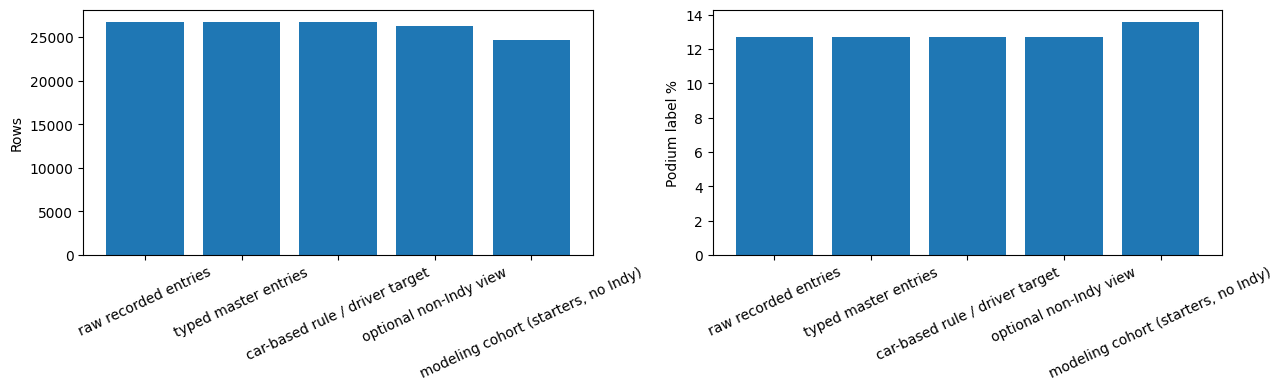

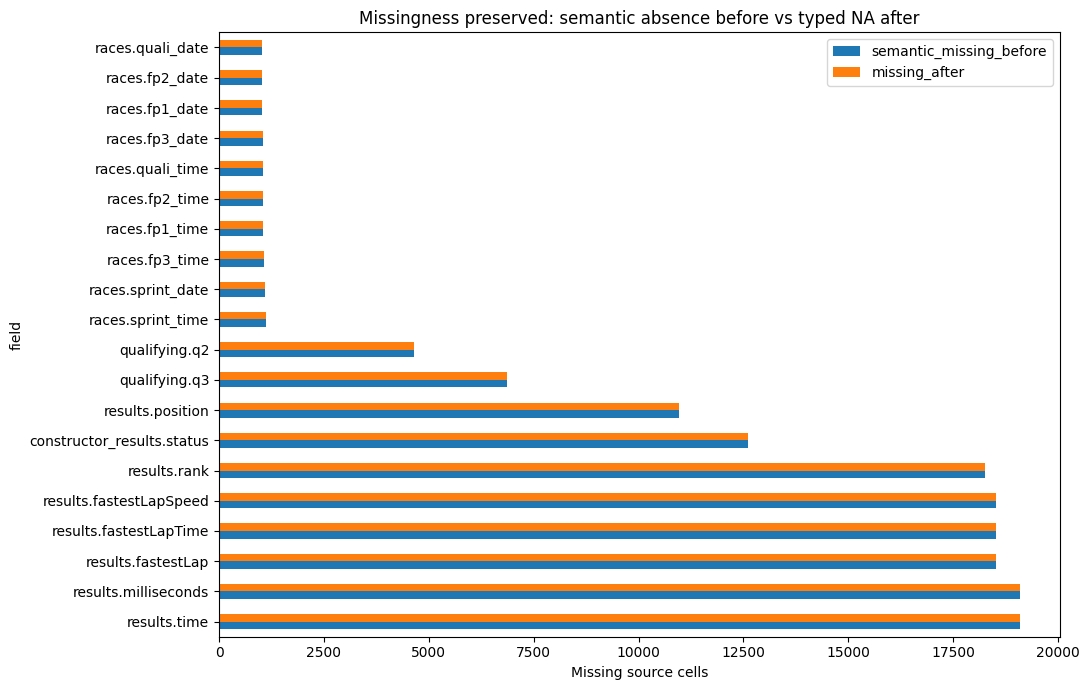

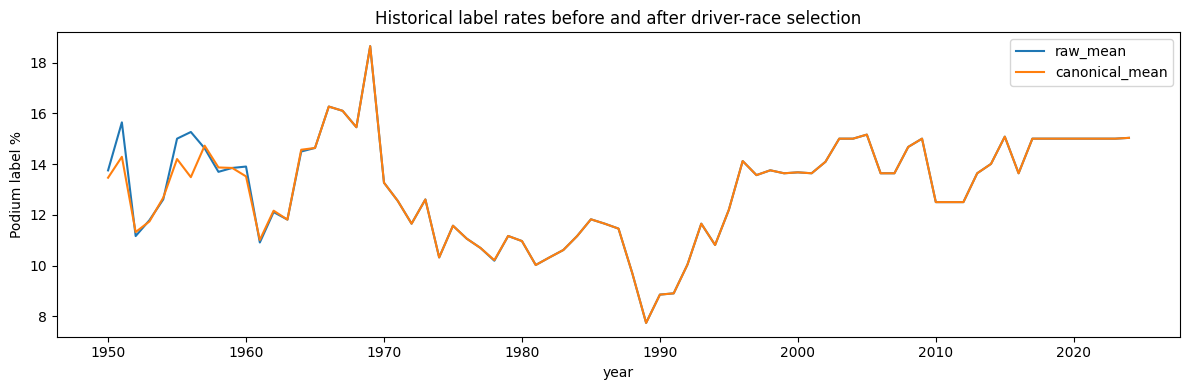

,raceId,raw_positive_rows,canonical_positive_drivers,year,name
838,839,4,3,1950,Italian Grand Prix
825,826,4,4,1951,Indianapolis 500
827,828,5,3,1951,French Grand Prix
830,831,4,3,1951,Italian Grand Prix
808,809,4,3,1953,Indianapolis 500
809,810,4,3,1953,Dutch Grand Prix
803,804,4,3,1954,German Grand Prix
805,806,4,3,1954,Italian Grand Prix
791,792,7,4,1955,Argentine Grand Prix
792,793,4,3,1955,Monaco Grand Prix


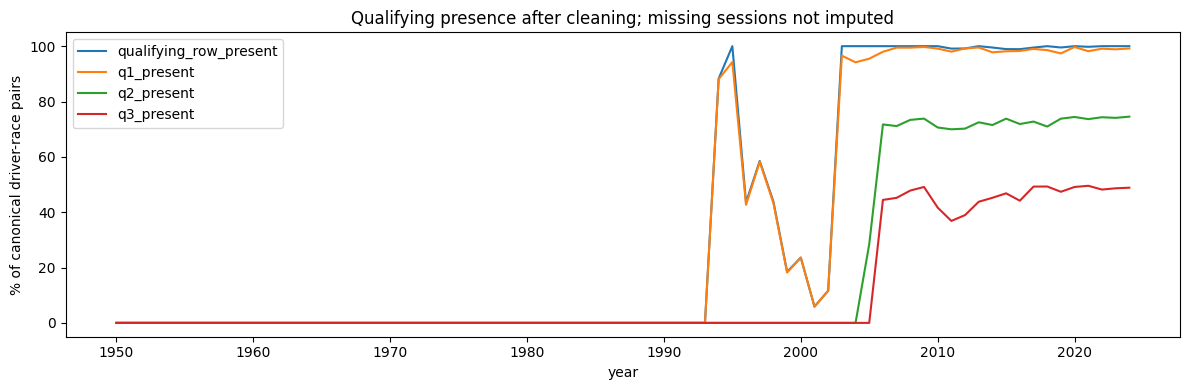

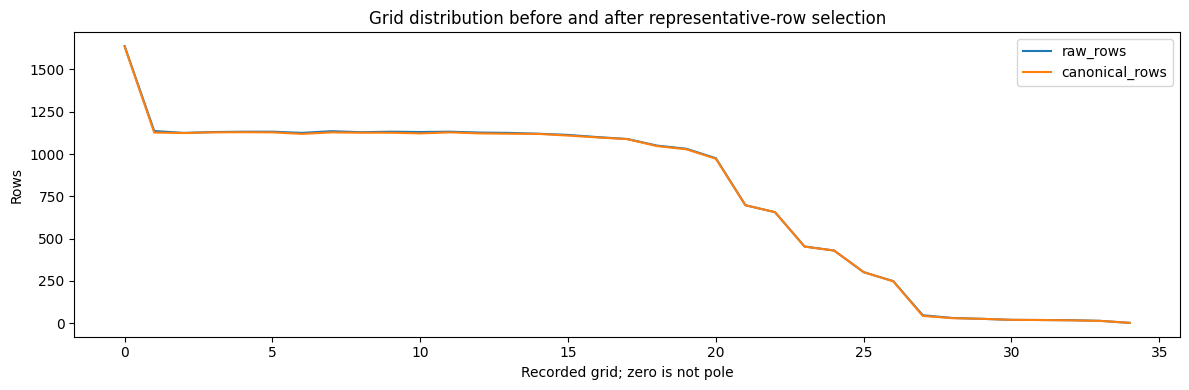

In [19]:
# 13. Post-cleaning EDA: reconcile changes instead of assuming cleaning helped.
before = clean['results'].assign(podium=clean['results'].positionOrder.le(3).astype('Int64'))
stage_summary = pd.DataFrame([
    {'stage':'raw recorded entries','rows':len(raw['results']),'positive_labels':int(before.podium.sum()),'unique_pairs':before.groupby(PAIR).ngroups},
    {'stage':'typed master entries','rows':len(before),'positive_labels':int(before.podium.sum()),'unique_pairs':before.groupby(PAIR).ngroups},
    {'stage':'car-based rule / driver target','rows':len(analysis_base),'positive_labels':int(analysis_base.podium.sum()),'unique_pairs':len(analysis_base)},
    {'stage':'optional non-Indy view','rows':len(non_indy_view),'positive_labels':int(non_indy_view.podium.sum()),'unique_pairs':len(non_indy_view)},
    {'stage':'modeling cohort (starters, no Indy)','rows':len(cohort),'positive_labels':int(cohort.podium.sum()),'unique_pairs':len(cohort)}])
stage_summary['positive_pct'] = 100*stage_summary.positive_labels/stage_summary.rows
clean_export(stage_summary,'before_after_stage_summary');display(stage_summary)

fig, axes = plt.subplots(1,2,figsize=(13,4))
axes[0].bar(stage_summary.stage,stage_summary.rows);axes[0].set_ylabel('Rows')
axes[1].bar(stage_summary.stage,stage_summary.positive_pct);axes[1].set_ylabel('Podium label %')
for ax in axes: ax.tick_params(axis='x',rotation=25)
figure('10_cleaning_rows_and_label_rates')

missing_plot = conversion_report.loc[conversion_report.semantic_missing_before.gt(0)].nlargest(20,'semantic_missing_before').copy()
if len(missing_plot):
    missing_plot['field']=missing_plot.table+'.'+missing_plot.column
    missing_plot.set_index('field')[['semantic_missing_before','missing_after']].plot.barh(figsize=(11,7))
    plt.xlabel('Missing source cells');plt.title('Missingness preserved: semantic absence before vs typed NA after')
    figure('11_cleaning_missingness_preserved')

raw_by_year = before.merge(clean['races'][['raceId','year']],on='raceId',validate='many_to_one').groupby('year').podium.agg(['size','mean'])
after_by_year = analysis_base.groupby('year').podium.agg(['size','mean'])
annual = raw_by_year.add_prefix('raw_').join(after_by_year.add_prefix('canonical_')).sort_index()
clean_export(annual.reset_index(),'before_after_annual_rates')
(annual[['raw_mean','canonical_mean']]*100).plot(figsize=(12,4))
plt.ylabel('Podium label %');plt.title('Historical label rates before and after driver-race selection')
figure('12_cleaning_annual_rates')

race_positive = before.groupby('raceId').podium.sum().rename('raw_positive_rows').to_frame().join(
    analysis_base.groupby('raceId').podium.sum().rename('canonical_positive_drivers')).reset_index()
race_positive = race_positive.merge(clean['races'][['raceId','year','name']],on='raceId',validate='one_to_one')
unusual = race_positive.loc[race_positive.raw_positive_rows.ne(3) | race_positive.canonical_positive_drivers.ne(3)]
clean_export(race_positive,'before_after_race_positive_counts')
display(unusual.sort_values(['year','raceId']))

# Aggregate qualifying presence to driver-race grain before joining: no row multiplication.
q = clean['qualifying'].copy()
for col in ['q1','q2','q3']: q[col+'_present'] = q[col].notna()
q['qualifying_row_present'] = True
flags = ['qualifying_row_present','q1_present','q2_present','q3_present']
qflags = q.groupby(PAIR,as_index=False)[flags].max()
qcoverage = analysis_base[PAIR+['year']].merge(qflags,on=PAIR,how='left',validate='one_to_one')
qcoverage[flags] = qcoverage[flags].astype('boolean').fillna(False)
qual_annual = qcoverage.groupby('year')[flags].mean().mul(100).sort_index()
clean_export(qual_annual.reset_index(),'cleaned_qualifying_coverage_by_year')
qual_annual.plot(figsize=(12,4));plt.ylabel('% of canonical driver-race pairs')
plt.title('Qualifying presence after cleaning; missing sessions not imputed')
figure('13_cleaning_qualifying_coverage')

grid_compare = pd.concat([before.grid.value_counts().rename('raw_rows'),
                          analysis_base.grid.value_counts().rename('canonical_rows')],axis=1).fillna(0).sort_index()
clean_export(grid_compare.rename_axis('grid').reset_index(),'before_after_grid_counts')
grid_compare.plot(figsize=(12,4));plt.ylabel('Rows');plt.xlabel('Recorded grid; zero is not pole')
plt.title('Grid distribution before and after representative-row selection')
figure('14_cleaning_grid_distribution')

**Interpretation:** 26,759 result rows become **26,668 driver-race rows** after Section 11 and **24,603 modeling-cohort rows** after Section 12b. The podium share is 12.7% in the raw rows and 13.6% in the cohort, because non-starters, who can never reach the podium, are removed. The table of races not equal to three counts raw rows against the driver-level label over all driver-races (including the Indianapolis 500); the cohort version is in Section 12e.

Missingness before/after uses semantic missing values on both sides, not pandas' raw-string `isna()` count. Unchanged missingness is the expected result when replacing a sentinel with NA. Qualifying coverage is measured against canonical driver-race pairs; presence aggregation is only an EDA diagnostic and does not choose qualifying times for later features.

## 14. Final integrity, exports and cleaning summary
Re-checks that the raw files and frames are unchanged, exports every typed table and the cleaning status, and links each Part 1 finding to how it was handled.

In [20]:
# 14. Final integrity, reusable exports and an honest readiness gate.
for t in TABLES:
    assert frame_hash(raw[t]) == INITIAL_FRAME_HASHES[t], f'Raw frame modified: {t}'
    assert file_hash(DATA_DIR/f'{t}.csv') == INITIAL_FILE_HASHES[t], f'Raw file modified: {t}'
    assert len(clean[t]) == len(raw[t])
    clean_export(clean[t],'typed_'+t)
assert len(analysis_base)==len(driver_race)
assert not analysis_base.duplicated(PAIR).any()
assert analysis_base.podium.isin([0,1]).all()

cleaning_status = {
    'run_id':RUN_ID,'snapshot_id':snapshot_id,
    'implemented_cleaning_checks_passed':True,
    'raw_results_rows':len(raw['results']), 'canonical_driver_race_rows':len(driver_race),
    'alternative_result_rows_preserved':len(raw['results'])-len(driver_race),
    'repeated_pairs_with_unverified_feature_attribution':int(driver_race.feature_attribution_unverified.sum()),
    'grid_zero_canonical_rows':int(analysis_base.grid_zero.sum()),
    'default_indianapolis_policy':'kept in master; excluded from modeling cohort',
    'duplicate_policy':'car-based rule: entry whose car lists only this driver; otherwise lowest numeric resultId',
    'repeated_groups_by_step':duplicate_groups.selection_basis.value_counts().to_dict(),
    'groups_differing_from_lowest_id':int(comparison.differs_from_lowest_id.sum()),
    'documented_start_tests_passed':f'{int(start_tests.passed.sum())}/{len(start_tests)}',
    'participation_conflicts':int(analysis_base.participation_evidence.eq('conflicting non-qualification status and positive laps').sum()),
    'target_policy':TARGET_POLICY,
    'groups_where_label_policies_differ':int(comparison.any_entry_vs_selected_entry_label_differs.sum()),
    'verified_relief_only_entries':int(analysis_base.verified_relief_only.sum()),
    'modeling_cohort_rows':int(analysis_base.in_modeling_cohort.sum()),
    'cohort_exclusions_by_reason':analysis_base.cohort_exclusion_reason.value_counts().to_dict(),
    'cohort_rows_by_split':cohort.split.value_counts().to_dict(),
    'pit_lane_start_candidates':int(analysis_base.pit_lane_start_candidate.sum()),
    'shared_car_entries_in_cohort':int(analysis_base.loc[analysis_base.in_modeling_cohort,'shared_car_entry'].sum()),
    'qualifying_repeated_driver_race_rows':q_dupes,
    'q3_mechanical_rates_pct':sens['rate_pct'].to_dict(),
    'q3_mechanical_rates_incl_ambiguous_pct':sens['rate_incl_ambiguous_pct'].to_dict(),
    'q2_home_rows_in_cohort':int(q2_rows.home_race.sum()),
    'cleaning_phase_complete':True,
    'model_ready':False,
    'remaining':['Answer the three analytical questions (Q1 front-row conversion, Q2 home association, Q3 mechanical retirements)',
                 'Fix the chronological split and engineer leakage-safe pre-race features on modeling_cohort_keys',
                 'Preprocessing-order experiments, baseline and three models, ablation, test evaluation',
                 'XAI, inference function, report and submission']}
(CLEAN_DIR/'cleaning_status.json').write_text(json.dumps(cleaning_status,indent=2))
clean_export(pd.DataFrame({'figure':FIGURES}),'updated_figure_manifest')
display(pd.DataFrame([(k,v) for k,v in cleaning_status.items() if k!='remaining'],columns=['item','value']))
print('Cleaning outputs:',CLEAN_DIR)
print('Implemented cleaning checks passed. Cleaning complete; the model table is built in the Feature Engineering part below.')

# Connect each raw-audit finding to the implemented response without declaring open decisions fixed.
responses={
 'missing_value':('representation normalized; absence retained','No generic imputation; semantic missing counts reconciled.'),
 'surrounding_whitespace':('normalized on copies','Surrounding whitespace removed; text identities preserved.'),
 'driver_race_repeated':('grain resolved; historical attribution remains limited','Car-based rule (sole-driver car, else lowest resultId); nine documented starts as tests; alternatives preserved.'),
 'indianapolis_policy':('excluded from modeling cohort','Kept in master for analysis; in_modeling_cohort is False.'),
 'grid_zero_semantics':('resolved for the cohort','Non-starters excluded (12b); 72 remaining grid-zero rows are pit-lane start candidates, 71 with a qualifying record.'),
 'raw_podium_count_review':('explained','All 18 races are 1950-1960 shared-drive or Indianapolis cases; recounted per cohort race in 12e; never forced to three.')}
cleaning_register=issues.copy()
cleaning_register['cleaning_state']=[responses.get(k,('not automatically resolved','Review the original evidence.'))[0] for k in cleaning_register.check_id]
cleaning_register['implemented_response']=[responses.get(k,('not automatically resolved','Review the original evidence.'))[1] for k in cleaning_register.check_id]
clean_export(cleaning_register,'audit_finding_resolution_register')
summary=['# Cleaning run conclusion',f'Run: {RUN_ID}',f'Snapshot: {snapshot_id}',
         f'Raw results: {len(raw["results"]):,}; typed master: {len(clean["results"]):,}; driver-race projection: {len(driver_race):,}.',
         f'Selection: car-based rule (sole-driver car, else lowest numeric resultId). Target policy: {TARGET_POLICY}. Modeling cohort: {int(analysis_base.in_modeling_cohort.sum()):,} rows.',
         'Raw file/frame integrity and post-cleaning key/grain checks passed.',
         f'Documented-start tests passed: {int(start_tests.passed.sum())}/{len(start_tests)}; groups differing from plain lowest ID: {int(comparison.differs_from_lowest_id.sum())}.',
         f'Verified relief-only entries retained and flagged: {int(analysis_base.verified_relief_only.sum())}.',
         'Cleaning phase complete; features, models and experiments follow in this notebook.',
         'See audit_finding_resolution_register.csv and cleaning_status.json for remaining decisions.']
(CLEAN_DIR/'cleaning_conclusion.md').write_text('\n\n'.join(summary))

,item,value
0,run_id,20261018T184719_144775Z_825f42
1,snapshot_id,b04d1c0bdded62cdd31a7cf9ada8e1dc14371b6c9414ef...
2,implemented_cleaning_checks_passed,True
3,raw_results_rows,26759
4,canonical_driver_race_rows,26668
5,alternative_result_rows_preserved,91
6,repeated_pairs_with_unverified_feature_attribu...,85
7,grid_zero_canonical_rows,1635
8,default_indianapolis_policy,kept in master; excluded from modeling cohort
9,duplicate_policy,car-based rule: entry whose car lists only thi...


Cleaning outputs: /kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning
Implemented cleaning checks passed. Cleaning complete; the model table is built in the Feature Engineering part below.


731

## Cleaning summary and handoff
**Cleaning is complete.** Run All rebuilds everything from the 14 raw CSVs, which are never modified (Section 14 re-checks their hashes).

| Stage | Result (18 October run) |
|---|---|
| Typed copies (10) | 14 tables, every row kept, missing counts identical before and after |
| Keys (11) | 37/37 primary- and foreign-key checks passed |
| Duplicates (11) | 85 groups: 56 by sole-driver car, 29 by lowest `resultId`; 9/9 documented starts passed; 26,759 → 26,668 rows |
| Target (11) | `selected_entry`; differs from any-entry credit in 17 pre-1980 groups |
| Joins (12) | five many-to-one joins, no rows lost or duplicated |
| Cohort (12b) | 24,603 rows: train 22,473 (13.45% podium), validation 778 (15.04%), test 1,352 (15.09%) |
| Q3 mapping (12c) | 4,607 starts 2014+; mechanical 9.1% → 5.6% (sensitivity 11.2% → 7.0%) |
| Q2 mapping (12d) | 43 nationalities mapped; 7.8% of cohort rows are home races |
| Checks (12e) | qualifying one row per driver-race; pit-lane and shared-car cases flagged |

**Files for the next stages** (run folder `cleaning/`): `modeling_cohort_keys.csv` (rows to predict, with split and label), `driver_race_descriptive_base.csv` (all driver-races with flags, for the three questions), `q3_starts_with_cause.csv`, `q2_rows_with_home_flag.csv`, `cleaning_status.json`.

**Never use as model inputs:** `positionOrder`, points, laps, status, `status_cause`, participation flags, `shared_car_entry`, selection and audit columns. Features must use information available after qualifying and before the race. (`home_race` is allowed: nationality and circuit country are known in advance.)

**Sources:** each documented start in VERIFIED_STARTS (Section 11) carries the link to its source; the rule is tested against these cases on every run.

# Q1. Which circuits convert a front-row start into a podium most often, and does the ranking change after the 2014 hybrid era?
Front row is defined by the actual starting grid (after penalties); qualifying position is compared separately.


Overall front-row conversion by era:


,front_row_starts,podiums,rate_pct
era,,,
1950-2013,1771,992,56.0
2014-2024,454,345,76.0



Top 10 circuits 1950-2013 (at least 20 front-row starts; 29 ranked):


,circuit_name,front_row_starts,podiums,rate_pct,ci_pct
14,Circuit de Nevers Magny-Cours,36,29,80.6,65-90
2,Sepang International Circuit,30,21,70.0,52-83
38,Suzuka Circuit,50,35,70.0,56-81
19,Hungaroring,56,38,67.9,55-79
44,Autódromo do Estoril,26,17,65.4,46-81
6,Circuit de Barcelona-Catalunya,46,30,65.2,51-77
29,Shanghai International Circuit,20,13,65.0,43-82
17,Hockenheimring,66,40,60.6,49-71
49,Autódromo Hermanos Rodríguez,30,18,60.0,42-75
31,Autódromo José Carlos Pace,62,37,59.7,47-71



Top 10 circuits 2014-2024 (at least 20 front-row starts; 10 ranked):


,circuit_name,front_row_starts,podiums,rate_pct,ci_pct
41,Yas Marina Circuit,22,19,86.4,67-95
11,Circuit de Monaco,20,17,85.0,64-95
23,Circuit de Spa-Francorchamps,22,18,81.8,61-93
7,Circuit de Barcelona-Catalunya,22,18,81.8,61-93
90,Circuit of the Americas,20,16,80.0,58-92
16,Silverstone Circuit,24,18,75.0,55-88
92,Red Bull Ring,26,19,73.1,54-86
25,Autodromo Nazionale di Monza,22,16,72.7,52-87
5,Bahrain International Circuit,24,16,66.7,47-82
20,Hungaroring,22,13,59.1,39-77



7 circuits ranked in both eras; Spearman rank correlation of conversion rates: -0.18


,circuit_name,starts_pre,rate_pre,rank_pre,starts_post,rate_post,rank_post,rank_change
3,Hungaroring,56,67.9,1,22,59.1,7,-6
1,Circuit de Monaco,120,49.2,6,20,85.0,1,5
4,Circuit de Spa-Francorchamps,92,53.3,4,22,81.8,2,2
5,Autodromo Nazionale di Monza,128,46.9,7,22,72.7,6,1
2,Silverstone Circuit,94,56.4,3,24,75.0,4,-1
0,Circuit de Barcelona-Catalunya,46,65.2,2,22,81.8,2,0
6,Red Bull Ring,50,52.0,5,26,73.1,5,0



1994-2024: 10,441 of 12,247 cohort rows have a qualifying position.


,era,definition,starts,podiums,rate_pct
0,1994-2013,front row by grid,530,347,65.5
1,1994-2013,front row by qualifying,530,344,64.9
2,1994-2013,"qualified front row, started further back",9,2,22.2
3,2014-2024,front row by grid,454,345,76.0
4,2014-2024,front row by qualifying,454,336,74.0
5,2014-2024,"qualified front row, started further back",27,9,33.3


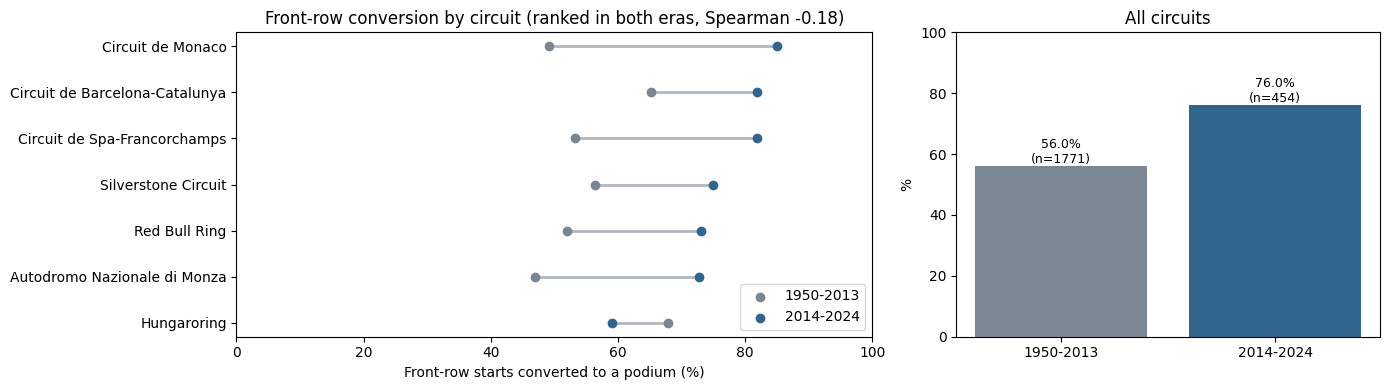

PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/q1_rank_change_both_eras.csv')

In [21]:
# Q1. Front-row conversion by circuit, before vs from the 2014 hybrid era.
# Joins: results (driver_race) -> races -> circuits (already in analysis_base); qualifying joined separately.
MIN_FRONT_ROW_STARTS = 20          # ranking threshold per circuit and era (about 10 races)
HYBRID_START = 2014                # first season of the turbo-hybrid era

def wilson(k, n, z=1.96):
    """95% Wilson interval for a proportion; stable for small samples."""
    p = k / n
    centre = (p + z*z/(2*n)) / (1 + z*z/n)
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return centre - half, centre + half

q1 = analysis_base[analysis_base.in_modeling_cohort].copy()
q1['era'] = np.where(q1.year.ge(HYBRID_START), '2014-2024', '1950-2013')
front = q1[q1.grid.isin([1, 2])]

conv = (front.groupby(['circuitId','circuit_name','era'])
        .agg(front_row_starts=('podium','size'), podiums=('podium','sum')).reset_index())
conv['rate'] = conv.podiums / conv.front_row_starts
conv[['ci_low','ci_high']] = conv.apply(lambda r: pd.Series(wilson(r.podiums, r.front_row_starts)), axis=1)
conv['ranked'] = conv.front_row_starts.ge(MIN_FRONT_ROW_STARTS)
conv['rank_in_era'] = (conv[conv.ranked].groupby('era').rate.rank(ascending=False, method='min'))

overall = front.groupby('era').agg(front_row_starts=('podium','size'), podiums=('podium','sum'))
overall['rate_pct'] = (100*overall.podiums/overall.front_row_starts).round(1)
print('Overall front-row conversion by era:'); display(overall)

for era in ['1950-2013', '2014-2024']:
    t = conv[(conv.era == era) & conv.ranked].sort_values('rate', ascending=False)
    print(f'\nTop 10 circuits {era} (at least {MIN_FRONT_ROW_STARTS} front-row starts; {len(t)} ranked):')
    display(t.head(10).assign(rate_pct=lambda d: (100*d.rate).round(1),
                              ci_pct=lambda d: (100*d.ci_low).round(0).astype(int).astype(str)+'-'+(100*d.ci_high).round(0).astype(int).astype(str))
            [['circuit_name','front_row_starts','podiums','rate_pct','ci_pct']])

# Does the ranking change? Circuits ranked in BOTH eras.
wide = conv[conv.ranked].pivot_table(index=['circuitId','circuit_name'], columns='era',
                                     values=['rate','front_row_starts']).dropna()
both = pd.DataFrame({'starts_pre': wide[('front_row_starts','1950-2013')].astype(int),
                     'rate_pre': wide[('rate','1950-2013')],
                     'starts_post': wide[('front_row_starts','2014-2024')].astype(int),
                     'rate_post': wide[('rate','2014-2024')]}).reset_index()
both['rank_pre'] = both.rate_pre.rank(ascending=False, method='min').astype(int)
both['rank_post'] = both.rate_post.rank(ascending=False, method='min').astype(int)
both['rank_change'] = both.rank_pre - both.rank_post          # positive = moved up after 2014
rho = both[['rate_pre','rate_post']].corr(method='spearman').iloc[0,1] if len(both) > 2 else np.nan
print(f'\n{len(both)} circuits ranked in both eras; Spearman rank correlation of conversion rates: {rho:.2f}')
display(both.sort_values('rank_change', key=abs, ascending=False).head(8)
        .assign(rate_pre=lambda d: (100*d.rate_pre).round(1), rate_post=lambda d: (100*d.rate_post).round(1))
        [['circuit_name','starts_pre','rate_pre','rank_pre','starts_post','rate_post','rank_post','rank_change']])

# Grid vs qualifying front row (qualifying exists from 1994).
qpos = clean['qualifying'][PAIR+['position']].rename(columns={'position':'quali_position'})
gq = q1[q1.year.ge(1994)].merge(qpos, on=PAIR, how='left', validate='one_to_one')
gq['front_grid'] = gq.grid.isin([1,2]); gq['front_quali'] = gq.quali_position.isin([1,2])
has_q = gq.quali_position.notna()
print(f'\n1994-2024: {int(has_q.sum()):,} of {len(gq):,} cohort rows have a qualifying position.')
cmp = []
for era, part in gq[has_q].groupby(np.where(gq[has_q].year.ge(2014), '2014-2024', '1994-2013')):
    for name, mask in [('front row by grid', part.front_grid), ('front row by qualifying', part.front_quali)]:
        cmp.append({'era':era, 'definition':name, 'starts':int(mask.sum()), 'podiums':int(part.loc[mask,'podium'].sum()),
                    'rate_pct':round(100*part.loc[mask,'podium'].mean(), 1)})
    moved = part.front_quali & ~part.front_grid
    cmp.append({'era':era, 'definition':'qualified front row, started further back', 'starts':int(moved.sum()),
                'podiums':int(part.loc[moved,'podium'].sum()),
                'rate_pct':round(100*part.loc[moved,'podium'].mean(), 1) if moved.any() else np.nan})
display(pd.DataFrame(cmp))

# Plot: circuits ranked in both eras, before vs after 2014
if len(both):
    b = both.sort_values('rate_post')
    fig, axes = plt.subplots(1, 2, figsize=(14, max(4, 0.32*len(b)+1.5)), gridspec_kw={'width_ratios':[3,2]})
    y = np.arange(len(b))
    axes[0].hlines(y, 100*b.rate_pre, 100*b.rate_post, color='#B0B7BF', lw=2)
    axes[0].scatter(100*b.rate_pre, y, color='#7A8793', label='1950-2013', zorder=3)
    axes[0].scatter(100*b.rate_post, y, color='#32658E', label='2014-2024', zorder=3)
    axes[0].set_yticks(y); axes[0].set_yticklabels(b.circuit_name)
    axes[0].set_xlabel('Front-row starts converted to a podium (%)'); axes[0].set_xlim(0, 100)
    axes[0].set_title(f'Front-row conversion by circuit (ranked in both eras, Spearman {rho:.2f})')
    axes[0].legend(loc='lower right')
    ov = overall.reset_index()
    axes[1].bar(ov.era, ov.rate_pct, color=['#7A8793','#32658E'])
    for i, r in ov.iterrows():
        axes[1].text(i, r.rate_pct+1, f'{r.rate_pct}%\n(n={r.front_row_starts})', ha='center', fontsize=9)
    axes[1].set_ylim(0, 100); axes[1].set_ylabel('%'); axes[1].set_title('All circuits')
    figure('q1_front_row_conversion')

clean_export(conv, 'q1_front_row_conversion_by_circuit_era')
clean_export(both, 'q1_rank_change_both_eras')

In [22]:
# Q1 check: restrict "before" to 1994-2013 to remove the reliability mix of 1950-1993.
mod = front[front.year.ge(1994)].assign(era2=lambda d: np.where(d.year.ge(2014), '2014-2024', '1994-2013'))
c2 = (mod.groupby(['circuit_name','era2']).agg(starts=('podium','size'), podiums=('podium','sum')).reset_index())
c2['rate'] = c2.podiums / c2.starts
w2 = c2[c2.starts.ge(MIN_FRONT_ROW_STARTS)].pivot(index='circuit_name', columns='era2', values='rate').dropna()
print('Overall:', (mod.groupby('era2').podium.mean()*100).round(1).to_dict())
print(f'{len(w2)} circuits ranked in both; Spearman {w2.corr(method="spearman").iloc[0,1]:.2f}')
display((w2*100).round(1).assign(rank_pre=w2['1994-2013'].rank(ascending=False).astype(int),
                                 rank_post=w2['2014-2024'].rank(ascending=False).astype(int)).sort_values('rank_post'))

Overall: {'1994-2013': 64.4, '2014-2024': 76.0}
6 circuits ranked in both; Spearman -0.43


era2,1994-2013,2014-2024,rank_pre,rank_post
circuit_name,,,,
Circuit de Monaco,65.0,85.0,3,1
Circuit de Barcelona-Catalunya,65.0,81.8,3,2
Circuit de Spa-Francorchamps,50.0,81.8,6,2
Silverstone Circuit,62.5,75.0,5,4
Autodromo Nazionale di Monza,65.0,72.7,3,5
Hungaroring,72.5,59.1,1,6


# Q1 Answer
 
Method. Front row = actual starting grid positions 1–2 (after penalties), among drivers who took the start, excluding the Indianapolis 500; driver–race grain. Joins: results → races → circuits; qualifying joined separately (one row per driver–race, verified). Conversion = podiums ÷ front-row starts per circuit and era, with 95% Wilson intervals; circuits need ≥ 20 front-row starts in an era to be ranked.

Answer. From 2014 the circuits that converted the front row most often were Yas Marina (86%), Monaco (85%), Spa and Barcelona (82%) and COTA (80%); before 2014 they were Magny-Cours (81%), Sepang and Suzuka (70%) and the Hungaroring (68%). The ranking does change: among circuits ranked in both eras the rank correlation is −0.18 (1950–2013 vs 2014–2024) and −0.43 when the earlier era is restricted to comparable modern seasons (1994–2013). Monaco rose from 6th to 1st (1950–2013 basis), Spa from 6th to 2nd (1994–2013 basis), and the Hungaroring fell from 1st to last of the comparable circuits (73% → 59%).

Overall level. Front-row conversion rose from 56% (1950–2013) to 76% (2014–2024). About 8 of those 20 points reflect the low reliability of the early decades: against 1994–2013 alone (64%) the rise is about 12 points. The remaining increase is consistent with more reliable cars and with dominant teams locking out the front row (Mercedes 2014–2020, Red Bull 2022–2023); the data cannot separate these two causes.

Limitations. Only 6–7 circuits have enough front-row starts in both eras, and post-2014 rates rest on 20–26 starts each, so confidence intervals overlap: the reshuffled ranking and the overall rise are supported, the exact order of individual circuits is not.

Grid vs qualifying. Qualifying data exists from 1994 (10,441 of 12,247 cohort rows). Drivers who qualified on the front row but started further back, mostly after penalties, rose from 9 (1994–2013) to 27 (2014–2024); 33% of the latter still reached the podium, about twice the overall podium rate. Qualifying pace therefore carries information beyond the grid slot, which is why grid and qualifying are kept as separate features.

**Grain · missingness · cutoff.** *Grain:* one row per (raceId, driverId), modeling cohort (actual starters, no Indianapolis 500). *Missingness:* `grid` is never missing; the 72 pit-lane starts (`grid = 0`) are not front-row starts; qualifying positions exist only from 1994 (10,441 of 12,247 cohort rows), so the grid/qualifying comparison is restricted to 1994–2024 and nothing is imputed; circuits with fewer than 20 front-row starts in an era are shown but not ranked. *Cutoff:* grid and qualifying position are known before the race; the podium is the outcome being described. This is a descriptive analysis, not a feature.


# Q2. Do drivers reach the podium more often at a circuit in their home country, after controlling for starting position?


Cohort rows: 24,603; pit-lane starts left out of the grid comparison: 72.
Raw podium rate (no adjustment):


,starts,podiums,rate_pct
home,,,
away,22605,3118,13.79
home,1926,225,11.68


Share of home starts in each grid band (home drivers start further back or forward?):


home,away %,home %
grid_band,,
1,4.6,4.3
2,4.6,4.0
3,4.6,3.7
4-6,13.8,11.7
7-10,18.1,17.3
11-15,22.6,21.5
16-20,20.9,22.7
21+,10.9,14.6


Strata: 24; without both home and away starts: 0 (0 home starts cannot be compared and are left out of the adjusted estimates).
Home vs away, adjusted for grid band (and era): positive difference / odds ratio > 1 = home drivers podium more


,home_starts,away_starts,adj_diff_pp,diff_ci_low_pp,diff_ci_high_pp,MH_odds_ratio,OR_ci_low,OR_ci_high
all eras (grid band x era),1926,22605,-0.777,-2.010,0.455,0.903,0.759,1.073
1950-1979,883,5911,-0.727,-2.560,1.107,0.911,0.702,1.181
1980-2013,899,12303,-0.658,-2.443,1.127,0.916,0.713,1.177
2014-2024,144,4391,-1.831,-6.425,2.762,0.787,0.425,1.457


,era,grid_band,n_home,rate_home_pct,n_away,rate_away_pct
0,1950-1979,1,27,48.1,292,51.4
1,1950-1979,2,31,48.4,286,48.3
2,1950-1979,3,31,48.4,286,36.7
3,1950-1979,4-6,96,29.2,851,28.4
4,1950-1979,7-10,133,12.0,1124,13.1
5,1950-1979,11-15,199,2.0,1359,4.7
6,1950-1979,16-20,216,0.0,1055,1.1
7,1950-1979,21+,150,0.0,658,0.5
8,1980-2013,1,40,65.0,528,64.8
9,1980-2013,2,39,53.8,528,54.4


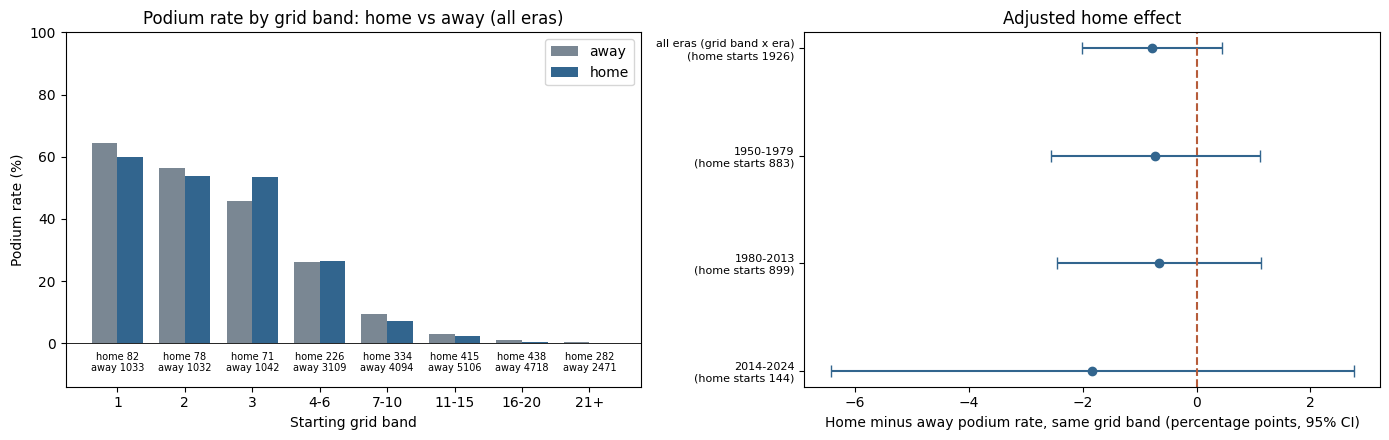

PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/q2_adjusted_home_effect.csv')

In [23]:
# Q2. Home-race podium association, controlling for starting position (and era).
GRID_BANDS = [(1,1,'1'), (2,2,'2'), (3,3,'3'), (4,6,'4-6'), (7,10,'7-10'), (11,15,'11-15'), (16,20,'16-20'), (21,99,'21+')]
ERAS = [(1950,1979,'1950-1979'), (1980,2013,'1980-2013'), (2014,2024,'2014-2024')]

def band(series, bands):
    out = pd.Series(pd.NA, index=series.index, dtype='string')
    for lo, hi, name in bands:
        out = out.mask(series.between(lo, hi), name)
    return out

q2 = q2_rows.copy()                                    # modeling cohort with home_race (Section 12d)
pit = q2.grid.eq(0)
print(f'Cohort rows: {len(q2):,}; pit-lane starts left out of the grid comparison: {int(pit.sum())}.')
q2 = q2[~pit].copy()
q2['grid_band'] = band(q2.grid, GRID_BANDS)
q2['era'] = band(q2.year, ERAS)
assert q2.grid_band.notna().all() and q2.era.notna().all() and q2.home_race.notna().all()
q2['home'] = q2.home_race.astype(bool)
q2['podium'] = q2.podium.astype(int)

# 1. Raw comparison (not adjusted)
# (named raw_rates, not raw: `raw` holds the 14 immutable source tables)
raw_rates = q2.groupby('home').podium.agg(starts='size', podiums='sum', rate='mean')
raw_rates['rate_pct'] = (100*raw_rates.rate).round(2)
print('Raw podium rate (no adjustment):'); display(raw_rates.drop(columns='rate').rename(index={True:'home', False:'away'}))
print('Share of home starts in each grid band (home drivers start further back or forward?):')
display((pd.crosstab(q2.grid_band, q2.home, normalize='columns')*100).round(1)
        .reindex([b[2] for b in GRID_BANDS]).rename(columns={True:'home %', False:'away %'}))

# 2. Strata = grid band x era
strata = (q2.groupby(['era','grid_band','home']).podium.agg(n='size', k='sum').unstack('home'))
strata.columns = [f'{a}_{"home" if h else "away"}' for a, h in strata.columns]
strata = strata.fillna(0).astype(int).reset_index()
strata['era'] = pd.Categorical(strata.era, [e[2] for e in ERAS], ordered=True)
strata['grid_band'] = pd.Categorical(strata.grid_band, [b[2] for b in GRID_BANDS], ordered=True)
strata = strata.sort_values(['era','grid_band']).reset_index(drop=True)
strata['usable'] = strata.n_home.gt(0) & strata.n_away.gt(0)
dropped_home = int(strata.loc[~strata.usable, 'n_home'].sum())
print(f'Strata: {len(strata)}; without both home and away starts: {int((~strata.usable).sum())} '
      f'({dropped_home} home starts cannot be compared and are left out of the adjusted estimates).')

def adjusted(s):
    s = s[s.usable]
    p_h = s.k_home/s.n_home; p_a = s.k_away/s.n_away; w = s.n_home
    rd = (w*(p_h-p_a)).sum()/w.sum()
    rd_se = np.sqrt((w**2*(p_h*(1-p_h)/s.n_home + p_a*(1-p_a)/s.n_away)).sum())/w.sum()
    a, b = s.k_home, s.n_home-s.k_home          # home: podium / no podium
    c, d = s.k_away, s.n_away-s.k_away          # away: podium / no podium
    n = s.n_home + s.n_away
    R, S = a*d/n, b*c/n
    P, Q = (a+d)/n, (b+c)/n
    or_mh = R.sum()/S.sum()
    var = ((P*R).sum()/(2*R.sum()**2) + (P*S+Q*R).sum()/(2*R.sum()*S.sum()) + (Q*S).sum()/(2*S.sum()**2))
    lo, hi = np.exp(np.log(or_mh) - 1.96*np.sqrt(var)), np.exp(np.log(or_mh) + 1.96*np.sqrt(var))
    return pd.Series({'home_starts': int(s.n_home.sum()), 'away_starts': int(s.n_away.sum()),
                      'adj_diff_pp': 100*rd, 'diff_ci_low_pp': 100*(rd-1.96*rd_se), 'diff_ci_high_pp': 100*(rd+1.96*rd_se),
                      'MH_odds_ratio': or_mh, 'OR_ci_low': lo, 'OR_ci_high': hi})

results = pd.DataFrame({'all eras (grid band x era)': adjusted(strata)}).T
for _, _, era in ERAS:
    results.loc[era] = adjusted(strata[strata.era == era])
results[['home_starts','away_starts']] = results[['home_starts','away_starts']].astype(int)
print('Home vs away, adjusted for grid band (and era): positive difference / odds ratio > 1 = home drivers podium more')
display(results.round(3))

# 3. Rates per grid band (all eras pooled, for the plot) and per stratum (for the record)
by_band = (q2.groupby(['grid_band','home']).podium.agg(n='size', rate='mean').unstack('home')
           .reindex([b[2] for b in GRID_BANDS]))
display((strata.assign(rate_home_pct=lambda d: (100*d.k_home/d.n_home.where(d.n_home>0)).round(1),
                       rate_away_pct=lambda d: (100*d.k_away/d.n_away.where(d.n_away>0)).round(1)))
        [['era','grid_band','n_home','rate_home_pct','n_away','rate_away_pct']])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(by_band)); wdt = 0.38
axes[0].bar(x-wdt/2, 100*by_band[('rate', False)], wdt, color='#7A8793', label='away')
axes[0].bar(x+wdt/2, 100*by_band[('rate', True)], wdt, color='#32658E', label='home')
for i, (nh, na) in enumerate(zip(by_band[('n', True)], by_band[('n', False)])):
    axes[0].text(i, -9, f'home {int(nh)}\naway {int(na)}', ha='center', fontsize=7)
axes[0].set_xticks(x); axes[0].set_xticklabels(by_band.index); axes[0].set_ylim(-14, 100)
axes[0].axhline(0, color='black', lw=0.6)
axes[0].set_xlabel('Starting grid band'); axes[0].set_ylabel('Podium rate (%)')
axes[0].set_title('Podium rate by grid band: home vs away (all eras)'); axes[0].legend()
r = results.iloc[::-1]
yy = np.arange(len(r))
axes[1].errorbar(r.adj_diff_pp, yy, xerr=[r.adj_diff_pp-r.diff_ci_low_pp, r.diff_ci_high_pp-r.adj_diff_pp],
                 fmt='o', color='#32658E', capsize=4)
axes[1].axvline(0, color='#B65C3A', ls='--')
axes[1].set_yticks(yy); axes[1].set_yticklabels([f'{i}\n(home starts {int(h)})' for i, h in zip(r.index, r.home_starts)], fontsize=8)
axes[1].set_xlabel('Home minus away podium rate, same grid band (percentage points, 95% CI)')
axes[1].set_title('Adjusted home effect')
figure('q2_home_advantage')

clean_export(strata, 'q2_strata_grid_band_era')
clean_export(results.reset_index().rename(columns={'index':'scope'}), 'q2_adjusted_home_effect')

In [24]:
# Q2 robustness: the same adjusted comparison with coarser and finer grid bands (backs the "Robustness" paragraph).
BAND_SETS = {
    'coarse (11+ merged)': [(1,1,'1'), (2,2,'2'), (3,3,'3'), (4,6,'4-6'), (7,10,'7-10'), (11,99,'11+')],
    'main (as above)': GRID_BANDS,
    'fine (single slots 1-10)': [(i, i, str(i)) for i in range(1, 11)] + [(11,15,'11-15'), (16,20,'16-20'), (21,99,'21+')]}
robust = {}
for name, bands in BAND_SETS.items():
    d = q2.assign(grid_band=band(q2.grid, bands))
    assert d.grid_band.notna().all()
    s = d.groupby(['era','grid_band','home']).podium.agg(n='size', k='sum').unstack('home')
    s.columns = [f'{a}_{"home" if h else "away"}' for a, h in s.columns]
    s = s.fillna(0).astype(int).reset_index()
    s['usable'] = s.n_home.gt(0) & s.n_away.gt(0)
    robust[name] = adjusted(s)
robust = pd.DataFrame(robust).T
display(robust.round(3))
clean_export(robust.reset_index().rename(columns={'index':'band_set'}), 'q2_robustness_grid_bands')


,home_starts,away_starts,adj_diff_pp,diff_ci_low_pp,diff_ci_high_pp,MH_odds_ratio,OR_ci_low,OR_ci_high
coarse (11+ merged),1926.0,22605.0,-0.887,-2.123,0.349,0.892,0.750,1.060
main (as above),1926.0,22605.0,-0.777,-2.010,0.455,0.903,0.759,1.073
fine (single slots 1-10),1926.0,22605.0,-0.713,-1.923,0.497,0.909,0.763,1.082


PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/q2_robustness_grid_bands.csv')

# Q2 Answer

Method. Driver–race grain; drivers who took the start, excluding the Indianapolis 500. Joins: results → drivers (nationality) and results → races → circuits (country), with an explicit nationality-to-country mapping (Section 12d; all 43 nationalities mapped; home decided by circuit country). Pit-lane starts (72) are left out because they have no comparable grid slot. Home and away starts are compared only within the same grid band (1, 2, 3, 4–6, 7–10, 11–15, 16–20, 21+) and the same era (1950–1979, 1980–2013, 2014–2024). Era is controlled because home races were far more common in early decades, when a given grid slot converted to a podium less often. The 24 groups are combined with a weighted difference in podium rate (weights = home starts) and a Mantel–Haenszel odds ratio, each with a 95% interval.

Answer. No: there is no evidence of a home advantage. Unadjusted, home drivers reach the podium less often (11.7% of 1,926 home starts vs 13.8% of 22,605 away starts), largely because they start further back (14.6% of home starts are from 21st or lower vs 10.9% of away starts). Comparing drivers from the same grid band and era, the home effect is −0.8 percentage points (95% CI −2.0 to +0.5), odds ratio 0.90 (95% CI 0.76–1.07). No era shows a significant effect (1950–1979: OR 0.91; 1980–2013: 0.92; 2014–2024: 0.79, each interval including 1). The data rule out a home advantage larger than about half a percentage point.

Robustness (table above). With a coarser last band (11+) the result is almost identical (−0.9 points; OR 0.89, 0.75–1.06). Finer bands move the estimate slightly towards zero, consistent with home drivers, often local one-off entries in early decades, starting at the very back.

Limitations. This is an association, not a causal effect. The modern era has only 144 home starts, so its estimate is very uncertain (OR 0.43–1.46). Rows from the same race are not independent (only three drivers can reach the podium), so the intervals are approximate. Differences between home and away drivers that the grid does not capture, such as car quality within a band, are not controlled.

**Grain · missingness · cutoff.** *Grain:* one row per (raceId, driverId), modeling cohort. *Missingness:* all 43 cohort nationalities are mapped (an unmapped value stops the notebook, so nothing silently becomes “away”); the 72 pit-lane starts are excluded from the grid-band comparison; every one of the 24 grid-band × era strata has both home and away starts. *Cutoff:* the home flag and grid position are known before the race; the podium is the outcome being described.


# Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?
A mechanical retirement is a race start that ended because a car component failed; crashes, driver errors and regulation decisions are excluded.


All constructors:


,starts,mechanical,rate_pct
era,,,
2014-2021,3255,297,9.12
2022-2024,1352,75,5.55



2014-2021: 17 constructors ranked (at least 40 starts), 2 shown but not ranked


,constructor_name,years,starts,mechanical,rate_pct,ci_pct,rank,ambiguous,rate_incl_ambiguous_pct,rank_incl_ambiguous,ranked
13,Lotus F1,2014-2015,75,13,17.3,10.4-27.4,1,5,24.0,1,True
3,Toro Rosso,2014-2019,242,39,16.1,12.0-21.3,2,5,18.2,2,True
0,McLaren,2014-2021,318,43,13.5,10.2-17.7,3,8,16.0,3,True
2,Renault,2016-2020,200,27,13.5,9.4-18.9,4,5,16.0,4,True
7,Sauber,2014-2018,200,22,11.0,7.4-16.1,5,5,13.5,5,True
5,Red Bull,2014-2021,319,34,10.7,7.7-14.5,6,4,11.9,7,True
16,Racing Point,2019-2020,76,7,9.2,4.5-17.8,7,1,10.5,8,True
17,AlphaTauri,2020-2021,77,7,9.1,4.5-17.6,8,1,10.4,9,True
15,Haas F1 Team,2016-2021,241,18,7.5,4.8-11.5,9,11,12.0,6,True
1,Williams,2014-2021,319,23,7.2,4.9-10.6,10,7,9.4,10,True



2022-2024: 12 constructors ranked (at least 40 starts), 0 shown but not ranked


,constructor_name,years,starts,mechanical,rate_pct,ci_pct,rank,ambiguous,rate_incl_ambiguous_pct,rank_incl_ambiguous,ranked
24,Alfa Romeo,2022-2023,88,11,12.5,7.1-21.0,1,0,12.5,1,True
29,Alpine F1 Team,2022-2024,136,15,11.0,6.8-17.4,2,0,11.0,2,True
28,AlphaTauri,2022-2023,88,6,6.8,3.2-14.1,3,1,8.0,5,True
20,Williams,2022-2024,134,7,5.2,2.6-10.4,4,4,8.2,4,True
21,Ferrari,2022-2024,135,7,5.2,2.5-10.3,5,3,7.4,6,True
27,Haas F1 Team,2022-2024,134,6,4.5,2.1-9.4,6,1,5.2,9,True
26,Mercedes,2022-2024,136,6,4.4,2.0-9.3,7,0,4.4,10,True
30,RB F1 Team,2024-2024,48,2,4.2,1.2-14.0,8,3,10.4,3,True
19,McLaren,2022-2024,136,5,3.7,1.6-8.3,9,0,3.7,12,True
22,Red Bull,2022-2024,136,5,3.7,1.6-8.3,9,1,4.4,10,True



Constructors ranked in both eras (same constructorId): 11


,constructorId,constructor_name,starts_2014_2021,rate_2014_2021_pct,starts_2022_2024,rate_2022_2024_pct,change_pp
5,51,Alfa Romeo,120,3.3,88,12.5,9.2
10,214,Alpine F1 Team,44,6.8,136,11.0,4.2
9,213,AlphaTauri,77,9.1,88,6.8,-2.3
1,3,Williams,319,7.2,134,5.2,-2.0
2,6,Ferrari,319,5.0,135,5.2,0.2
8,210,Haas F1 Team,241,7.5,134,4.5,-3.0
7,131,Mercedes,320,3.8,136,4.4,0.6
0,1,McLaren,318,13.5,136,3.7,-9.8
3,9,Red Bull,319,10.7,136,3.7,-7.0
6,117,Aston Martin,44,2.3,133,3.0,0.7


Ranked in only one era (new teams or renamed constructorIds): Force India, Lotus F1, Manor Marussia, RB F1 Team, Racing Point, Renault, Toro Rosso


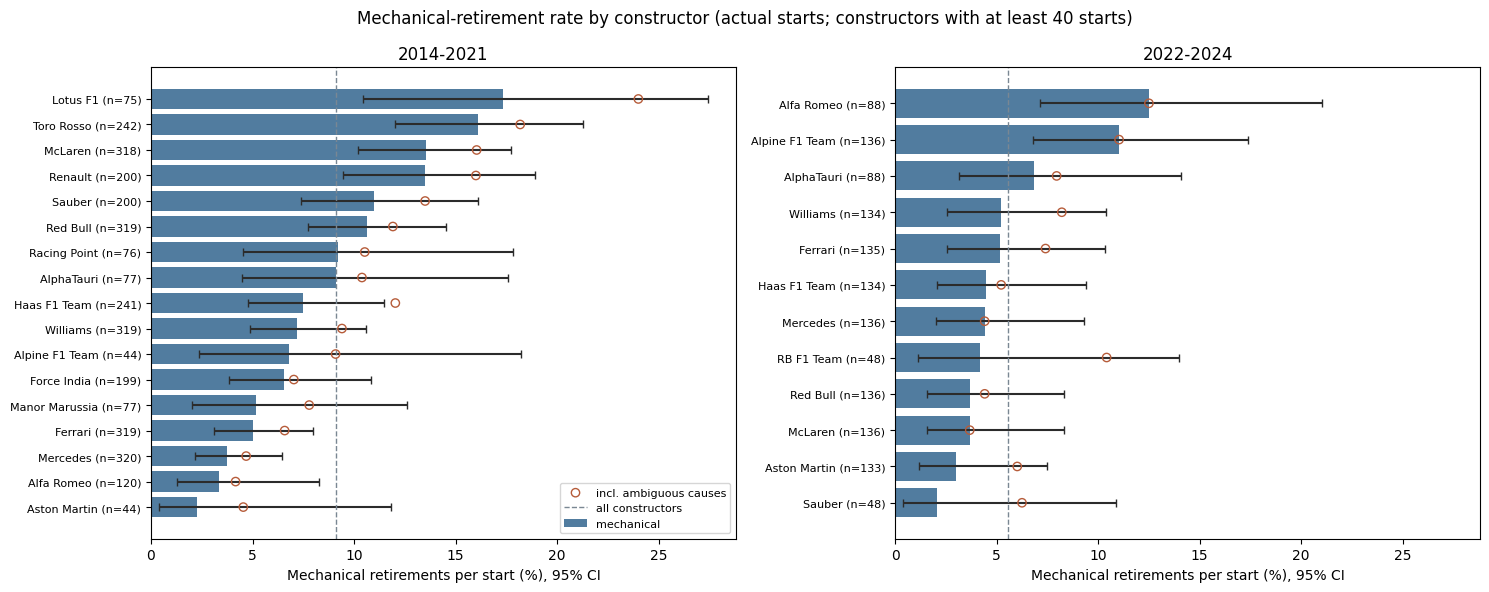

PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/q3_constructors_both_eras.csv')

In [25]:
# Q3. Mechanical-retirement rate per constructor, 2014-2021 vs 2022-2024.
# Joins: results (driver_race) -> races (year), -> constructors (identity), -> status (cause via the 12c mapping).
MIN_STARTS = 40          # ranking threshold per constructor and era (about one season with two cars)
Q3_ERAS = [(2014, 2021, '2014-2021'), (2022, 2024, '2022-2024')]

def wilson_ci(k, n, z=1.96):
    p = k / n
    centre = (p + z*z/(2*n)) / (1 + z*z/n)
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return centre - half, centre + half

q3 = q3_rows.copy()                                        # actual starts from 2014 (Section 12c)
assert q3.year.between(2014, 2024).all() and q3.status_cause.ne('unmapped').all()
assert not q3.duplicated(PAIR).any()
q3['era'] = np.where(q3.year.le(2021), '2014-2021', '2022-2024')

counts = (q3.groupby(['era','constructorId','constructor_name'])
          .agg(starts=('status_cause','size'),
               mechanical=('status_cause', lambda s: int(s.eq('mechanical').sum())),
               ambiguous=('status_cause', lambda s: int(s.eq('ambiguous').sum())),
               accident=('status_cause', lambda s: int(s.eq('accident/damage').sum())),
               finished=('status_cause', lambda s: int(s.eq('finished').sum())),
               first_year=('year','min'), last_year=('year','max'))
          .reset_index())
counts['rate'] = counts.mechanical / counts.starts
counts[['ci_low','ci_high']] = counts.apply(lambda r: pd.Series(wilson_ci(r.mechanical, r.starts)), axis=1)
counts['rate_incl_ambiguous'] = (counts.mechanical + counts.ambiguous) / counts.starts
counts['ranked'] = counts.starts.ge(MIN_STARTS)
for col, out in [('rate','rank'), ('rate_incl_ambiguous','rank_incl_ambiguous')]:
    counts[out] = counts[counts.ranked].groupby('era')[col].rank(ascending=False, method='min').astype('Int64')
assert counts.groupby('era').starts.sum().to_dict() == q3.groupby('era').size().to_dict()

def fmt(t):
    return t.assign(rate_pct=lambda d: (100*d.rate).round(1),
                    ci_pct=lambda d: (100*d.ci_low).round(1).astype(str)+'-'+(100*d.ci_high).round(1).astype(str),
                    rate_incl_ambiguous_pct=lambda d: (100*d.rate_incl_ambiguous).round(1),
                    years=lambda d: d.first_year.astype(str)+'-'+d.last_year.astype(str))

era_totals = q3.groupby('era').status_cause.agg(starts='size', mechanical=lambda s: int(s.eq('mechanical').sum()))
era_totals['rate_pct'] = (100*era_totals.mechanical/era_totals.starts).round(2)
print('All constructors:'); display(era_totals)

for _, _, era in Q3_ERAS:
    t = fmt(counts[counts.era.eq(era)]).sort_values(['ranked','rate'], ascending=[False, False])
    print(f'\n{era}: {int(t.ranked.sum())} constructors ranked (at least {MIN_STARTS} starts), '
          f'{int((~t.ranked).sum())} shown but not ranked')
    display(t[['constructor_name','years','starts','mechanical','rate_pct','ci_pct','rank',
               'ambiguous','rate_incl_ambiguous_pct','rank_incl_ambiguous','ranked']])

# Same constructorId ranked in both eras
w = counts[counts.ranked].pivot_table(index=['constructorId','constructor_name'], columns='era',
                                      values=['rate','starts','rank']).dropna()
both = pd.DataFrame({'starts_2014_2021': w[('starts','2014-2021')].astype(int),
                     'rate_2014_2021_pct': (100*w[('rate','2014-2021')]).round(1),
                     'starts_2022_2024': w[('starts','2022-2024')].astype(int),
                     'rate_2022_2024_pct': (100*w[('rate','2022-2024')]).round(1)}).reset_index()
both['change_pp'] = (both.rate_2022_2024_pct - both.rate_2014_2021_pct).round(1)
print(f'\nConstructors ranked in both eras (same constructorId): {len(both)}')
display(both.sort_values('rate_2022_2024_pct', ascending=False))
only = sorted(set(counts.loc[counts.ranked & counts.era.eq('2014-2021'),'constructor_name'])
              ^ set(counts.loc[counts.ranked & counts.era.eq('2022-2024'),'constructor_name']))
print('Ranked in only one era (new teams or renamed constructorIds):', ', '.join(only) if only else 'none')

# Plot: ranked constructors per era with 95% intervals; hollow marker = ambiguous counted as mechanical
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
for ax, (_, _, era) in zip(axes, Q3_ERAS):
    t = counts[counts.era.eq(era) & counts.ranked].sort_values('rate')
    y = np.arange(len(t))
    ax.barh(y, 100*t.rate, color='#32658E', alpha=0.85, label='mechanical')
    ax.errorbar(100*t.rate, y, xerr=[100*(t.rate-t.ci_low), 100*(t.ci_high-t.rate)], fmt='none', ecolor='#2B2B2B', capsize=3)
    ax.scatter(100*t.rate_incl_ambiguous, y, facecolors='none', edgecolors='#B65C3A', zorder=3,
               label='incl. ambiguous causes')
    ax.set_yticks(y); ax.set_yticklabels([f'{n} (n={s})' for n, s in zip(t.constructor_name, t.starts)], fontsize=8)
    ax.axvline(100*era_totals.loc[era,'mechanical']/era_totals.loc[era,'starts'], color='#7A8793', ls='--', lw=1,
               label='all constructors')
    ax.set_title(f'{era}'); ax.set_xlabel('Mechanical retirements per start (%), 95% CI')
axes[0].legend(fontsize=8, loc='lower right')
fig.suptitle('Mechanical-retirement rate by constructor (actual starts; constructors with at least '
             f'{MIN_STARTS} starts)')
figure('q3_mechanical_retirements')

clean_export(counts, 'q3_mechanical_rate_by_constructor_era')
clean_export(both, 'q3_constructors_both_eras')

# Q3 Answer


Method. Grain: one driver’s start in one race. Denominator: actual starts only (modeling cohort, Section 12b), because a mechanical retirement is defined as a race start that ended early through a component failure. Joins: results → races (season), → constructors (identity, followed by constructorId), → status (cause via the documented status-to-cause mapping, Section 12c). Crash-, driver- and regulation-caused endings are excluded and lapped finishes count as finishes. Rate = mechanical retirements ÷ starts per constructor and era, with 95% Wilson intervals; constructors need ≥ 40 starts (about one season with two cars) to be ranked. The 88 retirements with an ambiguous cause (Retired, Puncture, Wheel, …) are excluded from the main rate and tested as a sensitivity.

Answer. Overall, mechanical retirements fell from 9.1% of starts (2014–2021) to 5.6% (2022–2024). 2014–2021: the highest rates were Lotus F1 (17.3%, 75 starts), Toro Rosso (16.1%), McLaren (13.5%) and Renault (13.5%); the lowest were Aston Martin (2.3%, only 44 starts), Alfa Romeo (3.3%, 120 starts), Mercedes (3.8%, 320 starts) and Ferrari (5.0%, 319 starts); the Mercedes and Ferrari intervals do not overlap with Toro Rosso’s or McLaren’s. 2022–2024: the highest were Alfa Romeo (12.5%, 88 starts) and Alpine (11.0%, 136 starts), clearly above the next team (AlphaTauri 6.8%); the lowest were Sauber (2.1%, 48 starts), Aston Martin (3.0%), McLaren and Red Bull (3.7%). Counting ambiguous causes as mechanical leaves the top five of 2014–2021 and the top two of 2022–2024 unchanged.

Change between eras. McLaren improved most (13.5% → 3.7%), followed by Red Bull (10.7% → 3.7%); Alfa Romeo worsened (3.3% → 12.5%); Mercedes and Ferrari stayed low (≈ 4–5%).

Limitations. Constructor identity follows constructorId, so renamed teams start a new history; read by team lineage, the Enstone team (Lotus F1 → Renault → Alpine) is among the highest in both eras. Caterham (2014; 23.5% from 34 starts) and Marussia (2014) are below the ranking threshold. 2022–2024 rates rest on 88–136 starts per team, so the intervals of the top two overlap with several mid-field teams. The status text is the only record of cause; 88 retirements could not be classified.

**Grain · missingness · cutoff.** *Grain:* one row per driver start (raceId, driverId), 2014–2024; denominator = actual starts. *Missingness:* every status from 2014 onward is mapped (an unmapped status stops the notebook); the 88 ambiguous causes are reported separately and tested as a sensitivity. *Cutoff:* status is post-race information. It is used only to answer this question and is never a model input.


# Feature Engineering Part

## FE 1. Model table and grid / qualifying features

Rows excluded as anomalous race(s): 6


,rows,races,podium_pct,first,last
split,,,,,
train,6791,320,14.14,2003,2019
validation,778,39,15.04,2020,2021
test,1352,68,15.09,2022,2024


Missing qualifying values per split (left missing here; imputed later on training data only):


,quali_position,q1_gap_pct,q1_gap_to_teammate_pct,grid_minus_quali
split,,,,
train,21,123,241,21
validation,1,9,18,1
test,0,13,25,0


,count,mean,std,min,25%,50%,75%,max
grid_position,8921.0,11.036431,6.151881,1.0,6.0,11.0,16.0,24.0
grid_relative,8921.0,0.525741,0.290195,0.041667,0.272727,0.529412,0.772727,1.117647
field_size,8921.0,21.001569,1.548831,15.0,20.0,20.0,22.0,24.0
quali_position,8899.0,10.995168,6.117957,1.0,6.0,11.0,16.0,24.0
q1_gap_pct,8776.0,1.639274,1.767171,0.0,0.663869,1.222949,2.012465,44.782055
q1_gap_to_teammate_pct,8637.0,0.008185,1.275751,-29.971208,-0.366698,0.0,0.367272,42.798409
grid_minus_quali,8899.0,0.015283,1.657988,-8.0,0.0,0.0,0.0,23.0


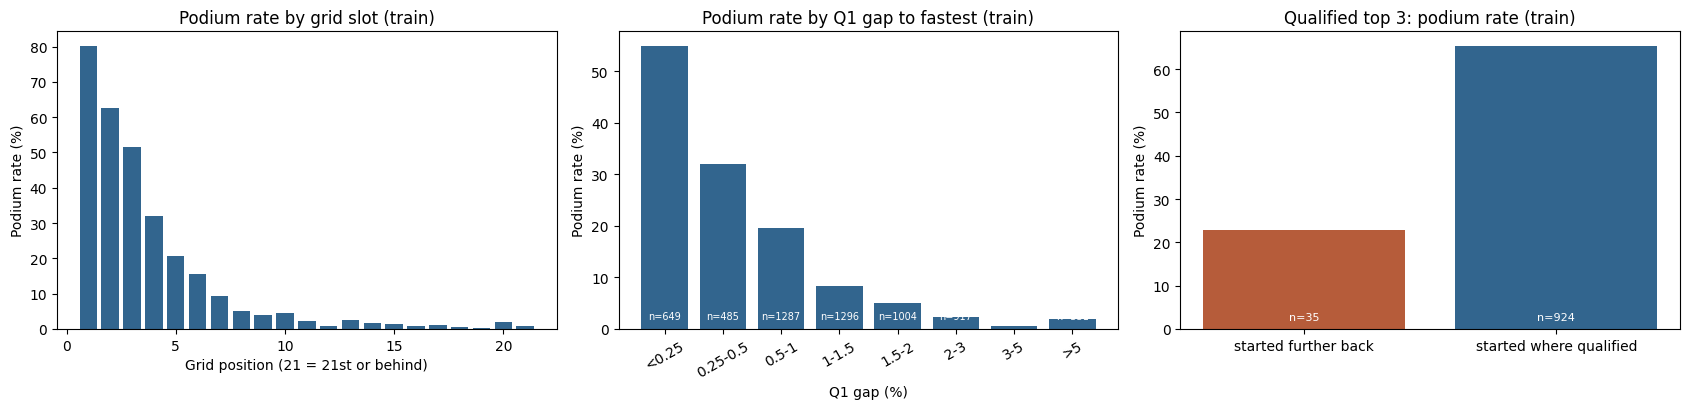

Spearman correlation with podium (train; negative = smaller value, more podiums):


,spearman_with_podium
grid_position,-0.495
grid_relative,-0.493
pit_lane_start,-0.021
quali_position,-0.497
q1_gap_pct,-0.402
q1_gap_to_teammate_pct,-0.072
grid_minus_quali,0.085


,feature,group,source,pre_race_reason
0,grid_position,grid,results.grid,starting slot after penalties; pit-lane starts...
1,grid_relative,grid,results.grid,grid position / number of starters
2,pit_lane_start,grid,results.grid,start from the pit lane is decided before the ...
3,field_size,grid,results.grid,number of cars on the grid
4,quali_position,qualifying,qualifying (+ results.grid),"qualifying rank, known after qualifying"
5,q1_gap_pct,qualifying,qualifying (+ results.grid),% slower than the fastest Q1 lap of the race (...
6,q1_gap_to_teammate_pct,qualifying,qualifying (+ results.grid),% slower than the teammate in Q1 (driver vs sa...
7,grid_minus_quali,qualifying,qualifying (+ results.grid),places lost (penalty) or gained between qualif...


PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/feature_register_grid_qualifying.csv')

In [26]:
# FE 1. Model table (rows + label only) and grid / qualifying features.
MODEL_START_YEAR = 2003              # team decision: complete qualifying coverage from 2003
KEY = ['raceId','driverId']

# ---- 1. Model table: cohort rows from MODEL_START_YEAR, keys/context/label only (no post-race columns) ----
# Documented anomaly: 2005 United States GP. 14 of 20 cars withdrew after the formation lap over tyre safety,
# so only 6 cars started from slots up to 20th and every starter had a 50% podium chance.
ANOMALOUS_RACES = {(2005, 'United States Grand Prix'): 'only 6 of 20 cars started (tyre-safety withdrawal); '
                                                       'grid slots and podium odds not comparable with any other race'}
anomaly = pd.Series(False, index=analysis_base.index)
for (yr, name), why in ANOMALOUS_RACES.items():
    hit = analysis_base.year.eq(yr) & analysis_base.race_name.eq(name)
    assert hit.any(), f'anomalous race not found: {yr} {name}'
    anomaly |= hit
eligible = analysis_base.in_modeling_cohort & analysis_base.year.ge(MODEL_START_YEAR)
print(f'Rows excluded as anomalous race(s): {int((eligible & anomaly).sum())}')
clean_export(analysis_base.loc[eligible & anomaly, KEY + ['year','race_name','driver_surname','grid','podium']]
             .assign(reason=lambda d: [ANOMALOUS_RACES[(y, n)] for y, n in zip(d.year, d.race_name)]),
             'model_table_anomalous_race_exclusions')

base_cols = KEY + ['constructorId','year','race_round','race_date','circuitId','split','grid','home_race','podium']
model_table = (analysis_base.loc[eligible & ~anomaly, base_cols]
               .rename(columns={'race_round':'round','race_date':'date'})
               .sort_values(['date','round','raceId','driverId']).reset_index(drop=True))
model_table['podium'] = model_table.podium.astype('int8')
assert not model_table.duplicated(KEY).any()
for name, (lo, hi) in SPLITS.items():                        # split must agree with the season
    assert model_table.loc[model_table.split.eq(name), 'year'].between(lo, hi).all()
assert model_table.groupby('split').podium.nunique().eq(2).all(), 'each split needs both classes'
display(model_table.groupby('split').agg(rows=('podium','size'), races=('raceId','nunique'),
        podium_pct=('podium', lambda s: round(100*s.mean(), 2)), first=('year','min'), last=('year','max'))
        .reindex(list(SPLITS)))

FEATURE_REGISTER = []                                         # every feature: group, source, why it is pre-race
def register(name, group, source, pre_race):
    FEATURE_REGISTER.append(dict(feature=name, group=group, source=source, pre_race_reason=pre_race))

# ---- 2. Grid features (grid is fixed before the start; no new join) ----
model_table['field_size'] = model_table.groupby('raceId').driverId.transform('size').astype('int16')
model_table['pit_lane_start'] = model_table.grid.eq(0).astype('int8')
model_table['grid_position'] = model_table.grid.where(model_table.grid.gt(0), model_table.field_size + 1).astype('int16')
model_table['grid_relative'] = model_table.grid_position / model_table.field_size
model_table = model_table.drop(columns='grid')
for f, why in [('grid_position', 'starting slot after penalties; pit-lane starts placed behind the field'),
               ('grid_relative', 'grid position / number of starters'),
               ('pit_lane_start', 'start from the pit lane is decided before the start'),
               ('field_size', 'number of cars on the grid')]:
    register(f, 'grid', 'results.grid', why)

# ---- 3. Qualifying features (new join: qualifying, one row per driver-race) ----
q = clean['qualifying'][KEY + ['constructorId','position','q1_seconds']].rename(
        columns={'constructorId':'q_constructorId','position':'quali_position'})
assert not q.duplicated(KEY).any()
q['q1_gap_pct'] = 100*(q.q1_seconds / q.groupby('raceId').q1_seconds.transform('min') - 1)
team = q.groupby(['raceId','q_constructorId']).q1_seconds
n_team, sum_team = team.transform('count'), team.transform('sum')
teammate_q1 = (sum_team - q.q1_seconds).where(n_team.eq(2) & q.q1_seconds.notna())
q['q1_gap_to_teammate_pct'] = 100*(q.q1_seconds / teammate_q1 - 1)

before = len(model_table)
model_table = model_table.merge(q[KEY + ['quali_position','q1_gap_pct','q1_gap_to_teammate_pct']],
                                on=KEY, how='left', validate='one_to_one')
assert len(model_table) == before and not model_table.duplicated(KEY).any()
model_table['quali_position'] = model_table.quali_position.astype('Int16')
model_table['grid_minus_quali'] = (model_table.grid_position - model_table.quali_position).astype('Int16')
for f, why in [('quali_position', 'qualifying rank, known after qualifying'),
               ('q1_gap_pct', '% slower than the fastest Q1 lap of the race (every driver runs Q1)'),
               ('q1_gap_to_teammate_pct', '% slower than the teammate in Q1 (driver vs same car)'),
               ('grid_minus_quali', 'places lost (penalty) or gained between qualifying and the grid')]:
    register(f, 'qualifying', 'qualifying (+ results.grid)', why)

# Checks: gap is 0 for the fastest Q1 lap of each race, never negative
assert model_table.q1_gap_pct.dropna().ge(-1e-9).all()
assert model_table.field_size.ge(15).all(), 'unexpected small field: check for another anomalous race'
qual_cols = ['quali_position','q1_gap_pct','q1_gap_to_teammate_pct','grid_minus_quali']
print('Missing qualifying values per split (left missing here; imputed later on training data only):')
display(model_table.groupby('split')[qual_cols].apply(lambda d: d.isna().sum()).reindex(list(SPLITS)))
display(model_table[['grid_position','grid_relative','field_size','quali_position','q1_gap_pct',
                     'q1_gap_to_teammate_pct','grid_minus_quali']].describe().T.round(2))

# ---- 4. Evidence from TRAINING rows only ----
tr = model_table[model_table.split.eq('train')]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
g = tr.assign(slot=tr.grid_position.clip(upper=21)).groupby('slot').podium.agg(['mean','size'])
axes[0].bar(g.index, 100*g['mean'], color='#32658E')
axes[0].set(title='Podium rate by grid slot (train)', xlabel='Grid position (21 = 21st or behind)', ylabel='Podium rate (%)')
bins = [-0.001, 0.25, 0.5, 1, 1.5, 2, 3, 5, np.inf]
labels = ['<0.25','0.25-0.5','0.5-1','1-1.5','1.5-2','2-3','3-5','>5']
gb = (tr.assign(band=pd.cut(tr.q1_gap_pct, bins, labels=labels)).groupby('band', observed=False).podium.agg(['mean','size']))
axes[1].bar(gb.index.astype(str), 100*gb['mean'], color='#32658E')
for i, n in enumerate(gb['size']): axes[1].text(i, 2, f'n={n}', ha='center', fontsize=7, color='white')
axes[1].set(title='Podium rate by Q1 gap to fastest (train)', xlabel='Q1 gap (%)', ylabel='Podium rate (%)')
axes[1].tick_params(axis='x', rotation=30)
top = tr[tr.quali_position.le(3)]
pen = top.assign(penalised=np.where(top.grid_minus_quali.gt(0), 'started further back', 'started where qualified'))
gp = pen.groupby('penalised').podium.agg(['mean','size'])
axes[2].bar(gp.index, 100*gp['mean'], color=['#B65C3A','#32658E'])
for i, n in enumerate(gp['size']): axes[2].text(i, 2, f'n={n}', ha='center', fontsize=8, color='white')
axes[2].set(title='Qualified top 3: podium rate (train)', ylabel='Podium rate (%)')
figure('fe_grid_qualifying_evidence')

corr = tr[['grid_position','grid_relative','pit_lane_start','quali_position','q1_gap_pct',
           'q1_gap_to_teammate_pct','grid_minus_quali','podium']].astype(float).corr(method='spearman')['podium'].drop('podium')
print('Spearman correlation with podium (train; negative = smaller value, more podiums):')
display(corr.round(3).to_frame('spearman_with_podium'))

feature_register = pd.DataFrame(FEATURE_REGISTER)
display(feature_register)
clean_export(feature_register, 'feature_register_grid_qualifying')

Grid and qualifying features: evidence (training data, 2003–2019). Starting and qualifying position are the strongest single indicators of a podium (Spearman −0.50 for both); the podium rate falls steeply from the front row towards the back (plot 1). The Q1 gap to the fastest lap is also strongly linked (−0.40) and adds how close a driver was, which position alone does not show (plot 2). The teammate gap is weak on its own (−0.07) because it compares drivers in the same car; it is kept to be tested together with constructor-strength features in the ablation. Grid minus qualifying is slightly positive (+0.09) because grid penalties mostly affect front-running cars that still reach the podium from further back (plot 3); this reflects who receives penalties, not a causal effect. Pit-lane starts are too rare (≈72 rows) to show a clear link on their own. Grid position, relative grid and qualifying position are highly correlated; their separate contribution is measured in the feature-group ablation. One race, the 2005 United States Grand Prix, was excluded: only 6 of 20 cars started after a tyre-safety withdrawal, making its grid positions and podium odds incomparable with any other race (6 training rows). **Note on `field_size`:** it counts the drivers who took the start (the cohort). At prediction time this equals the cars on the grid, except for rare withdrawals between the grid being set and the start, which the cohort also excludes (documented limitation in Section 12b).


In [ ]:
# Check: does the Q1 time mean the same thing in every training season?
# If Q1 was the deciding lap, ranking drivers by Q1 time reproduces the qualifying order exactly (Spearman = 1).
qq = clean['qualifying'][['raceId', 'driverId', 'position', 'q1_seconds']].merge(
        clean['races'][['raceId', 'year']], on='raceId', how='left', validate='many_to_one')
qq = qq[qq.year.between(2003, 2010)].astype({'position': float, 'q1_seconds': float})
qq['q1_rank'] = qq.groupby('raceId').q1_seconds.rank(method='min')
q1_meaning = qq.groupby('year')[['q1_rank', 'position']].apply(
    lambda d: d.corr(method='spearman').iloc[0, 1]).round(3).rename('spearman_q1_rank_vs_qualifying_position')
display(q1_meaning.to_frame())

,spearman_q1_rank_vs_qualifying_position
year,
2003,1.000
2004,1.000
2005,0.965
2006,0.846
2007,0.891
2008,0.856
2009,0.830
2010,0.911


**What Q1 means by season.** In 2003–2004 ranking drivers by their Q1 time gives exactly the final qualifying order (Spearman 1.00): qualifying was a single timed lap, run on race fuel, so `q1_gap_pct` is the gap on the deciding lap and partly reflects fuel strategy. From 2006 Q1 is the first low-fuel knockout round and the correlation drops (later rounds decide the order). The feature is kept because it is pre-race in every season and strongly linked to podiums (Spearman −0.40 in training), but its meaning shifts slightly inside the training seasons; this is listed as limitation 12.

## FE 2. Driver and constructor form (earlier races only)

Leakage test 1: altered race 57 for driver 18; features on or before that race unchanged; later rows that changed: 13
Leakage test 2: altered race 62 for driver 18; features on or before that race unchanged; later rows that changed: 10
Leakage test 3: altered race 860 for driver 17; features on or before that race unchanged; later rows that changed: 10
Rows with a full 5-race history (%):


,driver_form_races,constructor_form_races
split,,
train,94.6,97.4
validation,97.0,97.4
test,97.5,99.3


,count,mean,std,min,25%,50%,75%,max
driver_podium_rate_last5,8832.0,0.145,0.256,0.000,0.000,0.000,0.200,1.000
driver_avg_finish_rel_last5,8832.0,0.521,0.209,0.045,0.360,0.542,0.690,1.000
driver_finish_rate_last5,8832.0,0.795,0.204,0.000,0.600,0.800,1.000,1.000
driver_form_races,8921.0,4.855,0.717,0.000,5.000,5.000,5.000,5.000
driver_experience,8921.0,4.142,1.214,0.000,3.466,4.419,5.075,5.996
constructor_podium_rate_last5,8880.0,0.144,0.231,0.000,0.000,0.000,0.200,1.000
constructor_best_finish_rel_last5,8880.0,0.405,0.212,0.045,0.220,0.410,0.570,0.880
constructor_finish_rate_last5,8880.0,0.794,0.161,0.000,0.700,0.800,0.900,1.000
constructor_form_races,8921.0,4.930,0.501,0.000,5.000,5.000,5.000,5.000


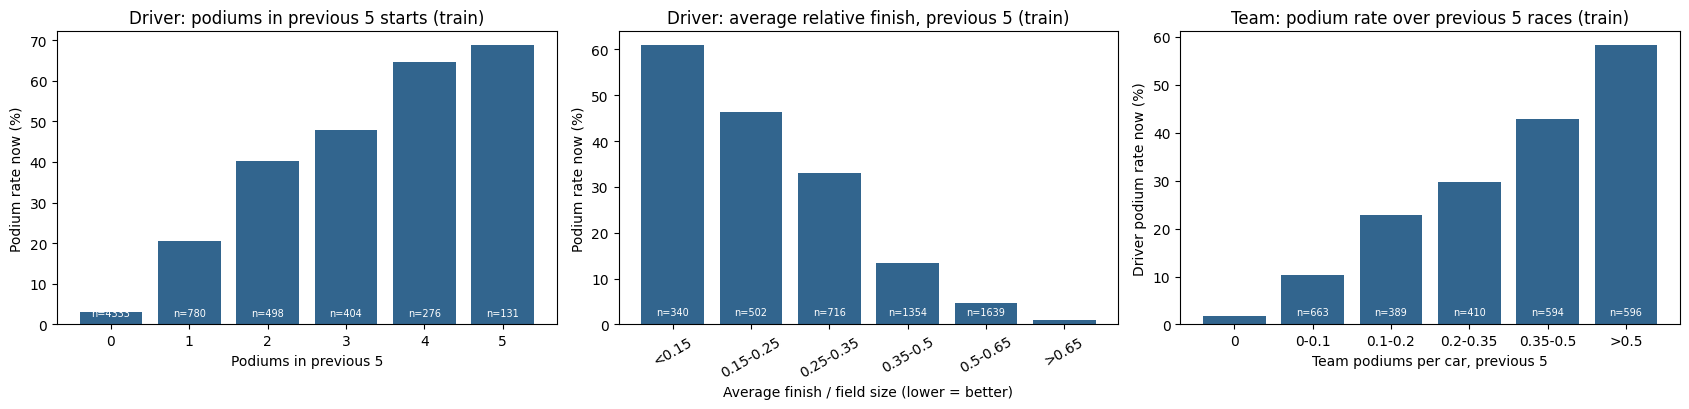

Spearman correlation with podium (train):


,spearman_with_podium
driver_podium_rate_last5,0.528
driver_avg_finish_rel_last5,-0.442
driver_finish_rate_last5,0.162
driver_form_races,0.084
driver_experience,0.229
constructor_podium_rate_last5,0.516
constructor_best_finish_rel_last5,-0.468
constructor_finish_rate_last5,0.199
constructor_form_races,0.040


,feature,group,source,pre_race_reason
0,grid_position,grid,results.grid,starting slot after penalties; pit-lane starts...
1,grid_relative,grid,results.grid,grid position / number of starters
2,pit_lane_start,grid,results.grid,start from the pit lane is decided before the ...
3,field_size,grid,results.grid,number of cars on the grid
4,quali_position,qualifying,qualifying (+ results.grid),"qualifying rank, known after qualifying"
5,q1_gap_pct,qualifying,qualifying (+ results.grid),% slower than the fastest Q1 lap of the race (...
6,q1_gap_to_teammate_pct,qualifying,qualifying (+ results.grid),% slower than the teammate in Q1 (driver vs sa...
7,grid_minus_quali,qualifying,qualifying (+ results.grid),places lost (penalty) or gained between qualif...
8,driver_podium_rate_last5,driver_form,results of earlier races,share of the driver's previous 5 starts that e...
9,driver_avg_finish_rel_last5,driver_form,results of earlier races,average finishing position / field size over t...


PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/feature_register.csv')

In [27]:
# FE 2. Driver and constructor form from EARLIER races only.
FORM_WINDOW = 5

# ---- 1. History: every cohort race (all years, so 2003 rows can look back), minus the documented anomalies ----
hist_mask = analysis_base.in_modeling_cohort.copy()
for (yr, name) in ANOMALOUS_RACES:
    hist_mask &= ~(analysis_base.year.eq(yr) & analysis_base.race_name.eq(name))
history = (analysis_base.loc[hist_mask, KEY + ['constructorId','race_date','race_round','positionOrder','finish_status','podium']]
           .rename(columns={'race_date':'date','race_round':'round'}).copy())
history['field_size'] = history.groupby('raceId').driverId.transform('size')
history['finish_rel'] = history.positionOrder / history.field_size          # 1/20 = 0.05 ... 20/20 = 1.0
history['finished'] = history.finish_status.astype(bool).astype(int)
history['podium'] = history.podium.astype(int)
assert not history.duplicated(KEY).any()
assert history.groupby('raceId').date.nunique().eq(1).all(), 'a race must have one date'

def rolling_previous(series_by_group, window):
    """Mean of the previous `window` values within each group: shift(1) excludes the current race."""
    return series_by_group.transform(lambda s: s.shift(1).rolling(window, min_periods=1).mean())

def driver_form(hist, window):
    h = hist.sort_values(['driverId','date','round','raceId']).copy()
    prev_date = h.groupby('driverId').date.shift(1)
    assert (prev_date.isna() | (prev_date < h.date)).all(), 'driver races must be in strict date order'
    g = h.groupby('driverId')
    out = h[KEY].copy()
    out[f'driver_podium_rate_last{window}'] = rolling_previous(g.podium, window)
    out[f'driver_avg_finish_rel_last{window}'] = rolling_previous(g.finish_rel, window)
    out[f'driver_finish_rate_last{window}'] = rolling_previous(g.finished, window)
    starts_before = g.cumcount()
    out['driver_form_races'] = starts_before.clip(upper=window).astype('int8')
    out['driver_experience'] = np.log1p(starts_before)
    return out

def constructor_form(hist, window):
    # Aggregate each team's cars per race FIRST, then shift: a teammate's current result can never leak.
    team = (hist.groupby(['constructorId','raceId'], as_index=False)
                .agg(date=('date','first'), round=('round','first'), cars=('driverId','size'),
                     podiums=('podium','sum'), finished=('finished','sum'), best_finish_rel=('finish_rel','min'))
                .sort_values(['constructorId','date','round','raceId']))
    prev_date = team.groupby('constructorId').date.shift(1)
    assert (prev_date.isna() | (prev_date < team.date)).all(), 'team races must be in strict date order'
    g = team.groupby('constructorId')
    prev_sum = lambda col: g[col].transform(lambda s: s.shift(1).rolling(window, min_periods=1).sum())
    out = team[['constructorId','raceId']].copy()
    out[f'constructor_podium_rate_last{window}'] = prev_sum('podiums') / prev_sum('cars')
    out[f'constructor_finish_rate_last{window}'] = prev_sum('finished') / prev_sum('cars')
    out[f'constructor_best_finish_rel_last{window}'] = rolling_previous(g.best_finish_rel, window)
    out['constructor_form_races'] = g.cumcount().clip(upper=window).astype('int8')
    return out

def add_form(table, hist, window):
    d, c = driver_form(hist, window), constructor_form(hist, window)
    new_cols = [x for x in list(d.columns) + list(c.columns) if x not in KEY + ['constructorId']]
    t = table.drop(columns=[x for x in new_cols if x in table.columns])
    n = len(t)
    t = t.merge(d, on=KEY, how='left', validate='one_to_one')
    t = t.merge(c, on=['constructorId','raceId'], how='left', validate='many_to_one')
    assert len(t) == n and not t.duplicated(KEY).any()
    return t

model_table = add_form(model_table, history, FORM_WINDOW)
W = FORM_WINDOW
driver_cols = [f'driver_podium_rate_last{W}', f'driver_avg_finish_rel_last{W}', f'driver_finish_rate_last{W}',
               'driver_form_races', 'driver_experience']
team_cols = [f'constructor_podium_rate_last{W}', f'constructor_best_finish_rel_last{W}',
             f'constructor_finish_rate_last{W}', 'constructor_form_races']
assert model_table[driver_cols + team_cols].notna().any().all()

# ---- 2. Checks ----
# (a) every model row found its history row (form_races is never missing)
assert model_table.driver_form_races.notna().all() and model_table.constructor_form_races.notna().all()
# (b) no history means empty rates, and rates stay in [0, 1]
for rate, count in [(driver_cols[0], 'driver_form_races'), (team_cols[0], 'constructor_form_races')]:
    assert model_table[rate].isna().equals(model_table[count].eq(0))
    assert model_table[rate].dropna().between(0, 1).all()
# (c) teammates in the same race share identical team values
assert model_table.groupby(['raceId','constructorId'])[team_cols].nunique(dropna=False).le(1).all().all()
# (d) leakage test: change one race's result in a copy; features for that race and all earlier races must not move
def leakage_test(hist, table, window, seed=0):
    rng = np.random.default_rng(seed)
    probe = table.sample(1, random_state=seed).iloc[0]
    d_hist = hist[hist.driverId.eq(probe.driverId)].sort_values(['date','round'])
    race_date = d_hist.loc[d_hist.raceId.eq(probe.raceId), 'date'].iloc[0]
    altered = hist.copy()
    sel = altered.raceId.eq(probe.raceId) & altered.driverId.eq(probe.driverId)
    altered.loc[sel, 'podium'] = 1 - altered.loc[sel, 'podium']
    altered.loc[sel, 'finished'] = 1 - altered.loc[sel, 'finished']
    altered.loc[sel, 'finish_rel'] = 1.0 - altered.loc[sel, 'finish_rel'] + 0.01
    a, b = add_form(table, hist, window), add_form(table, altered, window)
    cols = [c for c in a.columns if 'last' in c or c.endswith('_races') or c == 'driver_experience']
    not_later = a.date.le(race_date)                     # the altered race itself and everything before it
    pd.testing.assert_frame_equal(a.loc[not_later, cols], b.loc[not_later, cols])
    changed_later = (a.loc[~not_later, cols].fillna(-9) != b.loc[~not_later, cols].fillna(-9)).any(axis=1).sum()
    return probe, int(changed_later)
for s in range(3):
    probe, changed = leakage_test(history, model_table, FORM_WINDOW, seed=s)
    print(f'Leakage test {s+1}: altered race {int(probe.raceId)} for driver {int(probe.driverId)}; '
          f'features on or before that race unchanged; later rows that changed: {changed}')

for f, why in [(driver_cols[0], 'share of the driver\'s previous 5 starts that ended on the podium'),
               (driver_cols[1], 'average finishing position / field size over the previous 5 starts'),
               (driver_cols[2], 'share of the previous 5 starts that were finished'),
               ('driver_form_races', 'number of earlier starts the driver rates rest on (0-5)'),
               ('driver_experience', 'log(1 + number of earlier starts)')]:
    register(f, 'driver_form', 'results of earlier races', why)
for f, why in [(team_cols[0], 'team podiums / team cars over the team\'s previous 5 races'),
               (team_cols[1], 'average of the team\'s best relative finish over the previous 5 races'),
               (team_cols[2], 'share of team cars that finished over the previous 5 races'),
               ('constructor_form_races', 'number of earlier team races the team rates rest on (0-5)')]:
    register(f, 'constructor_form', 'results of earlier races, aggregated per team first', why)

# ---- 3. Coverage and evidence (TRAINING rows only) ----
print('Rows with a full 5-race history (%):')
display((model_table.groupby('split')[['driver_form_races','constructor_form_races']]
         .agg(lambda s: round(100*s.eq(W).mean(), 1))).reindex(list(SPLITS)))
display(model_table[driver_cols + team_cols].describe().T.round(3))

tr = model_table[model_table.split.eq('train')]
full = tr[tr.driver_form_races.eq(W)]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
k = (full[driver_cols[0]]*W).round().astype(int)
g = full.groupby(k).podium.agg(['mean','size']).reindex(range(W+1))
axes[0].bar(g.index, 100*g['mean'], color='#32658E')
for i, n in zip(g.index, g['size'].fillna(0).astype(int)): axes[0].text(i, 2, f'n={n}', ha='center', fontsize=7, color='white')
axes[0].set(title='Driver: podiums in previous 5 starts (train)', xlabel='Podiums in previous 5', ylabel='Podium rate now (%)')
bins = [0, .15, .25, .35, .5, .65, 1.01]; lab = ['<0.15','0.15-0.25','0.25-0.35','0.35-0.5','0.5-0.65','>0.65']
g = full.groupby(pd.cut(full[driver_cols[1]], bins, labels=lab), observed=False).podium.agg(['mean','size'])
axes[1].bar(g.index.astype(str), 100*g['mean'], color='#32658E')
for i, n in enumerate(g['size']): axes[1].text(i, 2, f'n={n}', ha='center', fontsize=7, color='white')
axes[1].set(title='Driver: average relative finish, previous 5 (train)', xlabel='Average finish / field size (lower = better)',
            ylabel='Podium rate now (%)'); axes[1].tick_params(axis='x', rotation=30)
tf = tr[tr.constructor_form_races.eq(W)]
cb = pd.cut(tf[team_cols[0]], [-0.001, 0, .1, .2, .35, .5, 1.0], labels=['0','0-0.1','0.1-0.2','0.2-0.35','0.35-0.5','>0.5'])
g = tf.groupby(cb, observed=False).podium.agg(['mean','size'])
axes[2].bar(g.index.astype(str), 100*g['mean'], color='#32658E')
for i, n in enumerate(g['size']): axes[2].text(i, 2, f'n={n}', ha='center', fontsize=7, color='white')
axes[2].set(title='Team: podium rate over previous 5 races (train)', xlabel='Team podiums per car, previous 5',
            ylabel='Driver podium rate now (%)')
figure('fe_form_evidence')

corr = tr[driver_cols + team_cols + ['podium']].astype(float).corr(method='spearman')['podium'].drop('podium')
print('Spearman correlation with podium (train):')
display(corr.round(3).to_frame('spearman_with_podium'))
feature_register = pd.DataFrame(FEATURE_REGISTER).drop_duplicates('feature', keep='last')
display(feature_register)
clean_export(feature_register, 'feature_register')

Driver and constructor form: evidence (training data, 2003–2019). Form uses only races before the current one. History reaches back before 2003, so 95–99% of rows in every split have a full five-race history; a driver’s first race (89 rows) or a new team’s first race (41 rows) has no form value and a history count of 0. A perturbation test confirms that changing one race’s result changes only features of later races. Recent podium rate is the strongest single indicator so far, for the driver (Spearman +0.53) and the constructor (+0.52), comparable to grid position (−0.50); average relative finish separates drivers and teams who rarely reach the podium (−0.44 driver, −0.47 constructor best car). Finish rates (+0.16, +0.20) and experience (+0.23) are weaker. Constructor values are aggregated per team and race before looking back, so a teammate’s current result cannot enter the feature. Form, grid and constructor strength overlap (strong teams qualify at the front); each group’s additional contribution is measured in the feature-group ablation. Team history follows constructorId, so renamed teams start with a new history.

## FE 3. Championship standings before the race

Leakage test 1: race 72, driver 27: features of that race unchanged; rows changed (later races only): 3, all later: True
Leakage test 2: race 978, driver 839: features of that race unchanged; rows changed (later races only): 3, all later: True
Leakage test 3: race 20, driver 15: features of that race unchanged; rows changed (later races only): 3, all later: True
Where the standings values come from (rows):


driver_standings_source,no points yet this season (ranked below last listed),not yet classified,previous season final,"same season, earlier race"
split,,,,
train,130,69,286,6306
validation,4,6,34,734
test,8,6,54,1284


constructor_standings_source,no points yet this season (ranked below last listed),not yet classified,previous season final,"same season, earlier race"
split,,,,
train,31,42,313,6405
validation,0,6,34,738
test,0,4,56,1292


,count,mean,std,min,25%,50%,75%,max
driver_points_share,8921.0,0.250,0.300,0.0,0.009,0.115,0.407,1.000
driver_champ_rank,8840.0,11.218,6.415,1.0,6.000,11.000,16.000,28.000
constructor_points_share,8921.0,0.301,0.337,0.0,0.031,0.149,0.520,1.000
constructor_champ_rank,8869.0,5.752,3.059,1.0,3.000,6.000,8.000,12.000
season_progress,8921.0,0.474,0.288,0.0,0.222,0.474,0.722,0.958


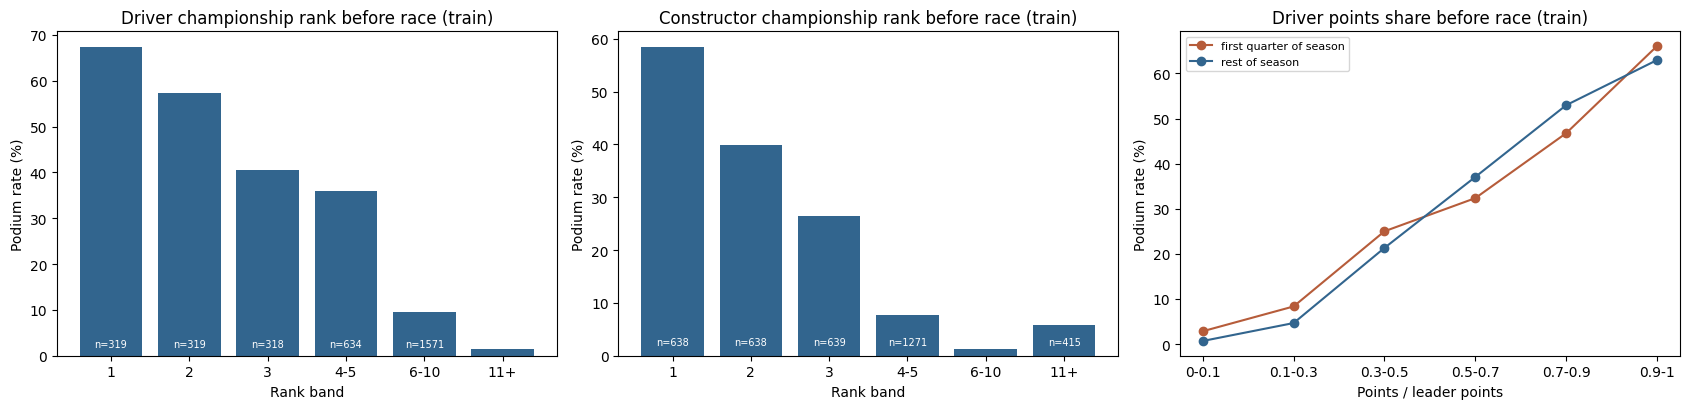

Spearman correlation with podium (train):


,spearman_with_podium
driver_points_share,0.470
driver_champ_rank,-0.472
constructor_points_share,0.475
constructor_champ_rank,-0.447
season_progress,0.000
standings_from_last_season,0.018


,feature,group,source,pre_race_reason
0,grid_position,grid,results.grid,starting slot after penalties; pit-lane starts...
1,grid_relative,grid,results.grid,grid position / number of starters
2,pit_lane_start,grid,results.grid,start from the pit lane is decided before the ...
3,field_size,grid,results.grid,number of cars on the grid
4,quali_position,qualifying,qualifying (+ results.grid),"qualifying rank, known after qualifying"
5,q1_gap_pct,qualifying,qualifying (+ results.grid),% slower than the fastest Q1 lap of the race (...
6,q1_gap_to_teammate_pct,qualifying,qualifying (+ results.grid),% slower than the teammate in Q1 (driver vs sa...
7,grid_minus_quali,qualifying,qualifying (+ results.grid),places lost (penalty) or gained between qualif...
8,driver_podium_rate_last5,driver_form,results of earlier races,share of the driver's previous 5 starts that e...
9,driver_avg_finish_rel_last5,driver_form,results of earlier races,average finishing position / field size over t...


PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/feature_register.csv')

In [28]:
# FE 3. Championship standings BEFORE the race (driver and constructor), plus season progress.
races_cal = clean['races'][['raceId','year','round','date']].copy()
races_cal['year'] = races_cal.year.astype('int64')
races_cal['date'] = pd.to_datetime(races_cal.date)

def standings_snapshots(table, entity):
    """Snapshot AFTER each race: points share of the leader and championship rank."""
    s = clean[table][['raceId', entity, 'points', 'position']].copy()
    assert not s.duplicated(['raceId', entity]).any()
    s = s.merge(races_cal, on='raceId', how='left', validate='many_to_one')
    leader = s.groupby('raceId').points.transform('max')
    s['points_share'] = (s.points / leader).where(leader > 0, 0.0).astype(float)
    s['rank'] = s.position.astype('Int64')
    s[entity] = s[entity].astype('int64')
    return s[['raceId', entity, 'year', 'date', 'points_share', 'rank']]

def standings_features(rows, snaps, entity, prefix):
    """rows: one row per (raceId, entity) to predict. Use the latest snapshot strictly before the race in the same
    season; for season openers use the previous season's final standings; if earlier races this season exist but the
    driver/team is not listed yet (0 points), share 0 and rank = last listed rank + 1; otherwise share 0, rank empty."""
    left = rows[['raceId', entity]].drop_duplicates().merge(races_cal, on='raceId', how='left', validate='many_to_one')
    left[entity] = left[entity].astype('int64')
    right = snaps.rename(columns={'raceId':'src_raceId', 'date':'src_date'})
    same = pd.merge_asof(left.sort_values('date'), right.sort_values('src_date'),
                         left_on='date', right_on='src_date', by=[entity, 'year'],
                         direction='backward', allow_exact_matches=False)
    first_date = races_cal.groupby('year').date.transform('min')
    opener_ids = set(races_cal.loc[races_cal.date.eq(first_date), 'raceId'])
    final_race = races_cal.loc[races_cal.groupby('year').date.idxmax(), ['year','raceId']]
    final = snaps.merge(final_race, on=['year','raceId']).assign(year=lambda d: d.year + 1)[[entity,'year','points_share','rank','raceId']]
    final = final.rename(columns={'points_share':'prev_share','rank':'prev_rank','raceId':'prev_src_raceId'})
    out = same.merge(final, on=[entity, 'year'], how='left', validate='many_to_one')
    # The standings table only lists drivers/teams that already have points (2003-2011 omit zero-point entries).
    # For each race, find the lowest listed rank in the latest EARLIER same-season snapshot.
    last_listed = (snaps.groupby('raceId').agg(year=('year','first'), season_src_date=('date','first'),
                                               last_rank=('rank','max')).reset_index(drop=True))
    last_listed['year'] = last_listed.year.astype('int64')
    out = pd.merge_asof(out.sort_values('date'), last_listed.sort_values('season_src_date'),
                        left_on='date', right_on='season_src_date', by='year',
                        direction='backward', allow_exact_matches=False).reset_index(drop=True)
    # All masks are computed AFTER the last merge, so they line up with the rows of `out`.
    opener = out.raceId.isin(opener_ids)
    assert out.loc[opener, 'src_raceId'].isna().all(), 'a season opener cannot have an earlier same-season snapshot'
    assert out.loc[opener, 'last_rank'].isna().all()
    has_same = out.src_raceId.notna()
    assert (out.loc[has_same, 'src_date'] < out.loc[has_same, 'date']).all()          # strictly earlier race
    assert (out.loc[out.last_rank.notna(), 'season_src_date'] < out.loc[out.last_rank.notna(), 'date']).all()
    # Not an opener, no own snapshot, but earlier races this season exist -> 0 points so far, ranked below last listed
    no_points_yet = ~has_same & ~opener & out.last_rank.notna()
    out[f'{prefix}_points_share'] = np.select([has_same, opener & out.prev_share.notna()],
                                              [out.points_share, out.prev_share], default=0.0)
    rank = out['rank'].where(has_same, out.prev_rank.where(opener)).astype('Float64')
    rank = rank.mask(no_points_yet, out.last_rank.astype('Float64') + 1)
    out[f'{prefix}_champ_rank'] = rank.astype('Int16')
    out[f'{prefix}_standings_source'] = np.select([has_same, opener & out.prev_share.notna(), no_points_yet],
                                                  ['same season, earlier race', 'previous season final',
                                                   'no points yet this season (ranked below last listed)'],
                                                  default='not yet classified')
    return out[['raceId', entity, f'{prefix}_points_share', f'{prefix}_champ_rank', f'{prefix}_standings_source',
                'src_raceId', 'prev_src_raceId']].rename(columns={'src_raceId':f'{prefix}_src_raceId',
                                                                 'prev_src_raceId':f'{prefix}_prev_src_raceId'})

def add_standings(table, d_snaps, c_snaps):
    new = ['driver_points_share','driver_champ_rank','driver_standings_source','constructor_points_share',
           'constructor_champ_rank','constructor_standings_source','standings_from_last_season','season_progress']
    t = table.drop(columns=[c for c in new if c in table.columns])
    n = len(t)
    d = standings_features(t, d_snaps, 'driverId', 'driver')
    c = standings_features(t, c_snaps, 'constructorId', 'constructor')
    t = t.merge(d.drop(columns=['driver_src_raceId','driver_prev_src_raceId']), on=KEY, how='left', validate='one_to_one')
    t = t.merge(c.drop(columns=['constructor_src_raceId','constructor_prev_src_raceId']),
                on=['raceId','constructorId'], how='left', validate='many_to_one')
    assert len(t) == n and not t.duplicated(KEY).any()
    t['standings_from_last_season'] = t.driver_standings_source.eq('previous season final').astype('int8')
    n_rounds = races_cal.groupby('year').raceId.transform('size')
    progress = races_cal.assign(season_progress=(races_cal.groupby('year').date.rank(method='first') - 1) / n_rounds)
    t = t.merge(progress[['raceId','season_progress']], on='raceId', how='left', validate='many_to_one')
    assert len(t) == n
    return t, d, c

driver_snaps = standings_snapshots('driver_standings', 'driverId')
constructor_snaps = standings_snapshots('constructor_standings', 'constructorId')
model_table['driverId'] = model_table.driverId.astype('int64'); model_table['constructorId'] = model_table.constructorId.astype('int64')
model_table, d_src, c_src = add_standings(model_table, driver_snaps, constructor_snaps)

# ---- Checks ----
# (a) the snapshot used is never the current race's own (post-race) snapshot
assert not d_src.driver_src_raceId.eq(d_src.raceId).any() and not c_src.constructor_src_raceId.eq(c_src.raceId).any()
# (b) previous-season values only for openers, and they come from the previous year's last race
assert model_table.loc[model_table.standings_from_last_season.eq(1), 'season_progress'].eq(0).all()   # only season openers
for col in ['driver_points_share','constructor_points_share']:
    assert model_table[col].between(0, 1).all() and model_table[col].notna().all()
assert model_table.season_progress.between(0, 1).all()
# (c) perturbation test: change the CURRENT race's standings snapshot; that race's features must not move
std_cols = ['driver_points_share','driver_champ_rank','constructor_points_share','constructor_champ_rank']
for s in range(3):
    probe = model_table[model_table.season_progress.gt(0)].sample(1, random_state=s).iloc[0]
    altered = driver_snaps.copy()
    hit = altered.raceId.eq(probe.raceId) & altered.driverId.eq(probe.driverId)
    altered.loc[hit, 'points_share'] = 0.999; altered.loc[hit, 'rank'] = 99
    alt_c = constructor_snaps.copy()
    hit_c = alt_c.raceId.eq(probe.raceId) & alt_c.constructorId.eq(probe.constructorId)
    alt_c.loc[hit_c, 'points_share'] = 0.999; alt_c.loc[hit_c, 'rank'] = 99
    b, _, _ = add_standings(model_table, altered, alt_c)
    same_row = model_table.raceId.eq(probe.raceId) & model_table.driverId.eq(probe.driverId)
    pd.testing.assert_frame_equal(model_table.loc[same_row, std_cols].reset_index(drop=True),
                                  b.loc[same_row, std_cols].reset_index(drop=True))
    later = (model_table[std_cols].fillna(-9).astype(float) != b[std_cols].fillna(-9).astype(float)).any(axis=1)
    print(f'Leakage test {s+1}: race {int(probe.raceId)}, driver {int(probe.driverId)}: features of that race unchanged; '
          f'rows changed (later races only): {int(later.sum())}, all later: {bool((model_table.loc[later,"date"] > probe.date).all())}')
    assert (model_table.loc[later, 'date'] > probe.date).all()

for f, why in [('driver_champ_rank', 'championship position after the previous race (openers: last season final; unlisted 0-point: last listed + 1)'),
               ('driver_points_share', 'driver points / leader points before this race (comparable across scoring systems)'),
               ('constructor_champ_rank', 'constructors\' championship position after the previous race'),
               ('constructor_points_share', 'team points / leading team points before this race'),
               ('season_progress', 'share of the season already completed (calendar known in advance)'),
               ('standings_from_last_season', '1 if standings are last season\'s final (season opener)')]:
    register(f, 'standings', 'driver_standings / constructor_standings (previous snapshot)', why)

# ---- Coverage and evidence (TRAINING rows only) ----
print('Where the standings values come from (rows):')
display(pd.crosstab(model_table.split, model_table.driver_standings_source).reindex(list(SPLITS)))
display(pd.crosstab(model_table.split, model_table.constructor_standings_source).reindex(list(SPLITS)))
display(model_table[std_cols + ['season_progress']].astype(float).describe().T.round(3))

tr = model_table[model_table.split.eq('train')]
def rank_band(r):
    return pd.cut(r.astype(float), [0, 1, 2, 3, 5, 10, np.inf], labels=['1','2','3','4-5','6-10','11+'])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, col, title in [(axes[0], 'driver_champ_rank', 'Driver championship rank before race (train)'),
                       (axes[1], 'constructor_champ_rank', 'Constructor championship rank before race (train)')]:
    g = tr.groupby(rank_band(tr[col]), observed=False).podium.agg(['mean','size'])
    ax.bar(g.index.astype(str), 100*g['mean'], color='#32658E')
    for i, n in enumerate(g['size']): ax.text(i, 2, f'n={n}', ha='center', fontsize=7, color='white')
    ax.set(title=title, xlabel='Rank band', ylabel='Podium rate (%)')
early = tr.season_progress.lt(0.25)
for lab, m, colr in [('first quarter of season', early, '#B65C3A'), ('rest of season', ~early, '#32658E')]:
    sub = tr[m]
    g = sub.groupby(pd.cut(sub.driver_points_share, [-0.001, .1, .3, .5, .7, .9, 1.0]), observed=False).podium.mean()
    axes[2].plot(range(len(g)), 100*g.values, marker='o', color=colr, label=lab)
axes[2].set_xticks(range(6)); axes[2].set_xticklabels(['0-0.1','0.1-0.3','0.3-0.5','0.5-0.7','0.7-0.9','0.9-1'])
axes[2].set(title='Driver points share before race (train)', xlabel='Points / leader points', ylabel='Podium rate (%)')
axes[2].legend(fontsize=8)
figure('fe_standings_evidence')

corr = tr[std_cols + ['season_progress','standings_from_last_season','podium']].astype(float).corr(method='spearman')['podium'].drop('podium')
print('Spearman correlation with podium (train):')
display(corr.round(3).to_frame('spearman_with_podium'))
feature_register = pd.DataFrame(FEATURE_REGISTER).drop_duplicates('feature', keep='last')
display(feature_register)
clean_export(feature_register, 'feature_register')

In [29]:
def unclassified_breakdown(entity, source_col):
    t = model_table[[entity, 'year', 'date', 'season_progress', source_col, 'split']].copy()
    first_of_season = t.groupby([entity, 'year']).date.transform('min').eq(t.date)
    nc = t[source_col].eq('not yet classified')
    kind = np.select([nc & t.season_progress.eq(0),
                      nc & ~t.season_progress.eq(0) & first_of_season,
                      nc & ~first_of_season],
                     ['opener, no previous season', 'first race of season (mid-season debut)',
                      'raced earlier this season but no snapshot (data gap)'], default='')
    return pd.crosstab(kind[nc], t.loc[nc, 'split'])
display(unclassified_breakdown('driverId', 'driver_standings_source'))
display(unclassified_breakdown('constructorId', 'constructor_standings_source'))

split,test,train,validation
row_0,,,
"opener, no previous season",6,69,6


split,test,train,validation
row_0,,,
"opener, no previous season",4,42,6


Championship standings: evidence (training data, 2003–2019). Standings are taken from the latest snapshot of an earlier race in the same season (93% of training rows); season openers use the previous season’s final standings, drivers or teams who have raced earlier this season but are not yet listed (0 points so far) get points share 0 and a rank one below the last listed position; only rookies or new teams at a season opener get points share 0 and no rank (filled later, with a missing flag). A perturbation test confirms that a race’s own (post-race) standings never affect its features. Points are expressed as a share of the leader’s points because the scoring system changed in 2010 (a win was worth 10 points before and 25 after), which makes raw points incomparable across the training years. Championship rank and points share are strongly linked to podiums for both drivers (Spearman −0.47 / +0.47) and constructors (−0.45 / +0.48). Season progress has no link on its own (0.00); it is included because early-season standings rest on few races (plot 3). Its value, and the group’s added contribution beyond form and grid, are measured in the feature-group ablation.

Data quirk: McLaren 2007. McLaren was excluded from the 2007 constructors’ championship. The dataset keeps McLaren’s 2007 points but ranks them last (11th) in every 2007 race. Their `constructor_champ_rank` for 2007, and for the 2008 opener (which uses the 2007 final standings), therefore shows the season’s strongest team as the weakest: 34 training rows, 23 of them podiums. This explains the 6% podium rate in the constructor rank 11+ band. `constructor_points_share` (1.0 on these rows, because McLaren led on points), driver standings and constructor form are unaffected. The values are kept as recorded; the rows are 0.5% of training and none are in validation or test.

In [30]:
def gap_check(entity, source_col, group_col):
    t = model_table[['raceId', 'driverId', 'constructorId', 'year', 'date', 'season_progress', source_col, 'split']].copy()
    first_of_season = t.groupby([entity, 'year']).date.transform('min').eq(t.date)
    gap = t[t[source_col].eq('not yet classified') & ~first_of_season]
    pts = analysis_base[[group_col, 'year', 'race_date', 'points']].rename(columns={group_col: entity}).copy()
    pts['race_date'] = pd.to_datetime(pts.race_date)
    m = gap.merge(pts, on=[entity, 'year'], how='left')
    m = m[m.race_date < pd.to_datetime(m.date)]
    earlier = m.groupby(['raceId', entity]).points.sum().rename('points_scored_earlier_this_season')
    out = gap.merge(earlier.reset_index(), on=['raceId', entity], how='left')
    print(f'{entity}: {len(out)} gap rows; with earlier points > 0: {int(out.points_scored_earlier_this_season.gt(0).sum())}')
    display(out.groupby('year').agg(rows=('raceId', 'size'),
                                    with_points=('points_scored_earlier_this_season', lambda s: int(s.gt(0).sum()))))
    return out
driver_gaps = gap_check('driverId', 'driver_standings_source', 'driverId')
team_gaps = gap_check('constructorId', 'constructor_standings_source', 'constructorId')

driverId: 0 gap rows; with earlier points > 0: 0


,rows,with_points
year,,


constructorId: 0 gap rows; with earlier points > 0: 0


,rows,with_points
year,,


## FE 4. Feature lock: final list, missing values, modeling-table export

Missing values per feature and split (left empty here; filled in preprocessing using TRAINING rows only):


split,train,validation,test,train_%,validation_%,test_%,reason
quali_position,21,1,0,0.31,0.13,0.00,no qualifying record for this driver at this race
q1_gap_pct,123,9,13,1.81,1.16,0.96,no Q1 time (no lap set or no qualifying record)
q1_gap_to_teammate_pct,241,18,25,3.55,2.31,1.85,"driver or teammate has no Q1 time, or the team..."
grid_minus_quali,21,1,0,0.31,0.13,0.00,no qualifying position (same rows as quali_pos...
driver_podium_rate_last5,75,6,8,1.10,0.77,0.59,driver's first start (no earlier race)
driver_avg_finish_rel_last5,75,6,8,1.10,0.77,0.59,driver's first start (no earlier race)
driver_finish_rate_last5,75,6,8,1.10,0.77,0.59,driver's first start (no earlier race)
constructor_podium_rate_last5,35,4,2,0.52,0.51,0.15,team's first race
constructor_best_finish_rel_last5,35,4,2,0.52,0.51,0.15,team's first race
constructor_finish_rate_last5,35,4,2,0.52,0.51,0.15,team's first race


Feature pairs with |Spearman| >= 0.90 in training (near-duplicates):


,feature_a,feature_b,spearman,abs_spearman
0,grid_position,grid_relative,0.990,0.990
3,grid_position,quali_position,0.971,0.971
25,grid_relative,quali_position,0.959,0.959
255,driver_champ_rank,driver_points_share,-0.951,0.951
266,constructor_champ_rank,constructor_points_share,-0.923,0.923
236,constructor_best_finish_rel_last5,constructor_points_share,-0.913,0.913
262,driver_points_share,constructor_points_share,0.912,0.912


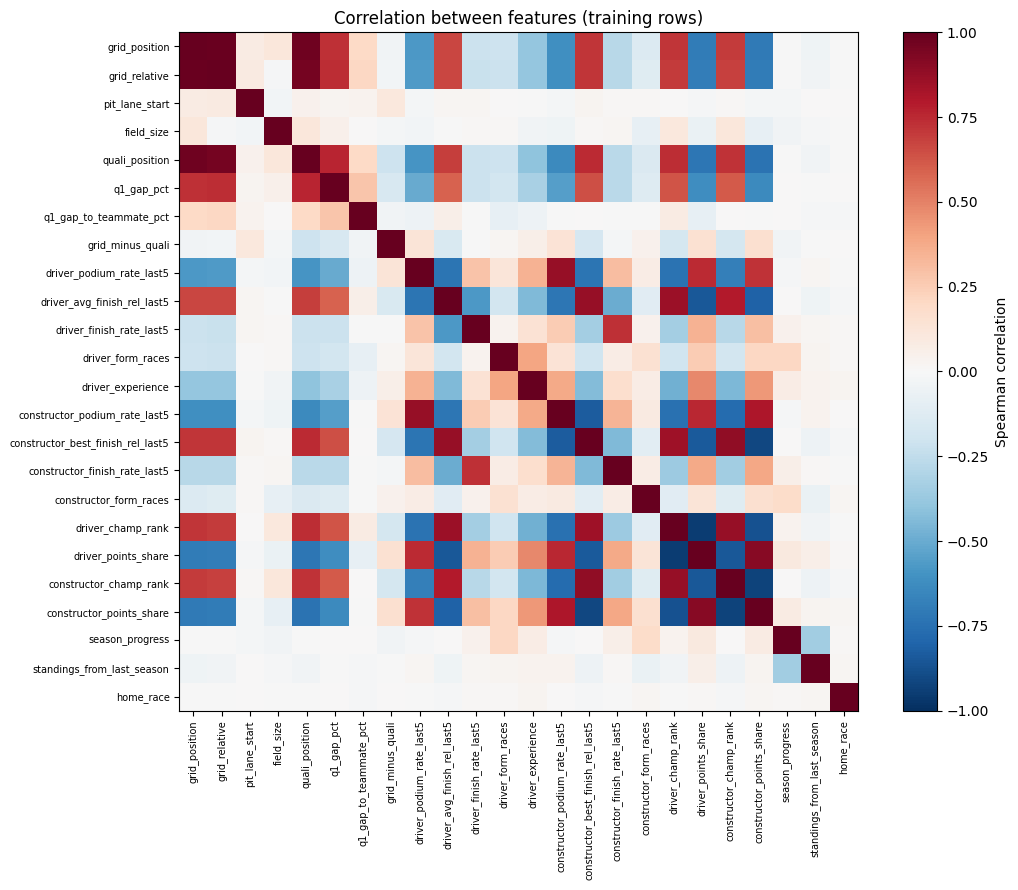

22 model features in 6 groups (2 exact redundancies dropped):
  grid              (3): grid_position, pit_lane_start, field_size
  qualifying        (3): q1_gap_pct, q1_gap_to_teammate_pct, grid_minus_quali
  driver_form       (5): driver_podium_rate_last5, driver_avg_finish_rel_last5, driver_finish_rate_last5, driver_form_races, driver_experience
  constructor_form  (4): constructor_podium_rate_last5, constructor_best_finish_rel_last5, constructor_finish_rate_last5, constructor_form_races
  standings         (6): driver_champ_rank, driver_points_share, constructor_champ_rank, constructor_points_share, season_progress, standings_from_last_season
  context           (1): home_race


,group,missing_train_%,spearman_with_podium,max_abs_spearman_with_other_feature
feature,,,,
grid_position,grid,0.00,-0.495,0.734
pit_lane_start,grid,0.00,-0.021,0.107
field_size,grid,0.00,-0.030,0.117
q1_gap_pct,qualifying,1.81,-0.402,0.734
q1_gap_to_teammate_pct,qualifying,3.55,-0.072,0.277
grid_minus_quali,qualifying,0.31,0.085,0.172
driver_podium_rate_last5,driver_form,1.10,0.528,0.873
driver_avg_finish_rel_last5,driver_form,1.10,-0.442,0.871
driver_finish_rate_last5,driver_form,1.10,0.162,0.728


,rows,races,podium_pct,first,last
split,,,,,
train,6791,320,14.14,2003,2019
validation,778,39,15.04,2020,2021
test,1352,68,15.09,2022,2024


Exported modeling_table.csv (8,921 rows x 33 columns), feature_register.csv and feature_spec.json to /kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning


In [31]:
# FE 4. Lock the feature set: add the last feature, check the list, explain missing values, export the modeling table.

# ---- 1. home_race: nationality and race country are fixed long before the weekend ----
assert model_table.home_race.notna().all(), 'every modeling row needs a home flag (the Q2 mapping covers the cohort)'
model_table['home_race'] = model_table.home_race.astype('int8')
register('home_race', 'context', 'drivers.nationality + circuits.country (Q2 mapping)',
         'driver nationality and the race country are known before the race weekend')

# ---- 2. The final feature list is exactly the register (one row per feature) ----
feature_register = pd.DataFrame(FEATURE_REGISTER).drop_duplicates('feature', keep='last').reset_index(drop=True)
ALL_FEATURES = feature_register.feature.tolist()
FEATURES = ALL_FEATURES                        # narrowed in step 4b
TARGET = 'podium'
META = KEY + ['constructorId', 'circuitId', 'year', 'round', 'date', 'split']
PROVENANCE = ['driver_standings_source', 'constructor_standings_source']      # text labels from FE3, not inputs
assert set(ALL_FEATURES) <= set(model_table.columns), set(ALL_FEATURES) - set(model_table.columns)

# Columns that must never be model inputs: the race outcome, identifiers/time, bookkeeping
NOT_FEATURES = {'podium', 'podium_any_entry', 'positionOrder', 'position', 'positionText', 'points', 'laps', 'time',
                'milliseconds', 'fastestLap', 'fastestLapTime', 'fastestLapSpeed', 'rank', 'statusId', 'status',
                'status_cause', 'finish_status', 'finished', 'finish_rel', 'resultId', 'grid', 'shared_car_entry',
                'in_modeling_cohort', *META, *PROVENANCE}
bad = sorted(set(FEATURES) & NOT_FEATURES)
assert not bad, f'forbidden columns in the feature list: {bad}'
undeclared = sorted(set(model_table.columns) - set(FEATURES) - set(META) - set(PROVENANCE) - {TARGET})
assert not undeclared, f'model_table columns that are neither features, metadata nor target: {undeclared}'

# Every feature is numeric, finite, and varies in the training rows
train_mask = model_table.split.eq('train')
non_numeric = [f for f in FEATURES if not pd.api.types.is_numeric_dtype(model_table[f])]
assert not non_numeric, non_numeric
assert np.isfinite(model_table[FEATURES].astype(float).fillna(0)).all().all(), 'infinite values found'
constant = [f for f in FEATURES if model_table.loc[train_mask, f].nunique() <= 1]
assert not constant, f'features with one value in training: {constant}'

# ---- 3. Missing values: every gap must have a known reason ----
W = FORM_WINDOW
WHY_MISSING = {
    'quali_position': 'no qualifying record for this driver at this race',
    'grid_minus_quali': 'no qualifying position (same rows as quali_position)',
    'q1_gap_pct': 'no Q1 time (no lap set or no qualifying record)',
    'q1_gap_to_teammate_pct': 'driver or teammate has no Q1 time, or the team did not have exactly two cars with times',
    f'driver_podium_rate_last{W}': 'driver\'s first start (no earlier race)',
    f'driver_avg_finish_rel_last{W}': 'driver\'s first start (no earlier race)',
    f'driver_finish_rate_last{W}': 'driver\'s first start (no earlier race)',
    f'constructor_podium_rate_last{W}': 'team\'s first race',
    f'constructor_best_finish_rel_last{W}': 'team\'s first race',
    f'constructor_finish_rate_last{W}': 'team\'s first race',
    'driver_champ_rank': 'season opener and the driver was not in last season\'s final standings (rookie)',
    'constructor_champ_rank': 'season opener and the team was not in last season\'s final standings (new team)'}
miss = model_table.groupby('split')[FEATURES].apply(lambda d: d.isna().sum()).reindex(list(SPLITS)).T
miss = miss[miss.sum(axis=1).gt(0)]
unexplained = sorted(set(miss.index) - set(WHY_MISSING))
assert not unexplained, f'missing values without a documented reason: {unexplained}'
# the reasons are checked, not just written down
assert model_table.grid_minus_quali.isna().equals(model_table.quali_position.isna())
assert model_table[f'driver_podium_rate_last{W}'].isna().equals(model_table.driver_form_races.eq(0))
assert model_table[f'constructor_podium_rate_last{W}'].isna().equals(model_table.constructor_form_races.eq(0))
assert model_table.driver_champ_rank.isna().equals(model_table.driver_standings_source.eq('not yet classified'))
assert model_table.constructor_champ_rank.isna().equals(model_table.constructor_standings_source.eq('not yet classified'))
split_rows = model_table.split.value_counts().reindex(list(SPLITS))
miss_report = miss.copy()
for s in SPLITS: miss_report[f'{s}_%'] = (100 * miss[s] / split_rows[s]).round(2)
miss_report['reason'] = [WHY_MISSING[f] for f in miss_report.index]
print('Missing values per feature and split (left empty here; filled in preprocessing using TRAINING rows only):')
display(miss_report)

# ---- 4. Near-duplicate features (TRAINING rows only) ----
tr = model_table[train_mask]
rho = tr[FEATURES].astype(float).corr(method='spearman')
upper = rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack()
pairs = upper.rename('spearman').rename_axis(['feature_a', 'feature_b']).reset_index()
pairs['abs_spearman'] = pairs.spearman.abs()
high = pairs[pairs.abs_spearman.ge(0.90)].sort_values('abs_spearman', ascending=False).round(3)
print('Feature pairs with |Spearman| >= 0.90 in training (near-duplicates):')
display(high if len(high) else 'none')
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(rho.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES, rotation=90, fontsize=7)
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES, fontsize=7)
plt.colorbar(im, ax=ax, fraction=0.046, label='Spearman correlation')
ax.set_title('Correlation between features (training rows)')
figure('fe_feature_correlation')

# ---- 4b. Remove EXACT redundancies: a feature that is a formula of other kept features adds no information ----
# Near-duplicates that are NOT formulas (e.g. points share vs championship rank) stay; the ablation tests them.
REDUNDANT = {'grid_relative':  'equals grid_position / field_size, and both are kept features',
             'quali_position': 'equals grid_position - grid_minus_quali, and both are kept features'}
assert np.allclose(model_table.grid_relative, model_table.grid_position / model_table.field_size)
has_q = model_table.quali_position.notna()
assert has_q.equals(model_table.grid_minus_quali.notna())       # so dropping quali_position loses no rows of information
assert (model_table.loc[has_q, 'quali_position']
        == model_table.loc[has_q, 'grid_position'] - model_table.loc[has_q, 'grid_minus_quali']).all()
feature_register['status'] = [('dropped: ' + REDUNDANT[f]) if f in REDUNDANT else 'kept' for f in feature_register.feature]
FEATURES = [f for f in ALL_FEATURES if f not in REDUNDANT]
kept_register = feature_register[feature_register.status.eq('kept')]
FEATURE_GROUPS = kept_register.groupby('group', sort=False).feature.apply(list).to_dict()
print(f'{len(FEATURES)} model features in {len(FEATURE_GROUPS)} groups ({len(REDUNDANT)} exact redundancies dropped):')
for g, fs in FEATURE_GROUPS.items(): print(f'  {g:<17} ({len(fs)}): {", ".join(fs)}')

# ---- 5. One-line summary per kept feature (TRAINING rows only) ----
summary = kept_register[['feature', 'group']].set_index('feature')
summary['missing_train_%'] = (100 * tr[FEATURES].isna().mean()).round(2)
summary['spearman_with_podium'] = tr[FEATURES + [TARGET]].astype(float).corr(method='spearman')[TARGET].drop(TARGET).round(3)
rho_kept = rho.loc[FEATURES, FEATURES].abs()
summary['max_abs_spearman_with_other_feature'] = (rho_kept - np.eye(len(FEATURES))).max().round(3)
display(summary)
# ---- 6. Export: the modeling table and the feature specification ----
modeling_table = model_table[META + FEATURES + PROVENANCE + [TARGET]].copy()
assert not modeling_table.duplicated(KEY).any()
assert modeling_table[TARGET].isin([0, 1]).all()
for name, (lo, hi) in SPLITS.items():
    assert modeling_table.loc[modeling_table.split.eq(name), 'year'].between(lo, hi).all()
clean_export(modeling_table, 'modeling_table')
clean_export(feature_register, 'feature_register')
feature_spec = {'target': TARGET, 'key': KEY, 'meta': META, 'features': FEATURES, 'groups': FEATURE_GROUPS,
                'dropped_redundant': REDUNDANT,
                'not_inputs': PROVENANCE, 'form_window': FORM_WINDOW, 'model_start_year': MODEL_START_YEAR,
                'anomalous_races_excluded': {f'{y} {n}': why for (y, n), why in ANOMALOUS_RACES.items()},
                'splits': {k: list(v) for k, v in SPLITS.items()}, 'why_missing': WHY_MISSING}
with open(CLEAN_DIR / 'feature_spec.json', 'w') as f: json.dump(feature_spec, f, indent=2)
display(modeling_table.groupby('split').agg(rows=(TARGET, 'size'), races=('raceId', 'nunique'),
        podium_pct=(TARGET, lambda s: round(100 * s.mean(), 2)), first=('year', 'min'), last=('year', 'max'))
        .reindex(list(SPLITS)))
print(f'Exported modeling_table.csv ({len(modeling_table):,} rows x {modeling_table.shape[1]} columns), '
      f'feature_register.csv and feature_spec.json to {CLEAN_DIR}')

## FE 5. Sprint weekends: a check on what `grid_minus_quali` means
The F1 introduction flags sprint results as a leakage judgement call. **Decision:** `sprint_results` is not used as a feature. The sprint happens before the main race, so it would be allowed, but it exists only from 2021 (a handful of races per season) and would be missing for every training row.

There is one side effect. In **2021–2022** the sprint result set the Sunday grid, so on those weekends `grid − qualifying` measures places gained or lost in the sprint, not grid penalties. From 2023, Friday qualifying sets the Sunday grid again. The cell below measures how many validation/test rows this affects, so the report can state it as a limitation. The sprint is still pre-race information, so this is a change of meaning, not leakage.


In [32]:
# FE 5. How many rows are 2021-2022 sprint weekends, where the sprint (not penalties) moved the grid?
sprint_races = set(clean['sprint_results'].raceId.dropna().astype('int64'))
chk_s = model_table[['raceId', 'year', 'split', 'grid_minus_quali', 'podium']].copy()
chk_s['sprint_weekend'] = chk_s.raceId.astype('int64').isin(sprint_races)
chk_s['sprint_sets_grid'] = chk_s.sprint_weekend & chk_s.year.between(2021, 2022)
sprint_summary = (chk_s.groupby(['split', 'sprint_sets_grid'])
                  .agg(rows=('podium', 'size'), races=('raceId', 'nunique'),
                       pct_grid_differs_from_quali=('grid_minus_quali', lambda s: round(100 * s.fillna(0).ne(0).mean(), 1)),
                       mean_abs_grid_minus_quali=('grid_minus_quali', lambda s: round(float(s.abs().mean()), 2)))
                  .reindex(list(SPLITS), level=0))
display(sprint_summary)
clean_export(sprint_summary.reset_index(), 'sprint_weekend_grid_check')


rows  races  pct_grid_differs_from_quali  \
split      sprint_sets_grid                                             
train      False             6791    320                         27.1   
validation False              719     36                         22.9   
           True                59      3                         88.1   
test       False             1292     65                         27.2   
           True                60      3                         81.7   

                             mean_abs_grid_minus_quali  
split      sprint_sets_grid                             
train      False                                  0.55  
validation False                                  0.57  
           True                                   2.68  
test       False                                  0.67  
           True                                   3.32

PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/sprint_weekend_grid_check.csv')

## Selected features and why each is valid at the pre-race cutoff
| Group | Features | Why it is known before lights-out | Evidence |
|---|---|---|---|
| Grid | `grid_position`, `pit_lane_start`, `field_size` | Starting grid is final before the start (after penalties) | FE1 plot 1; Spearman −0.50 |
| Qualifying | `q1_gap_pct`, `q1_gap_to_teammate_pct`, `grid_minus_quali` | Qualifying ends before the race | FE1 plots 2–3; Q1 answer (qualified front row but started further back still podiums 33%) |
| Driver form | podium rate, avg relative finish, finish rate (last 5), history count, experience | Built only from earlier races (`shift(1)`), perturbation-tested | FE2 plots; Spearman up to +0.53 |
| Constructor form | podium rate, best relative finish, finish rate (last 5), history count | Team results aggregated per race first, then shifted, so a teammate's current result cannot leak | FE2 plots; Spearman up to +0.52 |
| Standings | champ rank and points share (driver, team), season progress, last-season flag | Snapshot from the previous race (`merge_asof`, strictly earlier), perturbation-tested | FE3 plots; Spearman ≈ ±0.47 |
| Context | `home_race` | Nationality and circuit country are fixed in advance | Q2 (no adjusted effect); kept so the ablation can test it |

**Dropped:** `grid_relative` and `quali_position` (exact formulas of kept features, FE4 step 4b). **Never used:** the current race's results, points, status, laps, pit stops, fastest lap, post-race standings and sprint results.


## Dataset split and why
| Split | Seasons | Rows | Podium % |
|---|---|---|---|
| Train | 2003–2019 | 6,791 | 14.1 |
| Validation | 2020–2021 | 778 | 15.0 |
| Test (unseen) | 2022–2024 | 1,352 | 15.1 |

- **Chronological, not random.** Form and standings features describe earlier races. A random split would put races from the same weekend and season on both sides and leak the future into training. A chronological split also matches the real use: predicting next weekend from the past.
- **Disjoint races, strict time order.** The cell below asserts this.
- **Why these boundaries.** They are the boundaries suggested by the F1 introduction. The test set is the 2022 ground-effect rules era, so it also checks whether the model survives a regulation change, which makes it a hard test. Validation (2020–2021) is the most recent data before it.
- **Why training starts in 2003.** Qualifying rows cover every entry from 2003 onward (Section 8 coverage plot; 1996–2002 is only 6–58% covered). Earlier seasons would need qualifying features to be mostly imputed.
- **Class balance** is similar across splits (14–15%), so no resampling is needed for the split itself; imbalance is handled by the metric choice (PR-AUC) and the threshold chosen on validation.
- **Limitations.** Validation is small (39 races) and contains the shortened 2020 COVID season; differences smaller than the race-bootstrap intervals are treated as ties.


## P1. Preprocessing (fitted on training rows only)

Preprocessing learned from 6,791 training rows; 22 features -> 27 columns (5 missing flags). Checks passed.


,missing_before,mean_before,min_before,max_before,skew_before,missing_after,mean_after_fill,min_after,max_after,skew_after,fill_value,step
grid_position,0,11.190,1.000,24.000,0.060,0,11.190,1.000,24.000,0.060,11.000,median fill
pit_lane_start,0,0.003,0.000,1.000,18.830,0,0.003,0.000,1.000,18.830,0.000,median fill
field_size,0,21.343,15.000,24.000,0.331,0,21.343,15.000,24.000,0.331,21.000,median fill
q1_gap_pct,123,1.782,0.000,33.285,4.122,0,0.882,0.000,3.535,0.520,1.415,log1p + mean fill
q1_gap_to_teammate_pct,241,0.007,-18.387,22.529,1.840,0,0.002,-2.366,2.423,0.045,0.002,clip 1-99% + mean fill
grid_minus_quali,21,0.001,-7.000,23.000,4.781,0,0.001,-7.000,23.000,4.788,0.000,median fill + missing flag
driver_podium_rate_last5,75,0.142,0.000,1.000,1.802,0,0.141,0.000,1.000,1.820,0.000,median fill
driver_avg_finish_rel_last5,75,0.521,0.045,1.000,-0.295,0,0.521,0.045,1.000,-0.299,0.540,median fill
driver_finish_rate_last5,75,0.775,0.000,1.000,-0.920,0,0.775,0.000,1.000,-0.929,0.800,median fill
driver_form_races,0,4.837,0.000,5.000,-5.005,0,4.837,0.000,5.000,-5.005,5.000,median fill


q1_gap_to_teammate_pct: clip bounds -2.37% to 2.42%, 132 training values clipped
Missing-flag rate per split (%):


,train,validation,test
q1_gap_pct_missing,1.81,1.16,0.96
q1_gap_to_teammate_pct_missing,3.55,2.31,1.85
grid_minus_quali_missing,0.31,0.13,0.00
driver_champ_rank_missing,1.02,0.77,0.44
constructor_champ_rank_missing,0.62,0.77,0.30


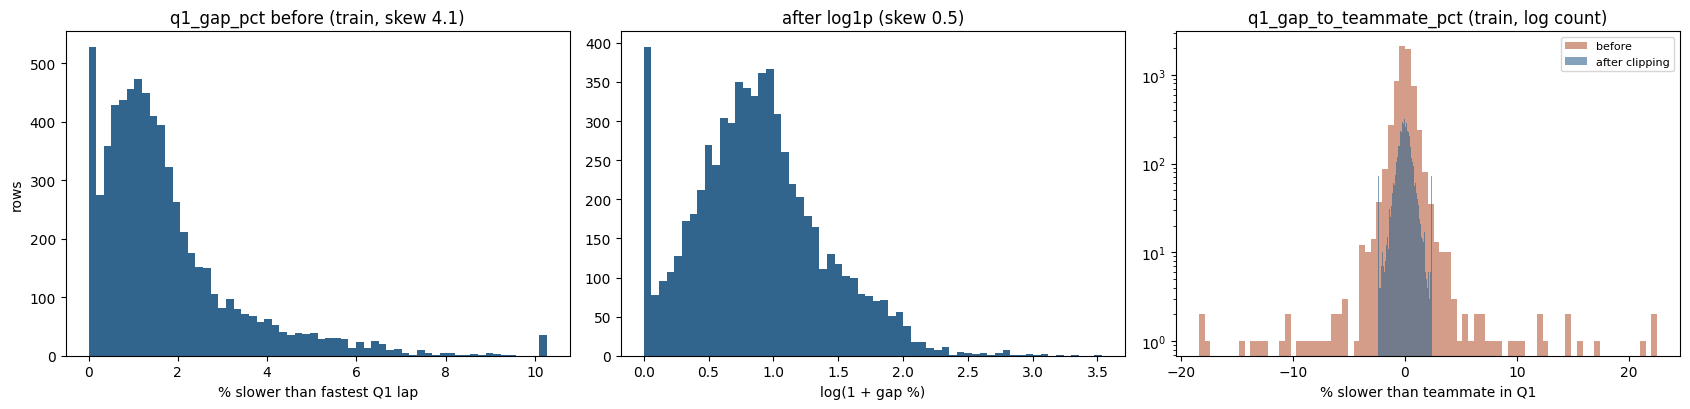

In [33]:
# P1. Preprocessing: every statistic is learned from TRAINING rows only, then applied unchanged to validation/test.
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted

# ---- 1. Read the locked modeling table (the models can only see what FE4 exported) ----
modeling_table = pd.read_csv(CLEAN_DIR / 'modeling_table.csv', parse_dates=['date'])
feature_spec = json.load(open(CLEAN_DIR / 'feature_spec.json'))
FEATURES, TARGET, KEY = feature_spec['features'], feature_spec['target'], feature_spec['key']
part = {s: modeling_table[modeling_table.split.eq(s)].sort_values(['date', 'raceId', 'driverId']).reset_index(drop=True)
        for s in SPLITS}
X = {s: d[FEATURES].astype(float) for s, d in part.items()}
y = {s: d[TARGET].astype(int).to_numpy() for s, d in part.items()}

# Split protocol checks: disjoint rows and races, strict time order, both classes everywhere
names = list(SPLITS)
for a, b in zip(names, names[1:]):
    assert part[a].date.max() < part[b].date.min(), f'{a} must end before {b} starts'
for i, a in enumerate(names):
    for b in names[i + 1:]:
        assert not set(part[a].raceId) & set(part[b].raceId), f'race shared by {a} and {b}'
assert all(len(np.unique(y[s])) == 2 for s in SPLITS)

# ---- 2. The preprocessing recipe ----
LOG_FEATURE = 'q1_gap_pct'               # >= 0 and right-skewed (a few drivers 5-10%+ off the pace): log1p helps
CLIP_FEATURE = 'q1_gap_to_teammate_pct'  # long tails on both sides (a teammate with a wrecked lap): clip at 1st/99th pct
CLIP_QUANTILES = (0.01, 0.99)
# Missing flags only where the gap itself carries information and no other feature already says so
# (missing form rates are already told apart by driver_form_races / constructor_form_races = 0).
MISSING_FLAGS = ['q1_gap_pct', 'q1_gap_to_teammate_pct', 'grid_minus_quali', 'driver_champ_rank', 'constructor_champ_rank']

class PodiumPreprocessor(BaseEstimator, TransformerMixin):
    """fit() learns fill values, clip bounds and scaling from the rows it is given (training rows only).
    transform() only applies those stored numbers, row by row; it never looks at statistics of new data.
    log_order : 'impute_first'  -> fill LOG_FEATURE with its raw mean, then log1p
                'transform_first' -> log1p, then fill with the mean of the logged values
    clip_order: 'impute_first'  -> fill CLIP_FEATURE with its raw mean, then clip at quantiles of the filled column
                'clip_first'    -> clip observed values at their quantiles, then fill with the mean of clipped values
    All other features: median fill. scale=True standardises every output column (mean 0, sd 1 on train)."""
    def __init__(self, features, log_order='transform_first', clip_order='clip_first', scale=True):
        self.features, self.log_order, self.clip_order, self.scale = features, log_order, clip_order, scale

    def _flags(self, X):
        return pd.DataFrame({f'{f}_missing': X[f].isna().astype(float) for f in self.flags_}, index=X.index)

    def fit(self, X, y=None):
        assert self.log_order in ('impute_first', 'transform_first') and self.clip_order in ('impute_first', 'clip_first')
        X = X[self.features].astype(float)
        assert X[LOG_FEATURE].dropna().ge(0).all(), 'log1p needs non-negative values'
        self.flags_ = [f for f in MISSING_FLAGS if f in self.features]
        raw = X[LOG_FEATURE]
        self.log_fill_ = (float(np.log1p(raw.mean())) if self.log_order == 'impute_first'   # log of the raw mean
                          else float(np.log1p(raw).mean()))                              # mean of the logs
        c = X[CLIP_FEATURE]
        if self.clip_order == 'impute_first':
            filled = c.fillna(c.mean())
            self.clip_fill_ = float(c.mean())
            self.clip_bounds_ = tuple(float(v) for v in filled.quantile(CLIP_QUANTILES))
        else:
            self.clip_bounds_ = tuple(float(v) for v in c.quantile(CLIP_QUANTILES))   # observed values only
            self.clip_fill_ = float(c.clip(*self.clip_bounds_).mean())
        others = [f for f in self.features if f not in (LOG_FEATURE, CLIP_FEATURE)]
        self.medians_ = X[others].median().to_dict()
        assert all(np.isfinite(v) for v in self.medians_.values()), 'a feature has no training values'
        Z = self._apply(X)
        self.mean_, self.sd_ = Z.mean(), Z.std(ddof=0).replace(0, 1.0)
        self.feature_names_out_ = list(Z.columns)
        return self

    def _apply(self, X):
        X = X[self.features].astype(float)
        out = X.copy()
        out[LOG_FEATURE] = np.log1p(X[LOG_FEATURE]).fillna(self.log_fill_)     # same result for both orders, given the fill
        if self.clip_order == 'impute_first':
            out[CLIP_FEATURE] = X[CLIP_FEATURE].fillna(self.clip_fill_).clip(*self.clip_bounds_)
        else:
            out[CLIP_FEATURE] = X[CLIP_FEATURE].clip(*self.clip_bounds_).fillna(self.clip_fill_)
        for f, m in self.medians_.items(): out[f] = X[f].fillna(m)
        return pd.concat([out, self._flags(X)], axis=1)

    def transform(self, X):
        check_is_fitted(self, 'mean_')
        Z = self._apply(X)
        return ((Z - self.mean_) / self.sd_) if self.scale else Z

    def get_feature_names_out(self, input_features=None):
        return np.array(self.feature_names_out_)

# ---- 3. Proof that only training rows shape the preprocessing ----
pre = PodiumPreprocessor(FEATURES).fit(X['train'])
tr_raw = X['train']
assert np.isclose(pre.log_fill_, np.log1p(tr_raw[LOG_FEATURE]).mean())                        # from train only
lo, hi = tr_raw[CLIP_FEATURE].quantile(CLIP_QUANTILES)
assert np.isclose(pre.clip_bounds_[0], lo) and np.isclose(pre.clip_bounds_[1], hi)
assert all(np.isclose(pre.medians_[f], tr_raw[f].median()) for f in pre.medians_)
# (a) the rows used for fitting are training rows only
assert part['train'].split.eq('train').all() and part['train'].year.max() <= SPLITS['train'][1]
wrecked = {s: X[s] * 1000 + 7 for s in ('validation', 'test')}          # deliberately absurd values for test (b)
# (b) a row's output does not depend on which other rows are transformed with it (no statistics of new data)
alone = pre.transform(X['validation'])
together = pre.transform(pd.concat([X['validation'], wrecked['test']], ignore_index=True)).iloc[:len(alone)]
pd.testing.assert_frame_equal(alone.reset_index(drop=True), together.reset_index(drop=True))
one_row = pre.transform(X['validation'].iloc[[5]])
pd.testing.assert_frame_equal(one_row.reset_index(drop=True), alone.iloc[[5]].reset_index(drop=True))
# (c) after preprocessing nothing is missing; training columns have mean 0 and sd 1
Z = {s: pre.transform(X[s]) for s in SPLITS}
assert all(Z[s].notna().all().all() for s in SPLITS)
sd_train = Z['train'].std(ddof=0)
assert np.allclose(Z['train'].mean(), 0, atol=1e-9) and ((sd_train - 1).abs().lt(1e-6) | sd_train.lt(1e-12)).all()
print(f'Preprocessing learned from {len(X["train"]):,} training rows; {len(FEATURES)} features -> '
      f'{len(pre.feature_names_out_)} columns ({len(pre.flags_)} missing flags). Checks passed.')

# ---- 4. What preprocessing does to the values (before vs after, TRAINING rows) ----
unscaled = PodiumPreprocessor(FEATURES, scale=False).fit(X['train'])
U = unscaled.transform(X['train'])
effects = pd.DataFrame({
    'missing_before': X['train'].isna().sum(), 'mean_before': X['train'].mean(), 'min_before': X['train'].min(),
    'max_before': X['train'].max(), 'skew_before': X['train'].skew(),
    'missing_after': U[FEATURES].isna().sum(), 'mean_after_fill': U[FEATURES].mean(), 'min_after': U[FEATURES].min(),
    'max_after': U[FEATURES].max(), 'skew_after': U[FEATURES].skew()})
effects['fill_value'] = [np.expm1(unscaled.log_fill_) if f == LOG_FEATURE else unscaled.clip_fill_ if f == CLIP_FEATURE
                         else unscaled.medians_[f] for f in FEATURES]
effects['step'] = ['log1p + mean fill' if f == LOG_FEATURE else 'clip 1-99% + mean fill' if f == CLIP_FEATURE
                   else 'median fill' + (' + missing flag' if f in MISSING_FLAGS else '') for f in FEATURES]
display(effects.round(3))
print(f'{CLIP_FEATURE}: clip bounds {unscaled.clip_bounds_[0]:.2f}% to {unscaled.clip_bounds_[1]:.2f}%, '
      f'{int(((X["train"][CLIP_FEATURE] < unscaled.clip_bounds_[0]) | (X["train"][CLIP_FEATURE] > unscaled.clip_bounds_[1])).sum())} '
      f'training values clipped')
print('Missing-flag rate per split (%):')
display(pd.DataFrame({s: 100 * pre._flags(X[s]).mean() for s in SPLITS}).round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
v = X['train'][LOG_FEATURE].dropna()
axes[0].hist(v.clip(upper=v.quantile(0.995)), bins=60, color='#32658E')
axes[0].set(title=f'{LOG_FEATURE} before (train, skew {v.skew():.1f})', xlabel='% slower than fastest Q1 lap', ylabel='rows')
axes[1].hist(np.log1p(v), bins=60, color='#32658E')
axes[1].set(title=f'after log1p (skew {np.log1p(v).skew():.1f})', xlabel='log(1 + gap %)')
w = X['train'][CLIP_FEATURE].dropna()
axes[2].hist(w, bins=80, color='#B65C3A', alpha=0.6, label='before')
axes[2].hist(w.clip(*unscaled.clip_bounds_), bins=80, color='#32658E', alpha=0.6, label='after clipping')
axes[2].set_yscale('log'); axes[2].legend(fontsize=8)
axes[2].set(title=f'{CLIP_FEATURE} (train, log count)', xlabel='% slower than teammate in Q1')
figure('preprocessing_effects')

All preprocessing statistics are learned from the 6,791 training rows and applied unchanged to validation and test. Tests confirm this: fitted values match direct training-only calculations, and each row’s output is identical whether transformed alone, in its split, or mixed with absurd values. q1_gap_pct is non-negative and right-skewed (skew 4.1, maximum 33%), so it is log-transformed, reducing skew to 0.52. q1_gap_to_teammate_pct has extreme tails from aborted laps (−18% to +23%), so it is clipped at the training 1st/99th percentiles (−2.37%, +2.42%; 132 training values affected), reducing skew from 1.84 to 0.05. Other gaps are filled with the training median. Missing flags are added only where the absence is informative and not already captured by another feature (both Q1 gaps, no qualifying record, rookie or new team at a season opener). Large grid_minus_quali values are real grid penalties and are kept. All 27 resulting columns are standardized using training means and standard deviations, as needed by logistic regression and the neural network.

## P2. Baseline model and preprocessing-order experiments A and B

A: mean fill vs log1p (q1_gap_pct)
  PR-AUC (transform_first minus impute_first): -0.0002  95% race-bootstrap interval [-0.0011, +0.0003]
  ROC-AUC difference:          -0.0000  95% interval [-0.0002, +0.0001]
  -> equivalent on this data; chosen order: transform_first
B: mean fill vs clipping (q1_gap_to_teammate_pct)
  PR-AUC (clip_first minus impute_first): -0.0001  95% race-bootstrap interval [-0.0005, +0.0000]
  ROC-AUC difference:          -0.0000  95% interval [-0.0001, +0.0000]
  -> equivalent on this data; chosen order: clip_first


,experiment,order,fill_value_raw_units,clip_bounds_pct,train_roc_auc,train_pr_auc,train_f1,train_precision,train_recall,val_roc_auc,val_pr_auc,val_f1,val_precision,val_recall
0,A: mean fill vs log1p (q1_gap_pct),impute first,1.7819,,0.9326,0.696,0.6323,0.6845,0.5875,0.9302,0.7231,0.682,0.74,0.6325
1,A: mean fill vs log1p (q1_gap_pct),transform first,1.4147,,0.9326,0.696,0.6323,0.6845,0.5875,0.9302,0.7229,0.682,0.74,0.6325
2,B: mean fill vs clipping (q1_gap_to_teammate_pct),impute first,0.0072,-2.35 to 2.40,0.9326,0.696,0.6323,0.6845,0.5875,0.9302,0.7230,0.682,0.74,0.6325
3,B: mean fill vs clipping (q1_gap_to_teammate_pct),clip first,0.0023,-2.37 to 2.42,0.9326,0.696,0.6323,0.6845,0.5875,0.9302,0.7229,0.682,0.74,0.6325


A: mean fill vs log1p (q1_gap_pct): validation rows whose probability moved by > 0.001: 0 of 778; largest move 0.0006
B: mean fill vs clipping (q1_gap_to_teammate_pct): validation rows whose probability moved by > 0.001: 0 of 778; largest move 0.0002


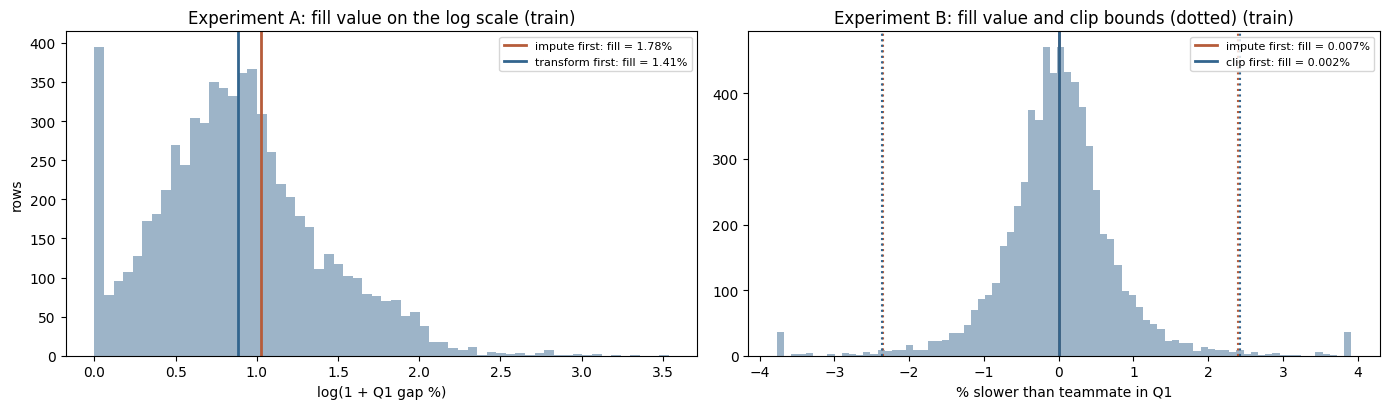

Final preprocessing: {'log_order': 'transform_first', 'clip_order': 'clip_first'}


,roc_auc,pr_auc,f1,precision,recall
train,0.9326,0.6960,0.6323,0.6845,0.5875
validation,0.9302,0.7229,0.6820,0.7400,0.6325


Baseline coefficients (standardised inputs; positive = higher podium odds):


,coefficient
grid_position,-1.822
driver_avg_finish_rel_last5,-0.428
constructor_best_finish_rel_last5,-0.418
driver_finish_rate_last5,-0.357
constructor_podium_rate_last5,-0.184
grid_minus_quali_missing,-0.154
q1_gap_pct,-0.151
constructor_form_races,-0.128
driver_form_races,-0.102
pit_lane_start,-0.097


In [34]:
# P2. Baseline model and the two preprocessing-order experiments (decided on VALIDATION; test is not touched).
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score

# ---- 1. Fixed baseline and metric protocol ----
BASELINE_PARAMS = dict(C=1.0, max_iter=5000)     # plain L2 logistic regression, held fixed during these experiments
F1_THRESHOLD = 0.5                                # fixed here; the final threshold is chosen later on validation

def scores(y_true, p, threshold=F1_THRESHOLD):
    pred = (p >= threshold).astype(int)
    return {'roc_auc': roc_auc_score(y_true, p), 'pr_auc': average_precision_score(y_true, p),
            'f1': f1_score(y_true, pred, zero_division=0),
            'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred, zero_division=0)}

def fit_baseline(**pre_kwargs):
    model = make_pipeline(PodiumPreprocessor(FEATURES, **pre_kwargs), LogisticRegression(**BASELINE_PARAMS))
    model.fit(X['train'], y['train'])
    return model

# Paired bootstrap over RACES (rows of one race move together): is a difference bigger than chance?
val_races = part['validation'].raceId.to_numpy()
race_ids = np.unique(val_races)
race_rows = {r: np.flatnonzero(val_races == r) for r in race_ids}
def paired_race_bootstrap(p_a, p_b, metric, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        idx = np.concatenate([race_rows[r] for r in rng.choice(race_ids, size=len(race_ids), replace=True)])
        diffs[i] = metric(y['validation'][idx], p_b[idx]) - metric(y['validation'][idx], p_a[idx])
    return np.percentile(diffs, [2.5, 97.5])

# Decision rule written BEFORE looking at results:
#   if the 95% interval of the PR-AUC difference excludes 0 -> pick the better order;
#   otherwise the orders are equivalent on this data -> keep the default chosen on reasoning:
#   log: transform_first (the fill value is the centre of the values the model actually sees);
#   clip: clip_first (outliers cannot drag the fill value and the bounds).
DEFAULT_ORDER = {'log_order': 'transform_first', 'clip_order': 'clip_first'}

# ---- 2. Run both experiments (each changes ONE order; everything else fixed) ----
EXPERIMENTS = {
    'A: mean fill vs log1p (q1_gap_pct)': ('log_order', ['impute_first', 'transform_first']),
    'B: mean fill vs clipping (q1_gap_to_teammate_pct)': ('clip_order', ['impute_first', 'clip_first'])}
rows, decisions, preds = [], {}, {}
for exp, (param, variants) in EXPERIMENTS.items():
    for v in variants:
        kwargs = {**DEFAULT_ORDER, param: v}
        m = fit_baseline(**kwargs)
        pre_v = m.named_steps['podiumpreprocessor']
        preds[(exp, v)] = m.predict_proba(X['validation'])[:, 1]
        fill = np.expm1(pre_v.log_fill_) if param == 'log_order' else pre_v.clip_fill_
        rows.append({'experiment': exp, 'order': v.replace('_', ' '),
                     'fill_value_raw_units': fill,
                     'clip_bounds_pct': (f'{pre_v.clip_bounds_[0]:.2f} to {pre_v.clip_bounds_[1]:.2f}' if param == 'clip_order' else ''),
                     **{f'train_{k}': val for k, val in scores(y['train'], m.predict_proba(X['train'])[:, 1]).items()},
                     **{f'val_{k}': val for k, val in scores(y['validation'], preds[(exp, v)]).items()}})
    a, b = variants
    ci_pr = paired_race_bootstrap(preds[(exp, a)], preds[(exp, b)], average_precision_score)
    ci_roc = paired_race_bootstrap(preds[(exp, a)], preds[(exp, b)], roc_auc_score)
    d_pr = average_precision_score(y['validation'], preds[(exp, b)]) - average_precision_score(y['validation'], preds[(exp, a)])
    d_roc = roc_auc_score(y['validation'], preds[(exp, b)]) - roc_auc_score(y['validation'], preds[(exp, a)])
    differs = not (ci_pr[0] <= 0 <= ci_pr[1])
    choice = (b if d_pr > 0 else a) if differs else DEFAULT_ORDER[param]
    decisions[param] = choice
    print(f'{exp}\n  PR-AUC ({b} minus {a}): {d_pr:+.4f}  95% race-bootstrap interval [{ci_pr[0]:+.4f}, {ci_pr[1]:+.4f}]'
          f'\n  ROC-AUC difference:          {d_roc:+.4f}  95% interval [{ci_roc[0]:+.4f}, {ci_roc[1]:+.4f}]'
          f'\n  -> {"real difference" if differs else "equivalent on this data"}; chosen order: {choice}')
order_results = pd.DataFrame(rows)
display(order_results.round(4))
clean_export(order_results, 'preprocessing_order_experiments')

# How many validation rows did each experiment actually touch? (only rows with a missing or extreme value can move)
for exp, (param, variants) in EXPERIMENTS.items():
    moved = np.abs(preds[(exp, variants[0])] - preds[(exp, variants[1])])
    print(f'{exp}: validation rows whose probability moved by > 0.001: {int((moved > 1e-3).sum())} of {len(moved)}; '
          f'largest move {moved.max():.4f}')

# ---- 3. Picture of the effect: where each order puts the filled value ----
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
v = np.log1p(X['train'][LOG_FEATURE].dropna())
axes[0].hist(v, bins=60, color='#9DB4C8')
for order, colr in [('impute_first', '#B65C3A'), ('transform_first', '#32658E')]:
    f = PodiumPreprocessor(FEATURES, log_order=order).fit(X['train']).log_fill_
    axes[0].axvline(f, color=colr, lw=2, label=f'{order.replace("_", " ")}: fill = {np.expm1(f):.2f}%')
axes[0].set(title='Experiment A: fill value on the log scale (train)', xlabel='log(1 + Q1 gap %)', ylabel='rows')
axes[0].legend(fontsize=8)
w = X['train'][CLIP_FEATURE].dropna()
axes[1].hist(w.clip(*w.quantile([0.005, 0.995])), bins=80, color='#9DB4C8')
for order, colr in [('impute_first', '#B65C3A'), ('clip_first', '#32658E')]:
    p_ = PodiumPreprocessor(FEATURES, clip_order=order).fit(X['train'])
    axes[1].axvline(p_.clip_fill_, color=colr, lw=2, label=f'{order.replace("_", " ")}: fill = {p_.clip_fill_:.3f}%')
    for bnd in p_.clip_bounds_: axes[1].axvline(bnd, color=colr, ls=':', lw=1.5)
axes[1].set(title='Experiment B: fill value and clip bounds (dotted) (train)', xlabel='% slower than teammate in Q1')
axes[1].legend(fontsize=8)
figure('preprocessing_order_experiments')

# ---- 4. Final recipe and the baseline with it ----
FINAL_PREPROCESSING = dict(decisions)
baseline = fit_baseline(**FINAL_PREPROCESSING)
baseline_val = scores(y['validation'], baseline.predict_proba(X['validation'])[:, 1])
baseline_train = scores(y['train'], baseline.predict_proba(X['train'])[:, 1])
print(f'Final preprocessing: {FINAL_PREPROCESSING}')
display(pd.DataFrame({'train': baseline_train, 'validation': baseline_val}).T.round(4))
coef = pd.Series(baseline.named_steps['logisticregression'].coef_[0],
                 index=baseline.named_steps['podiumpreprocessor'].get_feature_names_out()).sort_values()
print('Baseline coefficients (standardised inputs; positive = higher podium odds):')
display(coef.round(3).to_frame('coefficient'))
with open(CLEAN_DIR / 'final_preprocessing.json', 'w') as f:
    json.dump({'final_preprocessing': FINAL_PREPROCESSING, 'baseline_params': BASELINE_PARAMS,
               'clip_quantiles': CLIP_QUANTILES, 'missing_flags': MISSING_FLAGS,
               'baseline_validation': baseline_val}, f, indent=2)

In [35]:
# Check: who has no Q1 time? (its missing flag got the largest positive coefficient in the baseline)
chk = modeling_table.copy()
chk['no_q1_time'] = chk.q1_gap_pct.isna()
chk['no_quali_record'] = chk.grid_minus_quali.isna()
summary_q1 = chk.groupby(['split', 'no_q1_time']).agg(rows=('podium', 'size'), podium_pct=('podium', lambda s: round(100 * s.mean(), 1)),
                                                      median_grid=('grid_position', 'median')).reindex(list(SPLITS), level=0)
display(summary_q1)
names = analysis_base[['raceId', 'race_name']].drop_duplicates().astype({'raceId': 'int64'})
by_race = (chk[chk.no_q1_time].groupby(['year', 'raceId']).agg(drivers_without_q1=('driverId', 'size'),
                                                               podiums_among_them=('podium', 'sum'))
           .reset_index().merge(chk.groupby('raceId').size().rename('starters').reset_index(), on='raceId')
           .merge(names, on='raceId', how='left'))
print('Races with the most drivers lacking a Q1 time:')
display(by_race.sort_values('drivers_without_q1', ascending=False).head(15))
print('Podium finishers without a Q1 time:')
display(chk[chk.no_q1_time & chk.podium.eq(1)].merge(names, on='raceId', how='left')
        [['year', 'race_name', 'driverId', 'grid_position', 'no_quali_record', 'split']])

rows  podium_pct  median_grid
split      no_q1_time                               
train      False       6668        14.3         11.0
           True         123         4.9         20.0
validation False        769        15.1         10.0
           True           9        11.1         20.0
test       False       1339        15.2         10.0
           True          13         0.0         19.0

Races with the most drivers lacking a Q1 time:


,year,raceId,drivers_without_q1,podiums_among_them,starters,race_name
26,2005,84,4,0,20,Turkish Grand Prix
12,2004,96,3,0,20,European Grand Prix
28,2005,88,3,0,20,Japanese Grand Prix
8,2004,90,3,0,20,Australian Grand Prix
9,2004,91,2,0,20,Malaysian Grand Prix
11,2004,93,2,0,20,San Marino Grand Prix
0,2003,108,2,0,20,Australian Grand Prix
7,2003,123,2,0,20,Japanese Grand Prix
31,2006,59,2,0,22,Monaco Grand Prix
20,2005,71,2,0,20,Australian Grand Prix


Podium finishers without a Q1 time:


,year,race_name,driverId,grid_position,no_quali_record,split
0,2005,Canadian Grand Prix,22,20,False,train
1,2005,German Grand Prix,31,20,False,train
2,2006,Bahrain Grand Prix,8,22,False,train
3,2014,Hungarian Grand Prix,1,22,False,train
4,2019,German Grand Prix,20,20,False,train
5,2019,Brazilian Grand Prix,832,20,False,train
6,2021,Russian Grand Prix,830,20,False,validation


The largest positive coefficient belongs to q1_gap_pct_missing. It is not a data-recording artefact: no race lacks Q1 times for more than 4 drivers. Drivers without a Q1 time usually start near the back (median grid 20) and on their own reach the podium less often (4.9% vs 14.3%). Compared with other drivers starting equally far back, however, they reach the podium more often. In training, all six such podium finishers started 20th–22nd after a problem in qualifying. The flag therefore marks drivers whose grid position understates their pace. This conclusion rests on few events (6 training podiums), so the coefficient’s size is uncertain. Coefficient signs in general reflect effects conditional on correlated features (e.g. driver_finish_rate_last5 is negative given average finishing position) and are not read as standalone importance. Importance is assessed with permutation importance and SHAP.

## P3. Class imbalance: how it is handled
Podiums are 14–15% of rows in every split: imbalanced, but not extreme. **No resampling** (over- or under-sampling) is used, for three reasons:
1. **Metric:** PR-AUC is the primary metric because it focuses on the rare class; ROC-AUC can look good even when podium predictions are poor.
2. **Threshold:** the F1 decision threshold is chosen on validation instead of using the default 0.5, which handles the imbalance at decision time.
3. **Tested, not assumed:** `class_weight='balanced'` is tried as one of the modeling attempts (Section M1) and compared with the plain model.

Resampling would also duplicate or drop whole driver-race rows, which breaks the one-row-per-driver-per-race structure that makes a race's three podium places add up.

## E1. Feature experiment: form window (3 vs 5 vs 10 races)
**Question.** Driver and constructor form use the last 5 races. Is 5 a good choice?

**Setup.** Only the window changes. Each window rebuilds the form features with the same leakage-safe code (FE2), then the baseline logistic regression is retrained with the final preprocessing and scored on **validation**. The test set is not used.

**Decision rule (fixed before running).** Keep 5 unless another window has higher validation PR-AUC **and** the 95% race-bootstrap interval of the difference excludes 0. A shorter window reacts faster to form changes but is noisier; a longer one is stabler but slower to notice a team improving mid-season.

,roc_auc,pr_auc,f1,precision,recall
window,,,,,
3,0.9286,0.7253,0.6789,0.7327,0.6325
5,0.9302,0.7229,0.6820,0.7400,0.6325
10,0.9325,0.7250,0.6909,0.7379,0.6496


window 3 minus window 5: PR-AUC +0.0024, 95% race-bootstrap interval [-0.0167, +0.0199] -> equivalent
window 10 minus window 5: PR-AUC +0.0021, 95% race-bootstrap interval [-0.0161, +0.0258] -> equivalent


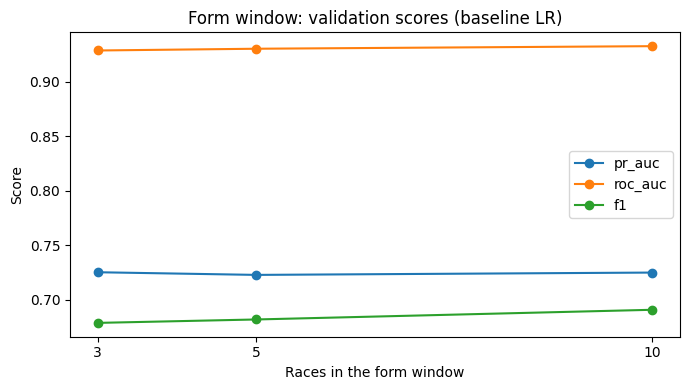

PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/e1_form_window_experiment.csv')

In [36]:
# E1. Form window experiment (validation only)
key_dtypes = {c: history[c].dtype for c in ['raceId', 'driverId', 'constructorId']}
base_tbl = model_table.astype(key_dtypes)
val_keys = part['validation'][KEY].astype('int64').to_numpy()       # row order used by y['validation'] and the bootstrap

window_rows, window_preds = [], {}
for w in [3, 5, 10]:
    t = add_form(base_tbl, history, w)
    feats = [f.replace(f'last{FORM_WINDOW}', f'last{w}') for f in FEATURES]
    tr_ = t[t.split.eq('train')]
    va_ = t[t.split.eq('validation')].sort_values(['date', 'raceId', 'driverId']).reset_index(drop=True)
    assert (va_[KEY].astype('int64').to_numpy() == val_keys).all(), 'validation rows must line up with y[validation]'
    m = make_pipeline(PodiumPreprocessor(feats, **FINAL_PREPROCESSING), LogisticRegression(**BASELINE_PARAMS))
    m.fit(tr_[feats].astype(float), tr_[TARGET].astype(int))
    window_preds[w] = m.predict_proba(va_[feats].astype(float))[:, 1]
    window_rows.append({'window': w, **scores(y['validation'], window_preds[w])})
window_results = pd.DataFrame(window_rows).set_index('window')
display(window_results.round(4))

for w in [3, 10]:
    lo, hi = paired_race_bootstrap(window_preds[5], window_preds[w], average_precision_score)
    d = window_results.loc[w, 'pr_auc'] - window_results.loc[5, 'pr_auc']
    print(f'window {w} minus window 5: PR-AUC {d:+.4f}, 95% race-bootstrap interval [{lo:+.4f}, {hi:+.4f}]'
          f' -> {"real difference" if not (lo <= 0 <= hi) else "equivalent"}')

ax = window_results[['pr_auc', 'roc_auc', 'f1']].plot(marker='o', figsize=(7, 4))
ax.set(title='Form window: validation scores (baseline LR)', xlabel='Races in the form window', ylabel='Score')
ax.set_xticks([3, 5, 10])
figure('e1_form_window')
clean_export(window_results.reset_index(), 'e1_form_window_experiment')

**E1 result.** All three windows score within 0.003 PR-AUC of each other on validation (3: 0.725, 5: 0.723, 10: 0.725), and both differences from the 5-race window have race-bootstrap intervals that include 0 (window 3: [−0.017, +0.020]; window 10: [−0.016, +0.026]). Under the rule fixed in advance, the window stays at **5 races**. The intervals are about ten times wider than the differences, so validation (39 races) cannot separate these choices. The 10-race window is marginally higher on every metric, but not reliably. The form features carry signal whichever window is used, so the model does not depend on this setting.

## E2. Preprocessing-order experiment C: missing flags before vs after imputation
**Question.** The baseline's largest coefficient is `q1_gap_pct_missing` (cell above). Does it matter **when** the missing indicators are created?

- **Flags before imputation (our pipeline):** the indicator records which values were missing, then the gap is filled.
- **Flags after imputation (wrong order):** once values are filled nothing is missing, so every indicator is 0 and the information is lost.

Experiments A and B changed almost nothing because only 1–3.5% of values are missing and fill values barely move. This experiment checks whether the *fact* that a value is missing carries signal that the fill value alone does not.

**Decision rule (fixed before running).** Keep flags-before-imputation if it is at least as good; if the interval of the PR-AUC difference includes 0, report the orders as equivalent and keep the current pipeline, because it loses no information.

,roc_auc,pr_auc,f1,precision,recall
flags before imputation,0.9302,0.7229,0.6820,0.7400,0.6325
flags after imputation,0.9264,0.7170,0.6759,0.7374,0.6239


PR-AUC (before minus after): +0.0059, 95% race-bootstrap interval [+0.0004, +0.0136] -> real difference
Validation rows with at least one missing value: 29 of 778; mean probability change on those rows 0.0152 vs 0.0032 on complete rows


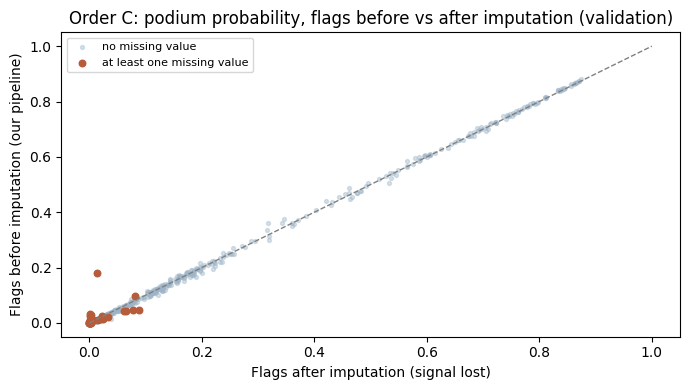

PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/e2_missing_flag_order_experiment.csv')

In [37]:
# E2. Order experiment C: missing-value indicators created before vs after imputation
class FlagsAfterImpute(PodiumPreprocessor):
    """Wrong order on purpose: indicators computed after filling are all 0, so the missing-value signal is lost."""
    def _flags(self, X):
        return pd.DataFrame({f'{f}_missing': 0.0 for f in self.flags_}, index=X.index)

m_before = fit_baseline(**FINAL_PREPROCESSING)
m_after = make_pipeline(FlagsAfterImpute(FEATURES, **FINAL_PREPROCESSING),
                        LogisticRegression(**BASELINE_PARAMS)).fit(X['train'], y['train'])
p_before = m_before.predict_proba(X['validation'])[:, 1]
p_after = m_after.predict_proba(X['validation'])[:, 1]

exp_c = pd.DataFrame({'flags before imputation': scores(y['validation'], p_before),
                      'flags after imputation': scores(y['validation'], p_after)}).T
display(exp_c.round(4))
lo, hi = paired_race_bootstrap(p_after, p_before, average_precision_score)
d = exp_c.loc['flags before imputation', 'pr_auc'] - exp_c.loc['flags after imputation', 'pr_auc']
print(f'PR-AUC (before minus after): {d:+.4f}, 95% race-bootstrap interval [{lo:+.4f}, {hi:+.4f}]'
      f' -> {"real difference" if not (lo <= 0 <= hi) else "equivalent on this data"}')

has_missing = X['validation'][[f for f in MISSING_FLAGS if f in FEATURES]].isna().any(axis=1).to_numpy()
moved = np.abs(p_before - p_after)
print(f'Validation rows with at least one missing value: {int(has_missing.sum())} of {len(has_missing)}; '
      f'mean probability change on those rows {moved[has_missing].mean():.4f} vs {moved[~has_missing].mean():.4f} on complete rows')

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(p_after[~has_missing], p_before[~has_missing], s=8, alpha=0.4, color='#9DB4C8', label='no missing value')
ax.scatter(p_after[has_missing], p_before[has_missing], s=22, color='#B65C3A', label='at least one missing value')
ax.plot([0, 1], [0, 1], color='gray', lw=1, ls='--')
ax.set(title='Order C: podium probability, flags before vs after imputation (validation)',
       xlabel='Flags after imputation (signal lost)', ylabel='Flags before imputation (our pipeline)')
ax.legend(fontsize=8)
figure('e2_missing_flag_order')
clean_export(exp_c.reset_index().rename(columns={'index': 'order'}), 'e2_missing_flag_order_experiment')

**E2 result.** Order matters here. Creating the missing-value flags **before** imputation gives validation PR-AUC 0.723 vs 0.717 when they are created after (difference +0.006, 95% race-bootstrap interval [+0.0004, +0.014], excluding 0); ROC-AUC is 0.930 vs 0.926. The effect sits where expected: the 29 validation rows with a missing value changed probability by 0.015 on average, against 0.003 for complete rows. Filling first erases the information that a value was missing. For `q1_gap_pct` that information marks drivers whose grid slot understates their pace (a qualifying problem rather than a slow car, cell above), so the pipeline keeps **flags before imputation**. The gain is small and its lower bound is close to 0, which is expected when only 3.7% of validation rows have a missing value.

**Summary of the three order experiments:** A (log vs fill) and B (clip vs fill) are equivalent because few values are missing and the fill values barely change; C (missing flags vs fill) shows a real difference because it decides whether the missingness signal survives.

# Modeling
**Protocol (fixed before any model is trained):**
- Every model uses the **same rows, the same 22 features and the same fitted preprocessing**, so scores are directly comparable.
- Every model is **fitted on training rows (2003–2019)** and compared on **validation (2020–2021)**. Hyperparameters, early stopping and decision thresholds are chosen on validation only.
- **The test set (2022–2024) is not used in this section.** It is scored once, after all choices are frozen.
- **Primary metric: PR-AUC** (podiums are a 15% minority, and PR-AUC rewards ranking the true podium finishers on top). **Secondary: ROC-AUC** (overall separation). F1, precision and recall are reported at a threshold. In this section that is 0.5; in M4 it becomes each model's validation-chosen threshold.
- Every attempt is kept in an attempts table, so all trials stay visible, as the brief requires.

## M1. Statistical baseline: logistic regression
**How it works.** Logistic regression gives each of the 27 preprocessed inputs a weight. A driver's score is the weighted sum of their inputs, and the logistic function turns that score into a podium probability between 0 and 1. The weights are fitted on the training rows by minimising log-loss, with an L2 penalty (strength `1/C`) that shrinks weights to stop the model fitting noise.
**Why it is the baseline.** It is the simplest reasonable statistical model for a yes/no target. It needs no tuning beyond `C`, its coefficients can be read directly, and the brief asks for a statistical model or shallow network as the reference that more complex models must beat.
**Attempts in this family (4).** C = 1 (baseline), C = 0.1 and C = 0.01 (stronger regularisation), and `class_weight='balanced'` (to test the class-imbalance handling, P3).
**Limitations.** It assumes each feature moves the log-odds in a straight line, with no interactions unless they are built as features. The podium rate drops steeply over the first grid slots and then flattens (FE1 plot), and a linear model only approximates that shape. When features are strongly correlated (rank and points share, grid and qualifying gap), the weight is split between them, so an individual coefficient's sign or size is not a stand-alone importance measure.


In [38]:
# M1. Attempts log + logistic regression family (baseline and variants)
import copy
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss, precision_recall_curve, roc_curve

ATTEMPTS = []
def record_attempt(name, family, params, model, note=''):
    p_tr = model.predict_proba(X['train'])[:, 1]
    p_va = model.predict_proba(X['validation'])[:, 1]
    ATTEMPTS.append({'attempt': name, 'family': family, 'params': str(params), 'note': note, 'model': model,
                     **{f'train_{k}': v for k, v in scores(y['train'], p_tr).items()},
                     **{f'val_{k}': v for k, v in scores(y['validation'], p_va).items()}})

def show_attempts(family=None):
    t = pd.DataFrame(ATTEMPTS).drop(columns='model')
    if family: t = t[t.family.eq(family)]
    display(t[['attempt', 'params', 'note', 'train_pr_auc', 'val_pr_auc', 'val_roc_auc',
               'val_f1', 'val_precision', 'val_recall']].round(4))

def lr_pipeline(**lr_params):
    return make_pipeline(PodiumPreprocessor(FEATURES, **FINAL_PREPROCESSING), LogisticRegression(**lr_params))

record_attempt('LR baseline (C=1)', 'logistic regression', BASELINE_PARAMS, baseline, 'plain L2')
for C_ in [0.1, 0.01]:
    m = lr_pipeline(C=C_, max_iter=5000).fit(X['train'], y['train'])
    record_attempt(f'LR C={C_}', 'logistic regression', {'C': C_}, m, 'stronger L2 regularisation')
m = lr_pipeline(class_weight='balanced', **BASELINE_PARAMS).fit(X['train'], y['train'])
record_attempt('LR balanced', 'logistic regression', {'C': 1.0, 'class_weight': 'balanced'}, m,
               'podium rows weighted ~6x; F1 at 0.5 not comparable until thresholds are tuned (M4)')
show_attempts('logistic regression')

,attempt,params,note,train_pr_auc,val_pr_auc,val_roc_auc,val_f1,val_precision,val_recall
0,LR baseline (C=1),"{'C': 1.0, 'max_iter': 5000}",plain L2,0.6960,0.7229,0.9302,0.6820,0.7400,0.6325
1,LR C=0.1,{'C': 0.1},stronger L2 regularisation,0.6928,0.7178,0.9293,0.6759,0.7374,0.6239
2,LR C=0.01,{'C': 0.01},stronger L2 regularisation,0.6723,0.6895,0.9224,0.6542,0.7216,0.5983
3,LR balanced,"{'C': 1.0, 'class_weight': 'balanced'}",podium rows weighted ~6x; F1 at 0.5 not compar...,0.6842,0.7191,0.9275,0.6355,0.5000,0.8718


## M2. Second model family: gradient boosting
**How it works.** Gradient boosting builds hundreds of small decision trees one after another; each new tree corrects the errors the previous trees still make. Unlike logistic regression it can learn **non-linear effects and interactions** without them being specified, for example that a strong team's form matters more from the front rows than from the back.
**Why this model.** Logistic regression assumes each feature shifts podium odds in a straight line. Grid position clearly does not: the podium rate drops steeply over the first few slots and then flattens (FE1 plot). Boosting can capture that shape directly.
**Settings tried (4).** Learning rate 0.03 vs 0.1 × tree size 7 vs 15 leaves; 300 trees, at least 40 rows per leaf and L2 penalty 1.0 to limit overfitting.
**Limitations.** Less transparent than logistic regression (explained with SHAP later). It can overfit training seasons, so the gap between train and validation scores is watched. Its probabilities are not guaranteed to be well calibrated.

In [39]:
# M2. Gradient boosting (HistGradientBoostingClassifier), 4 settings
for lr_ in [0.03, 0.1]:
    for leaves in [7, 15]:
        params = dict(learning_rate=lr_, max_leaf_nodes=leaves, max_iter=300, min_samples_leaf=40,
                      l2_regularization=1.0, early_stopping=False, random_state=SEED)
        m = make_pipeline(PodiumPreprocessor(FEATURES, **FINAL_PREPROCESSING),
                          HistGradientBoostingClassifier(**params)).fit(X['train'], y['train'])
        record_attempt(f'GB lr={lr_} leaves={leaves}', 'gradient boosting',
                       {'learning_rate': lr_, 'max_leaf_nodes': leaves}, m)
show_attempts('gradient boosting')

,attempt,params,note,train_pr_auc,val_pr_auc,val_roc_auc,val_f1,val_precision,val_recall
4,GB lr=0.03 leaves=7,"{'learning_rate': 0.03, 'max_leaf_nodes': 7}",,0.7785,0.6948,0.9257,0.6847,0.7238,0.6496
5,GB lr=0.03 leaves=15,"{'learning_rate': 0.03, 'max_leaf_nodes': 15}",,0.8610,0.6893,0.9256,0.6697,0.7115,0.6325
6,GB lr=0.1 leaves=7,"{'learning_rate': 0.1, 'max_leaf_nodes': 7}",,0.8811,0.6893,0.9195,0.6540,0.7340,0.5897
7,GB lr=0.1 leaves=15,"{'learning_rate': 0.1, 'max_leaf_nodes': 15}",,0.9830,0.6534,0.9151,0.6197,0.6875,0.5641


## M3. Shallow neural network
**How it works.** A feed-forward network: the 27 preprocessed inputs feed one or two hidden layers of ReLU units, which feed one output giving the podium probability. Weights are learned by the Adam optimiser on mini-batches of 128 rows, minimising log-loss.
**Architectures tried (3).** One hidden layer of 16 units; two hidden layers (32 → 16); the same with a 10× stronger L2 penalty.
**Training control.** The network is trained one epoch at a time. After each epoch, training and validation log-loss are recorded, and the weights with the **lowest validation loss** are kept (early stopping, patience 20 epochs). The loss curves are plotted below as the "performance during training" evidence.
**Limitations.** Needs scaled inputs (provided by the preprocessor). Results vary with the random seed (fixed at 42). It is the least interpretable of the three models, and with ~6,800 training rows it has little room to beat simpler models. Because early stopping watches validation loss, its validation scores are slightly optimistic; the untouched test set is the fair comparison.

,attempt,params,note,train_pr_auc,val_pr_auc,val_roc_auc,val_f1,val_precision,val_recall
8,NN 16,"{'hidden_layer_sizes': (16,), 'alpha': 0.001, ...",stopped after 96 epochs,0.7082,0.7149,0.9232,0.6726,0.6972,0.6496
9,NN 32-16,"{'hidden_layer_sizes': (32, 16), 'alpha': 0.00...",stopped after 60 epochs,0.7356,0.6856,0.9238,0.6852,0.7475,0.6325
10,NN 32-16 strong L2,"{'hidden_layer_sizes': (32, 16), 'alpha': 0.01...",stopped after 58 epochs,0.7340,0.6822,0.9239,0.6852,0.7475,0.6325


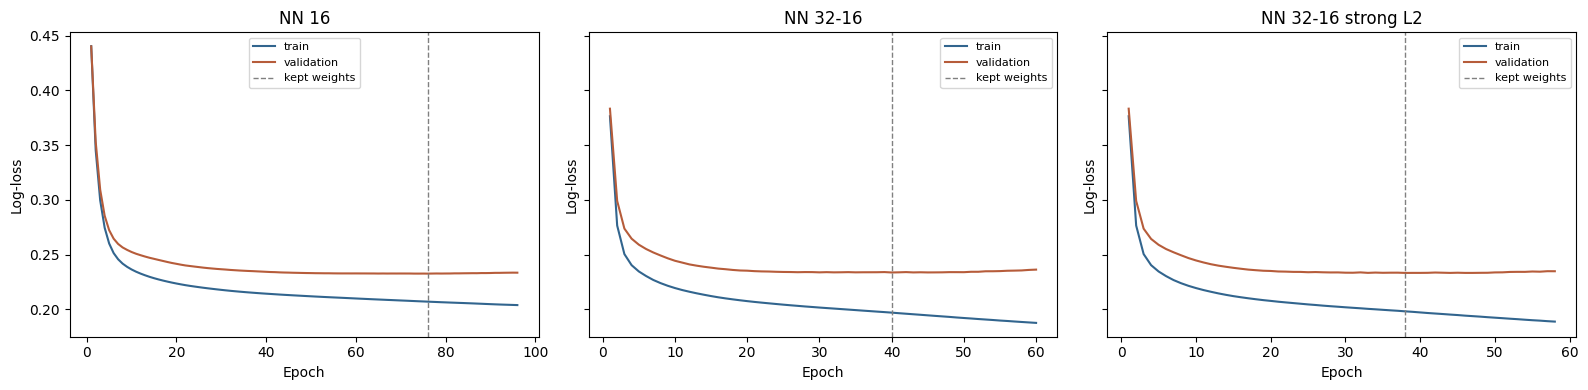

In [40]:
# M3. Shallow neural network (sklearn MLPClassifier), early stopping on validation loss
from sklearn.preprocessing import FunctionTransformer
pre_nn = PodiumPreprocessor(FEATURES, **FINAL_PREPROCESSING).fit(X['train'])
Z_tr = pre_nn.transform(X['train']).to_numpy()
Z_va = pre_nn.transform(X['validation']).to_numpy()

NN_GRID = {'NN 16':           dict(hidden_layer_sizes=(16,),    alpha=1e-3),
           'NN 32-16':        dict(hidden_layer_sizes=(32, 16), alpha=1e-3),
           'NN 32-16 strong L2': dict(hidden_layer_sizes=(32, 16), alpha=1e-2)}
MAX_EPOCHS, PATIENCE = 300, 20
nn_curves = {}
for name, arch in NN_GRID.items():
    net = MLPClassifier(**arch, solver='adam', learning_rate_init=1e-3, batch_size=128, random_state=SEED)
    best_net, best_loss, wait, curve = None, np.inf, 0, []
    for epoch in range(MAX_EPOCHS):
        net.partial_fit(Z_tr, y['train'], classes=[0, 1])          # one pass over the training rows
        tl = log_loss(y['train'], net.predict_proba(Z_tr)[:, 1])
        vl = log_loss(y['validation'], net.predict_proba(Z_va)[:, 1])
        curve.append((tl, vl))
        if vl < best_loss - 1e-5:
            best_net, best_loss, wait = copy.deepcopy(net), vl, 0
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    nn_curves[name] = pd.DataFrame(curve, columns=['train_loss', 'val_loss'])
    best_epoch = int(nn_curves[name].val_loss.idxmin()) + 1
    record_attempt(name, 'neural network', {**arch, 'best_epoch': best_epoch},
                   make_pipeline(pre_nn, FunctionTransformer(np.asarray), best_net), f'stopped after {len(curve)} epochs')
show_attempts('neural network')

fig, axes = plt.subplots(1, len(nn_curves), figsize=(16, 4), sharey=True)
for ax, (name, c) in zip(axes, nn_curves.items()):
    ax.plot(c.index + 1, c.train_loss, label='train', color='#32658E')
    ax.plot(c.index + 1, c.val_loss, label='validation', color='#B65C3A')
    ax.axvline(c.val_loss.idxmin() + 1, color='gray', ls='--', lw=1, label='kept weights')
    ax.set(title=name, xlabel='Epoch', ylabel='Log-loss'); ax.legend(fontsize=8)
figure('m3_nn_loss_curves')

## M4. Decision thresholds and model selection (validation only)
For each family, the attempt with the highest **validation PR-AUC** is kept. Its decision threshold is the value that **maximises F1 on validation**. A 15%-positive problem rarely has its best cutoff at 0.5. The threshold is then frozen and reused unchanged on the test set.

**Reference rule:** “podium if grid position ≤ 3”, the obvious non-ML guess. A model that cannot beat it is not earning its complexity.

**Selection rule:** the final model is the family winner with the highest validation PR-AUC. Each winner is compared with the logistic-regression baseline using the paired race bootstrap; if the interval includes 0, the simpler model is preferred.

,model,split,threshold,roc_auc,pr_auc,f1,precision,recall
0,gradient boosting (GB lr=0.03 leaves=7),train,0.4263,0.9551,0.7785,0.7125,0.7074,0.7177
1,gradient boosting (GB lr=0.03 leaves=7),validation,0.4263,0.9257,0.6948,0.6953,0.6983,0.6923
2,logistic regression (LR baseline (C=1)),train,0.3624,0.9326,0.6960,0.6632,0.6111,0.7250
3,logistic regression (LR baseline (C=1)),validation,0.3624,0.9302,0.7229,0.6949,0.6891,0.7009
4,neural network (NN 16),train,0.3602,0.9410,0.7082,0.6842,0.6137,0.7729
5,neural network (NN 16),validation,0.3602,0.9232,0.7149,0.6964,0.6615,0.7350
6,rule: grid <= 3,train,NaN,0.9095,0.6285,0.6483,0.6486,0.6479
7,rule: grid <= 3,validation,NaN,0.9092,0.6386,0.6923,0.6923,0.6923


gradient boosting minus logistic regression: PR-AUC -0.0281, 95% race-bootstrap interval [-0.0561, +0.0028]
neural network minus logistic regression: PR-AUC -0.0080, 95% race-bootstrap interval [-0.0485, +0.0258]


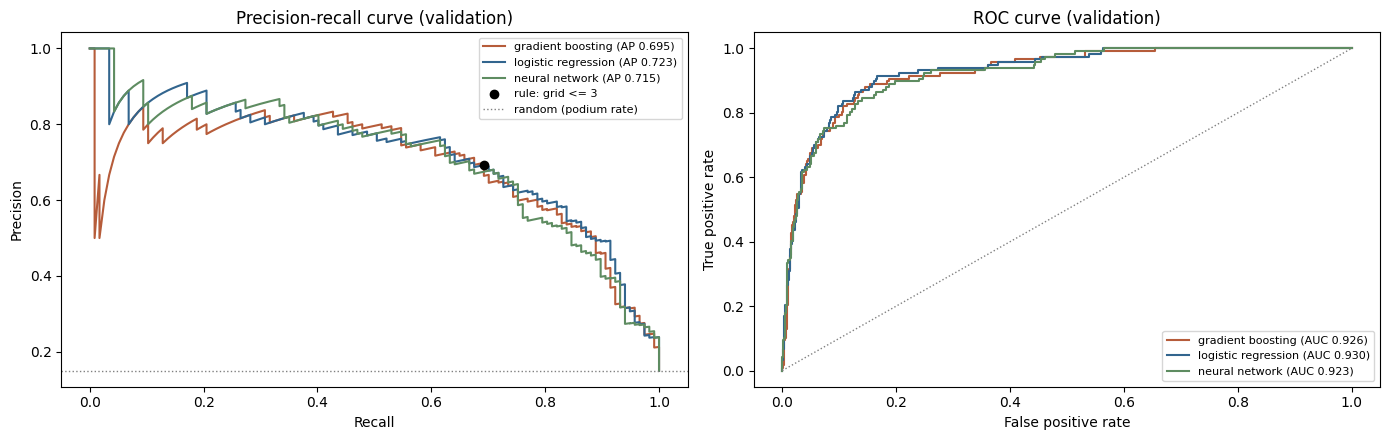

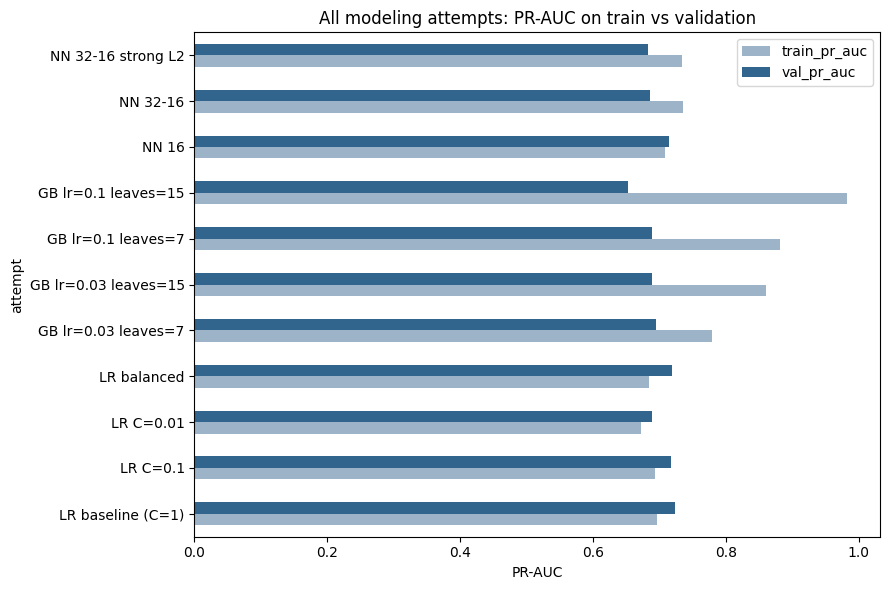

In [41]:
# M4. Family winners, validation-chosen thresholds, comparison with the baseline and the grid rule
att = pd.DataFrame(ATTEMPTS)
winners = att.loc[att.groupby('family').val_pr_auc.idxmax()].set_index('family')
FINALISTS = winners.model.to_dict()

def best_f1_threshold(y_true, p):
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[np.nanargmax(f1)])

THRESHOLDS, PROBS, rows = {}, {}, []
for fam, m in FINALISTS.items():
    PROBS[fam] = {s: m.predict_proba(X[s])[:, 1] for s in ('train', 'validation')}
    THRESHOLDS[fam] = best_f1_threshold(y['validation'], PROBS[fam]['validation'])
    for s in ('train', 'validation'):
        rows.append({'model': f'{fam} ({winners.loc[fam, "attempt"]})', 'split': s, 'threshold': THRESHOLDS[fam],
                     **scores(y[s], PROBS[fam][s], threshold=THRESHOLDS[fam])})
for s in ('train', 'validation'):                  # non-ML rule: score = -grid, podium if grid <= 3
    g = part[s].grid_position.to_numpy().astype(float)
    rows.append({'model': 'rule: grid <= 3', 'split': s, 'threshold': np.nan, **scores(y[s], -g, threshold=-3)})
comparison_val = pd.DataFrame(rows)
display(comparison_val.round(4))

base_p = PROBS['logistic regression']['validation']
for fam in FINALISTS:
    if fam == 'logistic regression': continue
    lo, hi = paired_race_bootstrap(base_p, PROBS[fam]['validation'], average_precision_score)
    d = average_precision_score(y['validation'], PROBS[fam]['validation']) - average_precision_score(y['validation'], base_p)
    print(f'{fam} minus logistic regression: PR-AUC {d:+.4f}, 95% race-bootstrap interval [{lo:+.4f}, {hi:+.4f}]')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
colors = {'logistic regression': '#32658E', 'gradient boosting': '#B65C3A', 'neural network': '#5E8C61'}
for fam in FINALISTS:
    p = PROBS[fam]['validation']
    pr, rc, _ = precision_recall_curve(y['validation'], p); fpr, tpr, _ = roc_curve(y['validation'], p)
    axes[0].plot(rc, pr, color=colors[fam], label=f'{fam} (AP {average_precision_score(y["validation"], p):.3f})')
    axes[1].plot(fpr, tpr, color=colors[fam], label=f'{fam} (AUC {roc_auc_score(y["validation"], p):.3f})')
g = part['validation'].grid_position.to_numpy()
axes[0].scatter(recall_score(y['validation'], g <= 3), precision_score(y['validation'], g <= 3),
                color='black', zorder=5, label='rule: grid <= 3')
axes[0].axhline(y['validation'].mean(), color='gray', ls=':', lw=1, label='random (podium rate)')
axes[1].plot([0, 1], [0, 1], color='gray', ls=':', lw=1)
axes[0].set(title='Precision-recall curve (validation)', xlabel='Recall', ylabel='Precision')
axes[1].set(title='ROC curve (validation)', xlabel='False positive rate', ylabel='True positive rate')
for ax in axes: ax.legend(fontsize=8)
figure('m4_validation_curves')

att_plot = att.set_index('attempt')[['train_pr_auc', 'val_pr_auc']]
ax = att_plot.plot.barh(figsize=(9, 6), color=['#9DB4C8', '#32658E'])
ax.set(title='All modeling attempts: PR-AUC on train vs validation', xlabel='PR-AUC')
figure('m4_all_attempts')

clean_export(att.drop(columns='model'), 'modeling_attempts')
clean_export(comparison_val, 'model_comparison_train_validation')
with open(CLEAN_DIR / 'thresholds.json', 'w') as f:
    json.dump({fam: {'attempt': winners.loc[fam, 'attempt'], 'threshold': THRESHOLDS[fam]} for fam in FINALISTS}, f, indent=2)

## Model selection: results and decision (validation)

| Family | Best attempt | Train PR-AUC | Val PR-AUC | Val ROC-AUC | Threshold | Val F1 | Val precision | Val recall |
|---|---|---|---|---|---|---|---|---|
| Logistic regression | C = 1 (baseline) | 0.696 | **0.723** | **0.930** | 0.36 | 0.695 | 0.689 | 0.701 |
| Gradient boosting | lr 0.03, 7 leaves | 0.779 | 0.695 | 0.926 | 0.43 | 0.695 | 0.698 | 0.692 |
| Neural network | 1 × 16 units | 0.708 | 0.715 | 0.923 | 0.36 | 0.696 | 0.662 | 0.735 |
| Rule: grid ≤ 3 | — | 0.629 | 0.639 | 0.909 | — | 0.692 | 0.692 | 0.692 |

**What the 11 attempts show.**
- *Logistic regression:* stronger regularisation lowers validation PR-AUC (0.723 → 0.718 → 0.690), so the baseline was not overfitting. `class_weight='balanced'` leaves the ranking unchanged (PR-AUC 0.719) and only shifts probabilities upward (recall 0.87, precision 0.50 at 0.5). The imbalance is therefore handled through the validation-chosen threshold rather than through weights.
- *Gradient boosting overfits as complexity grows:* training PR-AUC rises from 0.78 to 0.98 while validation falls from 0.695 to 0.653. The engineered features (rates, gaps, shares) relate to the podium in a mostly smooth, one-directional way that a linear model already captures; the extra flexibility of trees mainly fits season-specific noise.
- *Neural network:* the smallest network is best (0.715); the two-layer networks fit training better and validation worse (0.686, 0.682). Early stopping kept the weights from epochs 76, 40 and 38 and stopped training 20 epochs later, at 96, 60 and 58 (loss curves above).

**Decision.** Neither challenger beats the baseline: boosting − LR = −0.028 PR-AUC (95% race-bootstrap interval [−0.056, +0.003]); network − LR = −0.008 ([−0.049, +0.026]). Under the rule fixed in advance, the **final model is logistic regression**: it scores best, is simplest, and has directly interpretable coefficients. All three family winners are still evaluated on the test set for the required comparison.

**Thresholds** chosen on validation (0.36, 0.43, 0.36) are all below 0.5, as expected with 15% positives; after tuning, F1 is ≈ 0.695 for every model.

**Against the grid rule.** At a single cutoff, “podium if grid ≤ 3” reaches almost the same F1 (0.692): with exactly three podium places per race, the front three on the grid are a strong guess. The models' advantage is in **ranking**: PR-AUC 0.723 vs 0.639 and ROC-AUC 0.930 vs 0.909. They give every driver a probability, including drivers starting further back in strong cars, and allow any precision/recall trade-off. A yes/no rule cannot do either.

# T. Final evaluation on the unseen test set (2022–2024)
Everything is now frozen: the three family winners, their validation-chosen thresholds (0.36 / 0.43 / 0.36) and the preprocessing. The test seasons are scored **once**. Nothing below is tuned or changed after seeing these numbers.

The test set is also a stress test. 2022 introduced the ground-effect rules, which reshuffled the competitive order, so a model trained on 2003–2019 has to cope with teams whose form and standings meant something different under the old rules.

Reported for every model: ROC-AUC, PR-AUC, F1, precision and recall on train, validation and test; PR and ROC curves; confusion matrices at the frozen thresholds; a race-level check (of the three drivers each model ranks highest per race, how many actually finished on the podium); and the final model's scores per test season.

roc_auc                   pr_auc  \
                                          train validation   test  train   
model                                                                      
gradient boosting (GB lr=0.03 leaves=7)   0.955      0.926  0.937  0.779   
logistic regression (LR baseline (C=1))   0.933      0.930  0.936  0.696   
neural network (NN 16)                    0.941      0.923  0.931  0.708   
rule: grid <= 3                           0.909      0.909  0.913  0.629   

                                                              f1             \
                                        validation   test  train validation   
model                                                                         
gradient boosting (GB lr=0.03 leaves=7)      0.695  0.709  0.713      0.695   
logistic regression (LR baseline (C=1))      0.723  0.697  0.663      0.695   
neural network (NN 16)                       0.715  0.680  0.684      0.696   
rule: grid <= 3                              0.639  0.647  0.648      0.692   

                                               precision                    \
                                          test     train validation   test   
model                                                                        
gradient boosting (GB lr=0.03 leaves=7)  0.658     0.707      0.698  0.665   
logistic regression (LR baseline (C=1))  0.667     0.611      0.689  0.617   
neural network (NN 16)                   0.675     0.614      0.662  0.611   
rule: grid <= 3                          0.649     0.649      0.692  0.650   

                                        recall                    
                                         train validation   test  
model                                                             
gradient boosting (GB lr=0.03 leaves=7)  0.718      0.692  0.652  
logistic regression (LR baseline (C=1))  0.725      0.701  0.725  
neural network (NN 16)                   0.773      0.735  0.755  
rule: grid <= 3                          0.648      0.692  0.647

Share of each model's top-3 picks per race that finished on the podium:


,train,validation,test
gradient boosting,71.9,67.5,63.7
logistic regression,64.8,69.2,63.7
neural network,67.4,67.5,61.8
rule: grid <= 3,64.9,69.2,65.2


logistic regression minus gradient boosting (test): PR-AUC -0.0119, 95% race-bootstrap interval [-0.0437, +0.0220]
logistic regression minus neural network (test): PR-AUC +0.0174, 95% race-bootstrap interval [-0.0213, +0.0595]
logistic regression minus rule: grid <= 3 (test): PR-AUC +0.0501, 95% race-bootstrap interval [+0.0035, +0.0973]
Final model (logistic regression) per test season:


,roc_auc,pr_auc,f1,precision,recall,rows
2022,0.946,0.651,0.658,0.590,0.742,439
2023,0.931,0.773,0.704,0.746,0.667,437
2024,0.929,0.666,0.647,0.561,0.764,476


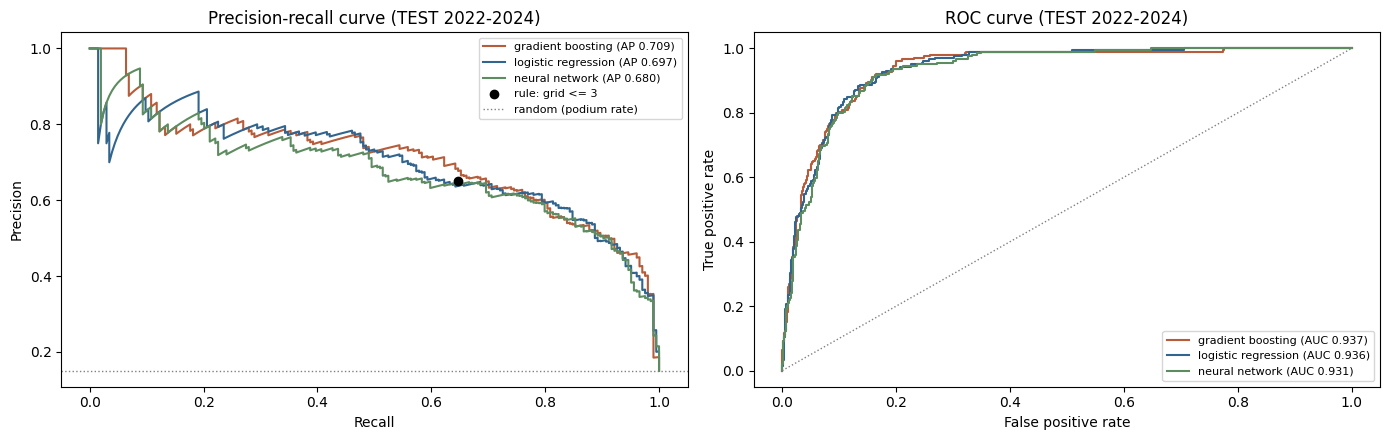

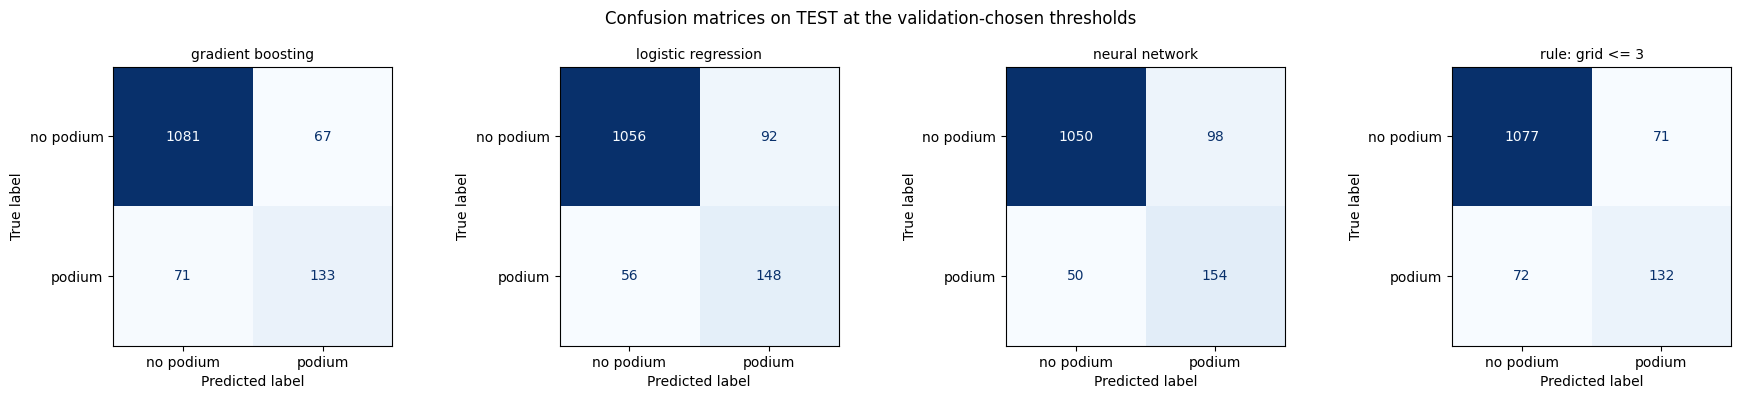

PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/race_level_top3_hit_rate.csv')

In [42]:
# T1. Final test evaluation: models and thresholds frozen in M4
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

FINAL_FAMILY = 'logistic regression'                       # chosen in M4 on validation
FINAL_MODEL, FINAL_THRESHOLD = FINALISTS[FINAL_FAMILY], THRESHOLDS[FINAL_FAMILY]
SPLIT_NAMES = ['train', 'validation', 'test']
metric_cols = ['roc_auc', 'pr_auc', 'f1', 'precision', 'recall']

for fam, m in FINALISTS.items():
    PROBS[fam]['test'] = m.predict_proba(X['test'])[:, 1]
GRID_SCORE = {s: -part[s].grid_position.to_numpy().astype(float) for s in SPLIT_NAMES}   # rule: higher = further forward

# ---- 1. Final comparison table: every model, every split, all five metrics ----
rows = []
for fam in FINALISTS:
    for s in SPLIT_NAMES:
        rows.append({'model': f'{fam} ({winners.loc[fam, "attempt"]})', 'split': s, 'threshold': THRESHOLDS[fam],
                     **scores(y[s], PROBS[fam][s], threshold=THRESHOLDS[fam])})
for s in SPLIT_NAMES:
    rows.append({'model': 'rule: grid <= 3', 'split': s, 'threshold': np.nan, **scores(y[s], GRID_SCORE[s], threshold=-3)})
final_table = pd.DataFrame(rows)
wide = final_table.pivot_table(index='model', columns='split', values=metric_cols)
wide = wide.reindex(columns=pd.MultiIndex.from_product([metric_cols, SPLIT_NAMES]))
display(wide.round(3))

# ---- 2. Race-level check: of each model's top-3 drivers per race, share that reached the podium ----
def top3_hit_rate(split, score):
    d = part[split][['raceId']].assign(score=score, podium=y[split])
    d['rank'] = d.groupby('raceId').score.rank(ascending=False, method='first')
    return d.loc[d['rank'] <= 3, 'podium'].mean()
hits = pd.DataFrame({fam: {s: top3_hit_rate(s, PROBS[fam][s]) for s in SPLIT_NAMES} for fam in FINALISTS})
hits['rule: grid <= 3'] = {s: top3_hit_rate(s, GRID_SCORE[s]) for s in SPLIT_NAMES}
print('Share of each model\'s top-3 picks per race that finished on the podium:')
display((100 * hits.T).round(1))

# ---- 3. Is the final model better than the alternatives on test? (paired race bootstrap) ----
def race_bootstrap_diff(split, p_a, p_b, metric, n_boot=2000, seed=0):
    races = part[split].raceId.to_numpy(); ids = np.unique(races)
    rows_of = {r: np.flatnonzero(races == r) for r in ids}
    rng, diffs = np.random.default_rng(seed), np.empty(n_boot)
    for i in range(n_boot):
        idx = np.concatenate([rows_of[r] for r in rng.choice(ids, size=len(ids), replace=True)])
        diffs[i] = metric(y[split][idx], p_b[idx]) - metric(y[split][idx], p_a[idx])
    return np.percentile(diffs, [2.5, 97.5])
p_final = PROBS[FINAL_FAMILY]['test']
for name, p_other in [*((f, PROBS[f]['test']) for f in FINALISTS if f != FINAL_FAMILY), ('rule: grid <= 3', GRID_SCORE['test'])]:
    lo, hi = race_bootstrap_diff('test', p_other, p_final, average_precision_score)
    d = average_precision_score(y['test'], p_final) - average_precision_score(y['test'], p_other)
    print(f'{FINAL_FAMILY} minus {name} (test): PR-AUC {d:+.4f}, 95% race-bootstrap interval [{lo:+.4f}, {hi:+.4f}]')

# ---- 4. Final model per test season (era sensitivity) ----
season = part['test'].year.to_numpy()
per_season = pd.DataFrame({yr: scores(y['test'][season == yr], p_final[season == yr], threshold=FINAL_THRESHOLD)
                           for yr in np.unique(season)}).T
per_season['rows'] = pd.Series(season).value_counts().sort_index().to_numpy()
print(f'Final model ({FINAL_FAMILY}) per test season:')
display(per_season.round(3))

# ---- 5. Plots: PR and ROC curves on test; confusion matrices at the frozen thresholds ----
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for fam in FINALISTS:
    p = PROBS[fam]['test']
    pr, rc, _ = precision_recall_curve(y['test'], p); fpr, tpr, _ = roc_curve(y['test'], p)
    axes[0].plot(rc, pr, color=colors[fam], label=f'{fam} (AP {average_precision_score(y["test"], p):.3f})')
    axes[1].plot(fpr, tpr, color=colors[fam], label=f'{fam} (AUC {roc_auc_score(y["test"], p):.3f})')
g = part['test'].grid_position.to_numpy()
axes[0].scatter(recall_score(y['test'], g <= 3), precision_score(y['test'], g <= 3), color='black', zorder=5, label='rule: grid <= 3')
axes[0].axhline(y['test'].mean(), color='gray', ls=':', lw=1, label='random (podium rate)')
axes[1].plot([0, 1], [0, 1], color='gray', ls=':', lw=1)
axes[0].set(title='Precision-recall curve (TEST 2022-2024)', xlabel='Recall', ylabel='Precision')
axes[1].set(title='ROC curve (TEST 2022-2024)', xlabel='False positive rate', ylabel='True positive rate')
for ax in axes: ax.legend(fontsize=8)
figure('t1_test_curves')

panels = [(fam, (PROBS[fam]['test'] >= THRESHOLDS[fam]).astype(int)) for fam in FINALISTS] + [('rule: grid <= 3', (g <= 3).astype(int))]
fig, axes = plt.subplots(1, len(panels), figsize=(18, 4))
for ax, (name, pred) in zip(axes, panels):
    ConfusionMatrixDisplay(confusion_matrix(y['test'], pred), display_labels=['no podium', 'podium']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=10)
fig.suptitle('Confusion matrices on TEST at the validation-chosen thresholds')
figure('t1_test_confusion')

clean_export(final_table, 'final_model_comparison_all_splits')
clean_export(per_season.reset_index().rename(columns={'index': 'season'}), 'final_model_per_test_season')
clean_export(hits.T.reset_index().rename(columns={'index': 'model'}), 'race_level_top3_hit_rate')

## Test results (2022–2024, scored once)
| Model | Train PR-AUC | Val PR-AUC | **Test PR-AUC** | Test ROC-AUC | Test F1 | Test precision | Test recall |
|---|---|---|---|---|---|---|---|
| **Logistic regression (final)** | 0.696 | 0.723 | **0.697** | 0.936 | 0.667 | 0.617 | 0.725 |
| Gradient boosting | 0.779 | 0.695 | 0.709 | 0.937 | 0.658 | 0.665 | 0.652 |
| Neural network | 0.708 | 0.715 | 0.680 | 0.931 | 0.675 | 0.611 | 0.755 |
| Rule: grid ≤ 3 | 0.629 | 0.639 | 0.647 | 0.913 | 0.649 | 0.650 | 0.647 |

**Generalisation.** The final model's PR-AUC is almost identical on train (0.696) and test (0.697): no sign of overfitting. Gradient boosting falls from 0.779 on train to 0.709 on test, confirming the overfitting seen in M2.

**Model choice stands.** Boosting scores slightly higher on test (+0.012), but the race-bootstrap interval of the difference includes 0 ([−0.044, +0.022]), and the choice was made on validation. Switching models after seeing test scores would turn the test set into a second validation set, so the validation decision is kept. The neural network is also within noise (logistic regression − network: +0.017, [−0.021, +0.060]).

**Against the grid rule.** On test, the final model's PR-AUC beats “podium if grid ≤ 3” by +0.050 (95% interval [+0.004, +0.097], excluding 0). **But at race level the rule is as good:** of each method's top three drivers per race, 65.2% (rule) vs 63.7% (logistic regression) reached the podium, about two of three places either way. The model's added value is ranking the whole field with probabilities (for example, midfield starters in strong cars), not choosing the three podium finishers better than the grid does. This is a limitation of the feature set: what the grid already says about the front of the field is hard to improve on with pre-race information.

**Era sensitivity.** Test PR-AUC by season: 2022 = 0.651, 2023 = 0.773, 2024 = 0.666, with ROC-AUC 0.93–0.95 in every season. 2022 brought new technical rules that reshuffled the competitive order, so form and standings carried over from 2021 were misleading early in the season. 2023 was dominated by a single team and was the most predictable. 2024 was the most open season of the three. The model separates likely from unlikely podium finishers consistently; it struggles most when the competitive order changes.

**Threshold drift.** At the frozen validation threshold (0.36), test recall stays high (0.725) but precision falls (0.689 → 0.617): the model raises more false alarms in the new seasons, as expected when a threshold is carried from one period to another.

# A. Feature-group ablation
**Question.** How much does each feature group actually contribute to the final model?
**Method.** One group at a time is **removed** (its features are replaced by a constant, so they carry no information while the pipeline stays identical), and logistic regression is retrained with everything else unchanged. The drop in validation PR-AUC measures that group's contribution; a paired race bootstrap shows whether the drop is larger than chance. Test drops are shown for information only. One extra run keeps **only** the grid group, to measure how much the model adds beyond the starting position.
**How to read it.** EDA justified each feature *before* training; the ablation measures its contribution *after* training. Groups overlap (grid and qualifying, standings and form), so removing one lets the others partly compensate. A small drop can mean “shared information”, not “useless”.

Full model: validation PR-AUC 0.7229, test PR-AUC 0.6975


,features_removed,val_pr_auc,val_drop,drop_ci_low,drop_ci_high,val_roc_auc,test_pr_auc,test_drop,real_drop
run,,,,,,,,,
without grid,3,0.6363,0.0866,0.0506,0.1107,0.9013,0.6153,0.0822,True
without qualifying,3,0.7140,0.0089,-0.0078,0.0271,0.9244,0.6923,0.0051,False
without driver_form,5,0.7201,0.0028,-0.0133,0.0195,0.9304,0.6964,0.0011,False
without constructor_form,4,0.7247,-0.0018,-0.0149,0.0106,0.9314,0.7031,-0.0057,False
without standings,6,0.7150,0.0079,-0.0077,0.0228,0.9280,0.7034,-0.0060,False
without context,1,0.7253,-0.0024,-0.0066,0.0002,0.9301,0.6978,-0.0003,False
only grid kept,19,0.6403,0.0826,0.0277,0.1407,0.9088,0.6473,0.0501,True


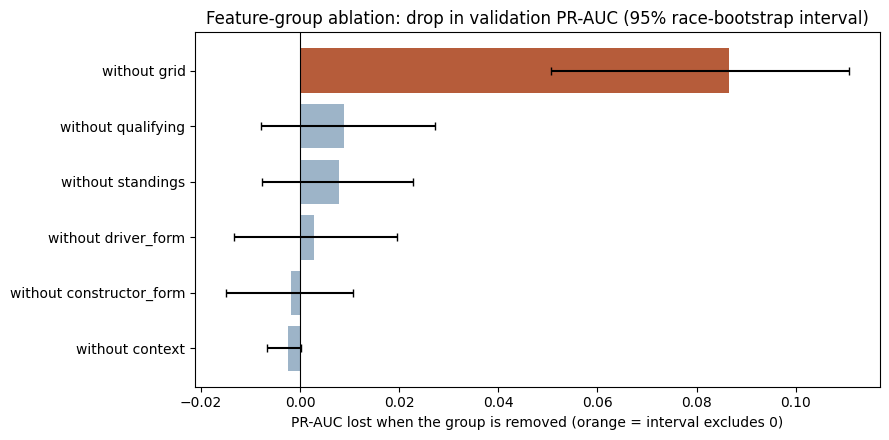

PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/feature_group_ablation.csv')

In [43]:
# A1. Feature-group ablation on the final model (logistic regression)
GROUPS = feature_spec['groups']
full_p = {s: PROBS[FINAL_FAMILY][s] for s in ('validation', 'test')}
full_ap = {s: average_precision_score(y[s], full_p[s]) for s in full_p}

def neutralise(Xs, cols):
    Xn = Xs.copy(); Xn[cols] = 0.0          # constant column = no information; flags stay 0, scaling stays defined
    return Xn

def ablated_probs(cols):
    m = lr_pipeline(**BASELINE_PARAMS).fit(neutralise(X['train'], cols), y['train'])
    return {s: m.predict_proba(neutralise(X[s], cols))[:, 1] for s in ('validation', 'test')}

runs = {f'without {g}': cols for g, cols in GROUPS.items()}
runs['only grid kept'] = [f for f in FEATURES if f not in GROUPS['grid']]
rows = []
for name, cols in runs.items():
    p = ablated_probs(cols)
    lo, hi = race_bootstrap_diff('validation', p['validation'], full_p['validation'], average_precision_score)
    rows.append({'run': name, 'features_removed': len(cols),
                 'val_pr_auc': average_precision_score(y['validation'], p['validation']),
                 'val_drop': full_ap['validation'] - average_precision_score(y['validation'], p['validation']),
                 'drop_ci_low': lo, 'drop_ci_high': hi,
                 'val_roc_auc': roc_auc_score(y['validation'], p['validation']),
                 'test_pr_auc': average_precision_score(y['test'], p['test']),
                 'test_drop': full_ap['test'] - average_precision_score(y['test'], p['test'])})
ablation = pd.DataFrame(rows).set_index('run')
ablation['real_drop'] = ablation.drop_ci_low.gt(0)
print(f'Full model: validation PR-AUC {full_ap["validation"]:.4f}, test PR-AUC {full_ap["test"]:.4f}')
display(ablation.round(4))

a = ablation.drop(index='only grid kept').sort_values('val_drop')
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(a.index, a.val_drop, color=np.where(a.real_drop, '#B65C3A', '#9DB4C8'),
        xerr=[a.val_drop - a.drop_ci_low, a.drop_ci_high - a.val_drop], capsize=3)
ax.axvline(0, color='black', lw=0.8)
ax.set(title='Feature-group ablation: drop in validation PR-AUC (95% race-bootstrap interval)',
       xlabel='PR-AUC lost when the group is removed (orange = interval excludes 0)')
figure('a1_feature_group_ablation')
clean_export(ablation.reset_index(), 'feature_group_ablation')

In [44]:
# A2. Removing overlapping groups together (do they share the same information?)
combo_runs = {
    'without all history (driver form + constructor form + standings)':
        GROUPS['driver_form'] + GROUPS['constructor_form'] + GROUPS['standings'],
    'without qualifying + all history (grid and context only)':
        GROUPS['qualifying'] + GROUPS['driver_form'] + GROUPS['constructor_form'] + GROUPS['standings'],
}
rows = []
for name, cols in combo_runs.items():
    p = ablated_probs(cols)
    lo, hi = race_bootstrap_diff('validation', p['validation'], full_p['validation'], average_precision_score)
    rows.append({'run': name, 'features_removed': len(cols),
                 'val_pr_auc': average_precision_score(y['validation'], p['validation']),
                 'val_drop': full_ap['validation'] - average_precision_score(y['validation'], p['validation']),
                 'drop_ci_low': lo, 'drop_ci_high': hi,
                 'test_drop': full_ap['test'] - average_precision_score(y['test'], p['test'])})
combo = pd.DataFrame(rows).set_index('run')
display(combo.round(4))
clean_export(combo.reset_index(), 'feature_group_ablation_combined')

,features_removed,val_pr_auc,val_drop,drop_ci_low,drop_ci_high,test_drop
run,,,,,,
without all history (driver form + constructor form + standings),15,0.7093,0.0136,-0.0326,0.0687,0.0242
without qualifying + all history (grid and context only),18,0.6405,0.0823,0.0296,0.1388,0.0461


PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/feature_group_ablation_combined.csv')

**Ablation result.**
- **Starting position is indispensable:** removing the three grid features costs 0.087 validation PR-AUC (95% race-bootstrap interval [0.051, 0.111]) and 0.082 on test. It is the only group whose individual removal is clearly harmful, as the EDA suggested (Spearman −0.50 with podium). Note what this run removes: `quali_position` was dropped in FE4 as an exact formula (`grid_position − grid_minus_quali`), so without `grid_position` the model loses the qualifying position as well; the remaining qualifying features (Q1 gaps, grid − qualifying) cannot rebuild either position. The 0.087 drop is therefore the value of knowing *where the driver starts and qualified*, not of the grid alone.
- **Every other group, removed alone, changes PR-AUC by less than 0.01** (all intervals include 0). This does not make them useless: they **overlap**. Qualifying pace largely repeats grid position, and driver form, constructor form and standings all describe recent driver and car strength, so when one group is removed the others carry the same signal.
- **Together they matter:** keeping only the grid features costs 0.083 validation PR-AUC (interval [0.028, 0.141]) and 0.050 on test. The non-grid features jointly add about 0.08 PR-AUC beyond the starting position, which is the model's whole advantage over the grid rule.
- **`home_race` adds nothing** (−0.002, interval [−0.007, 0.000]), consistent with Question 2, where no home advantage remained after controlling for grid position. It is kept only because it costs nothing; a leaner model could drop it.
- Removing constructor form slightly raises validation PR-AUC (−0.002), which is within noise.

**Before vs after training.** The EDA predicted that grid, qualifying, form and standings would each relate strongly to podiums (Spearman ≈ 0.4–0.5), and they do individually. The ablation shows that, once the model has the grid, most of that signal is shared between groups rather than additive.

# X. Explainability (final model: logistic regression)
- **Global, permutation importance:** on validation, shuffle one feature (or one whole group) at a time and measure how much PR-AUC falls. A large fall means the model relies on that feature. Groups are also shuffled together, because correlated features (grid and qualifying, rank and points share) can cover for each other when shuffled alone.
- **Global, SHAP:** for every validation driver, how much each feature pushed the predicted podium probability up or down from the average prediction. The beeswarm shows direction and spread; the bar chart shows average size.
- **Local:** one test driver explained two ways: a SHAP waterfall (exact contributions adding up to the prediction) and LIME (a simple model fitted around that single driver).

**Important: these explanations are not causal.** A feature being important means the *model relies on it* to predict, not that it *causes* podiums. Grid position is the most important feature because fast cars both qualify at the front and finish at the front; the model uses the grid as a summary of car and driver speed. Moving a car up the grid would not by itself produce the podium probability the model shows.

,mean_pr_auc_drop,sd,group
grid_position,0.3206,0.0399,grid
q1_gap_pct,0.0331,0.0156,qualifying
driver_avg_finish_rel_last5,0.0236,0.0183,driver_form
constructor_podium_rate_last5,0.0149,0.0099,constructor_form
driver_finish_rate_last5,0.0130,0.0112,driver_form
constructor_best_finish_rel_last5,0.0106,0.0161,constructor_form
driver_podium_rate_last5,0.0094,0.0173,driver_form
grid_minus_quali,0.0088,0.0166,qualifying
pit_lane_start,0.0041,0.0049,grid
constructor_points_share,0.0037,0.0148,standings


,mean_pr_auc_drop,sd
grid,0.3459,0.0271
driver_form,0.0750,0.0289
standings,0.0432,0.0204
qualifying,0.0429,0.0221
constructor_form,0.0114,0.0152
context,-0.0025,0.0030


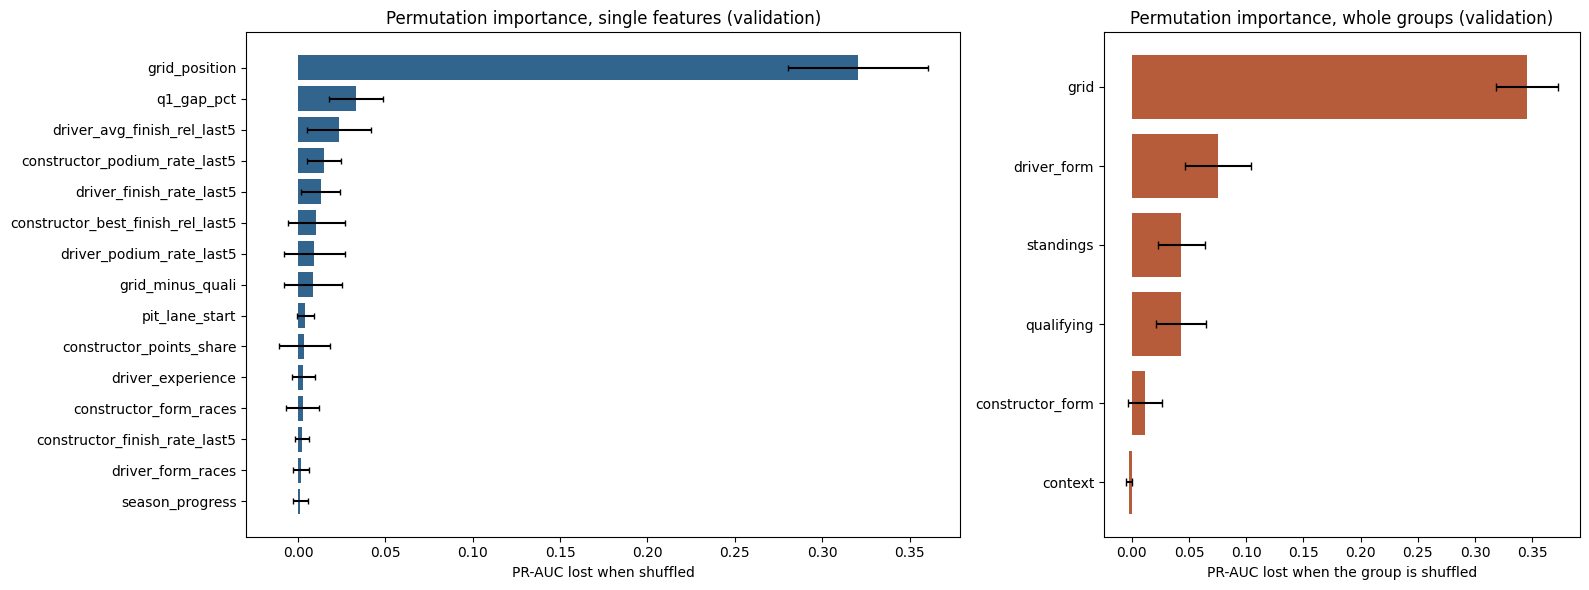

PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/xai_group_permutation_importance.csv')

In [45]:
# X1. Permutation importance on VALIDATION: single features and whole groups
from sklearn.inspection import permutation_importance
import importlib, subprocess
for _pkg in ('shap', 'lime'):                       # install only if missing (needs Kaggle Internet ON)
    try:
        importlib.import_module(_pkg)
    except ImportError:
        print(f'{_pkg} missing: installing it now'); subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', _pkg], check=True)
import shap
import lime, lime.lime_tabular

pi = permutation_importance(FINAL_MODEL, X['validation'], y['validation'], scoring='average_precision',
                            n_repeats=20, random_state=SEED)
perm = pd.DataFrame({'mean_pr_auc_drop': pi.importances_mean, 'sd': pi.importances_std}, index=FEATURES)
perm['group'] = [next(g for g, cs in GROUPS.items() if f in cs) for f in FEATURES]
perm = perm.sort_values('mean_pr_auc_drop', ascending=False)
display(perm.round(4))

def group_permutation(model, Xs, ys, groups, n_repeats=20, seed=SEED):
    rng = np.random.default_rng(seed)
    base = average_precision_score(ys, model.predict_proba(Xs)[:, 1])
    out = {}
    for g, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = Xs.copy()
            Xp[cols] = Xs[cols].to_numpy()[rng.permutation(len(Xs))]     # shuffle the whole group together
            drops.append(base - average_precision_score(ys, model.predict_proba(Xp)[:, 1]))
        out[g] = {'mean_pr_auc_drop': np.mean(drops), 'sd': np.std(drops)}
    return pd.DataFrame(out).T.sort_values('mean_pr_auc_drop', ascending=False)
group_perm = group_permutation(FINAL_MODEL, X['validation'], y['validation'], GROUPS)
display(group_perm.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [3, 2]})
top = perm.head(15).iloc[::-1]
axes[0].barh(top.index, top.mean_pr_auc_drop, xerr=top.sd, color='#32658E', capsize=2)
axes[0].set(title='Permutation importance, single features (validation)', xlabel='PR-AUC lost when shuffled')
gp = group_perm.iloc[::-1]
axes[1].barh(gp.index, gp.mean_pr_auc_drop, xerr=gp.sd, color='#B65C3A', capsize=3)
axes[1].set(title='Permutation importance, whole groups (validation)', xlabel='PR-AUC lost when the group is shuffled')
figure('x1_permutation_importance')
clean_export(perm.reset_index().rename(columns={'index': 'feature'}), 'xai_permutation_importance')
clean_export(group_perm.reset_index().rename(columns={'index': 'group'}), 'xai_group_permutation_importance')

PermutationExplainer explainer: 779it [02:10,  5.87it/s]


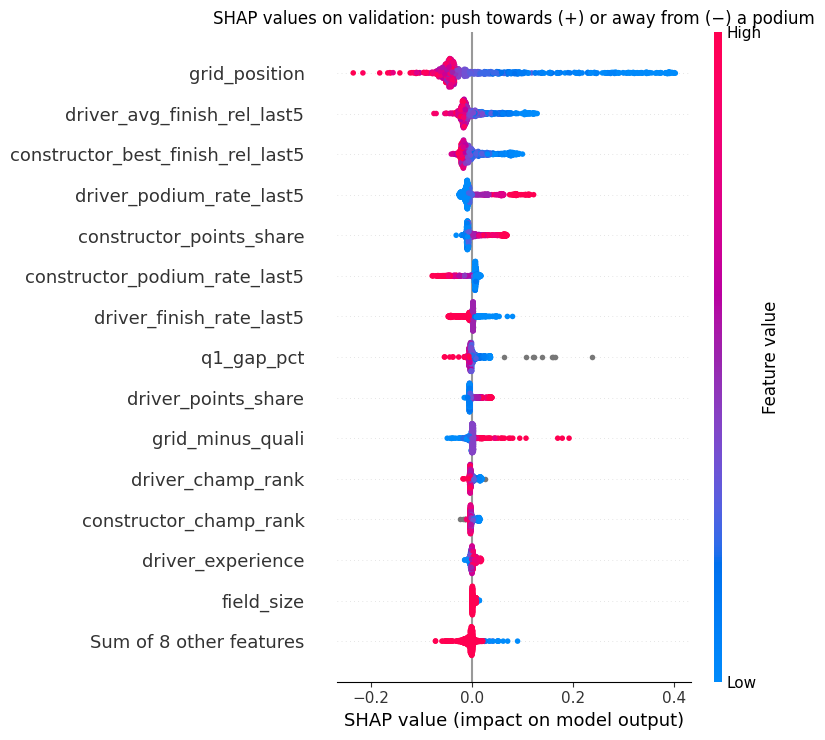

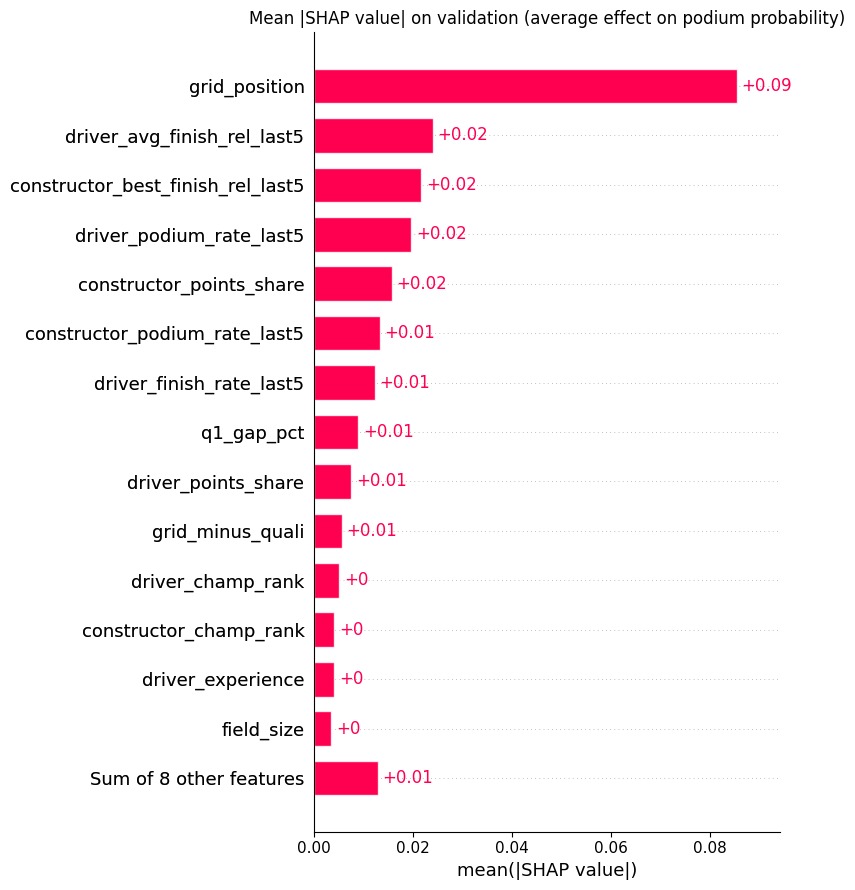

,mean_abs_shap,shap_rank,mean_pr_auc_drop,perm_rank
grid_position,0.0854,1,0.3206,1
driver_avg_finish_rel_last5,0.0239,2,0.0236,3
constructor_best_finish_rel_last5,0.0216,3,0.0106,6
driver_podium_rate_last5,0.0195,4,0.0094,7
constructor_points_share,0.0156,5,0.0037,10
constructor_podium_rate_last5,0.0132,6,0.0149,4
driver_finish_rate_last5,0.0122,7,0.0130,5
q1_gap_pct,0.0089,8,0.0331,2
driver_points_share,0.0075,9,0.0002,17
grid_minus_quali,0.0055,10,0.0088,8


PosixPath('/kaggle/working/f1_audit/runs/20261018T184719_144775Z_825f42/cleaning/xai_shap_vs_permutation.csv')

In [46]:
# X2. SHAP on validation: contribution of each raw feature to each driver's podium probability
predict_podium_proba = lambda a: FINAL_MODEL.predict_proba(pd.DataFrame(a, columns=FEATURES))[:, 1]
background = X['train'].sample(100, random_state=SEED)                      # reference drivers from TRAINING only
shap_explainer = shap.Explainer(predict_podium_proba, shap.maskers.Independent(background), feature_names=FEATURES)

np.random.seed(SEED)
sv_val = shap_explainer(X['validation'])

shap.plots.beeswarm(sv_val, max_display=15, show=False)
plt.title('SHAP values on validation: push towards (+) or away from (−) a podium')
figure('x2_shap_beeswarm')
shap.plots.bar(sv_val, max_display=15, show=False)
plt.title('Mean |SHAP value| on validation (average effect on podium probability)')
figure('x2_shap_bar')

shap_rank = pd.Series(np.abs(sv_val.values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
compare = pd.DataFrame({'mean_abs_shap': shap_rank, 'shap_rank': np.arange(1, len(shap_rank) + 1)}).join(
          perm[['mean_pr_auc_drop']].assign(perm_rank=np.arange(1, len(perm) + 1)))
display(compare.head(12).round(4))
clean_export(compare.reset_index().rename(columns={'index': 'feature'}), 'xai_shap_vs_permutation')

Case: Max Verstappen, 2023 Belgian Grand Prix; started P6, finished on the podium. Predicted podium probability 0.781 (threshold 0.36 -> predicted podium).


,feature value
grid_position,6.000000
pit_lane_start,0.000000
field_size,20.000000
q1_gap_pct,0.181741
q1_gap_to_teammate_pct,-0.322963
grid_minus_quali,5.000000
driver_podium_rate_last5,1.000000
driver_avg_finish_rel_last5,0.050000
driver_finish_rate_last5,1.000000
driver_form_races,5.000000


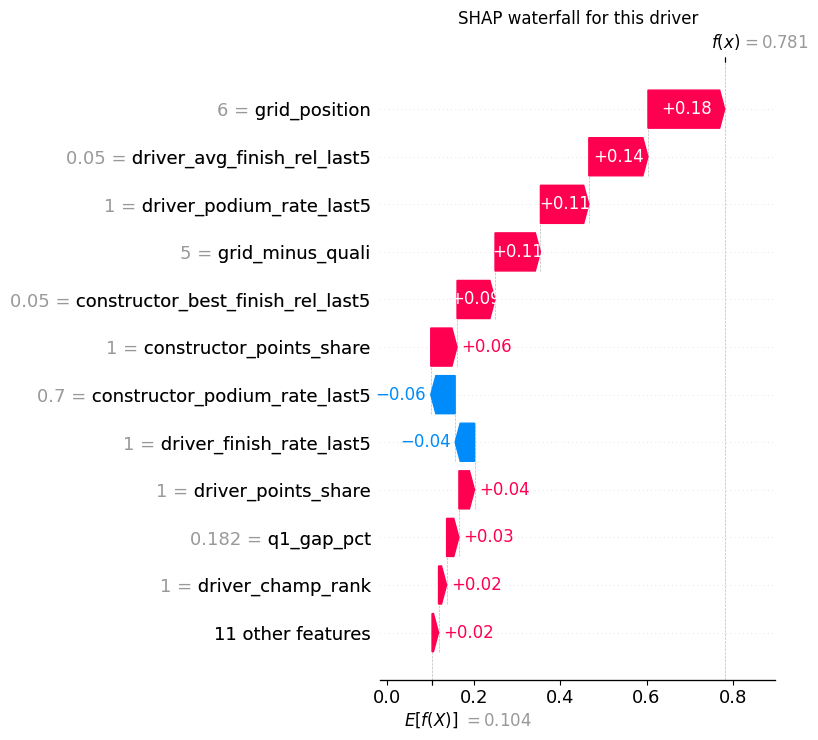

SHAP contributions for this driver (largest first):


,SHAP value
grid_position,0.178
driver_avg_finish_rel_last5,0.137
driver_podium_rate_last5,0.112
grid_minus_quali,0.105
constructor_best_finish_rel_last5,0.088
constructor_points_share,0.061
constructor_podium_rate_last5,-0.056
driver_finish_rate_last5,-0.045


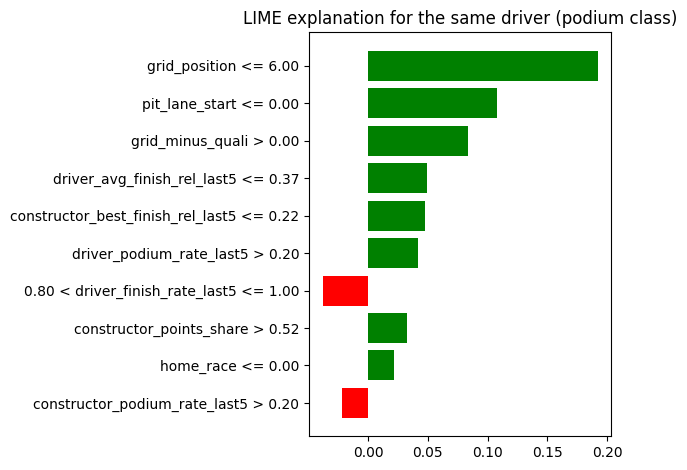

,condition,weight towards podium
0,grid_position <= 6.00,0.1919
1,pit_lane_start <= 0.00,0.1074
2,grid_minus_quali > 0.00,0.0839
3,driver_avg_finish_rel_last5 <= 0.37,0.0489
4,constructor_best_finish_rel_last5 <= 0.22,0.0477
5,driver_podium_rate_last5 > 0.20,0.0417
6,0.80 < driver_finish_rate_last5 <= 1.00,-0.0379
7,constructor_points_share > 0.52,0.0322
8,home_race <= 0.00,0.0220
9,constructor_podium_rate_last5 > 0.20,-0.0216


In [47]:
# X3. Local explanation for one TEST driver: a podium from P6 or further back that the model rated highest
info = part['test'][['raceId', 'driverId', 'year', 'grid_position']].copy()
info['p_podium'] = PROBS[FINAL_FAMILY]['test']; info['podium'] = y['test']
names_lookup = analysis_base[['raceId', 'driverId', 'race_name', 'driver_forename', 'driver_surname']].astype({'raceId': 'int64', 'driverId': 'int64'})
info = info.astype({'raceId': 'int64', 'driverId': 'int64'}).merge(names_lookup, on=['raceId', 'driverId'], how='left')
case = info[(info.podium == 1) & (info.grid_position >= 6)].sort_values('p_podium', ascending=False).iloc[0]
i = int(case.name)
print(f"Case: {case.driver_forename} {case.driver_surname}, {int(case.year)} {case.race_name}; started P{int(case.grid_position)}, "
      f"finished on the podium. Predicted podium probability {case.p_podium:.3f} "
      f"(threshold {FINAL_THRESHOLD:.2f} -> predicted {'podium' if case.p_podium >= FINAL_THRESHOLD else 'no podium'}).")
display(X['test'].iloc[[i]].T.rename(columns={X['test'].index[i]: 'feature value'}))

# SHAP waterfall: exact contributions from the average prediction to this driver's prediction
np.random.seed(SEED)
sv_case = shap_explainer(X['test'].iloc[[i]])
shap.plots.waterfall(sv_case[0], max_display=12, show=False)
plt.title('SHAP waterfall for this driver')
figure('x3_shap_waterfall')

print('SHAP contributions for this driver (largest first):')
display(pd.Series(sv_case[0].values, index=FEATURES).sort_values(key=abs, ascending=False).head(8).round(3).to_frame('SHAP value'))

# LIME: a simple linear model fitted on perturbed copies of this one driver
train_filled = X['train'].fillna(X['train'].median())
lime_explainer = lime.lime_tabular.LimeTabularExplainer(train_filled.to_numpy(), feature_names=FEATURES,
                     class_names=['no podium', 'podium'], mode='classification', discretize_continuous=True,
                     random_state=SEED)
row = X['test'].iloc[i].fillna(X['train'].median()).to_numpy()
lime_exp = lime_explainer.explain_instance(row, lambda a: FINAL_MODEL.predict_proba(pd.DataFrame(a, columns=FEATURES)),
                                           num_features=10, num_samples=5000)
lime_exp.as_pyplot_figure()
plt.title('LIME explanation for the same driver (podium class)')
figure('x3_lime')
display(pd.DataFrame(lime_exp.as_list(), columns=['condition', 'weight towards podium']).round(4))

**Reading the beeswarm.** A low grid position (blue) pushes the probability up by as much as +0.4, and a high one pushes it down. Good recent form (low average relative finish, high podium rate) and a high constructors' points share push it up. One feature points the other way: a high `constructor_podium_rate_last5` pushes slightly *down*. This is not a real effect. That feature overlaps strongly with team best finish and points share (Spearman > 0.9), so with those already in the model, logistic regression gives it a small negative weight (coefficient −0.18). The direction of one feature among correlated features should not be read on its own.

**SHAP vs permutation (validation).** Both methods rank grid position first by a wide margin and place driver form (average relative finish over the last five races) near the top (SHAP 2nd, permutation 3rd). They differ where features overlap. Points share ranks higher by SHAP (team 5th, driver 9th) than by permutation (10th, 17th): the model spreads weight across rank and points share, so each moves individual predictions (SHAP), but scrambling one costs little while its twin remains (permutation). The Q1 gap shows the opposite: it moves the average prediction only modestly (SHAP 8th) but decides close cases, so breaking it hurts ranking (permutation 2nd).

**Local explanation: Max Verstappen, 2023 Belgian Grand Prix (test set).** He set the fastest qualifying time but took a five-place grid penalty (`grid_minus_quali = 5`) and started 6th. The grid rule predicts no podium; the model gave **0.78** (above the 0.36 threshold) and he won.
- *SHAP waterfall:* starting from the average prediction of 0.10, the largest pushes are grid position 6 (+0.18; P6 is still well ahead of the average start), average relative finish 0.05 over the last five races (+0.14), podiums in all of his last five starts (+0.11), starting five places behind his qualifying position (+0.11), and his team's best relative finish (+0.09) and constructors' points share (+0.06). Two overlapping team-form features push slightly down (team podium rate −0.06, driver finish rate −0.04). The contributions add up to 0.78.
- *LIME:* grid ≤ 6 (+0.19), starting behind his qualifying position (+0.08), recent driver form (average relative finish ≤ 0.37: +0.05; podium rate > 0.2: +0.04), team form (best relative finish ≤ 0.22: +0.05) and constructor points share > 0.52 (+0.03).
- Both methods show the model's added value over the grid: it recognises a fast car starting out of position, the same pattern found in FE1 and Question 1 (front-row qualifiers who start further back still reach the podium about twice as often as average).
- LIME caveats: `pit_lane_start = 0` (+0.11) is true for almost every driver and is an artefact of LIME's discretisation, not real information. The small negative weights for a perfect finish rate (−0.04) and a high team podium rate (−0.02) come from features that overlap with average finish position; their weights are only meaningful jointly (see cell above on correlated coefficients).

**Not causal.** These explanations show how the model reaches its predictions. They do not show that a feature causes podiums: a better grid slot predicts a podium because fast cars both qualify and finish at the front.

# I. Inference function
`predict_podium(records)` takes one or more **pre-race records** (the 22 engineered features, available after qualifying) and returns the podium probability and the yes/no decision at the frozen validation threshold.
- **Missing values are allowed** (rookies have no form, older data may lack Q1 times). They are filled by the preprocessor fitted on training data, and missing-value flags are set exactly as during training.
- **`grid_position` is required**: it is always known at the cutoff and is the model's main input.
- **Post-race fields are rejected** (finishing position, points, status, laps…), so the function cannot be used with leaked information.
Demonstrated on a complete record (checked against the notebook's own prediction), a partially missing record (a rookie at a season opener), and a rejected leaky record.

In [48]:
# I1. Inference function: pre-race record(s) -> podium probability and decision
POST_RACE_FIELDS = {'positionOrder', 'position', 'positionText', 'points', 'laps', 'time', 'milliseconds', 'fastestLap',
                    'fastestLapTime', 'fastestLapSpeed', 'rank', 'statusId', 'status', 'podium', 'finish_status'}

def predict_podium(records, model=FINAL_MODEL, threshold=FINAL_THRESHOLD):
    """records: a dict or list of dicts with pre-race feature values. Missing features are allowed except grid_position."""
    df = pd.DataFrame([records] if isinstance(records, dict) else records)
    leaked = sorted(POST_RACE_FIELDS & set(df.columns))
    if leaked:
        raise ValueError(f'Post-race fields are not allowed at prediction time: {leaked}')
    unknown = sorted(set(df.columns) - set(FEATURES))
    if unknown:
        raise ValueError(f'Unknown inputs: {unknown}')
    if 'grid_position' not in df or df.grid_position.isna().any():
        raise ValueError('grid_position is required (it is always known after qualifying)')
    filled_by_model = df.reindex(columns=FEATURES).isna()
    df = df.reindex(columns=FEATURES).astype(float)            # absent features -> NaN -> filled by the fitted preprocessor
    p = model.predict_proba(df)[:, 1]
    return pd.DataFrame({'podium_probability': p.round(4), 'predicted_podium': p >= threshold,
                         'threshold': round(threshold, 4), 'inputs_missing': filled_by_model.sum(axis=1).to_numpy(),
                         'missing_inputs': [', '.join(FEATURES[j] for j in np.flatnonzero(r)) for r in filled_by_model.to_numpy()]})

# ---- Demo 1: a complete record (the Verstappen case above), must match the notebook's own prediction ----
complete = X['test'].iloc[i].to_dict()
out1 = predict_podium(complete)
display(out1)
assert np.isclose(out1.podium_probability.iloc[0], PROBS[FINAL_FAMILY]['test'][i], atol=1e-4)
print('Complete record: prediction matches the evaluated test prediction.')

# ---- Demo 2: a partially missing record: a rookie at a season opener in a midfield car ----
rookie = {'grid_position': 9, 'pit_lane_start': 0, 'field_size': 20,
          'q1_gap_pct': 0.9, 'grid_minus_quali': 0,                 # qualifying known; no teammate gap recorded
          'driver_form_races': 0, 'driver_experience': 0.0,         # first ever start: no form history
          'constructor_podium_rate_last5': 0.10, 'constructor_best_finish_rel_last5': 0.25,
          'constructor_finish_rate_last5': 0.85, 'constructor_form_races': 5,
          'driver_points_share': 0.0, 'constructor_points_share': 0.30, 'constructor_champ_rank': 4,
          'season_progress': 0.0, 'standings_from_last_season': 0, 'home_race': 0}
out2 = predict_podium(rookie)
display(out2)
print('Partially missing record: missing inputs were filled with training statistics and their missing flags set.')

# ---- Demo 3: several drivers at once, and a rejected leaky record ----
display(predict_podium([complete, rookie, {'grid_position': 1}, {'grid_position': 18}]))
try:
    predict_podium({**rookie, 'positionOrder': 2})
except ValueError as e:
    print('Rejected as intended ->', e)

,podium_probability,predicted_podium,threshold,inputs_missing,missing_inputs
0,0.781,True,0.3624,0,


Complete record: prediction matches the evaluated test prediction.


,podium_probability,predicted_podium,threshold,inputs_missing,missing_inputs
0,0.0565,False,0.3624,5,"q1_gap_to_teammate_pct, driver_podium_rate_las..."


Partially missing record: missing inputs were filled with training statistics and their missing flags set.


,podium_probability,predicted_podium,threshold,inputs_missing,missing_inputs
0,0.7810,True,0.3624,0,
1,0.0565,False,0.3624,5,"q1_gap_to_teammate_pct, driver_podium_rate_las..."
2,0.3384,False,0.3624,21,"pit_lane_start, field_size, q1_gap_pct, q1_gap..."
3,0.0036,False,0.3624,21,"pit_lane_start, field_size, q1_gap_pct, q1_gap..."


Rejected as intended -> Post-race fields are not allowed at prediction time: ['positionOrder']


# Conclusions and known limitations

### What the project found
- **Data:** 26,759 result rows become 26,668 driver–race rows (85 shared-drive groups resolved by the car-based rule, 9/9 documented starts passed) and 24,603 actual starters (modeling cohort). The model table is 2003–2024: 8,921 rows, 22 leakage-tested pre-race features in 6 groups.
- **Q1:** front-row conversion rose from 56% (1950–2013) to 76% (2014–2024). The circuit ranking reshuffles (Spearman −0.18; −0.43 against 1994–2013). Monaco, Spa and Yas Marina lead after 2014; the Hungaroring fell from 1st to last of the comparable circuits.
- **Q2:** no home advantage once grid band and era are controlled: −0.8 points (95% CI −2.0 to +0.5), Mantel–Haenszel OR 0.90 (0.76–1.07).
- **Q3:** mechanical retirements fell from 9.1% to 5.6% of starts. Highest rates: Lotus F1, Toro Rosso, McLaren and Renault (2014–2021); Alfa Romeo and Alpine (2022–2024).
- **Model:** logistic regression (chosen on validation) scores test PR-AUC 0.697, ROC-AUC 0.936 and F1 0.667 at the frozen threshold 0.36. It beats the "grid ≤ 3" rule on ranking (PR-AUC +0.050, interval excludes 0) but not at picking each race's top three. Gradient boosting and the neural network are within noise on test.
- **Experiments:** grid is the only group whose removal alone clearly hurts (with `quali_position` dropped as a formula of grid, this also removes the qualifying position). The other groups overlap but jointly add ≈0.08 PR-AUC. Of the three order experiments, only creating missing flags before imputation makes a real difference.

### Known limitations
1. **Qualifying-coverage drift.** Qualifying rows cover every entry only from 2003 (1996–2002: 6–58%; little or none before 1994), so the model is trained on 2003–2019 only. Findings for earlier eras come from the descriptive questions, not the model.
2. **Era sensitivity.** Test PR-AUC drops to 0.651 in 2022, when new technical rules reshuffled the order, against 0.773 in 2023. Form and standings carried over from an old rule set mislead the model until new results build up.
3. **Small validation set.** 39 races, including the shortened 2020 season. Many differences between settings are inside the race-bootstrap intervals and are treated as ties.
4. **Threshold drift.** The validation threshold gives lower precision on test (0.689 → 0.617).
5. **Cohort uses post-race fields for scope.** Status and laps decide who took the start. They define which rows are predicted, never a feature, but a driver who withdraws after qualifying would be scored in real use.
6. **Sprint weekends 2021–2022.** On those weekends the sprint set the grid, so `grid_minus_quali` measures sprint places gained or lost, not penalties (119 validation/test rows).
7. **Constructor identity.** Teams are followed by `constructorId`, so a renamed team (Toro Rosso → AlphaTauri → RB) starts a new form history.
8. **Historical attribution.** Shared-drive groups decided by the lowest `resultId` are not independently verified. All are before 1982 and outside the model table.
9. **Explanations are not causal.** Permutation importance, SHAP and LIME show what the model relies on, not what causes a podium.
10. **Retroactive standings.** The dataset applies McLaren’s 2007 constructors’ exclusion to every 2007 race by ranking them last (their points are kept), so their `constructor_champ_rank` for 2007 and the 2008 opener (34 training rows) does not match what was known before those races. Points share, driver standings and form features are unaffected.
11. **The label is the official result.** `positionOrder` is the classification after stewards’ decisions, so a driver disqualified after finishing in the top three counts as no podium (for example Ricciardo, 2014 Australian GP; Hamilton, 2023 United States GP; Russell, 2024 Belgian GP, the last two in the test set). The model predicts the official podium, not the order at the finish line.
12. **Q1 means different things before and after 2006.** In 2003–2004 the Q1 time ranks drivers exactly like the final qualifying order (Spearman 1.00, check after FE1): qualifying was a single timed lap, run on race fuel. From 2006 Q1 is the first low-fuel knockout round. `q1_gap_pct` therefore measures a slightly different thing in the first training seasons.
13. **Optimistic validation scores.** Validation chose the hyperparameters, early stopping, decision thresholds and the final model, so validation scores are slightly optimistic; the test set, scored once after every choice was frozen, is the fair estimate.